<a href="https://colab.research.google.com/github/iamnaymur/ml_meta_learning/blob/main/airspace_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [182]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [183]:
import pandas as pd

parquet_path = "/content/drive/MyDrive/Machine learning/airspace_dataset.parquet"

df_airspace = pd.read_parquet(parquet_path)

print("Dataset loaded successfully!")
print("Rows:", df_airspace.shape[0])
print("Columns:", df_airspace.shape[1])

df_airspace.head(10)

Dataset loaded successfully!
Rows: 13338847
Columns: 12


,timestamp,altitude,callsign,geoaltitude,groundspeed,icao24,latitude,longitude,squawk,track,vertical_rate,flight_id
0,2017-03-14 20:34:57+00:00,24725.0,AF526KB,25550.0,429.786785,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
1,2017-03-14 20:34:58+00:00,24750.0,AF526KB,25550.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
2,2017-03-14 20:34:59+00:00,24750.0,AF526KB,25550.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
3,2017-03-14 20:35:00+00:00,24800.0,AF526KB,25600.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
4,2017-03-14 20:35:01+00:00,24825.0,AF526KB,25650.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
5,2017-03-14 20:35:02+00:00,24850.0,AF526KB,25675.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
6,2017-03-14 20:35:03+00:00,24875.0,AF526KB,25700.0,431.783138,392ae6,48.115631,2.063919,1000,183.452174,1408.0,AF526KB_4117
7,2017-03-14 20:35:04+00:00,24900.0,AF526KB,25725.0,431.783138,392ae6,48.115631,2.063919,1000,183.452174,1408.0,AF526KB_4117
8,2017-03-14 20:35:05+00:00,24900.0,AF526KB,25725.0,431.783138,392ae6,48.114671,2.063880,1000,183.452174,1408.0,AF526KB_4117
9,2017-03-14 20:35:06+00:00,24925.0,AF526KB,25750.0,431.783138,392ae6,48.112175,2.063659,1000,183.452174,1408.0,AF526KB_4117


In [184]:
print("Dataset shape:", df_airspace.shape)

print("\nColumn names:")
print(df_airspace.columns.tolist())

print("\nData types:")
print(df_airspace.dtypes)

print("\nMissing values:")
display(df_airspace.isnull().sum().to_frame("Missing Count"))

print("\nRandom sample:")
display(df_airspace.sample(min(5, len(df_airspace)), random_state=42))

Dataset shape: (13338847, 12)

Column names:
['timestamp', 'altitude', 'callsign', 'geoaltitude', 'groundspeed', 'icao24', 'latitude', 'longitude', 'squawk', 'track', 'vertical_rate', 'flight_id']

Data types:
timestamp        datetime64[ms, UTC]
altitude                     float64
callsign                      object
geoaltitude                  float64
groundspeed                  float64
icao24                        object
latitude                     float64
longitude                    float64
squawk                        object
track                        float64
vertical_rate                float64
flight_id                     object
dtype: object

Missing values:


,Missing Count
timestamp,0
altitude,0
callsign,0
geoaltitude,570
groundspeed,0
icao24,0
latitude,0
longitude,0
squawk,0
track,0



Random sample:


,timestamp,altitude,callsign,geoaltitude,groundspeed,icao24,latitude,longitude,squawk,track,vertical_rate,flight_id
17,2017-05-11 18:42:23+00:00,33000.0,TAP953,32925.0,427.215033,495285,45.437073,4.372035,7773,239.473256,64.0,TAP953_12914
206,2017-05-06 19:27:59+00:00,35000.0,EZS49UK,35200.0,416.076557,4b1a5f,45.326111,3.874969,7772,232.028396,64.0,EZS49UK_13561
456,2017-06-02 19:52:53+00:00,30650.0,AFR49UR,31650.0,449.360269,394c0e,47.220402,3.181669,1000,169.615323,512.0,AFR49UR_5981
1064,2017-05-27 18:00:22+00:00,37000.0,NAX9166,38500.0,451.066124,4787b1,45.953716,2.569427,0761,176.059183,0.0,NAX9166_11672
422,2017-04-01 17:09:50+00:00,33325.0,AFR33GZ,32700.0,448.555072,393d82,47.373978,2.813909,3333,163.019357,768.0,AFR33GZ_4767


In [185]:
"""
this code below makes the dataset converted from parquet to csv
and the file is 2 gb finally which I have saved in my local pc.
"""

# import os

# csv_path = "/content/drive/MyDrive/Machine learning/airspace_converted.csv"

# df_airspace.to_csv(csv_path, index=False)

# print("CSV saved successfully!")
# print("Location:", csv_path)
# print("File size (MB):", round(os.path.getsize(csv_path) / (1024**2), 2))

'\nthis code below makes the dataset converted from parquet to csv\nand the file is 2 gb finally which I have saved in my local pc.\n'

In [186]:

# PHASE 1 — Airspace Dataset Inspection

print("Dataset shape:", df_airspace.shape)

print("\nNumber of unique aircraft:")
print(df_airspace["icao24"].nunique())

print("\nNumber of unique flights:")
print(df_airspace["flight_id"].nunique())

print("\nColumn data types:")
print(df_airspace.dtypes)

print("\nMissing values (%):")
missing_pct = (
    df_airspace.isna().mean() * 100
).round(2)

display(
    missing_pct.to_frame("Missing Percentage")
)

print("\nFlight length statistics (messages per flight):")
flight_lengths = df_airspace.groupby("flight_id").size()

display(
    flight_lengths.describe().to_frame("Messages per Flight")
)

print("\nFirst 5 observations:")
display(df_airspace.head())

Dataset shape: (13338847, 12)

Number of unique aircraft:
2934

Number of unique flights:
15811

Column data types:
timestamp        datetime64[ms, UTC]
altitude                     float64
callsign                      object
geoaltitude                  float64
groundspeed                  float64
icao24                        object
latitude                     float64
longitude                    float64
squawk                        object
track                        float64
vertical_rate                float64
flight_id                     object
dtype: object

Missing values (%):


,Missing Percentage
timestamp,0.0
altitude,0.0
callsign,0.0
geoaltitude,0.0
groundspeed,0.0
icao24,0.0
latitude,0.0
longitude,0.0
squawk,0.0
track,0.0



Flight length statistics (messages per flight):


,Messages per Flight
count,15811.000000
mean,843.643476
std,424.939711
min,302.000000
25%,529.000000
50%,685.000000
75%,1126.000000
max,2836.000000



First 5 observations:


,timestamp,altitude,callsign,geoaltitude,groundspeed,icao24,latitude,longitude,squawk,track,vertical_rate,flight_id
0,2017-03-14 20:34:57+00:00,24725.0,AF526KB,25550.0,429.786785,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
1,2017-03-14 20:34:58+00:00,24750.0,AF526KB,25550.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
2,2017-03-14 20:34:59+00:00,24750.0,AF526KB,25550.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
3,2017-03-14 20:35:00+00:00,24800.0,AF526KB,25600.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
4,2017-03-14 20:35:01+00:00,24825.0,AF526KB,25650.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117


In [187]:

# ============================================================
# PHASE 2 — STEP 2.1
# Trajectory Continuity and Timestamp Quality
# ============================================================

import numpy as np
import pandas as pd

# Reproducible selection of 100 flights
rng = np.random.default_rng(42)

all_flight_ids = df_airspace["flight_id"].dropna().unique()

selected_flight_ids = rng.choice(
    all_flight_ids,
    size=min(100, len(all_flight_ids)),
    replace=False
)

# Select all messages belonging to those flights
sample_df = df_airspace.loc[
    df_airspace["flight_id"].isin(selected_flight_ids)
].copy()

# Sort each flight chronologically
sample_df = sample_df.sort_values(
    ["flight_id", "timestamp"]
)

# Calculate time gaps between consecutive messages
sample_df["time_gap_seconds"] = (
    sample_df.groupby("flight_id")["timestamp"]
    .diff()
    .dt.total_seconds()
)

gaps = sample_df["time_gap_seconds"].dropna()

print("1. SAMPLE INFORMATION")
print("Flights sampled:", len(selected_flight_ids))
print("Messages sampled:", len(sample_df))

print("\n2. TIME GAP STATISTICS (SECONDS)")
display(gaps.describe().to_frame("Time Gap"))

print("\n3. TIME GAP PERCENTILES")
display(
    gaps.quantile([0.50, 0.90, 0.95, 0.99])
    .to_frame("Seconds")
)

print("\n4. TIMESTAMP QUALITY")
print("Zero-second gaps:", int((gaps == 0).sum()))
print("Gaps greater than 10 seconds:", int((gaps > 10).sum()))
print("Gaps greater than 30 seconds:", int((gaps > 30).sum()))

duplicate_count = sample_df.duplicated(
    subset=["flight_id", "timestamp"]
).sum()

print("Duplicate flight-timestamp pairs:", duplicate_count)

print("\n5. FLIGHT DURATION (MINUTES)")

flight_duration = (
    sample_df.groupby("flight_id")["timestamp"]
    .agg(lambda s: (s.max() - s.min()).total_seconds() / 60)
)

display(
    flight_duration.describe().to_frame("Minutes")
)

print("\n6. SAMPLE TRAJECTORY")
display(
    sample_df[
        [
            "flight_id",
            "timestamp",
            "latitude",
            "longitude",
            "groundspeed",
            "track",
            "altitude",
            "geoaltitude"
        ]
    ].head(10)
)


1. SAMPLE INFORMATION
Flights sampled: 100
Messages sampled: 83923

2. TIME GAP STATISTICS (SECONDS)


,Time Gap
count,83823.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0



3. TIME GAP PERCENTILES


,Seconds
0.50,1.0
0.90,1.0
0.95,1.0
0.99,1.0



4. TIMESTAMP QUALITY
Zero-second gaps: 0
Gaps greater than 10 seconds: 0
Gaps greater than 30 seconds: 0
Duplicate flight-timestamp pairs: 0

5. FLIGHT DURATION (MINUTES)


,Minutes
count,100.000000
mean,13.970500
std,6.768376
min,5.183333
25%,8.775000
50%,11.833333
75%,20.733333
max,29.383333



6. SAMPLE TRAJECTORY


,flight_id,timestamp,latitude,longitude,groundspeed,track,altitude,geoaltitude
0,AAF811_6727,2017-02-18 15:23:01+00:00,47.904648,2.086372,449.373621,192.335195,36975.0,36850.0
1,AAF811_6727,2017-02-18 15:23:02+00:00,47.904648,2.086372,449.373621,192.335195,36975.0,36850.0
2,AAF811_6727,2017-02-18 15:23:03+00:00,47.904648,2.086372,449.373621,192.335195,36975.0,36850.0
3,AAF811_6727,2017-02-18 15:23:04+00:00,47.904648,2.086372,449.161053,192.210578,37000.0,36850.0
4,AAF811_6727,2017-02-18 15:23:05+00:00,47.904648,2.086372,449.161053,192.210578,37000.0,36850.0
5,AAF811_6727,2017-02-18 15:23:06+00:00,47.904648,2.086372,449.161053,192.210578,37000.0,36850.0
6,AAF811_6727,2017-02-18 15:23:07+00:00,47.904648,2.086372,449.161053,192.210578,37000.0,36850.0
7,AAF811_6727,2017-02-18 15:23:08+00:00,47.903618,2.086063,449.161053,192.210578,37000.0,36850.0
8,AAF811_6727,2017-02-18 15:23:09+00:00,47.902588,2.085754,449.161053,192.210578,37000.0,36850.0
9,AAF811_6727,2017-02-18 15:23:10+00:00,47.898994,2.084585,449.161053,192.210578,37000.0,36850.0


In [188]:

# ============================================================
# PHASE 2 — STEP 2.2
# Measurement Quality and Update Frequency
# ============================================================

import numpy as np
import pandas as pd

# Reuse the 100-flight sample from Step 2.1
df_check = sample_df.copy()

features = [
    "latitude",
    "longitude",
    "groundspeed",
    "track",
    "altitude",
    "geoaltitude",
    "vertical_rate"
]

print("1. CONSECUTIVE UNCHANGED MEASUREMENTS (%)")

unchanged_results = {}

for col in features:
    previous = df_check.groupby("flight_id")[col].shift(1)

    valid = previous.notna() & df_check[col].notna()

    unchanged_results[col] = round(
        (df_check.loc[valid, col] == previous[valid]).mean()
        * 100,
        2
    )

display(
    pd.DataFrame.from_dict(
        unchanged_results,
        orient="index",
        columns=["Unchanged Consecutive Values (%)"]
    )
)

print("\n2. NUMERIC FEATURE STATISTICS")

display(
    df_check[features].describe().T[
        ["min", "25%", "50%", "75%", "max"]
    ]
)

print("\n3. BASIC RANGE CHECKS")

range_checks = {
    "Latitude outside [-90, 90]": (
        ~df_check["latitude"].between(-90, 90)
    ).sum(),

    "Longitude outside [-180, 180]": (
        ~df_check["longitude"].between(-180, 180)
    ).sum(),

    "Groundspeed below 0": (
        df_check["groundspeed"] < 0
    ).sum(),

    "Track outside [0, 360]": (
        ~df_check["track"].between(0, 360)
    ).sum()
}

display(
    pd.DataFrame(
        range_checks.items(),
        columns=["Check", "Count"]
    )
)

print("\n4. MISSING GEOALTITUDE IN SAMPLE")

print(
    df_check["geoaltitude"].isna().sum()
)


1. CONSECUTIVE UNCHANGED MEASUREMENTS (%)


,Unchanged Consecutive Values (%)
latitude,1.58
longitude,2.40
groundspeed,86.37
track,86.28
altitude,75.56
geoaltitude,84.95
vertical_rate,93.63



2. NUMERIC FEATURE STATISTICS


,min,25%,50%,75%,max
latitude,44.533997,45.463152,46.538738,47.434340,48.123050
longitude,1.494352,2.260085,2.750153,3.221272,4.455021
groundspeed,314.101623,431.844506,454.261646,482.843243,556.452572
track,68.418450,162.653052,178.239691,199.525807,282.393924
altitude,20025.000000,32975.000000,35000.000000,37000.000000,41025.000000
geoaltitude,17975.000000,32400.000000,35300.000000,37600.000000,41700.000000
vertical_rate,-4352.000000,0.000000,0.000000,64.000000,4928.000000



3. BASIC RANGE CHECKS


,Check,Count
0,"Latitude outside [-90, 90]",0
1,"Longitude outside [-180, 180]",0
2,Groundspeed below 0,0
3,"Track outside [0, 360]",0



4. MISSING GEOALTITUDE IN SAMPLE
0


In [189]:

# ============================================================
# PHASE 2 — STEP 2.3
# Full-Dataset Quality Verification
# ============================================================

import numpy as np
import pandas as pd

print("1. DATASET SIZE")
print("Total observations:", len(df_airspace))
print("Unique aircraft:", df_airspace["icao24"].nunique())
print("Unique flights:", df_airspace["flight_id"].nunique())

print("\n2. MISSING VALUE SUMMARY")

missing_summary = pd.DataFrame({
    "Missing Count": df_airspace.isna().sum(),
    "Missing Percentage (%)": (
        df_airspace.isna().mean() * 100
    ).round(5)
})

display(missing_summary)

print("\n3. GLOBAL FEATURE RANGE CHECKS")

checks = {
    "Invalid latitude": (
        ~df_airspace["latitude"].between(-90, 90)
    ).sum(),

    "Invalid longitude": (
        ~df_airspace["longitude"].between(-180, 180)
    ).sum(),

    "Negative groundspeed": (
        df_airspace["groundspeed"] < 0
    ).sum(),

    "Invalid track": (
        ~df_airspace["track"].between(0, 360)
    ).sum()
}

display(pd.DataFrame(
    checks.items(),
    columns=["Check", "Count"]
))

print("\n4. GLOBAL TIMESTAMP CONTINUITY")

# Only keep the two necessary columns to reduce memory usage
time_df = df_airspace[
    ["flight_id", "timestamp"]
].sort_values(
    ["flight_id", "timestamp"]
)

time_gaps = (
    time_df.groupby("flight_id")["timestamp"]
    .diff()
    .dt.total_seconds()
    .dropna()
)

print("Median gap (seconds):", time_gaps.median())
print("Maximum gap (seconds):", time_gaps.max())
print("Zero-second gaps:", int((time_gaps == 0).sum()))
print("Gaps greater than 1 second:", int((time_gaps > 1).sum()))

print("\n5. DUPLICATE RECORD CHECKS")

print(
    "Duplicate flight-timestamp pairs:",
    df_airspace.duplicated(
        subset=["flight_id", "timestamp"]
    ).sum()
)

print("\n6. AIRCRAFT-FLIGHT RELATIONSHIP")

aircraft_per_flight = (
    df_airspace.groupby("flight_id")["icao24"].nunique()
)

print(
    "Flights associated with multiple ICAO24 IDs:",
    int((aircraft_per_flight > 1).sum())
)

print("\nSTEP 2.3 COMPLETED!")


1. DATASET SIZE
Total observations: 13338847
Unique aircraft: 2934
Unique flights: 15811

2. MISSING VALUE SUMMARY


,Missing Count,Missing Percentage (%)
timestamp,0,0.00000
altitude,0,0.00000
callsign,0,0.00000
geoaltitude,570,0.00427
groundspeed,0,0.00000
icao24,0,0.00000
latitude,0,0.00000
longitude,0,0.00000
squawk,0,0.00000
track,0,0.00000



3. GLOBAL FEATURE RANGE CHECKS


,Check,Count
0,Invalid latitude,0
1,Invalid longitude,0
2,Negative groundspeed,0
3,Invalid track,0



4. GLOBAL TIMESTAMP CONTINUITY
Median gap (seconds): 1.0
Maximum gap (seconds): 1.0
Zero-second gaps: 0
Gaps greater than 1 second: 0

5. DUPLICATE RECORD CHECKS
Duplicate flight-timestamp pairs: 0

6. AIRCRAFT-FLIGHT RELATIONSHIP
Flights associated with multiple ICAO24 IDs: 0

STEP 2.3 COMPLETED!


In [190]:
# ============================================================
# PHASE 3 — STEP 3.1
# Aircraft-Disjoint Train / Validation / Test Split
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

SEED = 42

# We split at aircraft level using icao24.
# No feature imputation or attack generation is done here.

aircraft_table = pd.DataFrame({
    "icao24": df_airspace["icao24"].unique()
})

# First split: 70% train, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=SEED
)

train_idx, temp_idx = next(
    split1.split(
        aircraft_table,
        groups=aircraft_table["icao24"]
    )
)

train_aircraft = aircraft_table.iloc[train_idx]["icao24"].to_numpy()
temp_aircraft = aircraft_table.iloc[temp_idx]["icao24"].to_numpy()

# Second split: divide temporary aircraft equally
temp_table = pd.DataFrame({
    "icao24": temp_aircraft
})

split2 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=SEED
)

val_idx, test_idx = next(
    split2.split(
        temp_table,
        groups=temp_table["icao24"]
    )
)

val_aircraft = temp_table.iloc[val_idx]["icao24"].to_numpy()
test_aircraft = temp_table.iloc[test_idx]["icao24"].to_numpy()

print("Aircraft-disjoint splitting completed!")
print("Training aircraft:", len(train_aircraft))
print("Validation aircraft:", len(val_aircraft))
print("Testing aircraft:", len(test_aircraft))


Aircraft-disjoint splitting completed!
Training aircraft: 2053
Validation aircraft: 440
Testing aircraft: 441


In [191]:

# ============================================================
# PHASE 3 — STEP 3.2
# Verify Aircraft Separation
# ============================================================

train_set = set(train_aircraft)
val_set = set(val_aircraft)
test_set = set(test_aircraft)

# Check for aircraft overlap
train_val_overlap = train_set.intersection(val_set)
train_test_overlap = train_set.intersection(test_set)
val_test_overlap = val_set.intersection(test_set)

print("Train / Validation overlap:", len(train_val_overlap))
print("Train / Test overlap:", len(train_test_overlap))
print("Validation / Test overlap:", len(val_test_overlap))

# Verify all aircraft have been assigned
all_aircraft = set(df_airspace["icao24"].unique())

assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

assert (
    train_set | val_set | test_set
) == all_aircraft

print("\nSUCCESS: All aircraft are correctly separated!")


Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0

SUCCESS: All aircraft are correctly separated!


In [192]:
# ============================================================
# PHASE 3 — STEP 3.3
# Partition Distribution
# ============================================================

# Map every aircraft ID to its assigned partition
split_map = {
    **{a: "Train" for a in train_aircraft},
    **{a: "Validation" for a in val_aircraft},
    **{a: "Test" for a in test_aircraft}
}

# Assign partition labels without changing the raw dataset
partition_labels = df_airspace["icao24"].map(split_map)

assert partition_labels.notna().all()

# Count observations
message_counts = partition_labels.value_counts()

# Count aircraft
aircraft_counts = {
    "Train": len(train_aircraft),
    "Validation": len(val_aircraft),
    "Test": len(test_aircraft)
}

# Count unique flights
flight_counts = (
    pd.DataFrame({
        "Partition": partition_labels,
        "flight_id": df_airspace["flight_id"]
    })
    .groupby("Partition")["flight_id"]
    .nunique()
)

summary = pd.DataFrame({
    "Aircraft": pd.Series(aircraft_counts),
    "Flights": flight_counts,
    "Observations": message_counts
})

summary = summary.reindex(["Train", "Validation", "Test"])

summary["Observation (%)"] = (
    summary["Observations"]
    / len(df_airspace) * 100
).round(2)

display(summary)

print("\nTotal observations:",
      summary["Observations"].sum())

assert summary["Observations"].sum() == len(df_airspace)

print("Step 3.3 completed!")


,Aircraft,Flights,Observations,Observation (%)
Train,2053,10870,9250184,69.35
Validation,440,2601,2125655,15.94
Test,441,2340,1963008,14.72



Total observations: 13338847
Step 3.3 completed!


In [193]:

# ============================================================
# PHASE 4 — STEP 4.1
# Pilot Trajectory Window Construction
# ============================================================

# saving window information such as flight_id, start index and end index.
import numpy as np
import pandas as pd

WINDOW_SIZE = 30
WINDOW_STRIDE = 30
SEED = 42

rng = np.random.default_rng(SEED)

# Select 10 aircraft from the TRAINING partition only
pilot_aircraft = rng.choice(
    train_aircraft,
    size=min(10, len(train_aircraft)),
    replace=False
)

# Extract observations for the selected aircraft
pilot_df = df_airspace.loc[
    df_airspace["icao24"].isin(pilot_aircraft)
].copy()

# Preserve original row indices
pilot_df = pilot_df.reset_index(names="original_index")

# Sort chronologically within each flight
pilot_df = pilot_df.sort_values(
    ["flight_id", "timestamp"]
).reset_index(drop=True)

window_records = []

for flight_id, flight in pilot_df.groupby(
    "flight_id", sort=False
):
    n = len(flight)

    for start in range(
        0,
        n - WINDOW_SIZE + 1,
        WINDOW_STRIDE
    ):
        end = start + WINDOW_SIZE

        window_records.append({
            "flight_id": flight_id,
            "icao24": flight["icao24"].iloc[0],
            "start_index": int(
                flight["original_index"].iloc[start]
            ),
            "end_index": int(
                flight["original_index"].iloc[end - 1]
            ),
            "start_time": flight["timestamp"].iloc[start],
            "end_time": flight["timestamp"].iloc[end - 1],
            "window_size": WINDOW_SIZE
        })

pilot_windows = pd.DataFrame(window_records)

print("Pilot aircraft:", len(pilot_aircraft))
print("Pilot flights:", pilot_df["flight_id"].nunique())
print("Pilot observations:", len(pilot_df))
print("Generated windows:", len(pilot_windows))

print("\nFirst five windows:")
display(pilot_windows.head())

print("\nWindow duration statistics:")
durations = (
    pilot_windows["end_time"]
    - pilot_windows["start_time"]
).dt.total_seconds()

display(durations.describe().to_frame("Seconds"))


Pilot aircraft: 10
Pilot flights: 36
Pilot observations: 29640
Generated windows: 971

First five windows:


,flight_id,icao24,start_index,end_index,start_time,end_time,window_size
0,AFR148_6399,396441,0,29,2017-01-01 14:55:48+00:00,2017-01-01 14:56:17+00:00,30
1,AFR148_6399,396441,30,59,2017-01-01 14:56:18+00:00,2017-01-01 14:56:47+00:00,30
2,AFR148_6399,396441,60,89,2017-01-01 14:56:48+00:00,2017-01-01 14:57:17+00:00,30
3,AFR148_6399,396441,90,119,2017-01-01 14:57:18+00:00,2017-01-01 14:57:47+00:00,30
4,AFR148_6399,396441,120,149,2017-01-01 14:57:48+00:00,2017-01-01 14:58:17+00:00,30



Window duration statistics:


,Seconds
count,971.0
mean,29.0
std,0.0
min,29.0
25%,29.0
50%,29.0
75%,29.0
max,29.0


In [194]:
# ============================================================
# PHASE 4 — STEP 4.2
# Extract Actual Trajectory Windows
# ============================================================

import numpy as np
import pandas as pd

# numerical features are these below
FEATURE_COLS_AIRSPACE = [
    "latitude",
    "longitude",
    "groundspeed",
    "track",
    "altitude",
    "geoaltitude",
    "vertical_rate"
]

WINDOW_SIZE = 30
WINDOW_STRIDE = 30

X_pilot_list = []
metadata_list = []

for flight_id, flight in pilot_df.groupby(
    "flight_id", sort=False
):
    flight_features = flight[
        FEATURE_COLS_AIRSPACE
    ].to_numpy(dtype=np.float32)

    for start in range(
        0,
        len(flight) - WINDOW_SIZE + 1,
        WINDOW_STRIDE
    ):
        end = start + WINDOW_SIZE

        window = flight_features[start:end]

        X_pilot_list.append(window)

        metadata_list.append({
            "flight_id": flight_id,
            "icao24": flight["icao24"].iloc[0],
            "start_time": flight["timestamp"].iloc[start],
            "end_time": flight["timestamp"].iloc[end - 1]
        })

X_pilot = np.stack(X_pilot_list).astype(np.float32)

pilot_metadata = pd.DataFrame(metadata_list)

"""
this means every protonet input sample will eventually contain 30 consecuative observations, each with 7 numerical measurements;
"""
print("1. TRAJECTORY TENSOR SHAPE")
print("X_pilot shape:", X_pilot.shape)

print("\n2. EXPECTED FORMAT")
print("(number_of_windows, time_steps, features)")

print("\n3. NUMBER OF WINDOWS")
print("Total:", len(X_pilot))

print("\n4. MISSING VALUES")
print("Total NaNs:", np.isnan(X_pilot).sum())

print("\n5. SAMPLE WINDOW")
display(
    pd.DataFrame(
        X_pilot[0],
        columns=FEATURE_COLS_AIRSPACE
    ).head(10)
)

print("\n6. METADATA SAMPLE")
display(pilot_metadata.head())

assert X_pilot.shape[1:] == (
    WINDOW_SIZE,
    len(FEATURE_COLS_AIRSPACE)
)

assert len(X_pilot) == len(pilot_windows)

print("\nStep 4.2 completed successfully!")


1. TRAJECTORY TENSOR SHAPE
X_pilot shape: (971, 30, 7)

2. EXPECTED FORMAT
(number_of_windows, time_steps, features)

3. NUMBER OF WINDOWS
Total: 971

4. MISSING VALUES
Total NaNs: 0

5. SAMPLE WINDOW


,latitude,longitude,groundspeed,track,altitude,geoaltitude,vertical_rate
0,48.118256,2.247665,431.551483,170.799606,23375.0,23300.0,1344.0
1,48.118256,2.248352,431.551483,170.799606,23375.0,23300.0,1344.0
2,48.118256,2.248627,431.551483,170.799606,23375.0,23300.0,1344.0
3,48.118256,2.249382,431.551483,170.799606,23400.0,23300.0,1344.0
4,48.118256,2.249622,432.538635,170.820786,23425.0,23375.0,1344.0
5,48.118256,2.249863,432.538635,170.820786,23450.0,23375.0,1344.0
6,48.118256,2.250084,432.538635,170.820786,23450.0,23450.0,1344.0
7,48.118256,2.250930,432.538635,170.820786,23475.0,23450.0,1344.0
8,48.116207,2.251423,432.538635,170.820786,23500.0,23450.0,1344.0
9,48.111740,2.252541,433.367828,170.841858,23575.0,23525.0,1344.0



6. METADATA SAMPLE


,flight_id,icao24,start_time,end_time
0,AFR148_6399,396441,2017-01-01 14:55:48+00:00,2017-01-01 14:56:17+00:00
1,AFR148_6399,396441,2017-01-01 14:56:18+00:00,2017-01-01 14:56:47+00:00
2,AFR148_6399,396441,2017-01-01 14:56:48+00:00,2017-01-01 14:57:17+00:00
3,AFR148_6399,396441,2017-01-01 14:57:18+00:00,2017-01-01 14:57:47+00:00
4,AFR148_6399,396441,2017-01-01 14:57:48+00:00,2017-01-01 14:58:17+00:00



Step 4.2 completed successfully!


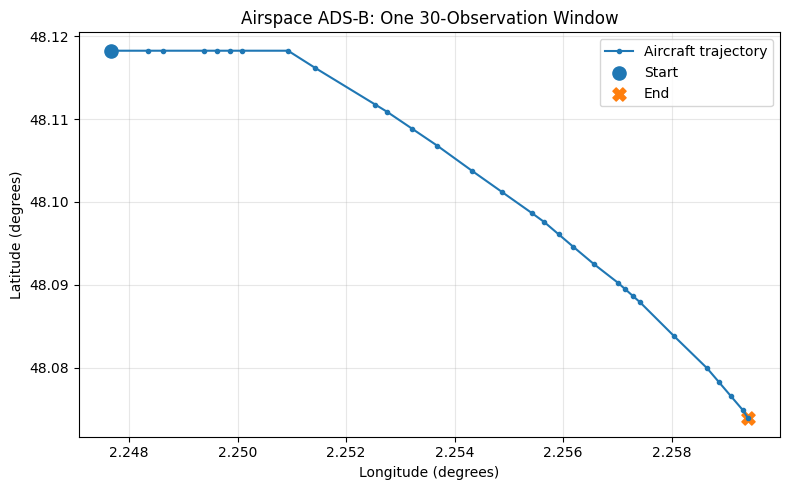

In [195]:

# ============================================================
# PHASE 4 — STEP 4.3
# Visualize One Trajectory Window
# ============================================================

import matplotlib.pyplot as plt

window_number = 0

selected_window = X_pilot[window_number]

lat_idx = FEATURE_COLS_AIRSPACE.index("latitude")
lon_idx = FEATURE_COLS_AIRSPACE.index("longitude")

latitudes = selected_window[:, lat_idx]
longitudes = selected_window[:, lon_idx]

plt.figure(figsize=(8, 5))

plt.plot(
    longitudes,
    latitudes,
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Aircraft trajectory"
)

plt.scatter(
    longitudes[0],
    latitudes[0],
    s=90,
    marker="o",
    label="Start"
)

plt.scatter(
    longitudes[-1],
    latitudes[-1],
    s=90,
    marker="X",
    label="End"
)

plt.title("Airspace ADS-B: One 30-Observation Window")
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


1. SPEED COMPARISON STATISTICS


,mean,std,min,50%,max
reported_groundspeed,461.525472,7.361698,431.551478,462.403104,474.687909
position_derived_speed_knots,459.738675,196.812340,1.844712,451.285403,1675.569906



2. FIRST 10 SPEED COMPARISONS


,reported_groundspeed,position_derived_speed_knots
0,431.551478,99.081459
1,431.551478,39.632584
2,431.551478,108.989605
3,432.538642,34.678511
4,432.538642,34.678511
5,432.538642,32.010933
6,432.538642,121.946411
7,432.538642,448.409415
8,433.367829,978.842896
9,433.367829,180.562634



3. POSITION-DERIVED ZERO-SPEED FRACTION
0.00%


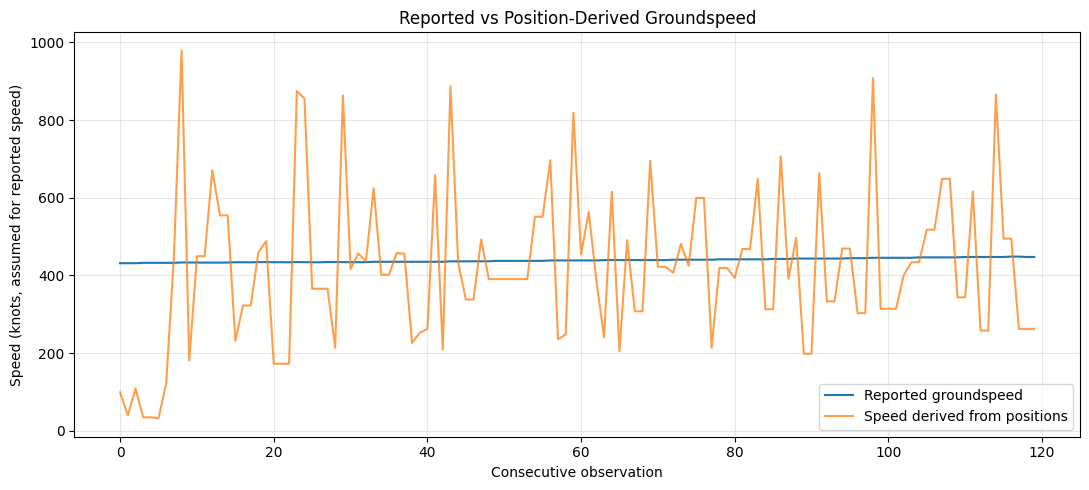


Step 4.4 completed!


In [196]:

# ============================================================
# PHASE 4 — STEP 4.4
# Position-Derived Speed vs Reported Groundspeed
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Analyze one complete flight (not just a 30-second window)
flight_id = pilot_metadata.iloc[0]["flight_id"]

flight = (
    pilot_df[pilot_df["flight_id"] == flight_id]
    .sort_values("timestamp")
    .copy()
)

# Convert geographical coordinates to radians
lat = np.radians(flight["latitude"].to_numpy())
lon = np.radians(flight["longitude"].to_numpy())

# Haversine distance between consecutive positions
dlat = np.diff(lat)
dlon = np.diff(lon)

a = (
    np.sin(dlat / 2)**2
    + np.cos(lat[:-1])
    * np.cos(lat[1:])
    * np.sin(dlon / 2)**2
)

distance_m = (
    2 * 6371000
    * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

# Actual observed timestamp differences
dt = (
    flight["timestamp"]
    .diff()
    .dt.total_seconds()
    .to_numpy()[1:]
)

# Position-derived speed in knots
derived_speed_knots = (
    distance_m / dt
) * 1.94384449

reported_speed = flight["groundspeed"].to_numpy()[1:]

comparison = pd.DataFrame({
    "reported_groundspeed": reported_speed,
    "position_derived_speed_knots": derived_speed_knots
})

print("1. SPEED COMPARISON STATISTICS")
display(
    comparison.describe().T[
        ["mean", "std", "min", "50%", "max"]
    ]
)

print("\n2. FIRST 10 SPEED COMPARISONS")
display(comparison.head(10))

print("\n3. POSITION-DERIVED ZERO-SPEED FRACTION")
print(
    f"{(derived_speed_knots < 1).mean() * 100:.2f}%"
)

# Plot first 120 observations
n = min(120, len(comparison))

plt.figure(figsize=(11, 5))

plt.plot(
    comparison["reported_groundspeed"].iloc[:n].to_numpy(),
    label="Reported groundspeed"
)

plt.plot(
    comparison["position_derived_speed_knots"].iloc[:n].to_numpy(),
    label="Speed derived from positions",
    alpha=0.75
)

plt.xlabel("Consecutive observation")
plt.ylabel("Speed (knots, assumed for reported speed)")
plt.title("Reported vs Position-Derived Groundspeed")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nStep 4.4 completed!")


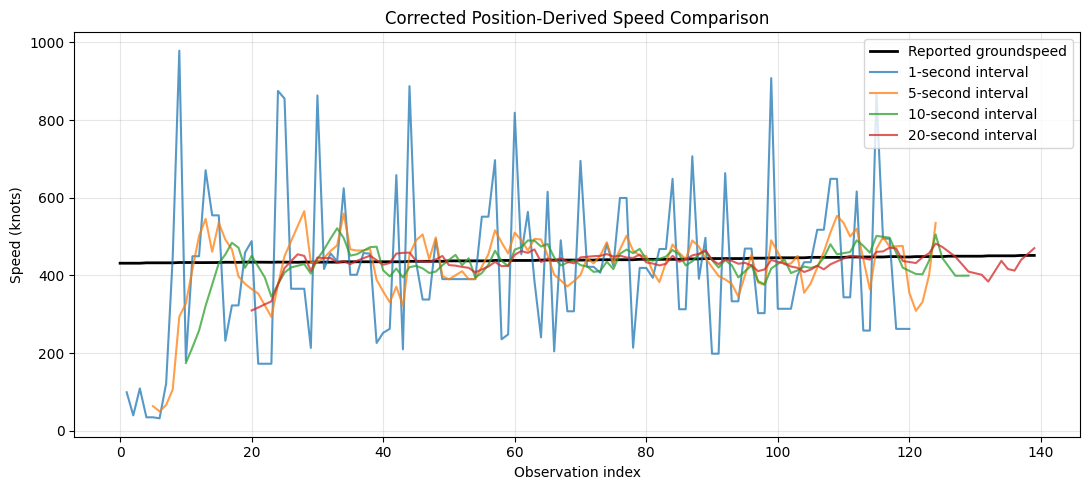

CORRECTED SPEED CONSISTENCY RESULTS


,Interval (seconds),Mean Derived Speed,Std Derived Speed,MAE vs Reported
0,1,459.739,196.754,141.579
1,5,460.003,68.254,49.011
2,10,460.480,39.466,27.714
3,20,460.727,21.923,14.618



Step 4.4B correction completed!


In [197]:

# ============================================================
# PHASE 4 — STEP 4.4B (CORRECTED)
# Speed Consistency Across Different Time Intervals
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the complete flight from Step 4.4
flight = flight.sort_values("timestamp").reset_index(drop=True)

lat = np.radians(flight["latitude"].to_numpy())
lon = np.radians(flight["longitude"].to_numpy())

reported = flight["groundspeed"].to_numpy()

R = 6371000
KNOTS_PER_MPS = 1.94384449

results = []

plt.figure(figsize=(11, 5))

# Reference reported speed
plot_n = min(140, len(flight))

plt.plot(
    np.arange(plot_n),
    reported[:plot_n],
    color="black",
    linewidth=2,
    label="Reported groundspeed"
)

for interval in [1, 5, 10, 20]:

    # Haversine distance
    dlat = lat[interval:] - lat[:-interval]
    dlon = lon[interval:] - lon[:-interval]

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat[:-interval])
        * np.cos(lat[interval:])
        * np.sin(dlon / 2)**2
    )

    distance_m = (
        2 * R *
        np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    )

    # Correct timestamp difference in seconds
    dt = (
        flight["timestamp"]
        .diff(interval)
        .dt.total_seconds()
        .to_numpy()[interval:]
    )

    assert np.all(dt > 0), "Non-positive timestamp gap!"

    derived_speed = (
        distance_m / dt
    ) * KNOTS_PER_MPS

    # Average reported speed across the interval
    reported_reference = (
        pd.Series(reported)
        .rolling(interval + 1)
        .mean()
        .to_numpy()[interval:]
    )

    mae = np.mean(
        np.abs(derived_speed - reported_reference)
    )

    results.append({
        "Interval (seconds)": interval,
        "Mean Derived Speed": derived_speed.mean(),
        "Std Derived Speed": derived_speed.std(),
        "MAE vs Reported": mae
    })

    n = min(120, len(derived_speed))

    plt.plot(
        np.arange(interval, interval + n),
        derived_speed[:n],
        label=f"{interval}-second interval",
        alpha=0.75
    )

plt.xlabel("Observation index")
plt.ylabel("Speed (knots)")
plt.title("Corrected Position-Derived Speed Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("CORRECTED SPEED CONSISTENCY RESULTS")
display(pd.DataFrame(results).round(3))

print("\nStep 4.4B correction completed!")


In [198]:

# ============================================================
# PHASE 4 — STEP 4.4C
# Multi-Flight Speed Consistency Validation
# ============================================================

import numpy as np
import pandas as pd

R = 6371000
KNOTS_PER_MPS = 1.94384449

intervals = [1, 5, 10, 20]
results = []

# Reuse 100-flight sample from Step 2.1
for flight_id, flight_data in sample_df.groupby("flight_id"):

    flight_data = (
        flight_data.sort_values("timestamp")
        .reset_index(drop=True)
    )

    lat = np.radians(
        flight_data["latitude"].to_numpy()
    )

    lon = np.radians(
        flight_data["longitude"].to_numpy()
    )

    reported = (
        flight_data["groundspeed"].to_numpy()
    )

    for interval in intervals:

        if len(flight_data) <= interval:
            continue

        dlat = lat[interval:] - lat[:-interval]
        dlon = lon[interval:] - lon[:-interval]

        a = (
            np.sin(dlat / 2)**2
            + np.cos(lat[:-interval])
            * np.cos(lat[interval:])
            * np.sin(dlon / 2)**2
        )

        distance_m = (
            2 * R *
            np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        )

        dt = (
            flight_data["timestamp"]
            .diff(interval)
            .dt.total_seconds()
            .to_numpy()[interval:]
        )

        calculated = (
            distance_m / dt
        ) * KNOTS_PER_MPS

        reference = (
            pd.Series(reported)
            .rolling(interval + 1)
            .mean()
            .to_numpy()[interval:]
        )

        valid = (
            np.isfinite(calculated)
            & np.isfinite(reference)
            & (dt > 0)
        )

        if not valid.any():
            continue

        error = np.abs(
            calculated[valid] - reference[valid]
        )

        results.append({
            "flight_id": flight_id,
            "interval": interval,
            "MAE": error.mean(),
            "RMSE": np.sqrt(
                np.mean(error ** 2)
            ),
            "observations": valid.sum()
        })

results_df = pd.DataFrame(results)

print("1. SUMMARY ACROSS 100 FLIGHTS")

summary = results_df.groupby("interval").agg(
    Flights=("flight_id", "nunique"),
    Mean_MAE=("MAE", "mean"),
    Median_MAE=("MAE", "median"),
    Std_MAE=("MAE", "std"),
    Mean_RMSE=("RMSE", "mean")
).round(3)

display(summary)

print("\n2. FIRST FIVE FLIGHT RESULTS")
display(results_df.head())

print("\nStep 4.4C completed!")


1. SUMMARY ACROSS 100 FLIGHTS


,Flights,Mean_MAE,Median_MAE,Std_MAE,Mean_RMSE
interval,,,,,
1,100,99.376,96.188,26.515,149.171
5,100,33.683,27.589,25.450,55.694
10,100,20.047,14.473,25.226,34.527
20,100,12.106,7.609,24.763,20.956



2. FIRST FIVE FLIGHT RESULTS


,flight_id,interval,MAE,RMSE,observations
0,AAF811_6727,1,96.277250,137.765137,493
1,AAF811_6727,5,26.285448,48.653852,489
2,AAF811_6727,10,13.120807,25.107150,484
3,AAF811_6727,20,7.124306,13.383407,474
4,AEA1026_3398,1,105.432574,155.898957,614



Step 4.4C completed!


In [199]:

# ============================================================
# PHASE 4 — STEP 4.5A
# Candidate Temporal Feature Engineering
# ============================================================

import numpy as np
import pandas as pd

def engineer_window_features(window):
    """
    Input:
        window: (30, 7) numerical trajectory array

    Output:
        feature_array: (30, 12) candidate features
    """

    df = pd.DataFrame(
        window,
        columns=FEATURE_COLS_AIRSPACE
    ).astype(np.float64)

    # Encode track as a circular quantity
    track_rad = np.radians(df["track"].to_numpy())

    df["track_sin"] = np.sin(track_rad)
    df["track_cos"] = np.cos(track_rad)

    # Relative displacement from window start
    R = 6371000.0

    lat_rad = np.radians(df["latitude"].to_numpy())
    lon_rad = np.radians(df["longitude"].to_numpy())

    lat0 = lat_rad[0]
    lon0 = lon_rad[0]

    df["relative_latitude_m"] = R * (lat_rad - lat0)

    df["relative_longitude_m"] = (
        R * np.cos(lat0) * (lon_rad - lon0)
    )

    # Backward-looking position-derived speed
    def derive_speed(interval):
        speed = np.full(len(df), np.nan)

        if len(df) <= interval:
            return speed

        dlat = lat_rad[interval:] - lat_rad[:-interval]
        dlon = lon_rad[interval:] - lon_rad[:-interval]

        a = (
            np.sin(dlat / 2)**2
            + np.cos(lat_rad[:-interval])
            * np.cos(lat_rad[interval:])
            * np.sin(dlon / 2)**2
        )

        distance_m = (
            2 * R *
            np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        )

        # Based on verified 1-second sampling
        speed[interval:] = (
            distance_m / interval
        ) * 1.94384449

        return speed

    df["speed_10s_knots"] = derive_speed(10)
    df["speed_20s_knots"] = derive_speed(20)

    return df

# Engineer features for the FIRST pilot window only
engineered_sample = engineer_window_features(X_pilot[0])

print("1. ENGINEERED FEATURE SHAPE")
print(engineered_sample.shape)

print("\n2. FEATURE NAMES")
print(engineered_sample.columns.tolist())

print("\n3. FIRST FIVE ROWS")
display(engineered_sample.head())

print("\n4. LAST FIVE ROWS")
display(engineered_sample.tail())

print("\n5. MISSING VALUES")
display(engineered_sample.isna().sum().to_frame("Missing"))

print("\nStep 4.5A completed!")

1. ENGINEERED FEATURE SHAPE
(30, 13)

2. FEATURE NAMES
['latitude', 'longitude', 'groundspeed', 'track', 'altitude', 'geoaltitude', 'vertical_rate', 'track_sin', 'track_cos', 'relative_latitude_m', 'relative_longitude_m', 'speed_10s_knots', 'speed_20s_knots']

3. FIRST FIVE ROWS


,latitude,longitude,groundspeed,track,altitude,geoaltitude,vertical_rate,track_sin,track_cos,relative_latitude_m,relative_longitude_m,speed_10s_knots,speed_20s_knots
0,48.118256,2.247665,431.551483,170.799606,23375.0,23300.0,1344.0,0.159888,-0.987135,0.0,0.000000,NaN,NaN
1,48.118256,2.248352,431.551483,170.799606,23375.0,23300.0,1344.0,0.159888,-0.987135,0.0,50.971906,NaN,NaN
2,48.118256,2.248627,431.551483,170.799606,23375.0,23300.0,1344.0,0.159888,-0.987135,0.0,71.360668,NaN,NaN
3,48.118256,2.249382,431.551483,170.799606,23400.0,23300.0,1344.0,0.159888,-0.987135,0.0,127.429764,NaN,NaN
4,48.118256,2.249622,432.538635,170.820786,23425.0,23375.0,1344.0,0.159523,-0.987194,0.0,145.269931,NaN,NaN



4. LAST FIVE ROWS


,latitude,longitude,groundspeed,track,altitude,geoaltitude,vertical_rate,track_sin,track_cos,relative_latitude_m,relative_longitude_m,speed_10s_knots,speed_20s_knots
25,48.079926,2.258652,434.234589,174.184372,23900.000000,23850.0,1344.0,0.101328,-0.994853,-4262.110225,815.550491,407.353025,419.072986
26,48.078239,2.258871,433.940857,174.578445,23933.333984,23900.0,1344.0,0.094483,-0.995526,-4449.595568,831.850882,420.783073,437.091736
27,48.076553,2.259091,433.940857,174.578445,23966.666016,23925.0,1344.0,0.094483,-0.995526,-4637.080910,848.133574,425.053745,454.521367
28,48.074867,2.259310,434.577576,175.115921,24000.000000,23925.0,1344.0,0.085140,-0.996369,-4824.566252,864.433965,429.327819,450.384668
29,48.073883,2.259407,434.577576,175.115921,24000.000000,23925.0,1344.0,0.085140,-0.996369,-4934.003398,871.619587,404.706114,412.123301



5. MISSING VALUES


,Missing
latitude,0
longitude,0
groundspeed,0
track,0
altitude,0
geoaltitude,0
vertical_rate,0
track_sin,0
track_cos,0
relative_latitude_m,0



Step 4.5A completed!


In [200]:

# ============================================================
# PHASE 4 — STEP 4.5B
# Flight-Level Feature Engineering (Pilot Dataset)
# ============================================================

import numpy as np
import pandas as pd

R = 6371000.0
KNOTS_PER_MPS = 1.94384449

WINDOW_SIZE = 30
WINDOW_STRIDE = 30
HISTORY = 20

ENGINEERED_FEATURE_COLS = [
    "latitude",
    "longitude",
    "groundspeed",
    "track_sin",
    "track_cos",
    "altitude",
    "geoaltitude",
    "vertical_rate",
    "relative_latitude_m",
    "relative_longitude_m",
    "speed_10s_knots",
    "speed_20s_knots"
]

def engineer_complete_flight(flight_data):

    flight = (
        flight_data.sort_values("timestamp")
        .copy()
        .reset_index(drop=True)
    )

    lat = np.radians(
        flight["latitude"].to_numpy(dtype=np.float64)
    )
    lon = np.radians(
        flight["longitude"].to_numpy(dtype=np.float64)
    )

    track_rad = np.radians(
        flight["track"].to_numpy(dtype=np.float64)
    )

    flight["track_sin"] = np.sin(track_rad)
    flight["track_cos"] = np.cos(track_rad)

    times = flight["timestamp"]

    for interval in [10, 20]:

        speed = np.full(len(flight), np.nan)

        dlat = lat[interval:] - lat[:-interval]
        dlon = lon[interval:] - lon[:-interval]

        a = (
            np.sin(dlat / 2)**2
            + np.cos(lat[:-interval])
            * np.cos(lat[interval:])
            * np.sin(dlon / 2)**2
        )

        distance_m = (
            2 * R *
            np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        )

        dt = (
            times.diff(interval)
            .dt.total_seconds()
            .to_numpy()[interval:]
        )

        valid = dt > 0

        speed_values = np.full(
            len(distance_m), np.nan
        )

        speed_values[valid] = (
            distance_m[valid] / dt[valid]
        ) * KNOTS_PER_MPS

        speed[interval:] = speed_values

        flight[f"speed_{interval}s_knots"] = speed

    return flight


X_pilot_engineered = []
metadata_engineered = []

for flight_id, original_flight in pilot_df.groupby(
    "flight_id", sort=False
):

    flight = engineer_complete_flight(original_flight)

    # Start after 20 seconds of flight history
    for start in range(
        HISTORY,
        len(flight) - WINDOW_SIZE + 1,
        WINDOW_STRIDE
    ):

        end = start + WINDOW_SIZE

        window_df = flight.iloc[start:end].copy()

        # Relative position within this specific window
        lat0 = np.radians(
            float(window_df["latitude"].iloc[0])
        )

        window_df["relative_latitude_m"] = (
            R * np.radians(
                window_df["latitude"]
                - window_df["latitude"].iloc[0]
            )
        )

        window_df["relative_longitude_m"] = (
            R * np.cos(lat0) * np.radians(
                window_df["longitude"]
                - window_df["longitude"].iloc[0]
            )
        )

        window = window_df[
            ENGINEERED_FEATURE_COLS
        ].to_numpy(dtype=np.float32)

        X_pilot_engineered.append(window)

        metadata_engineered.append({
            "flight_id": flight_id,
            "icao24": flight["icao24"].iloc[0],
            "start_time": window_df["timestamp"].iloc[0],
            "end_time": window_df["timestamp"].iloc[-1]
        })


X_pilot_engineered = np.stack(
    X_pilot_engineered
).astype(np.float32)

metadata_engineered = pd.DataFrame(
    metadata_engineered
)

print("1. ENGINEERED TENSOR SHAPE")
print(X_pilot_engineered.shape)

print("\n2. NUMBER OF FEATURES")
print(len(ENGINEERED_FEATURE_COLS))

print("\n3. NUMBER OF WINDOWS")
print(len(X_pilot_engineered))

print("\n4. MISSING VALUES")
print("Total NaNs:", np.isnan(X_pilot_engineered).sum())

print("\n5. FEATURE-WISE MISSING COUNTS")
missing_by_feature = np.isnan(
    X_pilot_engineered
).sum(axis=(0, 1))

display(pd.DataFrame({
    "Feature": ENGINEERED_FEATURE_COLS,
    "Missing": missing_by_feature
}))

print("\n6. FIRST ENGINEERED WINDOW")
display(pd.DataFrame(
    X_pilot_engineered[0],
    columns=ENGINEERED_FEATURE_COLS
).head())

assert X_pilot_engineered.shape[1:] == (
    WINDOW_SIZE,
    len(ENGINEERED_FEATURE_COLS)
)

print("\nStep 4.5B completed!")


1. ENGINEERED TENSOR SHAPE
(946, 30, 12)

2. NUMBER OF FEATURES
12

3. NUMBER OF WINDOWS
946

4. MISSING VALUES
Total NaNs: 0

5. FEATURE-WISE MISSING COUNTS


,Feature,Missing
0,latitude,0
1,longitude,0
2,groundspeed,0
3,track_sin,0
4,track_cos,0
5,altitude,0
6,geoaltitude,0
7,vertical_rate,0
8,relative_latitude_m,0
9,relative_longitude_m,0



6. FIRST ENGINEERED WINDOW


,latitude,longitude,groundspeed,track_sin,track_cos,altitude,geoaltitude,vertical_rate,relative_latitude_m,relative_longitude_m,speed_10s_knots,speed_20s_knots
0,48.090271,2.257004,434.369293,0.124318,-0.992242,23825.000000,23725.0,1344.0,0.000000,0.000000,450.447144,309.850098
1,48.089478,2.257141,434.125183,0.119781,-0.992800,23833.333984,23800.0,1344.0,-88.228394,10.199933,422.759857,317.409576
2,48.088684,2.257278,434.125183,0.119781,-0.992800,23841.666016,23825.0,1344.0,-176.456787,20.399866,395.075012,325.624817
3,48.087891,2.257416,433.890167,0.115236,-0.993338,23850.000000,23825.0,1344.0,-264.685181,30.599798,345.238708,333.240082
4,48.083862,2.258034,434.441803,0.105883,-0.994379,23875.000000,23825.0,1344.0,-712.613953,76.499496,377.267609,376.617615



Step 4.5B completed!


In [201]:

# ============================================================
# PHASE 4 — STEP 4.6A
# Full Airspace Window Index Construction
# ============================================================

import numpy as np
import pandas as pd

WINDOW_SIZE = 30
WINDOW_STRIDE = 30
HISTORY = 20

# Build the source table in flight/time order.
# Keep only fields needed for the window index.
index_source = (
    df_airspace[
        ["flight_id", "icao24", "timestamp"]
    ]
    .sort_values(["flight_id", "timestamp"])
    .reset_index(drop=True)
)

# Assign the partition from the existing aircraft split.
index_source["partition"] = (
    index_source["icao24"].map(split_map)
)

assert index_source["partition"].notna().all()

# Count observations in each complete flight.
flight_info = (
    index_source.groupby("flight_id", sort=False)
    .agg(
        icao24=("icao24", "first"),
        partition=("partition", "first"),
        n_observations=("timestamp", "size"),
        flight_start=("timestamp", "first"),
        flight_end=("timestamp", "last")
    )
    .reset_index()
)

# First position of each flight within index_source.
flight_info["flight_start_row"] = (
    flight_info["n_observations"]
    .shift(fill_value=0)
    .cumsum()
    .astype(np.int64)
)

# Count valid non-overlapping windows, starting
# after the initial 20-observation history.
flight_info["n_windows"] = np.maximum(
    0,
    (
        (flight_info["n_observations"]
         - WINDOW_SIZE
         - HISTORY) // WINDOW_STRIDE
    ) + 1
).astype(int)

records = []

for row in flight_info.itertuples(index=False):

    for window_number in range(row.n_windows):

        local_start = HISTORY + window_number * WINDOW_STRIDE
        local_end = local_start + WINDOW_SIZE

        records.append({
            "flight_id": row.flight_id,
            "icao24": row.icao24,
            "partition": row.partition,
            "start_row": int(row.flight_start_row + local_start),
            "end_row_exclusive": int(
                row.flight_start_row + local_end
            ),
            "window_number": window_number
        })

window_index_df = pd.DataFrame(records)

print("1. TOTAL FLIGHTS:", len(flight_info))
print("2. TOTAL WINDOWS:", len(window_index_df))

print("\n3. WINDOWS BY PARTITION")
display(
    window_index_df["partition"]
    .value_counts()
    .reindex(["Train", "Validation", "Test"])
    .to_frame("Windows")
)

print("\n4. FIRST FIVE WINDOW INDEX RECORDS")
display(window_index_df.head())

print("\nStep 4.6A completed!")


1. TOTAL FLIGHTS: 15811
2. TOTAL WINDOWS: 426479

3. WINDOWS BY PARTITION


,Windows
partition,
Train,295882
Validation,67859
Test,62738



4. FIRST FIVE WINDOW INDEX RECORDS


,flight_id,icao24,partition,start_row,end_row_exclusive,window_number
0,00000000_16233,ae4ec6,Test,20,50,0
1,00000000_16233,ae4ec6,Test,50,80,1
2,00000000_16233,ae4ec6,Test,80,110,2
3,00000000_16233,ae4ec6,Test,110,140,3
4,00000000_16233,ae4ec6,Test,140,170,4



Step 4.6A completed!


In [202]:

# ============================================================
# PHASE 4 — STEP 4.6B
# Verify Full Window Index Integrity
# ============================================================

import numpy as np
import pandas as pd

print("1. WINDOW SIZE VERIFICATION")

window_lengths = (
    window_index_df["end_row_exclusive"]
    - window_index_df["start_row"]
)

invalid_lengths = int((window_lengths != WINDOW_SIZE).sum())

print("Invalid window lengths:", invalid_lengths)
assert invalid_lengths == 0


print("\n2. FLIGHT BOUNDARY VERIFICATION")

# Positions refer to the sorted index_source DataFrame
start_positions = window_index_df["start_row"].to_numpy()
end_positions = (
    window_index_df["end_row_exclusive"].to_numpy() - 1
)

start_flights = index_source["flight_id"].iloc[
    start_positions
].to_numpy()

end_flights = index_source["flight_id"].iloc[
    end_positions
].to_numpy()

expected_flights = window_index_df["flight_id"].to_numpy()

flight_errors = int(np.sum(
    (start_flights != end_flights)
    | (start_flights != expected_flights)
))

print("Windows crossing flight boundaries:", flight_errors)
assert flight_errors == 0


print("\n3. AIRCRAFT AND PARTITION VERIFICATION")

actual_aircraft = index_source["icao24"].iloc[
    start_positions
].to_numpy()

actual_partitions = index_source["partition"].iloc[
    start_positions
].to_numpy()

aircraft_errors = int(np.sum(
    actual_aircraft != window_index_df["icao24"].to_numpy()
))

partition_errors = int(np.sum(
    actual_partitions != window_index_df["partition"].to_numpy()
))

print("Aircraft ID mismatches:", aircraft_errors)
print("Partition mismatches:", partition_errors)

assert aircraft_errors == 0
assert partition_errors == 0


print("\n4. TIMESTAMP DURATION VERIFICATION")

start_times = index_source["timestamp"].iloc[
    start_positions
].reset_index(drop=True)

end_times = index_source["timestamp"].iloc[
    end_positions
].reset_index(drop=True)

window_durations = (
    end_times - start_times
).dt.total_seconds()

invalid_durations = int(
    (window_durations != WINDOW_SIZE - 1).sum()
)

print("Invalid window durations:", invalid_durations)
assert invalid_durations == 0


print("\n5. FINAL SUMMARY")

print("Total windows checked:", len(window_index_df))
print("Unique flights represented:",
      window_index_df["flight_id"].nunique())
print("Unique aircraft represented:",
      window_index_df["icao24"].nunique())

print("\nSUCCESS: Full window index integrity verified!")


1. WINDOW SIZE VERIFICATION
Invalid window lengths: 0

2. FLIGHT BOUNDARY VERIFICATION
Windows crossing flight boundaries: 0

3. AIRCRAFT AND PARTITION VERIFICATION
Aircraft ID mismatches: 0
Partition mismatches: 0

4. TIMESTAMP DURATION VERIFICATION
Invalid window durations: 0

5. FINAL SUMMARY
Total windows checked: 426479
Unique flights represented: 15811
Unique aircraft represented: 2934

SUCCESS: Full window index integrity verified!


In [203]:

# ============================================================
# PHASE 4 — STEP 4.6C
# Save Verified Window Index and Experimental Splits
# ============================================================

import os
import json
import pandas as pd
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "Airspace_ProtoNet_Experiment"
)

os.makedirs(SAVE_DIR, exist_ok=True)

# 1. Save the verified window index
window_index_df.to_parquet(
    os.path.join(
        SAVE_DIR,
        "airspace_window_index.parquet"
    ),
    index=False
)

# 2. Save aircraft-disjoint split assignments
aircraft_splits_df = pd.DataFrame({
    "icao24": list(split_map.keys()),
    "partition": list(split_map.values())
})

aircraft_splits_df.to_csv(
    os.path.join(
        SAVE_DIR,
        "airspace_aircraft_splits.csv"
    ),
    index=False
)

# 3. Save flight information
flight_info.to_parquet(
    os.path.join(
        SAVE_DIR,
        "airspace_flight_info.parquet"
    ),
    index=False
)

# 4. Save experiment settings
experiment_config = {
    "random_seed": 42,
    "window_size": 30,
    "window_stride": 30,
    "history_observations": 20,
    "split_method": "aircraft_disjoint",
    "features": ENGINEERED_FEATURE_COLS,
    "total_windows": int(len(window_index_df)),
    "total_flights": int(
        df_airspace["flight_id"].nunique()
    ),
    "total_aircraft": int(
        df_airspace["icao24"].nunique()
    ),
    "attack_labels": {
        "0": "Presumed Normal",
        "1": "Simulated Path Modification",
        "2": "Simulated Ghost Aircraft",
        "3": "Simulated Velocity Drift"
    }
}

with open(
    os.path.join(
        SAVE_DIR,
        "airspace_experiment_config.json"
    ),
    "w"
) as f:
    json.dump(experiment_config, f, indent=4)

# 5. Verify saved files
print("EXPERIMENT FILES SAVED\n")

for filename in sorted(os.listdir(SAVE_DIR)):
    filepath = os.path.join(SAVE_DIR, filename)

    if filename in [
        "airspace_window_index.parquet",
        "airspace_aircraft_splits.csv",
        "airspace_flight_info.parquet",
        "airspace_experiment_config.json"
    ]:
        print(
            filename,
            "->",
            round(os.path.getsize(filepath) / 1024**2, 2),
            "MB"
        )

# 6. Verify that saved index can be loaded
reloaded_index = pd.read_parquet(
    os.path.join(
        SAVE_DIR,
        "airspace_window_index.parquet"
    )
)

assert len(reloaded_index) == len(window_index_df)

reloaded_splits = pd.read_csv(
    os.path.join(
        SAVE_DIR,
        "airspace_aircraft_splits.csv"
    ),
    dtype={"icao24": str}
)

assert len(reloaded_splits) == 2934
assert reloaded_splits["icao24"].is_unique

print("\nSUCCESS: Files saved and verified!")
print("Save directory:", SAVE_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EXPERIMENT FILES SAVED

airspace_aircraft_splits.csv -> 0.04 MB
airspace_experiment_config.json -> 0.0 MB
airspace_flight_info.parquet -> 0.52 MB
airspace_window_index.parquet -> 4.15 MB

SUCCESS: Files saved and verified!
Save directory: /content/drive/MyDrive/Airspace_ProtoNet_Experiment


In [204]:

# ============================================================
# PHASE 5 — STEP 5.1
# Attack Simulation Design Configuration
# ============================================================

ATTACK_CONFIG = {
    "seed": 42,
    "window_size": 30,
    "window_stride": 30,
    "history": 20,

    "class_labels": {
        0: "Presumed_Normal",
        1: "Simulated_Path_Modification",
        2: "Simulated_Ghost_Aircraft",
        3: "Simulated_Velocity_Drift"
    },

    "meta_train_classes": [0, 1, 2],
    "held_out_class": 3,

    "attack_intensities": [
        "weak",
        "moderate",
        "strong"
    ],

    "attack_coverage": "full_target_window",

    "recompute_features_after_injection": True,

    "support_shots": [1, 5, 10],

    "split_policy": "aircraft_disjoint",

    "simulation_stage": "raw_trajectory_before_feature_engineering"
}

print("ATTACK SIMULATION CONFIGURATION\n")

for key, value in ATTACK_CONFIG.items():
    print(f"{key}: {value}")

print("\nStep 5.1 configuration created successfully!")


ATTACK SIMULATION CONFIGURATION

seed: 42
window_size: 30
window_stride: 30
history: 20
class_labels: {0: 'Presumed_Normal', 1: 'Simulated_Path_Modification', 2: 'Simulated_Ghost_Aircraft', 3: 'Simulated_Velocity_Drift'}
meta_train_classes: [0, 1, 2]
held_out_class: 3
attack_intensities: ['weak', 'moderate', 'strong']
attack_coverage: full_target_window
recompute_features_after_injection: True
support_shots: [1, 5, 10]
split_policy: aircraft_disjoint
simulation_stage: raw_trajectory_before_feature_engineering

Step 5.1 configuration created successfully!


Selected flight: 2DITO_11022
Selected aircraft: 43eb14
Partition: Train


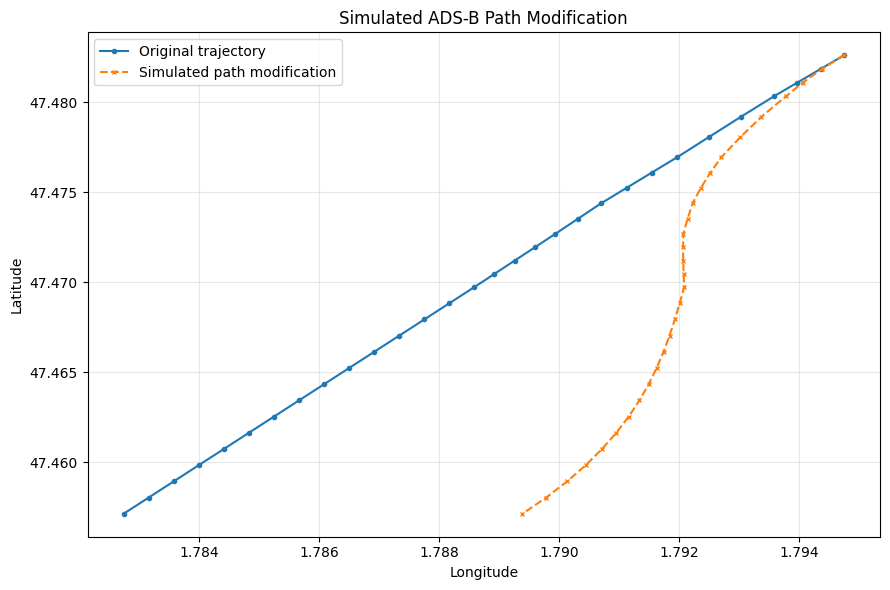


SIMULATION SUMMARY
Target observations: 30
Maximum displacement (m): 500.0
Assigned attack class: 1
Original dataset modified: No

Step 5.2A completed!


In [205]:

# ============================================================
# PHASE 5 — STEP 5.2A
# Simulate One Path Modification Attack
# Training Data Only
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

R = 6371000.0

# Select the first TRAINING window
train_window = window_index_df[
    window_index_df["partition"] == "Train"
].iloc[0]

flight_id = train_window["flight_id"]
aircraft_id = train_window["icao24"]

print("Selected flight:", flight_id)
print("Selected aircraft:", aircraft_id)
print("Partition:", train_window["partition"])

# Retrieve the original complete flight
original_flight = (
    df_airspace[
        df_airspace["flight_id"] == flight_id
    ]
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Identify the window locally within its flight
flight_first_row = int(
    flight_info.loc[
        flight_info["flight_id"] == flight_id,
        "flight_start_row"
    ].iloc[0]
)

local_start = int(
    train_window["start_row"] - flight_first_row
)

local_end = int(
    train_window["end_row_exclusive"] - flight_first_row
)

assert local_end - local_start == 30

# Select the 30-observation target window
original_window = (
    original_flight.iloc[local_start:local_end]
    .copy()
    .reset_index(drop=True)
)

# Work on a separate copy
attacked_window = original_window.copy(deep=True)

# Smooth attack progression: 0 to 500 metres
MAX_DISPLACEMENT_M = 500.0

progress = np.linspace(
    0.0, 1.0, len(attacked_window)
)

# Ease-in/ease-out profile
attack_profile = (
    3 * progress**2 - 2 * progress**3
)

# Apply an eastward displacement
east_offset_m = MAX_DISPLACEMENT_M * attack_profile

# Convert eastward metres to longitude degrees
lat_rad = np.radians(
    attacked_window["latitude"].to_numpy(
        dtype=np.float64
    )
)

longitude_offset = (
    east_offset_m
    / (R * np.cos(lat_rad))
) * (180.0 / np.pi)

attacked_window["longitude"] = (
    attacked_window["longitude"].to_numpy(
        dtype=np.float64
    )
    + longitude_offset
)

# Verify that we changed only longitude
assert np.allclose(
    attacked_window["latitude"],
    original_window["latitude"]
)

assert not np.array_equal(
    attacked_window["longitude"].to_numpy(),
    original_window["longitude"].to_numpy()
)

# Original data must remain unchanged
assert original_flight.iloc[
    local_start:local_end
]["longitude"].reset_index(drop=True).equals(
    original_window["longitude"]
)

# Plot original and modified paths
plt.figure(figsize=(9, 6))

plt.plot(
    original_window["longitude"],
    original_window["latitude"],
    marker="o",
    markersize=3,
    label="Original trajectory"
)

plt.plot(
    attacked_window["longitude"],
    attacked_window["latitude"],
    marker="x",
    markersize=3,
    linestyle="--",
    label="Simulated path modification"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Simulated ADS-B Path Modification")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSIMULATION SUMMARY")
print("Target observations:", len(attacked_window))
print("Maximum displacement (m):", MAX_DISPLACEMENT_M)
print("Assigned attack class:", 1)
print("Original dataset modified: No")

print("\nStep 5.2A completed!")


1. DISPLACEMENT VALIDATION
Initial displacement: 0.00 m
Final displacement: 500.00 m
Maximum displacement: 500.00 m

2. POSITION-DERIVED SPEED COMPARISON


,Metric,Original,Attacked
0,Mean speed (knots),199.35,192.62
1,Maximum speed (knots),263.96,258.13
2,Minimum speed (knots),165.84,158.48



3. SPEED CHANGE
Maximum absolute speed change: 9.04 knots

4. VISUALIZATION


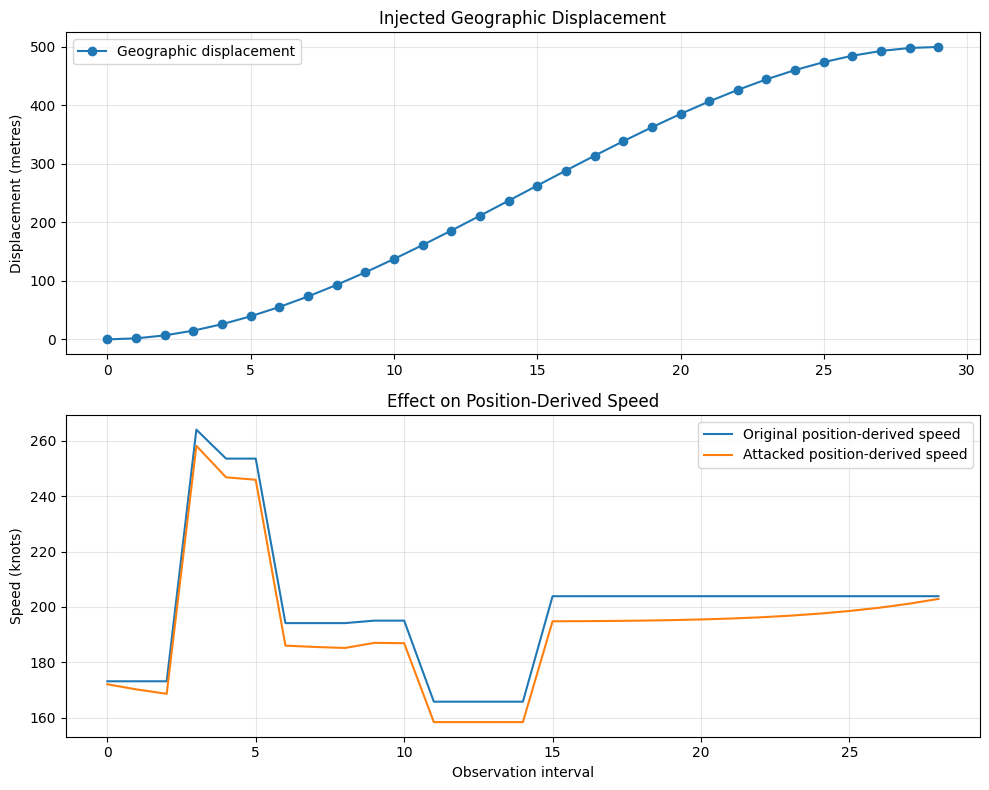


Step 5.2B completed!


In [206]:

# ============================================================
# PHASE 5 — STEP 5.2B
# Validate Simulated Path Modification
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

R = 6371000.0
KNOTS_PER_MPS = 1.94384449

def haversine_distance(lat1, lon1, lat2, lon2):
    lat1 = np.radians(np.asarray(lat1, dtype=float))
    lon1 = np.radians(np.asarray(lon1, dtype=float))
    lat2 = np.radians(np.asarray(lat2, dtype=float))
    lon2 = np.radians(np.asarray(lon2, dtype=float))

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2)**2
    )

    return 2 * R * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

# 1. Actual displacement at corresponding timestamps
displacement_m = haversine_distance(
    original_window["latitude"],
    original_window["longitude"],
    attacked_window["latitude"],
    attacked_window["longitude"]
)

# 2. Calculate one-second position-derived speeds
def calculate_window_speed(window):
    distances = haversine_distance(
        window["latitude"].iloc[:-1],
        window["longitude"].iloc[:-1],
        window["latitude"].iloc[1:],
        window["longitude"].iloc[1:]
    )

    dt = (
        window["timestamp"]
        .diff()
        .dt.total_seconds()
        .to_numpy()[1:]
    )

    return distances / dt * KNOTS_PER_MPS

original_speed = calculate_window_speed(original_window)
attacked_speed = calculate_window_speed(attacked_window)

speed_change = attacked_speed - original_speed

print("1. DISPLACEMENT VALIDATION")
print(f"Initial displacement: {displacement_m[0]:.2f} m")
print(f"Final displacement: {displacement_m[-1]:.2f} m")
print(f"Maximum displacement: {displacement_m.max():.2f} m")

print("\n2. POSITION-DERIVED SPEED COMPARISON")
display(pd.DataFrame({
    "Metric": [
        "Mean speed (knots)",
        "Maximum speed (knots)",
        "Minimum speed (knots)"
    ],
    "Original": [
        original_speed.mean(),
        original_speed.max(),
        original_speed.min()
    ],
    "Attacked": [
        attacked_speed.mean(),
        attacked_speed.max(),
        attacked_speed.min()
    ]
}).round(2))

print("\n3. SPEED CHANGE")
print(
    "Maximum absolute speed change:",
    round(np.abs(speed_change).max(), 2),
    "knots"
)

print("\n4. VISUALIZATION")

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(
    displacement_m,
    marker="o",
    label="Geographic displacement"
)
axes[0].set_ylabel("Displacement (metres)")
axes[0].set_title("Injected Geographic Displacement")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(
    original_speed,
    label="Original position-derived speed"
)
axes[1].plot(
    attacked_speed,
    label="Attacked position-derived speed"
)
axes[1].set_xlabel("Observation interval")
axes[1].set_ylabel("Speed (knots)")
axes[1].set_title("Effect on Position-Derived Speed")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print("\nStep 5.2B completed!")


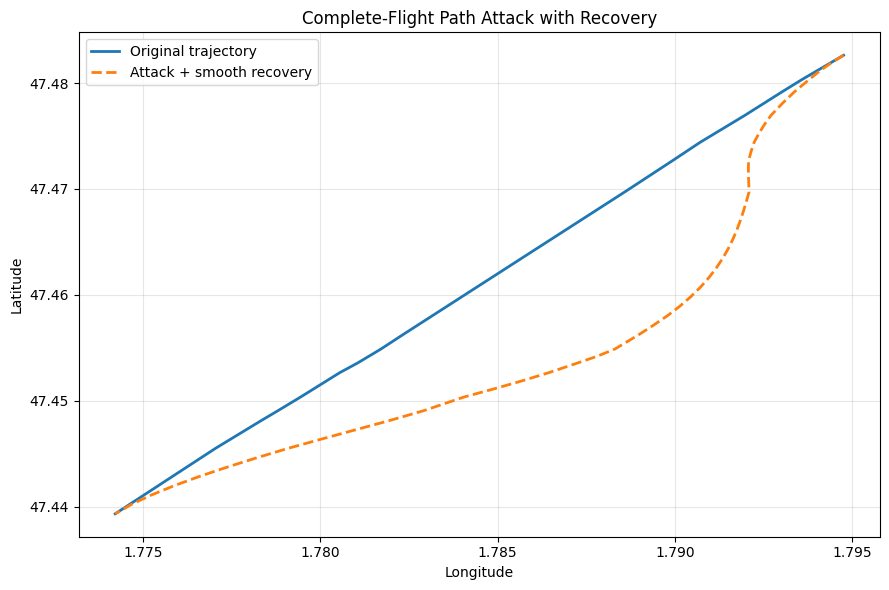

Attack start: 20
Attack end: 50
Recovery end: 70
Maximum configured offset: 500.0 m
Original flight unchanged: True

Step 5.2C completed!


In [207]:

# ============================================================
# PHASE 5 — STEP 5.2C
# Complete-Flight Path Attack with Smooth Recovery
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

R = 6371000.0

# Work on a COPY of the original complete flight
attacked_flight = original_flight.copy(deep=True)

ATTACK_LENGTH = 30
RECOVERY_LENGTH = 20
MAX_OFFSET_M = 500.0

attack_start = local_start
attack_end = attack_start + ATTACK_LENGTH
recovery_end = attack_end + RECOVERY_LENGTH

assert recovery_end <= len(attacked_flight)

# Smooth increase to maximum displacement
t_attack = np.linspace(0, 1, ATTACK_LENGTH)

attack_offset = MAX_OFFSET_M * (
    3 * t_attack**2 - 2 * t_attack**3
)

# Smooth recovery to the original trajectory
t_recovery = np.linspace(0, 1, RECOVERY_LENGTH)

recovery_offset = MAX_OFFSET_M * (
    1 - (3 * t_recovery**2 - 2 * t_recovery**3)
)

# Combine the attack and recovery phases
offset_m = np.concatenate([
    attack_offset,
    recovery_offset
])

# Apply displacement in metres converted to longitude
segment = attacked_flight.iloc[
    attack_start:recovery_end
].copy()

lat_rad = np.radians(
    segment["latitude"].to_numpy(dtype=float)
)

longitude_offset_deg = (
    offset_m / (R * np.cos(lat_rad))
) * (180 / np.pi)

attacked_flight.loc[
    attacked_flight.index[attack_start:recovery_end],
    "longitude"
] += longitude_offset_deg

# Compare original and modified trajectory segments
original_segment = original_flight.iloc[
    attack_start:recovery_end
]

modified_segment = attacked_flight.iloc[
    attack_start:recovery_end
]

plt.figure(figsize=(9, 6))

plt.plot(
    original_segment["longitude"],
    original_segment["latitude"],
    label="Original trajectory",
    linewidth=2
)

plt.plot(
    modified_segment["longitude"],
    modified_segment["latitude"],
    "--",
    label="Attack + smooth recovery",
    linewidth=2
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Complete-Flight Path Attack with Recovery")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Attack start:", attack_start)
print("Attack end:", attack_end)
print("Recovery end:", recovery_end)

print("Maximum configured offset:", MAX_OFFSET_M, "m")

print(
    "Original flight unchanged:",
    original_flight["longitude"].equals(
        df_airspace[
            df_airspace["flight_id"] == flight_id
        ].sort_values("timestamp")[
            "longitude"
        ].reset_index(drop=True)
    )
)

print("\nStep 5.2C completed!")


In [208]:

# ============================================================
# PHASE 5 — STEP 5.2D
# Validate Complete-Flight Path Attack and Window Labels
# ============================================================

import numpy as np
import pandas as pd

# Uses haversine_distance() from Step 5.2B

original_lat = original_flight["latitude"].to_numpy()
original_lon = original_flight["longitude"].to_numpy()

modified_lat = attacked_flight["latitude"].to_numpy()
modified_lon = attacked_flight["longitude"].to_numpy()

# Geographic displacement at every observation
displacement_m = haversine_distance(
    original_lat, original_lon,
    modified_lat, modified_lon
)

print("1. DISPLACEMENT STATISTICS")
print("Maximum displacement (m):",
      round(displacement_m.max(), 3))
print("Initial displacement (m):",
      round(displacement_m[0], 3))
print("Final displacement (m):",
      round(displacement_m[-1], 3))

# Change in injected displacement between observations
offset_change_m = np.abs(np.diff(displacement_m))

print("\n2. OFFSET CHANGE PER SECOND")
print("Mean absolute change (m):",
      round(offset_change_m.mean(), 3))
print("Maximum absolute change (m):",
      round(offset_change_m.max(), 3))

# Compare speed calculated over 10 and 20 seconds
def derived_speed_for_flight(df, interval):
    lat = df["latitude"].to_numpy()
    lon = df["longitude"].to_numpy()

    distances = haversine_distance(
        lat[:-interval], lon[:-interval],
        lat[interval:], lon[interval:]
    )

    dt = (
        df["timestamp"]
        .diff(interval)
        .dt.total_seconds()
        .to_numpy()[interval:]
    )

    return distances / dt * 1.94384449


print("\n3. POSITION-DERIVED SPEED EFFECT")

for interval in [10, 20]:

    speed_original = derived_speed_for_flight(
        original_flight, interval
    )

    speed_modified = derived_speed_for_flight(
        attacked_flight, interval
    )

    delta = speed_modified - speed_original

    print(f"\n{interval}-second interval")
    print(
        "Maximum absolute speed difference (knots):",
        round(np.abs(delta).max(), 3)
    )
    print(
        "Mean absolute speed difference (knots):",
        round(np.abs(delta).mean(), 3)
    )

# Identify manipulated observations
modified_mask = displacement_m > 1e-4

# Check non-overlapping windows from this flight
window_label_records = []

for start in range(HISTORY,
                   len(original_flight) - WINDOW_SIZE + 1,
                   WINDOW_STRIDE):

    end = start + WINDOW_SIZE

    affected_count = int(modified_mask[start:end].sum())

    window_label_records.append({
        "start": start,
        "end_exclusive": end,
        "affected_observations": affected_count,
        "affected_percentage": round(
            affected_count / WINDOW_SIZE * 100, 2
        ),
        "provisional_label": (
            "Attack-containing" if affected_count > 0
            else "Normal"
        )
    })

window_labels_preview = pd.DataFrame(window_label_records)

print("\n4. WINDOWS CONTAINING ATTACK OBSERVATIONS")
display(
    window_labels_preview[
        window_labels_preview["affected_observations"] > 0
    ]
)

print("\nStep 5.2D completed!")


1. DISPLACEMENT STATISTICS
Maximum displacement (m): 500.0
Initial displacement (m): 0.0
Final displacement (m): 0.0

2. OFFSET CHANGE PER SECOND
Mean absolute change (m): 2.212
Maximum absolute change (m): 39.437

3. POSITION-DERIVED SPEED EFFECT

10-second interval
Maximum absolute speed difference (knots): 31.115
Mean absolute speed difference (knots): 1.329

20-second interval
Maximum absolute speed difference (knots): 19.848
Mean absolute speed difference (knots): 1.205

4. WINDOWS CONTAINING ATTACK OBSERVATIONS


,start,end_exclusive,affected_observations,affected_percentage,provisional_label
0,20,50,29,96.67,Attack-containing
1,50,80,19,63.33,Attack-containing



Step 5.2D completed!


In [209]:

# ============================================================
# PHASE 5 — STEP 5.2E
# Recompute Features After Path Modification
# ============================================================

import numpy as np
import pandas as pd

# 1. Engineer features for both complete flights
original_features = engineer_complete_flight(
    original_flight
)

attacked_features = engineer_complete_flight(
    attacked_flight
)

# 2. Extract the same attack-growth window
start = local_start
end = start + WINDOW_SIZE

original_window_features = (
    original_features.iloc[start:end].copy()
)

attacked_window_features = (
    attacked_features.iloc[start:end].copy()
)

# 3. Calculate relative coordinates from each window's start
def add_relative_positions(window_df):

    window_df = window_df.copy()

    R = 6371000.0

    lat0 = np.radians(
        float(window_df["latitude"].iloc[0])
    )

    window_df["relative_latitude_m"] = (
        R * np.radians(
            window_df["latitude"]
            - window_df["latitude"].iloc[0]
        )
    )

    window_df["relative_longitude_m"] = (
        R * np.cos(lat0) * np.radians(
            window_df["longitude"]
            - window_df["longitude"].iloc[0]
        )
    )

    return window_df


original_window_features = add_relative_positions(
    original_window_features
)

attacked_window_features = add_relative_positions(
    attacked_window_features
)

# 4. Extract numeric input tensors
X_original_attack_window = (
    original_window_features[
        ENGINEERED_FEATURE_COLS
    ].to_numpy(dtype=np.float32)
)

X_attacked_window = (
    attacked_window_features[
        ENGINEERED_FEATURE_COLS
    ].to_numpy(dtype=np.float32)
)

print("1. TENSOR SHAPES")
print("Original:", X_original_attack_window.shape)
print("Attacked:", X_attacked_window.shape)

print("\n2. MISSING VALUES")
print("Original NaNs:", np.isnan(X_original_attack_window).sum())
print("Attacked NaNs:", np.isnan(X_attacked_window).sum())

# 5. Inspect which features changed
comparison = []

for i, feature in enumerate(ENGINEERED_FEATURE_COLS):

    difference = np.abs(
        X_attacked_window[:, i]
        - X_original_attack_window[:, i]
    )

    comparison.append({
        "Feature": feature,
        "Changed observations": int(
            np.sum(difference > 1e-4)
        ),
        "Maximum absolute difference": float(
            np.max(difference)
        )
    })

comparison_df = pd.DataFrame(comparison)

print("\n3. FEATURE CHANGE SUMMARY")
display(comparison_df.round(4))

# 6. Safety and consistency checks
assert X_original_attack_window.shape == (30, 12)
assert X_attacked_window.shape == (30, 12)

assert np.isfinite(X_original_attack_window).all()
assert np.isfinite(X_attacked_window).all()

# The attack changed longitude
lon_idx = ENGINEERED_FEATURE_COLS.index("longitude")

assert not np.array_equal(
    X_original_attack_window[:, lon_idx],
    X_attacked_window[:, lon_idx]
)

# The attack did not change reported groundspeed
speed_idx = ENGINEERED_FEATURE_COLS.index("groundspeed")

assert np.array_equal(
    X_original_attack_window[:, speed_idx],
    X_attacked_window[:, speed_idx]
)

print("\nSUCCESS: Attack features recomputed and verified!")


1. TENSOR SHAPES
Original: (30, 12)
Attacked: (30, 12)

2. MISSING VALUES
Original NaNs: 0
Attacked NaNs: 0

3. FEATURE CHANGE SUMMARY


,Feature,Changed observations,Maximum absolute difference
0,latitude,0,0.0000
1,longitude,27,0.0067
2,groundspeed,0,0.0000
3,track_sin,0,0.0000
4,track_cos,0,0.0000
5,altitude,0,0.0000
6,geoaltitude,0,0.0000
7,vertical_rate,0,0.0000
8,relative_latitude_m,0,0.0000
9,relative_longitude_m,29,499.7577



SUCCESS: Attack features recomputed and verified!


In [210]:

# ============================================================
# PHASE 5 — STEP 5.2F
# Reusable Simulated Path-Modification Generator
# ============================================================

import numpy as np
import pandas as pd

EARTH_RADIUS_M = 6371000.0

PATH_ATTACK_INTENSITIES = {
    "weak": 100.0,
    "moderate": 300.0,
    "strong": 500.0
}

def simulate_path_modification(
    flight_df,
    start_index,
    intensity="moderate",
    attack_length=30,
    recovery_length=20,
    seed=42
):
    """
    Generate a controlled path-modification simulation.

    Input:
        flight_df: Complete, time-ordered flight
        start_index: Local position where injection begins
        intensity: weak / moderate / strong
        attack_length: Growth duration in observations
        recovery_length: Recovery duration in observations
        seed: Reproducible random seed

    Returns:
        modified_flight: Independent modified copy
        metadata: Attack details
    """

    if intensity not in PATH_ATTACK_INTENSITIES:
        raise ValueError("Unknown attack intensity")

    if attack_length < 2 or recovery_length < 2:
        raise ValueError("Attack and recovery lengths must be >= 2")

    modified_flight = (
        flight_df.sort_values("timestamp")
        .copy(deep=True)
        .reset_index(drop=True)
    )

    end_index = start_index + attack_length + recovery_length

    if start_index < 0 or end_index > len(modified_flight):
        raise ValueError("Attack segment exceeds flight boundaries")

    rng = np.random.default_rng(seed)

    max_displacement = PATH_ATTACK_INTENSITIES[intensity]

    # Randomize the geographical displacement direction
    direction_rad = rng.uniform(0, 2 * np.pi)

    east_component = np.sin(direction_rad)
    north_component = np.cos(direction_rad)

    # Smooth growth
    t_attack = np.linspace(0, 1, attack_length)

    growth = 3 * t_attack**2 - 2 * t_attack**3

    # Smooth recovery
    t_recovery = np.linspace(0, 1, recovery_length)

    recovery = 1 - (
        3 * t_recovery**2 - 2 * t_recovery**3
    )

    displacement_profile = np.concatenate([
        growth,
        recovery
    ]) * max_displacement

    east_offset = displacement_profile * east_component
    north_offset = displacement_profile * north_component

    segment_indices = modified_flight.index[
        start_index:end_index
    ]

    original_lat = (
        modified_flight.loc[
            segment_indices, "latitude"
        ].to_numpy(dtype=np.float64)
    )

    original_lon = (
        modified_flight.loc[
            segment_indices, "longitude"
        ].to_numpy(dtype=np.float64)
    )

    # Apply local metre-to-degree conversion
    latitude_offset_deg = (
        north_offset / EARTH_RADIUS_M
    ) * (180.0 / np.pi)

    longitude_offset_deg = (
        east_offset /
        (
            EARTH_RADIUS_M
            * np.cos(np.radians(original_lat))
        )
    ) * (180.0 / np.pi)

    modified_flight.loc[
        segment_indices, "latitude"
    ] = original_lat + latitude_offset_deg

    modified_flight.loc[
        segment_indices, "longitude"
    ] = original_lon + longitude_offset_deg

    metadata = {
        "attack_type": "path_modification",
        "attack_label": 1,
        "intensity": intensity,
        "max_displacement_m": max_displacement,
        "direction_degrees": float(
            np.degrees(direction_rad)
        ),
        "start_index": int(start_index),
        "growth_end_exclusive": int(
            start_index + attack_length
        ),
        "end_index_exclusive": int(end_index),
        "seed": int(seed)
    }

    return modified_flight, metadata


print("Reusable path-modification simulator defined!")


Reusable path-modification simulator defined!


In [211]:

# ============================================================
# PHASE 5 — STEP 5.2G
# Test Reusable Simulator at Different Intensities
# ============================================================

import pandas as pd
import numpy as np

original_backup = original_flight.copy(deep=True)

simulation_results = []

for i, intensity in enumerate(
    ["weak", "moderate", "strong"]
):

    modified, metadata = simulate_path_modification(
        flight_df=original_flight,
        start_index=local_start,
        intensity=intensity,
        seed=42 + i
    )

    actual_displacement = haversine_distance(
        original_flight["latitude"].to_numpy(),
        original_flight["longitude"].to_numpy(),
        modified["latitude"].to_numpy(),
        modified["longitude"].to_numpy()
    )

    simulation_results.append({
        "Intensity": intensity,
        "Configured displacement (m)":
            metadata["max_displacement_m"],
        "Actual max displacement (m)":
            float(actual_displacement.max()),
        "Start displacement (m)":
            float(actual_displacement[0]),
        "Final displacement (m)":
            float(actual_displacement[-1]),
        "Direction (degrees)":
            metadata["direction_degrees"]
    })

results = pd.DataFrame(simulation_results)

display(results.round(3))

# Ensure the original flight remains unchanged
pd.testing.assert_frame_equal(
    original_flight,
    original_backup
)

assert np.allclose(
    results["Configured displacement (m)"],
    results["Actual max displacement (m)"],
    atol=0.1
)

print("\nSUCCESS: All three intensities generated correctly!")
print("Original flight remains unchanged.")


,Intensity,Configured displacement (m),Actual max displacement (m),Start displacement (m),Final displacement (m),Direction (degrees)
0,weak,100.0,100.000,0.0,0.0,278.624
1,moderate,300.0,300.003,0.0,0.0,234.828
2,strong,500.0,499.993,0.0,0.0,44.124



SUCCESS: All three intensities generated correctly!
Original flight remains unchanged.


In [212]:
# ============================================================
# PHASE 5 — STEP 5.2H
# Multi-Aircraft Path Attack Validation
# Training Partition Only
# ============================================================

"""
my goal is not simply to show that the simulator can modify aircraft positions.
It is to evaluate whether these seven ProtoNet encoders can distinguish simulated malicious behavior from presumed-normal aircraft trajectories, especially when only a few labeled examples are available.
"""

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

# Pick 10 distinct training aircraft
selected_aircraft = rng.choice(
    train_aircraft,
    size=10,
    replace=False
)

validation_results = []

for i, aircraft in enumerate(selected_aircraft):

    # Find a flight belonging to this aircraft
    matching_flights = flight_info[
        flight_info["icao24"] == aircraft
    ]

    selected_flight_id = matching_flights.iloc[0]["flight_id"]

    flight_data = (
        df_airspace[
            df_airspace["flight_id"] == selected_flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    # Choose a valid attack starting point
    attack_length = 30
    recovery_length = 20
    history = 20

    latest_start = (
        len(flight_data)
        - attack_length
        - recovery_length
    )

    start_index = int(
        rng.integers(history, latest_start + 1)
    )

    intensity = ["weak", "moderate", "strong"][i % 3]

    original_copy = flight_data.copy(deep=True)

    # Generate controlled attack
    modified, metadata = simulate_path_modification(
        flight_df=flight_data,
        start_index=start_index,
        intensity=intensity,
        attack_length=attack_length,
        recovery_length=recovery_length,
        seed=100 + i
    )

    displacement = haversine_distance(
        flight_data["latitude"].to_numpy(),
        flight_data["longitude"].to_numpy(),
        modified["latitude"].to_numpy(),
        modified["longitude"].to_numpy()
    )

    # Check that the original is unchanged
    pd.testing.assert_frame_equal(
        flight_data,
        original_copy
    )

    # Check geographical bounds
    coordinates_valid = bool(
        modified["latitude"].between(-90, 90).all()
        and modified["longitude"].between(-180, 180).all()
    )

    # Measure position-derived speed changes
    orig_speed_20 = derived_speed_for_flight(
        flight_data, 20
    )

    mod_speed_20 = derived_speed_for_flight(
        modified, 20
    )

    max_speed_change = float(
        np.max(np.abs(mod_speed_20 - orig_speed_20))
    )

    validation_results.append({
        "Aircraft": aircraft,
        "Flight": selected_flight_id,
        "Intensity": intensity,
        "Target_m": metadata["max_displacement_m"],
        "Actual_m": float(displacement.max()),
        "Start_m": float(displacement[0]),
        "End_m": float(displacement[-1]),
        "Max_20s_Speed_Change_kt": max_speed_change,
        "Coordinates_Valid": coordinates_valid
    })


path_validation_df = pd.DataFrame(validation_results)

print("MULTI-AIRCRAFT PATH ATTACK VALIDATION")
display(path_validation_df.round(3))

print("\nSUMMARY")

print("Aircraft tested:",
      path_validation_df["Aircraft"].nunique())

print(
    "Maximum displacement error (m):",
    round(
        np.abs(
            path_validation_df["Actual_m"]
            - path_validation_df["Target_m"]
        ).max(),
        4
    )
)

print(
    "Invalid coordinate cases:",
    int((~path_validation_df["Coordinates_Valid"]).sum())
)

assert path_validation_df["Coordinates_Valid"].all()

assert np.allclose(
    path_validation_df["Actual_m"],
    path_validation_df["Target_m"],
    atol=0.1
)

print("\nStep 5.2H completed successfully!")


MULTI-AIRCRAFT PATH ATTACK VALIDATION


,Aircraft,Flight,Intensity,Target_m,Actual_m,Start_m,End_m,Max_20s_Speed_Change_kt,Coordinates_Valid
0,396441,AFR148_6399,weak,100.0,100.000,0.0,0.0,5.677,True
1,4ca67c,RYR47UB_14696,moderate,300.0,299.999,0.0,0.0,8.952,True
2,396442,AFR386_6401,strong,500.0,499.992,0.0,0.0,23.791,True
3,49d317,QNR25A_13160,weak,100.0,100.000,0.0,0.0,7.952,True
4,406909,EZY89BD_10240,moderate,300.0,299.997,0.0,0.0,18.140,True
5,406d95,EZY59UB_10574,strong,500.0,500.008,0.0,0.0,23.515,True
6,4ca563,RYR15QG_14116,weak,100.0,100.000,0.0,0.0,8.979,True
7,3965aa,AFR718_6557,moderate,300.0,300.003,0.0,0.0,23.737,True
8,4a0c4b,CBX7262_13171,strong,500.0,499.993,0.0,0.0,14.102,True
9,4951d3,TAP1305_12737,weak,100.0,100.000,0.0,0.0,6.969,True



SUMMARY
Aircraft tested: 10
Maximum displacement error (m): 0.0081
Invalid coordinate cases: 0

Step 5.2H completed successfully!


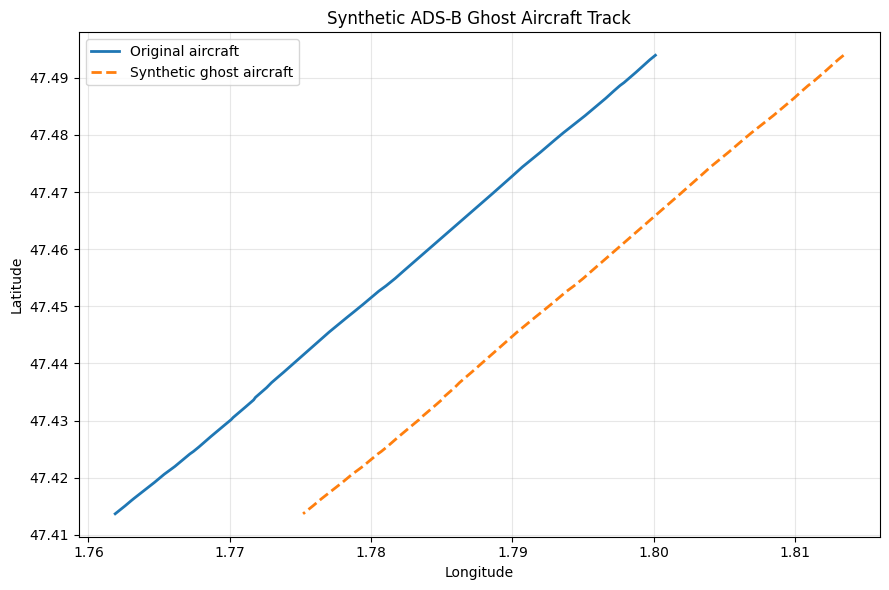

SOURCE AIRCRAFT: 43eb14
GHOST AIRCRAFT: SYNTH_GHOST_001
Source observations: 453
Ghost observations: 453
Assigned provisional label: 2
Original source unchanged: True

Step 5.3A completed!


In [213]:

# ============================================================
# PHASE 5 — STEP 5.3A
# Generate One Synthetic Ghost-Aircraft Track
# Training Data Only
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

R = 6371000.0

# Preserve the source flight
source_flight = original_flight.copy(deep=True)
source_backup = source_flight.copy(deep=True)

# Create a separate synthetic aircraft track
ghost_flight = source_flight.copy(deep=True)

GHOST_OFFSET_EAST_M = 1000.0
GHOST_OFFSET_NORTH_M = 0.0

lat_original = source_flight["latitude"].to_numpy(
    dtype=np.float64
)

lon_original = source_flight["longitude"].to_numpy(
    dtype=np.float64
)

lat_offset_deg = (
    GHOST_OFFSET_NORTH_M / R
) * (180.0 / np.pi)

lon_offset_deg = (
    GHOST_OFFSET_EAST_M /
    (R * np.cos(np.radians(lat_original)))
) * (180.0 / np.pi)

ghost_flight["latitude"] = (
    lat_original + lat_offset_deg
)

ghost_flight["longitude"] = (
    lon_original + lon_offset_deg
)

# Synthetic IDs are metadata, not model features
ghost_flight["icao24"] = "SYNTH_GHOST_001"
ghost_flight["flight_id"] = "SYNTH_GHOST_FLIGHT_001"
ghost_flight["callsign"] = "GHOST001"

# Verify the source remains unchanged
pd.testing.assert_frame_equal(
    source_flight,
    source_backup
)

# Verify no duplicate synthetic IDs in source
assert (
    ghost_flight["icao24"].iloc[0]
    != source_flight["icao24"].iloc[0]
)

# Plot the first 100 observations
n = min(100, len(source_flight))

plt.figure(figsize=(9, 6))

plt.plot(
    source_flight["longitude"].iloc[:n],
    source_flight["latitude"].iloc[:n],
    label="Original aircraft",
    linewidth=2
)

plt.plot(
    ghost_flight["longitude"].iloc[:n],
    ghost_flight["latitude"].iloc[:n],
    "--",
    label="Synthetic ghost aircraft",
    linewidth=2
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Synthetic ADS-B Ghost Aircraft Track")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("SOURCE AIRCRAFT:", source_flight["icao24"].iloc[0])
print("GHOST AIRCRAFT:", ghost_flight["icao24"].iloc[0])

print("Source observations:", len(source_flight))
print("Ghost observations:", len(ghost_flight))

print("Assigned provisional label:", 2)
print("Original source unchanged: True")

print("\nStep 5.3A completed!")


In [214]:

# ============================================================
# PHASE 5 — STEP 5.3B
# Validate Synthetic Ghost Aircraft
# ============================================================

import numpy as np
import pandas as pd

# 1. Check geographic displacement
ghost_displacement = haversine_distance(
    source_flight["latitude"].to_numpy(),
    source_flight["longitude"].to_numpy(),
    ghost_flight["latitude"].to_numpy(),
    ghost_flight["longitude"].to_numpy()
)

print("1. GEOGRAPHIC DISPLACEMENT")
print("Mean displacement (m):",
      round(ghost_displacement.mean(), 3))
print("Minimum displacement (m):",
      round(ghost_displacement.min(), 3))
print("Maximum displacement (m):",
      round(ghost_displacement.max(), 3))

# 2. Compare timestamps and original motion fields
same_timestamps = source_flight[
    "timestamp"
].reset_index(drop=True).equals(
    ghost_flight["timestamp"].reset_index(drop=True)
)

motion_cols = [
    "groundspeed",
    "track",
    "altitude",
    "geoaltitude",
    "vertical_rate"
]

motion_preserved = all(
    source_flight[col].reset_index(drop=True).equals(
        ghost_flight[col].reset_index(drop=True)
    )
    for col in motion_cols
)

print("\n2. CONSISTENCY CHECKS")
print("Timestamps identical:", same_timestamps)
print("Original motion fields preserved:", motion_preserved)
print(
    "All coordinates valid:",
    ghost_flight["latitude"].between(-90, 90).all()
    and ghost_flight["longitude"].between(-180, 180).all()
)

# 3. Recompute features for both complete trajectories
source_features = engineer_complete_flight(
    source_flight
)

ghost_features = engineer_complete_flight(
    ghost_flight
)

# Select a window with enough preceding history
start = 20
end = start + 30

source_window = add_relative_positions(
    source_features.iloc[start:end]
)

ghost_window = add_relative_positions(
    ghost_features.iloc[start:end]
)

X_source_ghost = source_window[
    ENGINEERED_FEATURE_COLS
].to_numpy(dtype=np.float32)

X_ghost = ghost_window[
    ENGINEERED_FEATURE_COLS
].to_numpy(dtype=np.float32)

# 4. Compare individual features
feature_comparison = []

for i, feature in enumerate(ENGINEERED_FEATURE_COLS):

    difference = np.abs(
        X_ghost[:, i] - X_source_ghost[:, i]
    )

    feature_comparison.append({
        "Feature": feature,
        "Mean absolute difference": float(
            difference.mean()
        ),
        "Maximum absolute difference": float(
            difference.max()
        )
    })

print("\n3. FEATURE DIFFERENCE SUMMARY")
display(
    pd.DataFrame(feature_comparison).round(6)
)

print("\n4. FINAL CHECKS")
print("Source tensor shape:", X_source_ghost.shape)
print("Ghost tensor shape:", X_ghost.shape)
print("Source NaNs:", np.isnan(X_source_ghost).sum())
print("Ghost NaNs:", np.isnan(X_ghost).sum())

assert same_timestamps
assert motion_preserved

assert X_source_ghost.shape == (30, 12)
assert X_ghost.shape == (30, 12)

assert np.isfinite(X_source_ghost).all()
assert np.isfinite(X_ghost).all()

print("\nStep 5.3B completed successfully!")


1. GEOGRAPHIC DISPLACEMENT
Mean displacement (m): 1000.0
Minimum displacement (m): 1000.0
Maximum displacement (m): 1000.0

2. CONSISTENCY CHECKS
Timestamps identical: True
Original motion fields preserved: True
All coordinates valid: True

3. FEATURE DIFFERENCE SUMMARY


,Feature,Mean absolute difference,Maximum absolute difference
0,latitude,0.000000,0.000000
1,longitude,0.013304,0.013307
2,groundspeed,0.000000,0.000000
3,track_sin,0.000000,0.000000
4,track_cos,0.000000,0.000000
5,altitude,0.000000,0.000000
6,geoaltitude,0.000000,0.000000
7,vertical_rate,0.000000,0.000000
8,relative_latitude_m,0.000000,0.000000
9,relative_longitude_m,0.241846,0.484741



4. FINAL CHECKS
Source tensor shape: (30, 12)
Ghost tensor shape: (30, 12)
Source NaNs: 0
Ghost NaNs: 0

Step 5.3B completed successfully!


In [215]:

# ============================================================
# PHASE 5 — STEP 5.3C
# Contextual Ghost-Aircraft Analysis
# ============================================================

import numpy as np
import pandas as pd

# Source and synthetic ghost share aligned timestamps.
assert source_flight["timestamp"].reset_index(drop=True).equals(
    ghost_flight["timestamp"].reset_index(drop=True)
)

# 1. Geographic separation
separation_m = haversine_distance(
    source_flight["latitude"].to_numpy(),
    source_flight["longitude"].to_numpy(),
    ghost_flight["latitude"].to_numpy(),
    ghost_flight["longitude"].to_numpy()
)

# 2. Difference in reported groundspeed
speed_difference = np.abs(
    source_flight["groundspeed"].to_numpy()
    - ghost_flight["groundspeed"].to_numpy()
)

# 3. Circular heading difference
heading_difference = np.abs(
    (
        source_flight["track"].to_numpy()
        - ghost_flight["track"].to_numpy()
        + 180
    ) % 360 - 180
)

# 4. Compare displacement patterns
source_lat_change = np.diff(
    source_flight["latitude"].to_numpy()
)

ghost_lat_change = np.diff(
    ghost_flight["latitude"].to_numpy()
)

source_lon_change = np.diff(
    source_flight["longitude"].to_numpy()
)

ghost_lon_change = np.diff(
    ghost_flight["longitude"].to_numpy()
)

def safe_correlation(a, b):
    if np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return np.nan
    return np.corrcoef(a, b)[0, 1]

lat_corr = safe_correlation(
    source_lat_change,
    ghost_lat_change
)

lon_corr = safe_correlation(
    source_lon_change,
    ghost_lon_change
)

print("1. GEOGRAPHIC RELATIONSHIP")
print("Mean separation (m):",
      round(separation_m.mean(), 3))
print("Std separation (m):",
      round(separation_m.std(), 6))
print("Min separation (m):",
      round(separation_m.min(), 3))
print("Max separation (m):",
      round(separation_m.max(), 3))

print("\n2. REPORTED MOTION DIFFERENCES")
print("Mean speed difference (knots):",
      round(speed_difference.mean(), 6))
print("Mean heading difference (degrees):",
      round(heading_difference.mean(), 6))

print("\n3. MOVEMENT SIMILARITY")
print("Latitude-change correlation:", lat_corr)
print("Longitude-change correlation:", lon_corr)

print("\n4. CONTEXT SUMMARY")

context_summary = pd.DataFrame({
    "Metric": [
        "Mean separation (m)",
        "Separation std (m)",
        "Mean speed difference (knots)",
        "Mean heading difference (degrees)",
        "Latitude-change correlation",
        "Longitude-change correlation"
    ],
    "Value": [
        separation_m.mean(),
        separation_m.std(),
        speed_difference.mean(),
        heading_difference.mean(),
        lat_corr,
        lon_corr
    ]
})

display(context_summary.round(6))

print("\nStep 5.3C completed!")


1. GEOGRAPHIC RELATIONSHIP
Mean separation (m): 1000.0
Std separation (m): 0.0
Min separation (m): 1000.0
Max separation (m): 1000.0

2. REPORTED MOTION DIFFERENCES
Mean speed difference (knots): 0.0
Mean heading difference (degrees): 0.0

3. MOVEMENT SIMILARITY
Latitude-change correlation: 1.0
Longitude-change correlation: 0.9999999838878574

4. CONTEXT SUMMARY


,Metric,Value
0,Mean separation (m),999.999999
1,Separation std (m),0.000000
2,Mean speed difference (knots),0.000000
3,Mean heading difference (degrees),0.000000
4,Latitude-change correlation,1.000000
5,Longitude-change correlation,1.000000



Step 5.3C completed!


In [216]:

# ============================================================
# PHASE 5 — STEP 5.3D
# Real Aircraft Pair Contextual Comparison
# TRAINING PARTITION ONLY
# ============================================================

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

# Use flight metadata to identify training flights
train_flight_info = flight_info[
    flight_info["partition"] == "Train"
].copy()

# Search a reproducible subset for overlapping flights
candidate_flights = train_flight_info.sample(
    n=min(1000, len(train_flight_info)),
    random_state=42
).sort_values("flight_start")

MIN_OVERLAP_SECONDS = 30
MAX_PAIRS = 20

pairs = []

rows = candidate_flights.reset_index(drop=True)

for i in range(len(rows)):
    a = rows.iloc[i]

    for j in range(i + 1, len(rows)):
        b = rows.iloc[j]

        # Sorted by start time: later starts beyond a's end
        # cannot overlap with flight a.
        if b["flight_start"] > a["flight_end"]:
            break

        if a["icao24"] == b["icao24"]:
            continue

        overlap_start = max(
            a["flight_start"], b["flight_start"]
        )
        overlap_end = min(
            a["flight_end"], b["flight_end"]
        )

        overlap_seconds = (
            overlap_end - overlap_start
        ).total_seconds()

        if overlap_seconds >= MIN_OVERLAP_SECONDS:
            pairs.append((
                a["flight_id"],
                b["flight_id"]
            ))

        if len(pairs) >= MAX_PAIRS:
            break

    if len(pairs) >= MAX_PAIRS:
        break

print("Overlapping real-aircraft pairs found:", len(pairs))

# Extract a bounded subset of their observations.
required_flights = set(
    fid for pair in pairs for fid in pair
)

pair_source = df_airspace.loc[
    df_airspace["flight_id"].isin(required_flights),
    [
        "flight_id",
        "icao24",
        "timestamp",
        "latitude",
        "longitude",
        "groundspeed",
        "track"
    ]
].copy()

flight_lookup = {
    fid: part.sort_values("timestamp")
    for fid, part in pair_source.groupby("flight_id")
}

results = []

for flight_a, flight_b in pairs:

    a = flight_lookup[flight_a]
    b = flight_lookup[flight_b]

    # Align actual overlapping timestamps
    aligned = pd.merge(
        a,
        b,
        on="timestamp",
        suffixes=("_a", "_b")
    )

    if len(aligned) < 30:
        continue

    separation = haversine_distance(
        aligned["latitude_a"],
        aligned["longitude_a"],
        aligned["latitude_b"],
        aligned["longitude_b"]
    )

    speed_diff = np.abs(
        aligned["groundspeed_a"].to_numpy()
        - aligned["groundspeed_b"].to_numpy()
    )

    heading_diff = np.abs(
        (
            aligned["track_a"].to_numpy()
            - aligned["track_b"].to_numpy()
            + 180
        ) % 360 - 180
    )

    results.append({
        "Flight_A": flight_a,
        "Flight_B": flight_b,
        "Aligned_Observations": len(aligned),
        "Mean_Separation_m": separation.mean(),
        "Std_Separation_m": separation.std(),
        "Mean_Speed_Diff_kt": speed_diff.mean(),
        "Mean_Heading_Diff_deg": heading_diff.mean()
    })

real_pair_results = pd.DataFrame(results)

print("\nREAL AIRCRAFT PAIR COMPARISON")
display(real_pair_results.head(10).round(3))

if not real_pair_results.empty:
    print("\nSUMMARY")
    display(
        real_pair_results[
            [
                "Mean_Separation_m",
                "Std_Separation_m",
                "Mean_Speed_Diff_kt",
                "Mean_Heading_Diff_deg"
            ]
        ].describe().round(3)
    )

print("\nStep 5.3D completed!")


Overlapping real-aircraft pairs found: 20

REAL AIRCRAFT PAIR COMPARISON


,Flight_A,Flight_B,Aligned_Observations,Mean_Separation_m,Std_Separation_m,Mean_Speed_Diff_kt,Mean_Heading_Diff_deg
0,BER305C_7986,EZS31LC_13348,525,66642.033,770.648,11.359,1.420
1,AFR1084_7614,AF700TO_4283,880,143253.354,2588.497,15.636,15.082
2,AF700TO_4283,AAF235_6621,671,199248.785,1770.199,9.254,21.378
3,BAW344N_10404,RYR92KL_13730,1462,67204.313,31627.838,24.416,21.211
4,BAW344N_10404,HOP62VE_4690,741,194063.892,65851.240,43.473,127.772
5,BAW344N_10404,RYR77MM_14135,741,128024.211,17849.837,27.672,42.050
6,BAW344N_10404,AF120TC_6203,571,127450.999,12351.708,10.737,33.808
7,RYR92KL_13730,HOP62VE_4690,741,219778.224,70773.346,21.493,112.942
8,RYR92KL_13730,RYR77MM_14135,741,89519.244,3586.582,5.383,22.320
9,RYR92KL_13730,AF120TC_6203,571,82016.282,1849.680,16.118,15.467



SUMMARY


,Mean_Separation_m,Std_Separation_m,Mean_Speed_Diff_kt,Mean_Heading_Diff_deg
count,20.000,20.000,20.000,20.000
mean,163326.320,20048.240,21.704,59.248
std,82492.241,21722.698,14.565,46.635
min,20813.358,215.299,1.134,1.420
25%,105359.126,2282.594,11.977,19.775
50%,135638.783,14654.906,17.942,49.476
75%,223785.787,32750.385,25.628,102.492
max,303648.516,70773.346,58.799,127.772



Step 5.3D completed!


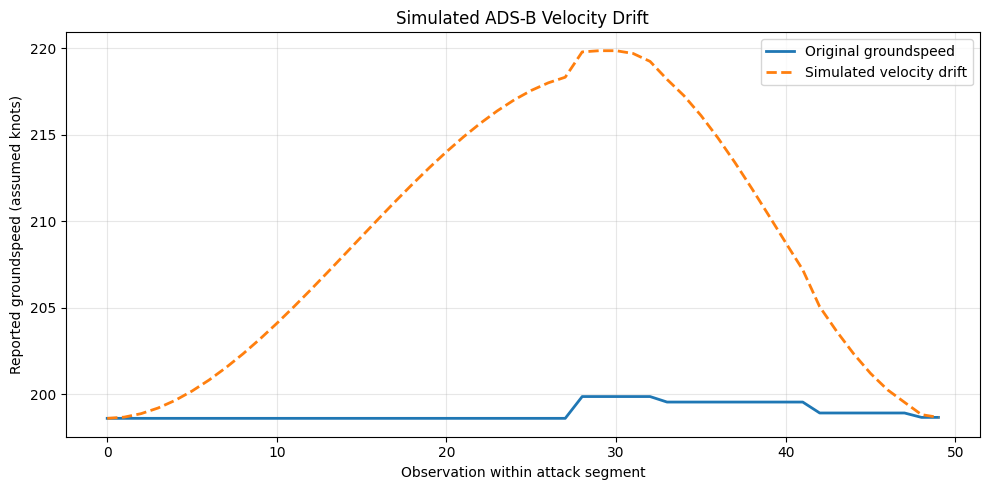

ATTACK SUMMARY
Attack label: 3
Maximum configured drift: 20.0 knots
Original flight modified: No
Modified observations: 50

Step 5.4A completed!


In [217]:

# ============================================================
# PHASE 5 — STEP 5.4A
# Simulate One Velocity-Drift Attack
# TRAINING FLIGHT — GENERATOR VALIDATION ONLY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def simulate_velocity_drift(
    flight_df,
    start_index,
    max_drift_knots=20.0,
    attack_length=30,
    recovery_length=20
):
    """
    Create a controlled velocity-drift simulation.

    Modifies only reported groundspeed.
    Does not alter original flight or position data.
    """

    modified = (
        flight_df.sort_values("timestamp")
        .copy(deep=True)
        .reset_index(drop=True)
    )

    end_index = (
        start_index + attack_length + recovery_length
    )

    if start_index < 0 or end_index > len(modified):
        raise ValueError("Attack exceeds flight boundaries")

    # Gradually increase the speed offset
    t_attack = np.linspace(0, 1, attack_length)

    growth = 3 * t_attack**2 - 2 * t_attack**3

    # Gradually return to original speed
    t_recovery = np.linspace(0, 1, recovery_length)

    recovery = 1 - (
        3 * t_recovery**2 - 2 * t_recovery**3
    )

    drift_profile = np.concatenate([
        growth,
        recovery
    ]) * max_drift_knots

    indices = modified.index[
        start_index:end_index
    ]

    modified.loc[
        indices, "groundspeed"
    ] += drift_profile

    metadata = {
        "attack_label": 3,
        "attack_type": "velocity_drift",
        "max_drift_knots": max_drift_knots,
        "start_index": start_index,
        "end_index_exclusive": end_index
    }

    return modified, metadata


# Use the existing original training flight
velocity_original = original_flight.copy(deep=True)

velocity_attacked, velocity_metadata = (
    simulate_velocity_drift(
        flight_df=velocity_original,
        start_index=local_start,
        max_drift_knots=20.0,
        attack_length=30,
        recovery_length=20
    )
)

# Confirm original remains unchanged
pd.testing.assert_frame_equal(
    velocity_original,
    original_flight
)

# Visualize speed manipulation
start = local_start
end = start + 50

plt.figure(figsize=(10, 5))

plt.plot(
    velocity_original["groundspeed"].iloc[start:end]
        .to_numpy(),
    label="Original groundspeed",
    linewidth=2
)

plt.plot(
    velocity_attacked["groundspeed"].iloc[start:end]
        .to_numpy(),
    label="Simulated velocity drift",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Observation within attack segment")
plt.ylabel("Reported groundspeed (assumed knots)")
plt.title("Simulated ADS-B Velocity Drift")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ATTACK SUMMARY")
print("Attack label:", velocity_metadata["attack_label"])
print("Maximum configured drift:",
      velocity_metadata["max_drift_knots"], "knots")

print("Original flight modified: No")
print("Modified observations:", end - start)

print("\nStep 5.4A completed!")


In [218]:

# ============================================================
# PHASE 5 — STEP 5.4B
# Validate Velocity Drift Simulation
# ============================================================

import numpy as np
import pandas as pd

# 1. Calculate the injected groundspeed difference
original_speed = velocity_original[
    "groundspeed"
].to_numpy(dtype=np.float64)

modified_speed = velocity_attacked[
    "groundspeed"
].to_numpy(dtype=np.float64)

drift = modified_speed - original_speed

print("1. VELOCITY DRIFT VALIDATION")
print("Maximum injected drift (knots):",
      round(drift.max(), 4))
print("Minimum injected drift (knots):",
      round(drift.min(), 4))
print("Maximum absolute drift (knots):",
      round(np.abs(drift).max(), 4))

# 2. Identify changed observations
modified_mask = np.abs(drift) > 1e-6

print("\n2. MODIFIED OBSERVATIONS")
print("Total modified observations:",
      int(modified_mask.sum()))

# 3. Confirm other recorded measurements were unchanged
unchanged_cols = [
    "latitude",
    "longitude",
    "track",
    "altitude",
    "geoaltitude",
    "vertical_rate",
    "timestamp"
]

unchanged_checks = {
    col: velocity_original[col].equals(
        velocity_attacked[col]
    )
    for col in unchanged_cols
}

print("\n3. UNCHANGED FEATURE CHECKS")
display(
    pd.DataFrame(
        unchanged_checks.items(),
        columns=["Feature", "Unchanged"]
    )
)

assert all(unchanged_checks.values())

# 4. Recompute engineered features
original_engineered = engineer_complete_flight(
    velocity_original
)

attacked_engineered = engineer_complete_flight(
    velocity_attacked
)

# Compare engineered numerical features
feature_changes = []

for col in [
    "groundspeed",
    "track_sin",
    "track_cos",
    "speed_10s_knots",
    "speed_20s_knots"
]:
    a = original_engineered[col].to_numpy()
    b = attacked_engineered[col].to_numpy()

    valid = np.isfinite(a) & np.isfinite(b)

    feature_changes.append({
        "Feature": col,
        "Maximum absolute change": float(
            np.max(np.abs(b[valid] - a[valid]))
        )
    })

print("\n4. ENGINEERED FEATURE CHANGES")
display(pd.DataFrame(feature_changes).round(6))

# 5. Inspect which trajectory windows contain drift
window_records = []

for start in range(
    HISTORY,
    len(velocity_original) - WINDOW_SIZE + 1,
    WINDOW_STRIDE
):
    end = start + WINDOW_SIZE

    count = int(modified_mask[start:end].sum())

    window_records.append({
        "start": start,
        "end_exclusive": end,
        "modified_observations": count,
        "coverage_percent": round(
            count / WINDOW_SIZE * 100, 2
        ),
        "provisional_label": (
            "Attack-containing" if count > 0
            else "Normal"
        )
    })

velocity_window_labels = pd.DataFrame(window_records)

print("\n5. WINDOWS CONTAINING VELOCITY DRIFT")
display(
    velocity_window_labels[
        velocity_window_labels["modified_observations"] > 0
    ]
)

assert np.isclose(
    np.abs(drift).max(),
    20.0,
    atol=1e-6
)

assert not np.isnan(
    velocity_attacked["groundspeed"]
).any()

print("\nSUCCESS: Velocity drift simulation validated!")


1. VELOCITY DRIFT VALIDATION
Maximum injected drift (knots): 20.0
Minimum injected drift (knots): 0.0
Maximum absolute drift (knots): 20.0

2. MODIFIED OBSERVATIONS
Total modified observations: 48

3. UNCHANGED FEATURE CHECKS


,Feature,Unchanged
0,latitude,True
1,longitude,True
2,track,True
3,altitude,True
4,geoaltitude,True
5,vertical_rate,True
6,timestamp,True



4. ENGINEERED FEATURE CHANGES


,Feature,Maximum absolute change
0,groundspeed,20.0
1,track_sin,0.0
2,track_cos,0.0
3,speed_10s_knots,0.0
4,speed_20s_knots,0.0



5. WINDOWS CONTAINING VELOCITY DRIFT


,start,end_exclusive,modified_observations,coverage_percent,provisional_label
0,20,50,29,96.67,Attack-containing
1,50,80,19,63.33,Attack-containing



SUCCESS: Velocity drift simulation validated!


In [219]:

# ============================================================
# PHASE 5 — STEP 5.5A
# Define and Verify Window Labeling Policy
# ============================================================

import numpy as np
import pandas as pd

WINDOW_SIZE = 30
HISTORY = 20
WINDOW_STRIDE = 30

ATTACK_COVERAGE_THRESHOLD = 0.80

def assign_window_label(
    modified_count,
    window_size,
    attack_label
):
    coverage = modified_count / window_size

    if modified_count == 0:
        return 0

    elif coverage >= ATTACK_COVERAGE_THRESHOLD:
        return attack_label

    else:
        return -1  # Ambiguous / excluded


def create_window_label_table(
    original_flight_df,
    modified_flight_df,
    attack_label,
    changed_columns,
    feature_history=20
):

    if len(original_flight_df) != len(modified_flight_df):
        raise ValueError("Flight lengths do not match")

    # Detect directly modified source observations
    change_mask = np.zeros(
        len(original_flight_df),
        dtype=bool
    )

    for col in changed_columns:
        a = original_flight_df[col].to_numpy(
            dtype=np.float64
        )
        b = modified_flight_df[col].to_numpy(
            dtype=np.float64
        )

        # Exact inequality preserves very small geographic changes.
        # Assumes numeric columns without missing values.
        change_mask |= a != b

    # Mark observations whose backward-looking history
    # includes modified source observations
    contamination_mask = np.zeros_like(change_mask)

    changed_indices = np.flatnonzero(change_mask)

    for idx in changed_indices:
        contamination_mask[
            idx:min(
                len(change_mask),
                idx + feature_history + 1
            )
        ] = True

    records = []

    for start in range(
        HISTORY,
        len(original_flight_df) - WINDOW_SIZE + 1,
        WINDOW_STRIDE
    ):

        end = start + WINDOW_SIZE

        modified_count = int(
            change_mask[start:end].sum()
        )

        history_affected_count = int(
            contamination_mask[start:end].sum()
        )

        provisional_label = assign_window_label(
            modified_count,
            WINDOW_SIZE,
            attack_label
        )

        # Prevent contaminated history-only windows
        # from being incorrectly labeled as clean normal.
        if (
            provisional_label == 0
            and history_affected_count > 0
        ):
            provisional_label = -1

        records.append({
            "start": start,
            "end_exclusive": end,
            "modified_count": modified_count,
            "coverage_percent": round(
                modified_count / WINDOW_SIZE * 100,
                2
            ),
            "history_affected_count":
                history_affected_count,
            "label": provisional_label
        })

    return pd.DataFrame(records)


# Test the labeling policy on velocity drift
velocity_labels = create_window_label_table(
    original_flight_df=velocity_original,
    modified_flight_df=velocity_attacked,
    attack_label=3,
    changed_columns=["groundspeed"]
)

print("VELOCITY DRIFT WINDOW LABELS")
display(
    velocity_labels[
        (velocity_labels["modified_count"] > 0)
        | (velocity_labels["history_affected_count"] > 0)
    ]
)

print("\nLABEL DISTRIBUTION")
display(
    velocity_labels["label"]
    .value_counts()
    .sort_index()
    .to_frame("Windows")
)

print("\nLabel meanings:")
print("0 = Normal candidate")
print("3 = Velocity drift attack candidate")
print("-1 = Excluded / ambiguous")

print("\nStep 5.5A completed!")


VELOCITY DRIFT WINDOW LABELS


,start,end_exclusive,modified_count,coverage_percent,history_affected_count,label
0,20,50,29,96.67,29,3
1,50,80,19,63.33,30,-1
2,80,110,0,0.00,9,-1



LABEL DISTRIBUTION


,Windows
label,
-1,2
0,11
3,1



Label meanings:
0 = Normal candidate
3 = Velocity drift attack candidate
-1 = Excluded / ambiguous

Step 5.5A completed!


In [220]:

# ============================================================
# PHASE 5 — STEP 5.5B
# Attack-Aware Window Labeling
# ============================================================

import numpy as np
import pandas as pd

ATTACK_COVERAGE_THRESHOLD = 0.80

ATTACK_HISTORY = {
    1: 20,  # Path modification: derived speeds use positions
    3: 0    # Velocity drift: current derived speeds use positions only
}

def create_attack_aware_labels(
    original_flight_df,
    modified_flight_df,
    attack_label,
    changed_columns
):
    if attack_label not in ATTACK_HISTORY:
        raise ValueError("Unsupported attack label")

    if len(original_flight_df) != len(modified_flight_df):
        raise ValueError("Flight lengths differ")

    # Identify directly changed observations
    change_mask = np.zeros(
        len(original_flight_df),
        dtype=bool
    )

    for col in changed_columns:
        original_values = original_flight_df[
            col
        ].to_numpy()

        modified_values = modified_flight_df[
            col
        ].to_numpy()

        change_mask |= original_values != modified_values

    history = ATTACK_HISTORY[attack_label]

    # Mark directly modified observations and any
    # subsequent observations affected by feature history
    affected_mask = change_mask.copy()

    if history > 0:
        for idx in np.flatnonzero(change_mask):
            affected_mask[
                idx:min(len(affected_mask), idx + history + 1)
            ] = True

    records = []

    for start in range(
        HISTORY,
        len(original_flight_df) - WINDOW_SIZE + 1,
        WINDOW_STRIDE
    ):
        end = start + WINDOW_SIZE

        modified_count = int(
            change_mask[start:end].sum()
        )

        affected_count = int(
            affected_mask[start:end].sum()
        )

        coverage = modified_count / WINDOW_SIZE

        if coverage >= ATTACK_COVERAGE_THRESHOLD:
            label = attack_label
        elif affected_count == 0:
            label = 0
        else:
            label = -1

        records.append({
            "start": start,
            "end_exclusive": end,
            "modified_count": modified_count,
            "coverage_percent": round(
                coverage * 100, 2
            ),
            "affected_count": affected_count,
            "label": label
        })

    return pd.DataFrame(records)


# Test against the earlier velocity-drift simulation
velocity_labels_corrected = create_attack_aware_labels(
    original_flight_df=velocity_original,
    modified_flight_df=velocity_attacked,
    attack_label=3,
    changed_columns=["groundspeed"]
)

print("1. CORRECTED VELOCITY WINDOW LABELS")
display(velocity_labels_corrected.head(5))

print("\n2. CORRECTED LABEL DISTRIBUTION")
display(
    velocity_labels_corrected["label"]
    .value_counts()
    .sort_index()
    .to_frame("Windows")
)

# Test against path modification
path_labels_corrected = create_attack_aware_labels(
    original_flight_df=original_flight,
    modified_flight_df=attacked_flight,
    attack_label=1,
    changed_columns=["latitude", "longitude"]
)

print("\n3. PATH-MODIFICATION AFFECTED WINDOWS")
display(
    path_labels_corrected[
        path_labels_corrected["label"] != 0
    ]
)

print("\nStep 5.5B completed!")


1. CORRECTED VELOCITY WINDOW LABELS


,start,end_exclusive,modified_count,coverage_percent,affected_count,label
0,20,50,29,96.67,29,3
1,50,80,19,63.33,19,-1
2,80,110,0,0.00,0,0
3,110,140,0,0.00,0,0
4,140,170,0,0.00,0,0



2. CORRECTED LABEL DISTRIBUTION


,Windows
label,
-1,1
0,12
3,1



3. PATH-MODIFICATION AFFECTED WINDOWS


,start,end_exclusive,modified_count,coverage_percent,affected_count,label
0,20,50,29,96.67,29,1
1,50,80,19,63.33,30,-1
2,80,110,0,0.00,9,-1



Step 5.5B completed!


In [221]:

# ============================================================
# PHASE 5 — STEP 5.6A
# Balanced Pilot Selection Plan
# ============================================================

import numpy as np
import pandas as pd

SEED = 42
PILOT_AIRCRAFT_COUNT = 100

# Training windows only
train_candidates = window_index_df.loc[
    window_index_df["partition"] == "Train"
].copy()

# Select one window from each distinct aircraft
rng = np.random.default_rng(SEED)

available_aircraft = train_candidates[
    "icao24"
].unique()

assert len(available_aircraft) >= PILOT_AIRCRAFT_COUNT

selected_aircraft = rng.choice(
    available_aircraft,
    size=PILOT_AIRCRAFT_COUNT,
    replace=False
)

candidate_rows = train_candidates.loc[
    train_candidates["icao24"].isin(selected_aircraft)
]

# Randomly select one window per aircraft
pilot_plan = (
    candidate_rows.groupby(
        "icao24", group_keys=False
    )
    .sample(n=1, random_state=SEED)
    .reset_index(drop=True)
)

# Randomly divide source aircraft into two groups:
# 50 normal and 50 path modification.
# This avoids duplicate original/attacked pairs
# in the same pilot.

pilot_plan = pilot_plan.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

pilot_plan["label"] = 0
pilot_plan.loc[
    pilot_plan.index[50:],
    "label"
] = 1

pilot_plan["attack_intensity"] = "none"

attack_indices = pilot_plan.index[
    pilot_plan["label"] == 1
]

intensities = [
    "weak",
    "moderate",
    "strong"
]

pilot_plan.loc[
    attack_indices,
    "attack_intensity"
] = [
    intensities[i % 3]
    for i in range(len(attack_indices))
]

print("1. PILOT PLAN SIZE")
print("Selected windows:", len(pilot_plan))

print("\n2. UNIQUE AIRCRAFT")
print(pilot_plan["icao24"].nunique())

print("\n3. LABEL DISTRIBUTION")
display(
    pilot_plan["label"].value_counts()
    .sort_index()
    .to_frame("Windows")
)

print("\n4. ATTACK INTENSITIES")
display(
    pilot_plan["attack_intensity"]
    .value_counts()
    .to_frame("Windows")
)

print("\n5. FIRST FIVE RECORDS")
display(pilot_plan.head())

assert pilot_plan["icao24"].is_unique
assert set(pilot_plan["partition"]) == {"Train"}
assert pilot_plan["label"].value_counts().to_dict() == {
    0: 50,
    1: 50
}

print("\nSUCCESS: Training pilot plan created!")


1. PILOT PLAN SIZE
Selected windows: 100

2. UNIQUE AIRCRAFT
100

3. LABEL DISTRIBUTION


,Windows
label,
0,50
1,50



4. ATTACK INTENSITIES


,Windows
attack_intensity,
none,50
weak,17
moderate,17
strong,16



5. FIRST FIVE RECORDS


,flight_id,icao24,partition,start_row,end_row_exclusive,window_number,label,attack_intensity
0,RYR15QG_15402,4ca96f,Train,9568316,9568346,16,0,none
1,BEL359_11262,44ccd9,Train,3629981,3630011,40,0,none
2,RYR7ER_13665,4ca1d2,Train,10331430,10331460,10,0,none
3,EZY3921_10732,4070cb,Train,5867091,5867121,16,0,none
4,EZY63XZ_10693,4070c7,Train,6318962,6318992,11,0,none



SUCCESS: Training pilot plan created!


In [222]:

# ============================================================
# PHASE 5 — STEP 5.6B
# Generate Labeled ProtoNet Pilot Dataset
# Training Partition Only
# ============================================================

import numpy as np
import pandas as pd

RANDOM_SEED = 42

pilot_tensors = []
pilot_labels = []
pilot_metadata_records = []
rejected_records = []

# Only retrieve flights required by the pilot.
pilot_flight_ids = pilot_plan["flight_id"].unique()

pilot_source_df = df_airspace.loc[
    df_airspace["flight_id"].isin(pilot_flight_ids)
].copy()

# Build a reusable flight lookup.
flight_lookup_pilot = {
    fid: group.sort_values("timestamp").reset_index(drop=True)
    for fid, group in pilot_source_df.groupby("flight_id")
}

flight_start_lookup = flight_info.set_index(
    "flight_id"
)["flight_start_row"].to_dict()

for i, plan_row in pilot_plan.reset_index(
    drop=True
).iterrows():

    flight_id = plan_row["flight_id"]

    original = flight_lookup_pilot[flight_id]

    # Convert global sorted-row position to local flight position
    flight_first_row = int(
        flight_start_lookup[flight_id]
    )

    local_start = int(
        plan_row["start_row"] - flight_first_row
    )

    local_end = local_start + WINDOW_SIZE

    planned_label = int(plan_row["label"])

    # Verify source aircraft and window alignment
    if (
        original["icao24"].iloc[0] != plan_row["icao24"]
        or local_start < HISTORY
        or local_end > len(original)
    ):
        rejected_records.append({
            "plan_index": i,
            "reason": "window_alignment"
        })
        continue

    # Default: presumed-normal flight
    modified = original.copy(deep=True)

    metadata = {}

    if planned_label == 1:

        # Attack requires a 20-observation recovery period.
        if local_start + 50 > len(original):
            rejected_records.append({
                "plan_index": i,
                "reason": "insufficient_recovery"
            })
            continue

        modified, metadata = simulate_path_modification(
            flight_df=original,
            start_index=local_start,
            intensity=plan_row["attack_intensity"],
            attack_length=30,
            recovery_length=20,
            seed=RANDOM_SEED + i
        )

        # Verify the selected window meets our coverage rule
        labels_check = create_attack_aware_labels(
            original_flight_df=original,
            modified_flight_df=modified,
            attack_label=1,
            changed_columns=["latitude", "longitude"]
        )

        match = labels_check[
            labels_check["start"] == local_start
        ]

        if match.empty or int(match["label"].iloc[0]) != 1:
            rejected_records.append({
                "plan_index": i,
                "reason": "label_verification"
            })
            continue

    # Recompute engineered features after the attack
    engineered = engineer_complete_flight(modified)

    selected_window = (
        engineered.iloc[
            local_start:local_end
        ].copy()
    )

    selected_window = add_relative_positions(
        selected_window
    )

    tensor = selected_window[
        ENGINEERED_FEATURE_COLS
    ].to_numpy(dtype=np.float32)

    if (
        tensor.shape != (WINDOW_SIZE, 12)
        or not np.isfinite(tensor).all()
    ):
        rejected_records.append({
            "plan_index": i,
            "reason": "invalid_features"
        })
        continue

    pilot_tensors.append(tensor)
    pilot_labels.append(planned_label)

    pilot_metadata_records.append({
        "plan_index": i,
        "flight_id": flight_id,
        "icao24": plan_row["icao24"],
        "partition": "Train",
        "label": planned_label,
        "intensity": plan_row["attack_intensity"],
        "start": local_start,
        "end_exclusive": local_end,
        "attack_seed": (
            RANDOM_SEED + i
            if planned_label == 1
            else None
        )
    })


# Assemble accepted samples
X_pilot_labeled = np.stack(
    pilot_tensors
).astype(np.float32)

y_pilot_labeled = np.asarray(
    pilot_labels,
    dtype=np.int64
)

pilot_labeled_metadata = pd.DataFrame(
    pilot_metadata_records
)

pilot_rejections = pd.DataFrame(
    rejected_records
)

print("1. LABELED DATASET SHAPE")
print("X:", X_pilot_labeled.shape)
print("y:", y_pilot_labeled.shape)

print("\n2. VERIFIED LABEL DISTRIBUTION")
display(
    pd.Series(
        y_pilot_labeled,
        name="label"
    ).value_counts().sort_index().to_frame("Windows")
)

print("\n3. UNIQUE AIRCRAFT")
print(
    pilot_labeled_metadata["icao24"].nunique()
)

print("\n4. REJECTED SAMPLES")
print(len(pilot_rejections))

if len(pilot_rejections) > 0:
    display(
        pilot_rejections["reason"]
        .value_counts()
        .to_frame("Count")
    )

print("\n5. FEATURE CHECKS")
print("Total NaNs:", np.isnan(X_pilot_labeled).sum())
print(
    "All finite:",
    np.isfinite(X_pilot_labeled).all()
)

print("\n6. FIRST FIVE METADATA RECORDS")
display(pilot_labeled_metadata.head())

print("\nStep 5.6B completed!")


1. LABELED DATASET SHAPE
X: (100, 30, 12)
y: (100,)

2. VERIFIED LABEL DISTRIBUTION


,Windows
label,
0,50
1,50



3. UNIQUE AIRCRAFT
100

4. REJECTED SAMPLES
0

5. FEATURE CHECKS
Total NaNs: 0
All finite: True

6. FIRST FIVE METADATA RECORDS


,plan_index,flight_id,icao24,partition,label,intensity,start,end_exclusive,attack_seed
0,0,RYR15QG_15402,4ca96f,Train,0,none,500,530,NaN
1,1,BEL359_11262,44ccd9,Train,0,none,1220,1250,NaN
2,2,RYR7ER_13665,4ca1d2,Train,0,none,320,350,NaN
3,3,EZY3921_10732,4070cb,Train,0,none,500,530,NaN
4,4,EZY63XZ_10693,4070c7,Train,0,none,350,380,NaN



Step 5.6B completed!


In [223]:

# ============================================================
# PHASE 5 — STEP 5.6C
# Verify Labeled Pilot Dataset and Attack Provenance
# ============================================================

import numpy as np
import pandas as pd

print("1. BASIC DATASET VERIFICATION")

assert X_pilot_labeled.shape == (100, 30, 12)
assert y_pilot_labeled.shape == (100,)
assert np.isfinite(X_pilot_labeled).all()

assert len(pilot_labeled_metadata) == 100
assert pilot_labeled_metadata["icao24"].is_unique

assert set(y_pilot_labeled) == {0, 1}
assert (pilot_labeled_metadata["partition"] == "Train").all()

print("All basic checks passed!")

# Retrieve the same pilot source flight data
flight_lookup_check = {
    fid: group.sort_values("timestamp").reset_index(drop=True)
    for fid, group in pilot_source_df.groupby("flight_id")
}

# Find feature positions
lat_idx = ENGINEERED_FEATURE_COLS.index("latitude")
lon_idx = ENGINEERED_FEATURE_COLS.index("longitude")
speed_idx = ENGINEERED_FEATURE_COLS.index("groundspeed")

verification_records = []

for i, row in pilot_labeled_metadata.reset_index(
    drop=True
).iterrows():

    flight = flight_lookup_check[row["flight_id"]]

    start = int(row["start"])
    end = int(row["end_exclusive"])

    # Original unmodified window
    source_window = flight.iloc[start:end]

    original_lat = source_window[
        "latitude"
    ].to_numpy(dtype=np.float64)

    original_lon = source_window[
        "longitude"
    ].to_numpy(dtype=np.float64)

    generated_lat = X_pilot_labeled[
        i, :, lat_idx
    ].astype(np.float64)

    generated_lon = X_pilot_labeled[
        i, :, lon_idx
    ].astype(np.float64)

    # Use metre-based differences, not degree thresholds
    displacement = haversine_distance(
        original_lat,
        original_lon,
        generated_lat,
        generated_lon
    )

    # Difference in reported groundspeed
    original_speed = source_window[
        "groundspeed"
    ].to_numpy(dtype=np.float64)

    generated_speed = X_pilot_labeled[
        i, :, speed_idx
    ].astype(np.float64)

    max_speed_difference = float(
        np.max(np.abs(
            generated_speed - original_speed
        ))
    )

    verification_records.append({
        "label": int(y_pilot_labeled[i]),
        "intensity": row["intensity"],
        "max_displacement_m": float(
            displacement.max()
        ),
        "max_reported_speed_difference": (
            max_speed_difference
        )
    })

verification_df = pd.DataFrame(verification_records)

print("\n2. VERIFICATION SUMMARY BY LABEL")

display(
    verification_df.groupby("label").agg(
        Samples=("label", "size"),
        Mean_Max_Displacement_m=(
            "max_displacement_m", "mean"
        ),
        Max_Displacement_m=(
            "max_displacement_m", "max"
        ),
        Max_Reported_Speed_Change=(
            "max_reported_speed_difference", "max"
        )
    ).round(4)
)

print("\n3. ATTACK INTENSITY VERIFICATION")

display(
    verification_df[
        verification_df["label"] == 1
    ].groupby("intensity")[
        "max_displacement_m"
    ].agg(["count", "mean", "min", "max"])
    .round(3)
)

# Small numerical differences are expected because
# tensor values were converted to float32.
normal_displacements = verification_df.loc[
    verification_df["label"] == 0,
    "max_displacement_m"
]

attack_displacements = verification_df.loc[
    verification_df["label"] == 1,
    "max_displacement_m"
]

assert (normal_displacements < 2.0).all()

assert (attack_displacements > 50.0).all()

print("\nSUCCESS: Pilot attack provenance verified!")


1. BASIC DATASET VERIFICATION
All basic checks passed!

2. VERIFICATION SUMMARY BY LABEL


,Samples,Mean_Max_Displacement_m,Max_Displacement_m,Max_Reported_Speed_Change
label,,,,
0,50,0.1984,0.2087,0.0
1,50,296.0023,500.2004,0.0



3. ATTACK INTENSITY VERIFICATION


,count,mean,min,max
intensity,,,,
moderate,17,300.001,299.922,300.083
strong,16,500.010,499.818,500.200
weak,17,99.996,99.887,100.148



SUCCESS: Pilot attack provenance verified!


In [224]:

# ============================================================
# PHASE 6 — STEP 6.1
# Training-Only Feature Standardization
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Preserve original tensors for later comparison
X_train_raw = X_pilot_labeled.copy()
y_train = y_pilot_labeled.copy()

N, T, F = X_train_raw.shape

print("1. RAW DATA SHAPE")
print("X:", X_train_raw.shape)
print("y:", y_train.shape)

# Convert (samples, time, features) to
# (samples * time, features) for scaling.
#
# This does NOT mix feature columns.
X_train_flat = X_train_raw.reshape(-1, F)

# Fit ONLY on training data
scaler_airspace = StandardScaler()

X_train_flat_scaled = (
    scaler_airspace.fit_transform(X_train_flat)
)

# Restore trajectory-window structure
X_train_scaled = (
    X_train_flat_scaled
    .reshape(N, T, F)
    .astype(np.float32)
)

print("\n2. SCALED DATA SHAPE")
print(X_train_scaled.shape)

print("\n3. MISSING / INFINITE VALUE CHECKS")
print("NaNs:", np.isnan(X_train_scaled).sum())
print("All finite:", np.isfinite(X_train_scaled).all())

print("\n4. TRAINING FEATURE STATISTICS")

feature_stats = pd.DataFrame({
    "Feature": ENGINEERED_FEATURE_COLS,
    "Mean": X_train_scaled.reshape(-1, F).mean(axis=0),
    "Std": X_train_scaled.reshape(-1, F).std(axis=0)
})

display(feature_stats.round(4))

print("\n5. LABEL DISTRIBUTION")
display(
    pd.Series(y_train)
    .value_counts()
    .sort_index()
    .to_frame("Samples")
)

assert X_train_scaled.shape == (100, 30, 12)
assert np.isfinite(X_train_scaled).all()

print("\nSUCCESS: Training-only scaling completed!")


1. RAW DATA SHAPE
X: (100, 30, 12)
y: (100,)

2. SCALED DATA SHAPE
(100, 30, 12)

3. MISSING / INFINITE VALUE CHECKS
NaNs: 0
All finite: True

4. TRAINING FEATURE STATISTICS


,Feature,Mean,Std
0,latitude,0.0,1.0
1,longitude,0.0,1.0
2,groundspeed,-0.0,1.0
3,track_sin,-0.0,1.0
4,track_cos,0.0,1.0
5,altitude,0.0,1.0
6,geoaltitude,-0.0,1.0
7,vertical_rate,-0.0,1.0
8,relative_latitude_m,0.0,1.0
9,relative_longitude_m,-0.0,1.0



5. LABEL DISTRIBUTION


,Samples
0,50
1,50



SUCCESS: Training-only scaling completed!


In [225]:

# ============================================================
# PHASE 6 — STEP 6.2A
# Select Aircraft-Disjoint Validation Pilot Windows
# ============================================================

import numpy as np
import pandas as pd

SEED = 123
VALIDATION_AIRCRAFT_COUNT = 100

# Use validation partition only
val_candidates = window_index_df.loc[
    window_index_df["partition"] == "Validation"
].copy()

# Recover complete-flight lengths
flight_lengths = flight_info.set_index(
    "flight_id"
)["n_observations"]

flight_starts = flight_info.set_index(
    "flight_id"
)["flight_start_row"]

# Convert global window references to local positions
val_candidates["local_start"] = (
    val_candidates["start_row"]
    - val_candidates["flight_id"].map(flight_starts)
)

val_candidates["flight_length"] = (
    val_candidates["flight_id"].map(flight_lengths)
)

# Every selected window must allow
# an additional 20 observations for attack recovery
val_candidates = val_candidates.loc[
    val_candidates["local_start"] + 50
    <= val_candidates["flight_length"]
].copy()

# Select 100 distinct validation aircraft
available_val_aircraft = (
    val_candidates["icao24"].unique()
)

assert len(available_val_aircraft) >= VALIDATION_AIRCRAFT_COUNT

rng = np.random.default_rng(SEED)

selected_val_aircraft = rng.choice(
    available_val_aircraft,
    size=VALIDATION_AIRCRAFT_COUNT,
    replace=False
)

val_plan = (
    val_candidates.loc[
        val_candidates["icao24"].isin(
            selected_val_aircraft
        )
    ]
    .groupby("icao24", group_keys=False)
    .sample(n=1, random_state=SEED)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

# Assign 50 normal and 50 path-modification cases
val_plan["label"] = 0
val_plan.loc[50:, "label"] = 1

val_plan["attack_intensity"] = "none"

intensities = ["weak", "moderate", "strong"]

val_plan.loc[
    val_plan["label"] == 1,
    "attack_intensity"
] = [
    intensities[i % 3]
    for i in range(50)
]

# Validate that no aircraft overlaps training
assert set(val_plan["icao24"]).isdisjoint(
    set(train_aircraft)
)

assert val_plan["icao24"].is_unique
assert (val_plan["partition"] == "Validation").all()

print("1. VALIDATION PILOT SIZE")
print(len(val_plan))

print("\n2. UNIQUE VALIDATION AIRCRAFT")
print(val_plan["icao24"].nunique())

print("\n3. VALIDATION LABEL DISTRIBUTION")
display(
    val_plan["label"]
    .value_counts()
    .sort_index()
    .to_frame("Windows")
)

print("\n4. ATTACK INTENSITIES")
display(
    val_plan["attack_intensity"]
    .value_counts()
    .to_frame("Windows")
)

print("\n5. FIRST FIVE CANDIDATES")
display(
    val_plan[
        [
            "flight_id",
            "icao24",
            "local_start",
            "label",
            "attack_intensity"
        ]
    ].head()
)

print("\nStep 6.2A completed!")


1. VALIDATION PILOT SIZE
100

2. UNIQUE VALIDATION AIRCRAFT
100

3. VALIDATION LABEL DISTRIBUTION


,Windows
label,
0,50
1,50



4. ATTACK INTENSITIES


,Windows
attack_intensity,
none,50
weak,17
moderate,17
strong,16



5. FIRST FIVE CANDIDATES


,flight_id,icao24,local_start,label,attack_intensity
0,VLG82VA_3133,3443d2,410,0,none
1,PNC4SS_13627,4c1652,740,0,none
2,RYR15RU_14946,4ca78e,470,0,none
3,BCS6260_8019,3c5434,380,0,none
4,TRA629H_11904,4841d5,1070,0,none



Step 6.2A completed!


In [226]:

# ============================================================
# PHASE 6 — STEP 6.2B
# Generate and Scale Validation Pilot
# ============================================================

import numpy as np
import pandas as pd

VAL_SEED = 123

val_tensors = []
val_labels = []
val_metadata_records = []
val_rejections = []

# Retrieve only the selected validation flights
val_flight_ids = val_plan["flight_id"].unique()

val_source_df = df_airspace.loc[
    df_airspace["flight_id"].isin(val_flight_ids)
].copy()

val_flight_lookup = {
    fid: group.sort_values("timestamp").reset_index(drop=True)
    for fid, group in val_source_df.groupby("flight_id")
}

# Preserve the training scaler parameters
scaler_mean_before = scaler_airspace.mean_.copy()
scaler_scale_before = scaler_airspace.scale_.copy()

for i, row in val_plan.reset_index(drop=True).iterrows():

    fid = row["flight_id"]
    original = val_flight_lookup[fid].copy(deep=True)

    start = int(row["local_start"])
    end = start + WINDOW_SIZE

    planned_label = int(row["label"])
    intensity = row["attack_intensity"]

    if (
        start < HISTORY
        or start + 50 > len(original)
        or original["icao24"].iloc[0] != row["icao24"]
    ):
        val_rejections.append({
            "plan_index": i,
            "reason": "invalid_window_or_alignment"
        })
        continue

    modified = original.copy(deep=True)

    if planned_label == 1:

        modified, attack_meta = simulate_path_modification(
            flight_df=original,
            start_index=start,
            intensity=intensity,
            attack_length=30,
            recovery_length=20,
            seed=VAL_SEED + i
        )

        label_check = create_attack_aware_labels(
            original_flight_df=original,
            modified_flight_df=modified,
            attack_label=1,
            changed_columns=["latitude", "longitude"]
        )

        selected_check = label_check.loc[
            label_check["start"] == start
        ]

        if (
            selected_check.empty
            or int(selected_check["label"].iloc[0]) != 1
        ):
            val_rejections.append({
                "plan_index": i,
                "reason": "attack_coverage"
            })
            continue

    engineered = engineer_complete_flight(modified)

    selected_window = engineered.iloc[start:end].copy()

    selected_window = add_relative_positions(
        selected_window
    )

    tensor = selected_window[
        ENGINEERED_FEATURE_COLS
    ].to_numpy(dtype=np.float32)

    if (
        tensor.shape != (WINDOW_SIZE, 12)
        or not np.isfinite(tensor).all()
    ):
        val_rejections.append({
            "plan_index": i,
            "reason": "invalid_features"
        })
        continue

    val_tensors.append(tensor)
    val_labels.append(planned_label)

    val_metadata_records.append({
        "flight_id": fid,
        "icao24": row["icao24"],
        "partition": row["partition"],
        "label": planned_label,
        "intensity": intensity,
        "start": start,
        "end_exclusive": end
    })

# Assemble validation arrays
X_val_raw = np.stack(val_tensors).astype(np.float32)
y_val = np.asarray(val_labels, dtype=np.int64)

val_labeled_metadata = pd.DataFrame(val_metadata_records)
val_rejections_df = pd.DataFrame(val_rejections)

# Apply the TRAINING scaler only
N_val, T_val, F_val = X_val_raw.shape

X_val_scaled = scaler_airspace.transform(
    X_val_raw.reshape(-1, F_val)
).reshape(N_val, T_val, F_val).astype(np.float32)

# Confirm no accidental refitting
assert np.array_equal(
    scaler_airspace.mean_,
    scaler_mean_before
)

assert np.array_equal(
    scaler_airspace.scale_,
    scaler_scale_before
)

# Verify aircraft disjointness
train_ids = set(pilot_labeled_metadata["icao24"])
val_ids = set(val_labeled_metadata["icao24"])

assert train_ids.isdisjoint(val_ids)
assert (val_labeled_metadata["partition"] == "Validation").all()
assert val_labeled_metadata["icao24"].is_unique

print("1. VALIDATION DATASET SHAPES")
print("Raw:", X_val_raw.shape)
print("Scaled:", X_val_scaled.shape)
print("Labels:", y_val.shape)

print("\n2. VALIDATION CLASS DISTRIBUTION")
display(
    pd.Series(y_val, name="label")
    .value_counts()
    .sort_index()
    .to_frame("Windows")
)

print("\n3. AIRCRAFT DISJOINTNESS")
print("Training pilot aircraft:", len(train_ids))
print("Validation pilot aircraft:", len(val_ids))
print("Overlapping aircraft:", len(train_ids & val_ids))

print("\n4. REJECTED VALIDATION SAMPLES")
print(len(val_rejections_df))

if not val_rejections_df.empty:
    display(
        val_rejections_df["reason"]
        .value_counts()
        .to_frame("Count")
    )

print("\n5. NUMERICAL VALIDATION")
print("NaNs:", np.isnan(X_val_scaled).sum())
print("All finite:", np.isfinite(X_val_scaled).all())
print("Training scaler unchanged: True")

print("\nStep 6.2B completed!")


1. VALIDATION DATASET SHAPES
Raw: (100, 30, 12)
Scaled: (100, 30, 12)
Labels: (100,)

2. VALIDATION CLASS DISTRIBUTION


,Windows
label,
0,50
1,50



3. AIRCRAFT DISJOINTNESS
Training pilot aircraft: 100
Validation pilot aircraft: 100
Overlapping aircraft: 0

4. REJECTED VALIDATION SAMPLES
0

5. NUMERICAL VALIDATION
NaNs: 0
All finite: True
Training scaler unchanged: True

Step 6.2B completed!


In [227]:

# ============================================================
# PHASE 6 — STEP 6.3A
# Final Dataset Integrity and Leakage Checks
# ============================================================

import numpy as np
import pandas as pd

print("1. TENSOR AND METADATA ALIGNMENT")

assert len(X_train_scaled) == len(y_train)
assert len(X_train_scaled) == len(pilot_labeled_metadata)

assert len(X_val_scaled) == len(y_val)
assert len(X_val_scaled) == len(val_labeled_metadata)

assert np.array_equal(
    y_train,
    pilot_labeled_metadata["label"].to_numpy()
)

assert np.array_equal(
    y_val,
    val_labeled_metadata["label"].to_numpy()
)

print("Training alignment: PASSED")
print("Validation alignment: PASSED")


print("\n2. AIRCRAFT PARTITION CHECK")

train_pilot_ids = set(
    pilot_labeled_metadata["icao24"]
)

val_pilot_ids = set(
    val_labeled_metadata["icao24"]
)

# Use the original aircraft-disjoint split
train_split_ids = set(train_aircraft)
val_split_ids = set(val_aircraft)
test_split_ids = set(test_aircraft)

assert train_pilot_ids.issubset(train_split_ids)
assert val_pilot_ids.issubset(val_split_ids)

assert train_pilot_ids.isdisjoint(val_pilot_ids)
assert train_pilot_ids.isdisjoint(test_split_ids)
assert val_pilot_ids.isdisjoint(test_split_ids)

print("Training aircraft correctly partitioned: PASSED")
print("Validation aircraft correctly partitioned: PASSED")
print("Training/validation overlap: 0")
print("Test-aircraft leakage: 0")


print("\n3. NUMERICAL INTEGRITY")

assert X_train_scaled.shape[1:] == (30, 12)
assert X_val_scaled.shape[1:] == (30, 12)

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()

print("Training tensor:", X_train_scaled.shape)
print("Validation tensor:", X_val_scaled.shape)
print("All values finite: True")


print("\n4. FEATURE AND SCALER CONSISTENCY")

assert len(ENGINEERED_FEATURE_COLS) == 12
assert scaler_airspace.n_features_in_ == 12

# Reapply the existing scaler to verify reproducibility
reconstructed_val = scaler_airspace.transform(
    X_val_raw.reshape(-1, 12)
).reshape(X_val_raw.shape).astype(np.float32)

assert np.allclose(
    reconstructed_val,
    X_val_scaled,
    rtol=1e-6,
    atol=1e-6
)

print("Feature count:", len(ENGINEERED_FEATURE_COLS))
print("Scaler reuse: PASSED")
print("Validation reconstruction: PASSED")


print("\n5. CLASS AND AIRCRAFT SUMMARY")

summary = pd.DataFrame({
    "Partition": ["Training", "Validation"],
    "Windows": [
        len(y_train),
        len(y_val)
    ],
    "Normal": [
        int(np.sum(y_train == 0)),
        int(np.sum(y_val == 0))
    ],
    "Path_Modification": [
        int(np.sum(y_train == 1)),
        int(np.sum(y_val == 1))
    ],
    "Unique_Aircraft": [
        len(train_pilot_ids),
        len(val_pilot_ids)
    ]
})

display(summary)

print("\nSUCCESS: Phase 6.3A integrity checks passed!")


1. TENSOR AND METADATA ALIGNMENT
Training alignment: PASSED
Validation alignment: PASSED

2. AIRCRAFT PARTITION CHECK
Training aircraft correctly partitioned: PASSED
Validation aircraft correctly partitioned: PASSED
Training/validation overlap: 0
Test-aircraft leakage: 0

3. NUMERICAL INTEGRITY
Training tensor: (100, 30, 12)
Validation tensor: (100, 30, 12)
All values finite: True

4. FEATURE AND SCALER CONSISTENCY
Feature count: 12
Scaler reuse: PASSED
Validation reconstruction: PASSED

5. CLASS AND AIRCRAFT SUMMARY


,Partition,Windows,Normal,Path_Modification,Unique_Aircraft
0,Training,100,50,50,100
1,Validation,100,50,50,100



SUCCESS: Phase 6.3A integrity checks passed!


In [228]:

# ============================================================
# PHASE 7 — STEP 7.1A
# Original MLP Encoder for Temporal ADS-B Windows
# ============================================================

import numpy as np
import torch
import torch.nn as nn

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class OriginalMLPEncoder(nn.Module):
    def __init__(
        self,
        sequence_length=30,
        num_features=12,
        embedding_dim=32
    ):
        super().__init__()

        input_dim = sequence_length * num_features

        self.encoder = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, embedding_dim)
        )

    def forward(self, x):
        return self.encoder(x)


# Initialize model
mlp_encoder = OriginalMLPEncoder(
    sequence_length=30,
    num_features=12,
    embedding_dim=32
).to(DEVICE)

# Prepare a small sample batch
sample_batch = torch.tensor(
    X_train_scaled[:8],
    dtype=torch.float32,
    device=DEVICE
)

# Test forward pass
mlp_encoder.eval()

with torch.no_grad():
    sample_embeddings = mlp_encoder(sample_batch)

print("1. DEVICE")
print(DEVICE)

print("\n2. INPUT SHAPE")
print(tuple(sample_batch.shape))

print("\n3. EMBEDDING SHAPE")
print(tuple(sample_embeddings.shape))

print("\n4. PARAMETER COUNT")
total_params = sum(
    p.numel() for p in mlp_encoder.parameters()
)
print(total_params)

print("\n5. NUMERICAL CHECKS")
print(
    "All embeddings finite:",
    bool(torch.isfinite(sample_embeddings).all().item())
)

assert sample_embeddings.shape == (8, 32)
assert torch.isfinite(sample_embeddings).all()

print("\nSUCCESS: Original MLP encoder forward pass verified!")


1. DEVICE
cpu

2. INPUT SHAPE
(8, 30, 12)

3. EMBEDDING SHAPE
(8, 32)

4. PARAMETER COUNT
129440

5. NUMERICAL CHECKS
All embeddings finite: True

SUCCESS: Original MLP encoder forward pass verified!


In [229]:

# ============================================================
# PHASE 7 — STEP 7.1B
# Aircraft-Disjoint ProtoNet Episode Sampler
# ============================================================

import numpy as np
import torch

EPISODE_SEED = 42
episode_rng = np.random.default_rng(EPISODE_SEED)

def sample_protonet_episode(
    X,
    y,
    metadata,
    n_shot=5,
    n_query=5,
    rng=None
):
    """
    Sample a 2-way ProtoNet episode.

    Classes: 0 and 1
    Support and query must use different aircraft.
    """

    if rng is None:
        rng = np.random.default_rng(42)

    y = np.asarray(y)

    aircraft_ids = metadata[
        "icao24"
    ].to_numpy()

    selected_support = []
    selected_query = []

    for class_label in [0, 1]:

        class_indices = np.where(
            y == class_label
        )[0]

        # This pilot has one window per aircraft.
        # Verify this assumption before sampling.
        class_aircraft = aircraft_ids[
            class_indices
        ]

        if len(np.unique(class_aircraft)) != len(class_indices):
            raise ValueError(
                "Multiple windows per aircraft detected. "
                "Use grouped aircraft sampling."
            )

        required = n_shot + n_query

        if len(class_indices) < required:
            raise ValueError(
                f"Not enough samples for class {class_label}"
            )

        sampled = rng.choice(
            class_indices,
            size=required,
            replace=False
        )

        selected_support.extend(
            sampled[:n_shot]
        )

        selected_query.extend(
            sampled[n_shot:]
        )

    # Make sure support and query aircraft are disjoint
    support_aircraft = set(
        aircraft_ids[selected_support]
    )

    query_aircraft = set(
        aircraft_ids[selected_query]
    )

    assert support_aircraft.isdisjoint(
        query_aircraft
    )

    # Convert original labels to local class indices
    # 0 -> 0, 1 -> 1
    support_y = y[selected_support]
    query_y = y[selected_query]

    support_x = torch.as_tensor(
        X[selected_support],
        dtype=torch.float32,
        device=DEVICE
    )

    query_x = torch.as_tensor(
        X[selected_query],
        dtype=torch.float32,
        device=DEVICE
    )

    return {
        "support_x": support_x,
        "support_y": torch.as_tensor(
            support_y,
            dtype=torch.long,
            device=DEVICE
        ),
        "query_x": query_x,
        "query_y": torch.as_tensor(
            query_y,
            dtype=torch.long,
            device=DEVICE
        ),
        "support_aircraft": support_aircraft,
        "query_aircraft": query_aircraft
    }


# Test one training episode
episode = sample_protonet_episode(
    X=X_train_scaled,
    y=y_train,
    metadata=pilot_labeled_metadata,
    n_shot=5,
    n_query=5,
    rng=episode_rng
)

print("1. EPISODE TENSOR SHAPES")
print("Support X:", tuple(episode["support_x"].shape))
print("Support Y:", tuple(episode["support_y"].shape))
print("Query X:", tuple(episode["query_x"].shape))
print("Query Y:", tuple(episode["query_y"].shape))

print("\n2. CLASS COUNTS")
print(
    "Support:",
    torch.bincount(
        episode["support_y"],
        minlength=2
    ).cpu().tolist()
)

print(
    "Query:",
    torch.bincount(
        episode["query_y"],
        minlength=2
    ).cpu().tolist()
)

print("\n3. AIRCRAFT DISJOINTNESS")
print(
    "Support aircraft:",
    len(episode["support_aircraft"])
)
print(
    "Query aircraft:",
    len(episode["query_aircraft"])
)
print(
    "Overlapping aircraft:",
    len(
        episode["support_aircraft"]
        & episode["query_aircraft"]
    )
)

assert episode["support_x"].shape == (10, 30, 12)
assert episode["query_x"].shape == (10, 30, 12)

assert len(
    episode["support_aircraft"]
    & episode["query_aircraft"]
) == 0

print("\nSUCCESS: ProtoNet episode sampler verified!")


1. EPISODE TENSOR SHAPES
Support X: (10, 30, 12)
Support Y: (10,)
Query X: (10, 30, 12)
Query Y: (10,)

2. CLASS COUNTS
Support: [5, 5]
Query: [5, 5]

3. AIRCRAFT DISJOINTNESS
Support aircraft: 10
Query aircraft: 10
Overlapping aircraft: 0

SUCCESS: ProtoNet episode sampler verified!


In [230]:

# ============================================================
# PHASE 7 — STEP 7.1C
# ProtoNet Prototypes, Predictions, and Loss
# ============================================================

import torch
import torch.nn.functional as F


def protonet_forward(encoder, episode):

    # Convert windows into embeddings
    support_embeddings = encoder(episode["support_x"])
    query_embeddings = encoder(episode["query_x"])

    support_y = episode["support_y"]
    query_y = episode["query_y"]

    # Automatically identify episode classes
    classes = torch.unique(support_y, sorted=True)

    # Verify all query classes exist in the support set
    if not torch.isin(query_y, classes).all().item():
        raise ValueError(
            "Query contains a class missing from support."
        )

    # Create one prototype per class
    prototypes = torch.stack([
        support_embeddings[support_y == c].mean(dim=0)
        for c in classes
    ])

    # Compute distances and classification scores
    distances = torch.cdist(
        query_embeddings, prototypes
    )

    logits = -(distances ** 2)

    # Map class labels to prototype positions
    local_targets = torch.searchsorted(
        classes, query_y
    )

    # Calculate loss
    loss = F.cross_entropy(logits, local_targets)

    # Convert predictions back to original labels
    predictions = classes[logits.argmax(dim=1)]

    accuracy = (
        (predictions == query_y).float().mean()
    )

    return loss, accuracy, predictions, prototypes


# Test without training
mlp_encoder.eval()

with torch.no_grad():
    loss, accuracy, predictions, prototypes = (
        protonet_forward(mlp_encoder, episode)
    )

print("1. PROTOTYPE SHAPE:", tuple(prototypes.shape))
print("2. LOSS:", round(loss.item(), 4))
print("3. ACCURACY:", round(accuracy.item() * 100, 2), "%")
print("4. PREDICTIONS:", predictions.cpu().tolist())
print("5. TRUE LABELS:", episode["query_y"].cpu().tolist())

assert prototypes.shape == (2, 32)
assert torch.isfinite(loss)

print("\nSUCCESS: ProtoNet calculations verified!")


1. PROTOTYPE SHAPE: (2, 32)
2. LOSS: 0.6769
3. ACCURACY: 40.0 %
4. PREDICTIONS: [1, 1, 0, 1, 0, 0, 1, 0, 0, 1]
5. TRUE LABELS: [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]

SUCCESS: ProtoNet calculations verified!


Episode  20/100 | Loss: 0.6104 | Accuracy: 70.0%
Episode  40/100 | Loss: 0.5543 | Accuracy: 60.0%
Episode  60/100 | Loss: 0.6977 | Accuracy: 50.0%
Episode  80/100 | Loss: 0.5273 | Accuracy: 80.0%
Episode 100/100 | Loss: 0.5031 | Accuracy: 70.0%


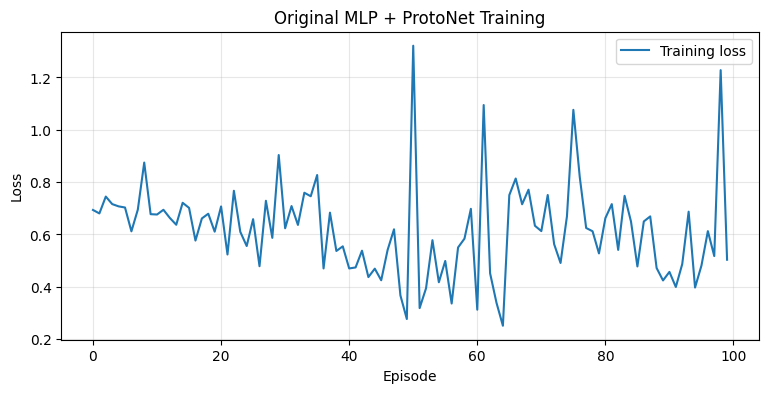


Average accuracy (last 20 episodes): 68.0 %
Step 7.2A completed!


In [231]:

# ============================================================
# PHASE 7 — STEP 7.2A
# Train Original MLP + ProtoNet (100 Episodes)
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# Set up training
optimizer = torch.optim.Adam(
    mlp_encoder.parameters(),
    lr=0.001
)

NUM_EPISODES = 100
train_losses = []
train_accuracies = []

train_rng = np.random.default_rng(2026)

mlp_encoder.train()

for step in range(NUM_EPISODES):

    # Create a new training episode
    train_episode = sample_protonet_episode(
        X=X_train_scaled,
        y=y_train,
        metadata=pilot_labeled_metadata,
        n_shot=5,
        n_query=5,
        rng=train_rng
    )

    optimizer.zero_grad()

    # Calculate loss and accuracy
    loss, accuracy, _, _ = protonet_forward(
        mlp_encoder,
        train_episode
    )

    # Update model weights
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())
    train_accuracies.append(accuracy.item() * 100)

    if (step + 1) % 20 == 0:
        print(
            f"Episode {step + 1:3d}/100 | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy.item() * 100:.1f}%"
        )

# Plot training results
plt.figure(figsize=(9, 4))
plt.plot(train_losses, label="Training loss")
plt.xlabel("Episode")
plt.ylabel("Loss")
plt.title("Original MLP + ProtoNet Training")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print("\nAverage accuracy (last 20 episodes):",
      round(np.mean(train_accuracies[-20:]), 2), "%")

print("Step 7.2A completed!")


In [232]:

# ============================================================
# PHASE 7 — STEP 7.2B
# Evaluate ProtoNet on Unseen Validation Aircraft
# ============================================================

import numpy as np
import torch

NUM_VAL_EPISODES = 100
val_rng = np.random.default_rng(2027)

val_accuracies = []
val_losses = []

mlp_encoder.eval()

with torch.no_grad():
    for i in range(NUM_VAL_EPISODES):

        val_episode = sample_protonet_episode(
            X=X_val_scaled,
            y=y_val,
            metadata=val_labeled_metadata,
            n_shot=5,
            n_query=5,
            rng=val_rng
        )

        loss, accuracy, _, _ = protonet_forward(
            mlp_encoder,
            val_episode
        )

        val_losses.append(loss.item())
        val_accuracies.append(accuracy.item() * 100)

print("1. VALIDATION RESULTS")
print("Episodes:", NUM_VAL_EPISODES)
print(
    "Mean validation accuracy:",
    round(np.mean(val_accuracies), 2), "%"
)
print(
    "Mean validation loss:",
    round(np.mean(val_losses), 4)
)
print(
    "Validation accuracy std:",
    round(np.std(val_accuracies), 2), "%"
)

print("\n2. GENERALIZATION COMPARISON")
print(
    "Training accuracy (last 20 episodes):",
    round(np.mean(train_accuracies[-20:]), 2), "%"
)
print(
    "Validation accuracy (100 episodes):",
    round(np.mean(val_accuracies), 2), "%"
)

print("\nStep 7.2B completed!")


1. VALIDATION RESULTS
Episodes: 100
Mean validation accuracy: 51.1 %
Mean validation loss: 0.8188
Validation accuracy std: 13.56 %

2. GENERALIZATION COMPARISON
Training accuracy (last 20 episodes): 68.0 %
Validation accuracy (100 episodes): 51.1 %

Step 7.2B completed!


1. CONFUSION MATRIX


,Predicted Normal,Predicted Path Attack
Actual Normal,257,243
Actual Path Attack,260,240



2. CLASSIFICATION REPORT
                   precision    recall  f1-score   support

           Normal       0.50      0.51      0.51       500
Path Modification       0.50      0.48      0.49       500

         accuracy                           0.50      1000
        macro avg       0.50      0.50      0.50      1000
     weighted avg       0.50      0.50      0.50      1000



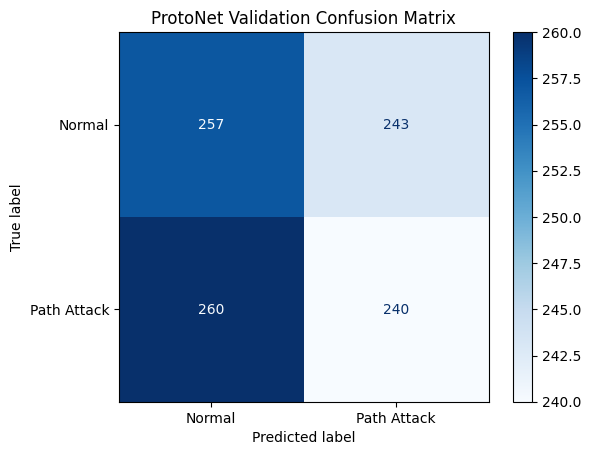


Step 7.2C completed!


In [233]:

# ============================================================
# PHASE 7 — STEP 7.2C
# Validation Confusion Matrix and Classification Report
# ============================================================

import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Use a fresh, reproducible sequence of episodes
diagnostic_rng = np.random.default_rng(2028)

all_true = []
all_pred = []

mlp_encoder.eval()

with torch.no_grad():
    for _ in range(100):

        ep = sample_protonet_episode(
            X=X_val_scaled,
            y=y_val,
            metadata=val_labeled_metadata,
            n_shot=5,
            n_query=5,
            rng=diagnostic_rng
        )

        _, _, predictions, _ = protonet_forward(
            mlp_encoder, ep
        )

        all_true.extend(ep["query_y"].cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

cm = confusion_matrix(
    all_true, all_pred, labels=[0, 1]
)

print("1. CONFUSION MATRIX")
display(pd.DataFrame(
    cm,
    index=["Actual Normal", "Actual Path Attack"],
    columns=["Predicted Normal", "Predicted Path Attack"]
))

print("\n2. CLASSIFICATION REPORT")
print(classification_report(
    all_true,
    all_pred,
    labels=[0, 1],
    target_names=["Normal", "Path Modification"],
    zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Path Attack"]
).plot(cmap="Blues")

plt.title("ProtoNet Validation Confusion Matrix")
plt.show()

print("\nStep 7.2C completed!")


In [234]:

# ============================================================
# PHASE 7 — STEP 7.3A
# Compare Feature Distributions by Class
# ============================================================

import numpy as np
import pandas as pd

# Compare original unscaled validation features
normal = X_val_raw[y_val == 0]
attack = X_val_raw[y_val == 1]

records = []

for j, feature in enumerate(ENGINEERED_FEATURE_COLS):

    normal_values = normal[:, :, j].reshape(-1)
    attack_values = attack[:, :, j].reshape(-1)

    mean_normal = np.mean(normal_values)
    mean_attack = np.mean(attack_values)

    # Express difference relative to training scaler
    train_std = scaler_airspace.scale_[j]

    standardized_difference = (
        abs(mean_attack - mean_normal)
        / max(train_std, 1e-8)
    )

    records.append({
        "Feature": feature,
        "Normal_Mean": mean_normal,
        "Attack_Mean": mean_attack,
        "Standardized_Mean_Difference":
            standardized_difference
    })

feature_difference_df = pd.DataFrame(records).sort_values(
    "Standardized_Mean_Difference",
    ascending=False
)

print("FEATURE DIFFERENCES BETWEEN CLASSES")
display(feature_difference_df.round(4))

print("\nStep 7.3A completed!")


FEATURE DIFFERENCES BETWEEN CLASSES


,Feature,Normal_Mean,Attack_Mean,Standardized_Mean_Difference
0,latitude,46.668499,46.049500,0.5653
3,track_sin,0.029300,-0.214500,0.5142
9,relative_longitude_m,153.507095,-709.654419,0.4548
4,track_cos,-0.811700,-0.707500,0.3071
1,longitude,2.682900,2.886500,0.2859
6,geoaltitude,34984.332031,35917.851562,0.2469
5,altitude,34726.988281,35452.394531,0.2116
8,relative_latitude_m,-2807.412354,-2395.708740,0.1868
10,speed_10s_knots,454.699005,451.867706,0.0427
11,speed_20s_knots,453.863403,451.539795,0.0400



Step 7.3A completed!


In [235]:

# ============================================================
# PHASE 7 — STEP 7.3B
# Matched Original vs Attacked Feature Comparison
# ============================================================

import numpy as np
import pandas as pd

# Select the first attack example from validation metadata
attack_row = val_labeled_metadata[
    val_labeled_metadata["label"] == 1
].iloc[0]

# Find its original validation-plan index
match = val_plan[
    (val_plan["flight_id"] == attack_row["flight_id"])
    & (val_plan["icao24"] == attack_row["icao24"])
    & (val_plan["local_start"] == attack_row["start"])
]

assert len(match) == 1
plan_index = int(match.index[0])

original = val_flight_lookup[attack_row["flight_id"]].copy(
    deep=True
)

start = int(attack_row["start"])
end = start + WINDOW_SIZE

# Recreate the exact same simulated attack
attacked, _ = simulate_path_modification(
    flight_df=original,
    start_index=start,
    intensity=attack_row["intensity"],
    attack_length=30,
    recovery_length=20,
    seed=123 + plan_index
)

# Engineer both flights independently
original_features = engineer_complete_flight(original)
attacked_features = engineer_complete_flight(attacked)

original_window = add_relative_positions(
    original_features.iloc[start:end].copy()
)

attacked_window = add_relative_positions(
    attacked_features.iloc[start:end].copy()
)

# Compare without float32 rounding
comparison = []

for feature in ENGINEERED_FEATURE_COLS:
    a = original_window[feature].to_numpy(
        dtype=np.float64
    )
    b = attacked_window[feature].to_numpy(
        dtype=np.float64
    )

    difference = np.abs(b - a)

    comparison.append({
        "Feature": feature,
        "Mean_Absolute_Change": difference.mean(),
        "Maximum_Absolute_Change": difference.max()
    })

matched_feature_df = pd.DataFrame(comparison)

print("SELECTED ATTACK")
print("Aircraft:", attack_row["icao24"])
print("Intensity:", attack_row["intensity"])

print("\nMATCHED FEATURE DIFFERENCES")
display(
    matched_feature_df.sort_values(
        "Maximum_Absolute_Change",
        ascending=False
    ).round(6)
)

print("\nStep 7.3B completed!")


SELECTED ATTACK
Aircraft: 34520f
Intensity: weak

MATCHED FEATURE DIFFERENCES


,Feature,Mean_Absolute_Change,Maximum_Absolute_Change
8,relative_latitude_m,45.465326,90.930652
9,relative_longitude_m,20.798268,41.589603
10,speed_10s_knots,5.008235,8.146395
11,speed_20s_knots,3.873678,7.135056
0,latitude,0.000409,0.000818
1,longitude,0.000265,0.000531
3,track_sin,0.000000,0.000000
2,groundspeed,0.000000,0.000000
7,vertical_rate,0.000000,0.000000
6,geoaltitude,0.000000,0.000000



Step 7.3B completed!


In [236]:

# ============================================================
# PHASE 7 — STEP 7.3C
# Add Speed-Consistency Features
# ============================================================

import numpy as np

def add_speed_consistency_features(X, feature_names):
    """
    Add two features to each trajectory observation:
    |reported speed - derived speed (10s)|
    |reported speed - derived speed (20s)|
    """

    speed_idx = feature_names.index("groundspeed")
    s10_idx = feature_names.index("speed_10s_knots")
    s20_idx = feature_names.index("speed_20s_knots")

    reported_speed = X[:, :, speed_idx]
    derived_10 = X[:, :, s10_idx]
    derived_20 = X[:, :, s20_idx]

    error_10 = np.abs(reported_speed - derived_10)
    error_20 = np.abs(reported_speed - derived_20)

    return np.concatenate(
        [
            X.astype(np.float32),
            error_10[..., None],
            error_20[..., None]
        ],
        axis=2
    ).astype(np.float32)


# IMPORTANT: Use RAW, unscaled tensors.
# These features must be calculated in original units.
X_train_14_raw = add_speed_consistency_features(
    X_train_raw,
    ENGINEERED_FEATURE_COLS
)

X_val_14_raw = add_speed_consistency_features(
    X_val_raw,
    ENGINEERED_FEATURE_COLS
)

FEATURE_COLS_14 = ENGINEERED_FEATURE_COLS + [
    "speed_error_10s",
    "speed_error_20s"
]

print("1. NEW TRAINING SHAPE:", X_train_14_raw.shape)
print("2. NEW VALIDATION SHAPE:", X_val_14_raw.shape)

print("\n3. NEW FEATURE NAMES")
print(FEATURE_COLS_14[-2:])

print("\n4. NUMERICAL CHECK")
print(
    "Training all finite:",
    np.isfinite(X_train_14_raw).all()
)
print(
    "Validation all finite:",
    np.isfinite(X_val_14_raw).all()
)

assert X_train_14_raw.shape == (100, 30, 14)
assert X_val_14_raw.shape == (100, 30, 14)

print("\nSUCCESS: Two speed-consistency features added!")


1. NEW TRAINING SHAPE: (100, 30, 14)
2. NEW VALIDATION SHAPE: (100, 30, 14)

3. NEW FEATURE NAMES
['speed_error_10s', 'speed_error_20s']

4. NUMERICAL CHECK
Training all finite: True
Validation all finite: True

SUCCESS: Two speed-consistency features added!


In [237]:

# ============================================================
# PHASE 7 — STEP 7.3D
# Scale 14-Feature Dataset
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Create a NEW scaler for the 14 features
scaler_14 = StandardScaler()

# Fit on training data ONLY
X_train_14_scaled = scaler_14.fit_transform(
    X_train_14_raw.reshape(-1, 14)
).reshape(-1, 30, 14).astype(np.float32)

# Apply the same scaler to validation data
X_val_14_scaled = scaler_14.transform(
    X_val_14_raw.reshape(-1, 14)
).reshape(-1, 30, 14).astype(np.float32)

# Verify results
print("1. TRAINING SHAPE:", X_train_14_scaled.shape)
print("2. VALIDATION SHAPE:", X_val_14_scaled.shape)

print("\n3. NUMERICAL CHECKS")
print("Training finite:", np.isfinite(X_train_14_scaled).all())
print("Validation finite:", np.isfinite(X_val_14_scaled).all())

print("\n4. NEW FEATURE STATISTICS")

stats = pd.DataFrame({
    "Feature": FEATURE_COLS_14,
    "Train_Mean": X_train_14_scaled.reshape(-1, 14).mean(axis=0),
    "Train_Std": X_train_14_scaled.reshape(-1, 14).std(axis=0)
})

display(stats.tail(2).round(4))

assert X_train_14_scaled.shape == (100, 30, 14)
assert X_val_14_scaled.shape == (100, 30, 14)
assert np.isfinite(X_train_14_scaled).all()
assert np.isfinite(X_val_14_scaled).all()

print("\nSUCCESS: 14-feature scaling completed!")


1. TRAINING SHAPE: (100, 30, 14)
2. VALIDATION SHAPE: (100, 30, 14)

3. NUMERICAL CHECKS
Training finite: True
Validation finite: True

4. NEW FEATURE STATISTICS


,Feature,Train_Mean,Train_Std
12,speed_error_10s,0.0,1.0
13,speed_error_20s,0.0,1.0



SUCCESS: 14-feature scaling completed!


Episode  20/100 | Loss: 0.6138 | Accuracy: 70.0%
Episode  40/100 | Loss: 0.5169 | Accuracy: 90.0%
Episode  60/100 | Loss: 0.5745 | Accuracy: 90.0%
Episode  80/100 | Loss: 0.4500 | Accuracy: 90.0%
Episode 100/100 | Loss: 0.3485 | Accuracy: 90.0%


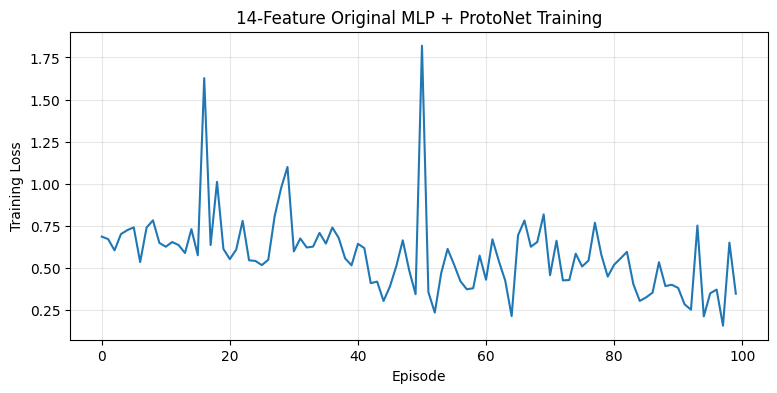


Average accuracy (last 20 episodes): 84.5 %

Step 7.4A completed!


In [238]:

# ============================================================
# PHASE 7 — STEP 7.4A
# Train Fresh 14-Feature MLP + ProtoNet
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Create NEW model (keep original model unchanged)
mlp_encoder_14 = OriginalMLPEncoder(
    sequence_length=30,
    num_features=14,
    embedding_dim=32
).to(DEVICE)

optimizer_14 = torch.optim.Adam(
    mlp_encoder_14.parameters(),
    lr=0.001
)

NUM_EPISODES = 100
train_rng_14 = np.random.default_rng(2026)

losses_14 = []
accuracies_14 = []

mlp_encoder_14.train()

for step in range(NUM_EPISODES):

    episode_14 = sample_protonet_episode(
        X=X_train_14_scaled,
        y=y_train,
        metadata=pilot_labeled_metadata,
        n_shot=5,
        n_query=5,
        rng=train_rng_14
    )

    optimizer_14.zero_grad()

    loss, accuracy, _, _ = protonet_forward(
        mlp_encoder_14,
        episode_14
    )

    loss.backward()
    optimizer_14.step()

    losses_14.append(loss.item())
    accuracies_14.append(accuracy.item() * 100)

    if (step + 1) % 20 == 0:
        print(
            f"Episode {step + 1:3d}/100 | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy.item() * 100:.1f}%"
        )

plt.figure(figsize=(9, 4))
plt.plot(losses_14)
plt.xlabel("Episode")
plt.ylabel("Training Loss")
plt.title("14-Feature Original MLP + ProtoNet Training")
plt.grid(alpha=0.3)
plt.show()

print("\nAverage accuracy (last 20 episodes):",
      round(np.mean(accuracies_14[-20:]), 2), "%")

print("\nStep 7.4A completed!")


In [239]:

# ============================================================
# PHASE 7 — STEP 7.4B
# Validate 14-Feature MLP + ProtoNet
# ============================================================

import numpy as np
import torch

NUM_VAL_EPISODES = 100

# Same seed used for the 12-feature validation
# This creates the same support/query episodes.
val_rng_14 = np.random.default_rng(2027)

val_accuracies_14 = []
val_losses_14 = []

mlp_encoder_14.eval()

with torch.no_grad():
    for _ in range(NUM_VAL_EPISODES):

        val_episode_14 = sample_protonet_episode(
            X=X_val_14_scaled,
            y=y_val,
            metadata=val_labeled_metadata,
            n_shot=5,
            n_query=5,
            rng=val_rng_14
        )

        loss, accuracy, _, _ = protonet_forward(
            mlp_encoder_14,
            val_episode_14
        )

        val_losses_14.append(loss.item())
        val_accuracies_14.append(accuracy.item() * 100)

print("1. VALIDATION RESULTS")
print("Mean validation accuracy:",
      round(np.mean(val_accuracies_14), 2), "%")
print("Mean validation loss:",
      round(np.mean(val_losses_14), 4))
print("Accuracy standard deviation:",
      round(np.std(val_accuracies_14), 2), "%")

print("\n2. MODEL COMPARISON")
print("12-feature validation:",
      round(np.mean(val_accuracies), 2), "%")
print("14-feature validation:",
      round(np.mean(val_accuracies_14), 2), "%")

print("Accuracy difference:",
      round(
          np.mean(val_accuracies_14)
          - np.mean(val_accuracies),
          2
      ), "percentage points")

print("\nStep 7.4B completed!")


1. VALIDATION RESULTS
Mean validation accuracy: 56.0 %
Mean validation loss: 0.9506
Accuracy standard deviation: 16.12 %

2. MODEL COMPARISON
12-feature validation: 51.1 %
14-feature validation: 56.0 %
Accuracy difference: 4.9 percentage points

Step 7.4B completed!


In [240]:

# ============================================================
# PHASE 7 — STEP 7.4C
# Detection Accuracy by Attack Intensity
# ============================================================

import numpy as np
import pandas as pd
import torch

rng = np.random.default_rng(2029)
records = []

mlp_encoder_14.eval()

with torch.no_grad():
    for _ in range(100):

        # Select episode indices using the same class balance
        selected_support = []
        selected_query = []

        for label in [0, 1]:
            indices = np.flatnonzero(y_val == label)
            selected = rng.choice(indices, size=10, replace=False)

            selected_support.extend(selected[:5])
            selected_query.extend(selected[5:])

        support_x = torch.as_tensor(
            X_val_14_scaled[selected_support],
            dtype=torch.float32,
            device=DEVICE
        )
        query_x = torch.as_tensor(
            X_val_14_scaled[selected_query],
            dtype=torch.float32,
            device=DEVICE
        )

        support_y = torch.as_tensor(
            y_val[selected_support],
            dtype=torch.long,
            device=DEVICE
        )
        query_y = torch.as_tensor(
            y_val[selected_query],
            dtype=torch.long,
            device=DEVICE
        )

        ep = {
            "support_x": support_x,
            "support_y": support_y,
            "query_x": query_x,
            "query_y": query_y
        }

        _, _, predictions, _ = protonet_forward(
            mlp_encoder_14, ep
        )

        for idx, prediction in zip(
            selected_query,
            predictions.cpu().numpy()
        ):
            if y_val[idx] == 1:
                records.append({
                    "intensity": val_labeled_metadata.iloc[idx]["intensity"],
                    "correct": int(prediction == 1)
                })

intensity_results = pd.DataFrame(records)

print("ATTACK DETECTION BY INTENSITY")
display(
    intensity_results.groupby("intensity")["correct"]
    .agg(["count", "mean"])
    .rename(columns={"count": "Queries", "mean": "Attack_Recall"})
    .round(4)
)

print("\nStep 7.4C completed!")


ATTACK DETECTION BY INTENSITY


,Queries,Attack_Recall
intensity,,
moderate,179,0.4804
strong,138,0.5870
weak,183,0.4208



Step 7.4C completed!


In [241]:

# ============================================================
# PHASE 7 — STEP 7.5A
# Check Training Data Expansion Capacity
# ============================================================

import pandas as pd

train_pool = window_index_df[
    window_index_df["partition"] == "Train"
].copy()

flight_lengths = flight_info.set_index(
    "flight_id"
)["n_observations"]

flight_starts = flight_info.set_index(
    "flight_id"
)["flight_start_row"]

train_pool["local_start"] = (
    train_pool["start_row"]
    - train_pool["flight_id"].map(flight_starts)
)

train_pool["flight_length"] = (
    train_pool["flight_id"].map(flight_lengths)
)

# Enough space for attack growth + recovery
eligible_pool = train_pool[
    (train_pool["local_start"] >= HISTORY)
    & (
        train_pool["local_start"] + 50
        <= train_pool["flight_length"]
    )
].copy()

# Keep track of aircraft already used in the pilot
pilot_aircraft = set(pilot_labeled_metadata["icao24"])

unused_pool = eligible_pool[
    ~eligible_pool["icao24"].isin(pilot_aircraft)
]

print("1. AVAILABLE TRAINING DATA")
print("Total training windows:", len(train_pool))
print("Eligible windows:", len(eligible_pool))
print(
    "Eligible aircraft:",
    eligible_pool["icao24"].nunique()
)

print("\n2. UNUSED TRAINING AIRCRAFT")
print(
    "Unused eligible aircraft:",
    unused_pool["icao24"].nunique()
)

print("\n3. EXPANSION FEASIBILITY")
for target in [200, 500, 1000, 1500]:
    possible = (
        eligible_pool["icao24"].nunique()
        >= target
    )

    print(
        f"{target} aircraft:",
        "Possible" if possible else "Not possible"
    )

print("\nStep 7.5A completed!")


1. AVAILABLE TRAINING DATA
Total training windows: 295882
Eligible windows: 288545
Eligible aircraft: 2053

2. UNUSED TRAINING AIRCRAFT
Unused eligible aircraft: 1953

3. EXPANSION FEASIBILITY
200 aircraft: Possible
500 aircraft: Possible
1000 aircraft: Possible
1500 aircraft: Possible

Step 7.5A completed!


In [242]:

# ============================================================
# PHASE 7 — STEP 7.5B
# Select 1,000 Training Windows
# ============================================================

import numpy as np
import pandas as pd

SEED_LARGE = 42
TARGET_SAMPLES = 1000

# Select 1,000 distinct training aircraft
rng_large = np.random.default_rng(SEED_LARGE)

available_ids = eligible_pool["icao24"].unique()

selected_ids = rng_large.choice(
    available_ids,
    size=TARGET_SAMPLES,
    replace=False
)

# One window from each aircraft
large_train_plan = (
    eligible_pool[
        eligible_pool["icao24"].isin(selected_ids)
    ]
    .groupby("icao24", group_keys=False)
    .sample(n=1, random_state=SEED_LARGE)
    .sample(frac=1, random_state=SEED_LARGE)
    .reset_index(drop=True)
)

# Assign balanced classes
large_train_plan["label"] = 0
large_train_plan.loc[500:, "label"] = 1

large_train_plan["attack_intensity"] = "none"

intensities = ["weak", "moderate", "strong"]

attack_rows = large_train_plan.index[
    large_train_plan["label"] == 1
]

large_train_plan.loc[
    attack_rows,
    "attack_intensity"
] = [
    intensities[i % 3]
    for i in range(len(attack_rows))
]

# Verify the plan
assert len(large_train_plan) == 1000
assert large_train_plan["icao24"].is_unique
assert set(large_train_plan["partition"]) == {"Train"}

assert set(large_train_plan["icao24"]).isdisjoint(
    set(val_aircraft) | set(test_aircraft)
)

print("1. TOTAL SELECTED WINDOWS:", len(large_train_plan))
print("2. UNIQUE AIRCRAFT:", large_train_plan["icao24"].nunique())

print("\n3. LABEL DISTRIBUTION")
display(
    large_train_plan["label"]
    .value_counts()
    .sort_index()
    .to_frame("Windows")
)

print("\n4. ATTACK INTENSITY DISTRIBUTION")
display(
    large_train_plan["attack_intensity"]
    .value_counts()
    .to_frame("Windows")
)

print("\n5. FIRST FIVE RECORDS")
display(large_train_plan.head())

print("\nSUCCESS: Step 7.5B completed!")


1. TOTAL SELECTED WINDOWS: 1000
2. UNIQUE AIRCRAFT: 1000

3. LABEL DISTRIBUTION


,Windows
label,
0,500
1,500



4. ATTACK INTENSITY DISTRIBUTION


,Windows
attack_intensity,
none,500
weak,167
moderate,167
strong,166



5. FIRST FIVE RECORDS


,flight_id,icao24,partition,start_row,end_row_exclusive,window_number,local_start,flight_length,label,attack_intensity
0,AFL2604_10977,424590,Train,1709284,1709314,20,620,723,0,none
1,BPA1634_13630,4ca088,Train,3897544,3897574,4,140,692,0,none
2,RYR311E_13659,4ca1c3,Train,9778988,9779018,13,410,987,0,none
3,TRA15Q_12493,4855bf,Train,11863315,11863345,10,320,1118,0,none
4,EZY64CU_9669,405636,Train,6396254,6396284,36,1100,1549,0,none



SUCCESS: Step 7.5B completed!


In [243]:

# ============================================================
# PHASE 7 — STEP 7.5C
# Generate 1,000 Training Samples (14 Features)
# ============================================================

import numpy as np
import pandas as pd

large_tensors = []
large_labels = []
large_metadata = []
large_rejections = []

selected_flights = large_train_plan["flight_id"].unique()

# Load only selected training flights
large_source = df_airspace[
    df_airspace["flight_id"].isin(selected_flights)
].copy()

flight_lookup_large = {
    fid: group.sort_values("timestamp").reset_index(drop=True)
    for fid, group in large_source.groupby("flight_id")
}

for i, row in large_train_plan.iterrows():

    original = flight_lookup_large[row["flight_id"]]
    start = int(row["local_start"])
    end = start + WINDOW_SIZE

    label = int(row["label"])
    modified = original.copy(deep=True)

    if label == 1:
        modified, _ = simulate_path_modification(
            flight_df=original,
            start_index=start,
            intensity=row["attack_intensity"],
            attack_length=30,
            recovery_length=20,
            seed=42 + i
        )

    # Engineer features AFTER modification
    engineered = engineer_complete_flight(modified)

    window = add_relative_positions(
        engineered.iloc[start:end].copy()
    )

    # Calculate in float64 before converting to float32
    x12 = window[
        ENGINEERED_FEATURE_COLS
    ].to_numpy(dtype=np.float64)

    if x12.shape != (30, 12) or not np.isfinite(x12).all():
        large_rejections.append(i)
        continue

    # Add the two speed-consistency features
    speed_i = ENGINEERED_FEATURE_COLS.index("groundspeed")
    speed10_i = ENGINEERED_FEATURE_COLS.index("speed_10s_knots")
    speed20_i = ENGINEERED_FEATURE_COLS.index("speed_20s_knots")

    error10 = np.abs(x12[:, speed_i] - x12[:, speed10_i])
    error20 = np.abs(x12[:, speed_i] - x12[:, speed20_i])

    x14 = np.column_stack([x12, error10, error20])

    if not np.isfinite(x14).all():
        large_rejections.append(i)
        continue

    large_tensors.append(x14.astype(np.float32))
    large_labels.append(label)

    large_metadata.append({
        "icao24": row["icao24"],
        "flight_id": row["flight_id"],
        "partition": "Train",
        "label": label,
        "intensity": row["attack_intensity"]
    })

X_large_raw = np.stack(large_tensors)
y_large = np.asarray(large_labels, dtype=np.int64)
large_metadata_df = pd.DataFrame(large_metadata)

print("1. DATASET SHAPE:", X_large_raw.shape)
print("2. LABEL SHAPE:", y_large.shape)
print("3. UNIQUE AIRCRAFT:",
      large_metadata_df["icao24"].nunique())
print("4. REJECTED SAMPLES:", len(large_rejections))
print("5. ALL FINITE:", np.isfinite(X_large_raw).all())

print("\n6. CLASS DISTRIBUTION")
display(
    pd.Series(y_large).value_counts()
    .sort_index().to_frame("Samples")
)

assert X_large_raw.shape == (1000, 30, 14)
assert len(large_rejections) == 0
assert large_metadata_df["icao24"].is_unique

print("\nSUCCESS: Step 7.5C completed!")


1. DATASET SHAPE: (1000, 30, 14)
2. LABEL SHAPE: (1000,)
3. UNIQUE AIRCRAFT: 1000
4. REJECTED SAMPLES: 0
5. ALL FINITE: True

6. CLASS DISTRIBUTION


,Samples
0,500
1,500



SUCCESS: Step 7.5C completed!


In [244]:

# ============================================================
# PHASE 7 — STEP 7.5D
# Verify Larger Training Dataset
# ============================================================

import numpy as np
import pandas as pd

EXPECTED_METERS = {
    "weak": 100.0,
    "moderate": 300.0,
    "strong": 500.0
}

records = []

for i, row in large_train_plan.reset_index(drop=True).iterrows():

    if int(row["label"]) != 1:
        continue

    original = flight_lookup_large[row["flight_id"]]
    start = int(row["local_start"])
    intensity = row["attack_intensity"]

    attacked, _ = simulate_path_modification(
        flight_df=original,
        start_index=start,
        intensity=intensity,
        attack_length=30,
        recovery_length=20,
        seed=42 + i
    )

    original_window = original.iloc[start:start+30]
    attacked_window = attacked.iloc[start:start+30]

    displacement = haversine_distance(
        original_window["latitude"].to_numpy(),
        original_window["longitude"].to_numpy(),
        attacked_window["latitude"].to_numpy(),
        attacked_window["longitude"].to_numpy()
    )

    modified_count = int(np.sum(displacement > 1e-6))

    records.append({
        "intensity": intensity,
        "max_displacement_m": float(np.max(displacement)),
        "modified_observations": modified_count,
        "expected_m": EXPECTED_METERS[intensity]
    })

large_attack_checks = pd.DataFrame(records)

large_attack_checks["error_m"] = np.abs(
    large_attack_checks["max_displacement_m"]
    - large_attack_checks["expected_m"]
)

print("1. ATTACK INTENSITY VERIFICATION")
display(
    large_attack_checks.groupby("intensity").agg(
        Samples=("intensity", "size"),
        Mean_Displacement_m=("max_displacement_m", "mean"),
        Maximum_Error_m=("error_m", "max"),
        Minimum_Modified=("modified_observations", "min")
    ).round(4)
)

print("\n2. OVERALL CHECKS")
print("Verified attacks:", len(large_attack_checks))
print("Maximum displacement error:",
      round(large_attack_checks["error_m"].max(), 4), "m")
print("Minimum modified observations:",
      large_attack_checks["modified_observations"].min())

assert len(large_attack_checks) == 500
assert (large_attack_checks["error_m"] < 1.0).all()
assert (large_attack_checks["modified_observations"] >= 24).all()

print("\nSUCCESS: Step 7.5D completed!")


1. ATTACK INTENSITY VERIFICATION


,Samples,Mean_Displacement_m,Maximum_Error_m,Minimum_Modified
intensity,,,,
moderate,167,300.0001,0.0030,29
strong,166,500.0010,0.0083,29
weak,167,100.0000,0.0003,29



2. OVERALL CHECKS
Verified attacks: 500
Maximum displacement error: 0.0083 m
Minimum modified observations: 29

SUCCESS: Step 7.5D completed!


In [245]:

# ============================================================
# PHASE 7 — STEP 7.5E
# Scale Larger 14-Feature Training Dataset
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Create a new scaler for the expanded training dataset
scaler_large_14 = StandardScaler()

# Fit using TRAINING data only
X_large_scaled = scaler_large_14.fit_transform(
    X_large_raw.reshape(-1, 14)
).reshape(1000, 30, 14).astype(np.float32)

# Apply the SAME scaler to existing validation data
X_val_large_scaled = scaler_large_14.transform(
    X_val_14_raw.reshape(-1, 14)
).reshape(100, 30, 14).astype(np.float32)

# Check results
print("1. TRAINING SHAPE:", X_large_scaled.shape)
print("2. VALIDATION SHAPE:", X_val_large_scaled.shape)

print("\n3. NUMERICAL CHECKS")
print("Training finite:", np.isfinite(X_large_scaled).all())
print("Validation finite:", np.isfinite(X_val_large_scaled).all())

print("\n4. TRAINING FEATURE STATISTICS")
flat = X_large_scaled.reshape(-1, 14)

stats_large = pd.DataFrame({
    "Feature": FEATURE_COLS_14,
    "Mean": flat.mean(axis=0),
    "Std": flat.std(axis=0)
})

display(stats_large.round(4))

print("\n5. AIRCRAFT DISJOINTNESS")
overlap = (
    set(large_metadata_df["icao24"])
    & set(val_labeled_metadata["icao24"])
)

print("Overlapping aircraft:", len(overlap))

assert X_large_scaled.shape == (1000, 30, 14)
assert X_val_large_scaled.shape == (100, 30, 14)
assert np.isfinite(X_large_scaled).all()
assert np.isfinite(X_val_large_scaled).all()
assert len(overlap) == 0

print("\nSUCCESS: Step 7.5E completed!")


1. TRAINING SHAPE: (1000, 30, 14)
2. VALIDATION SHAPE: (100, 30, 14)

3. NUMERICAL CHECKS
Training finite: True
Validation finite: True

4. TRAINING FEATURE STATISTICS


,Feature,Mean,Std
0,latitude,-0.0,1.0
1,longitude,0.0,1.0
2,groundspeed,0.0,1.0
3,track_sin,-0.0,1.0
4,track_cos,-0.0,1.0
5,altitude,0.0,1.0
6,geoaltitude,-0.0,1.0
7,vertical_rate,0.0,1.0
8,relative_latitude_m,-0.0,1.0
9,relative_longitude_m,-0.0,1.0



5. AIRCRAFT DISJOINTNESS
Overlapping aircraft: 0

SUCCESS: Step 7.5E completed!


Episode  50/300 | Loss: 0.7541 | Accuracy: 40.0%
Episode 100/300 | Loss: 0.6745 | Accuracy: 60.0%
Episode 150/300 | Loss: 0.6700 | Accuracy: 50.0%
Episode 200/300 | Loss: 0.8822 | Accuracy: 60.0%
Episode 250/300 | Loss: 0.7154 | Accuracy: 40.0%
Episode 300/300 | Loss: 0.5309 | Accuracy: 70.0%


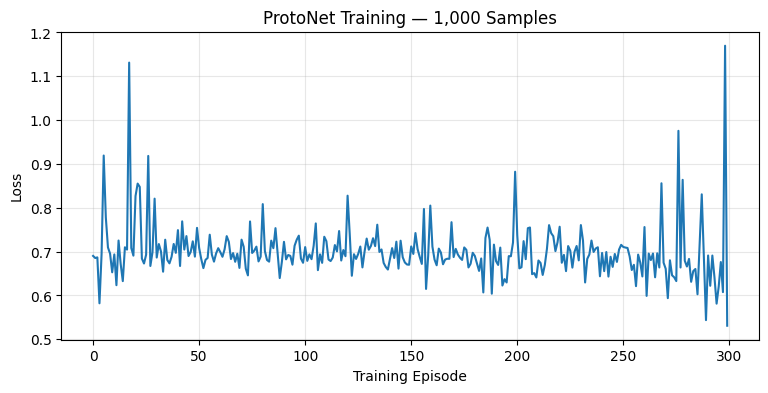


Average training accuracy (last 50 episodes): 60.8 %

Step 7.5F completed!


In [246]:

# ============================================================
# PHASE 7 — STEP 7.5F
# Train 14-Feature ProtoNet on 1,000 Samples
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Create a fresh encoder
mlp_encoder_large = OriginalMLPEncoder(
    sequence_length=30,
    num_features=14,
    embedding_dim=32
).to(DEVICE)

optimizer_large = torch.optim.Adam(
    mlp_encoder_large.parameters(),
    lr=0.001
)

NUM_LARGE_EPISODES = 300

large_train_losses = []
large_train_accuracies = []

large_rng = np.random.default_rng(2026)

mlp_encoder_large.train()

for step in range(NUM_LARGE_EPISODES):

    ep = sample_protonet_episode(
        X=X_large_scaled,
        y=y_large,
        metadata=large_metadata_df,
        n_shot=5,
        n_query=5,
        rng=large_rng
    )

    optimizer_large.zero_grad()

    loss, accuracy, _, _ = protonet_forward(
        mlp_encoder_large, ep
    )

    loss.backward()
    optimizer_large.step()

    large_train_losses.append(loss.item())
    large_train_accuracies.append(accuracy.item() * 100)

    if (step + 1) % 50 == 0:
        print(
            f"Episode {step + 1:3d}/300 | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy.item() * 100:.1f}%"
        )

plt.figure(figsize=(9, 4))
plt.plot(large_train_losses)
plt.xlabel("Training Episode")
plt.ylabel("Loss")
plt.title("ProtoNet Training — 1,000 Samples")
plt.grid(alpha=0.3)
plt.show()

print("\nAverage training accuracy (last 50 episodes):",
      round(np.mean(large_train_accuracies[-50:]), 2), "%")

print("\nStep 7.5F completed!")


In [247]:

# ============================================================
# PHASE 7 — STEP 7.5G
# Validate the 1,000-Sample ProtoNet Model
# ============================================================

import numpy as np
import torch

val_rng_large = np.random.default_rng(2027)

large_val_accuracies = []
large_val_losses = []

mlp_encoder_large.eval()

with torch.no_grad():
    for _ in range(100):

        ep = sample_protonet_episode(
            X=X_val_large_scaled,
            y=y_val,
            metadata=val_labeled_metadata,
            n_shot=5,
            n_query=5,
            rng=val_rng_large
        )

        loss, accuracy, _, _ = protonet_forward(
            mlp_encoder_large, ep
        )

        large_val_losses.append(loss.item())
        large_val_accuracies.append(accuracy.item() * 100)

print("1. LARGER MODEL VALIDATION")
print("Mean accuracy:",
      round(np.mean(large_val_accuracies), 2), "%")
print("Mean loss:",
      round(np.mean(large_val_losses), 4))
print("Accuracy standard deviation:",
      round(np.std(large_val_accuracies), 2), "%")

print("\n2. MODEL COMPARISON")
print("100-sample model:",
      round(np.mean(val_accuracies_14), 2), "%")
print("1,000-sample model:",
      round(np.mean(large_val_accuracies), 2), "%")

print("Difference:",
      round(
          np.mean(large_val_accuracies)
          - np.mean(val_accuracies_14),
          2
      ), "percentage points")

print("\nStep 7.5G completed!")


1. LARGER MODEL VALIDATION
Mean accuracy: 58.9 %
Mean loss: 0.6794
Accuracy standard deviation: 15.93 %

2. MODEL COMPARISON
100-sample model: 56.0 %
1,000-sample model: 58.9 %
Difference: 2.9 percentage points

Step 7.5G completed!


In [248]:

# ============================================================
# PHASE 7 — STEP 7.5H
# Validation Confusion Matrix — Larger Model
# ============================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

diagnostic_rng_large = np.random.default_rng(2030)

true_labels = []
predicted_labels = []

mlp_encoder_large.eval()

with torch.no_grad():
    for _ in range(100):

        episode = sample_protonet_episode(
            X=X_val_large_scaled,
            y=y_val,
            metadata=val_labeled_metadata,
            n_shot=5,
            n_query=5,
            rng=diagnostic_rng_large
        )

        _, _, predictions, _ = protonet_forward(
            mlp_encoder_large,
            episode
        )

        true_labels.extend(
            episode["query_y"].cpu().tolist()
        )
        predicted_labels.extend(
            predictions.cpu().tolist()
        )

cm_large = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1]
)

print("1. CONFUSION MATRIX")
display(pd.DataFrame(
    cm_large,
    index=["Actual Normal", "Actual Attack"],
    columns=["Predicted Normal", "Predicted Attack"]
))

print("\n2. CLASSIFICATION REPORT")
print(classification_report(
    true_labels,
    predicted_labels,
    target_names=["Normal", "Path Modification"],
    zero_division=0
))

print("\nStep 7.5H completed!")


1. CONFUSION MATRIX


,Predicted Normal,Predicted Attack
Actual Normal,336,164
Actual Attack,219,281



2. CLASSIFICATION REPORT
                   precision    recall  f1-score   support

           Normal       0.61      0.67      0.64       500
Path Modification       0.63      0.56      0.59       500

         accuracy                           0.62      1000
        macro avg       0.62      0.62      0.62      1000
     weighted avg       0.62      0.62      0.62      1000


Step 7.5H completed!


In [249]:

# ============================================================
# PHASE 7 — STEP 7.6A
# Remove Absolute Geographic Coordinates
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Keep all features except absolute latitude and longitude
MOTION_FEATURES = [
    feature for feature in FEATURE_COLS_14
    if feature not in ["latitude", "longitude"]
]

feature_indices = [
    FEATURE_COLS_14.index(feature)
    for feature in MOTION_FEATURES
]

# Use RAW datasets
X_train_motion_raw = X_large_raw[:, :, feature_indices]
X_val_motion_raw = X_val_14_raw[:, :, feature_indices]

# Fit on training data only
scaler_motion = StandardScaler()

X_train_motion = scaler_motion.fit_transform(
    X_train_motion_raw.reshape(-1, 12)
).reshape(-1, 30, 12).astype(np.float32)

X_val_motion = scaler_motion.transform(
    X_val_motion_raw.reshape(-1, 12)
).reshape(-1, 30, 12).astype(np.float32)

print("1. TRAINING SHAPE:", X_train_motion.shape)
print("2. VALIDATION SHAPE:", X_val_motion.shape)

print("\n3. KEPT FEATURES")
for i, feature in enumerate(MOTION_FEATURES, 1):
    print(f"{i}. {feature}")

print("\n4. NUMERICAL CHECKS")
print("Training finite:", np.isfinite(X_train_motion).all())
print("Validation finite:", np.isfinite(X_val_motion).all())

assert X_train_motion.shape == (1000, 30, 12)
assert X_val_motion.shape == (100, 30, 12)

print("\nSUCCESS: Step 7.6A completed!")


1. TRAINING SHAPE: (1000, 30, 12)
2. VALIDATION SHAPE: (100, 30, 12)

3. KEPT FEATURES
1. groundspeed
2. track_sin
3. track_cos
4. altitude
5. geoaltitude
6. vertical_rate
7. relative_latitude_m
8. relative_longitude_m
9. speed_10s_knots
10. speed_20s_knots
11. speed_error_10s
12. speed_error_20s

4. NUMERICAL CHECKS
Training finite: True
Validation finite: True

SUCCESS: Step 7.6A completed!


Episode 50/300 | Loss: 0.7299 | Accuracy: 40.0%
Episode 100/300 | Loss: 0.6790 | Accuracy: 60.0%
Episode 150/300 | Loss: 0.7016 | Accuracy: 60.0%
Episode 200/300 | Loss: 0.6814 | Accuracy: 60.0%
Episode 250/300 | Loss: 0.6547 | Accuracy: 70.0%
Episode 300/300 | Loss: 0.7034 | Accuracy: 40.0%


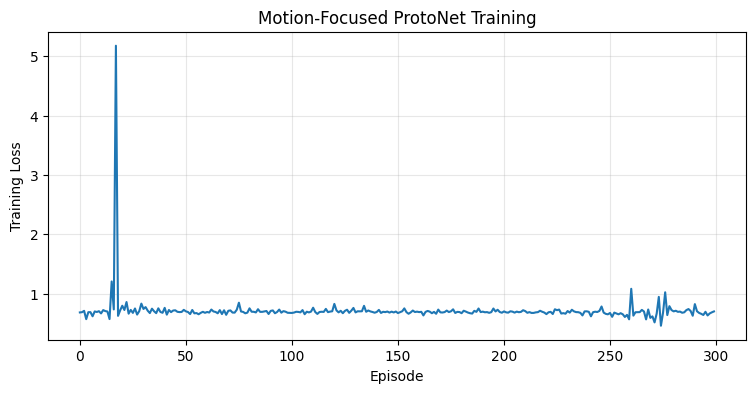


Average accuracy (last 50 episodes): 54.2 %

Step 7.6B completed!


In [250]:

# ============================================================
# PHASE 7 — STEP 7.6B
# Train Motion-Focused MLP + ProtoNet
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# Fresh model with 12 motion-focused features
mlp_encoder_motion = OriginalMLPEncoder(
    sequence_length=30,
    num_features=12,
    embedding_dim=32
).to(DEVICE)

optimizer_motion = torch.optim.Adam(
    mlp_encoder_motion.parameters(),
    lr=0.001
)

motion_rng = np.random.default_rng(2026)

motion_losses = []
motion_accuracies = []

mlp_encoder_motion.train()

for step in range(300):

    ep = sample_protonet_episode(
        X=X_train_motion,
        y=y_large,
        metadata=large_metadata_df,
        n_shot=5,
        n_query=5,
        rng=motion_rng
    )

    optimizer_motion.zero_grad()

    loss, accuracy, _, _ = protonet_forward(
        mlp_encoder_motion, ep
    )

    loss.backward()
    optimizer_motion.step()

    motion_losses.append(loss.item())
    motion_accuracies.append(accuracy.item() * 100)

    if (step + 1) % 50 == 0:
        print(
            f"Episode {step + 1}/300 | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy.item() * 100:.1f}%"
        )

plt.figure(figsize=(9, 4))
plt.plot(motion_losses)
plt.xlabel("Episode")
plt.ylabel("Training Loss")
plt.title("Motion-Focused ProtoNet Training")
plt.grid(alpha=0.3)
plt.show()

print("\nAverage accuracy (last 50 episodes):",
      round(np.mean(motion_accuracies[-50:]), 2), "%")

print("\nStep 7.6B completed!")


In [251]:

# ============================================================
# PHASE 7 — STEP 7.6C
# Validate Motion-Focused ProtoNet
# ============================================================

import numpy as np
import torch

val_rng_motion = np.random.default_rng(2027)

motion_val_accuracies = []
motion_val_losses = []

mlp_encoder_motion.eval()

with torch.no_grad():
    for _ in range(100):

        episode = sample_protonet_episode(
            X=X_val_motion,
            y=y_val,
            metadata=val_labeled_metadata,
            n_shot=5,
            n_query=5,
            rng=val_rng_motion
        )

        loss, accuracy, _, _ = protonet_forward(
            mlp_encoder_motion,
            episode
        )

        motion_val_accuracies.append(
            accuracy.item() * 100
        )
        motion_val_losses.append(
            loss.item()
        )

print("MOTION-FOCUSED VALIDATION RESULTS")
print(
    "Mean accuracy:",
    round(np.mean(motion_val_accuracies), 2), "%"
)
print(
    "Mean loss:",
    round(np.mean(motion_val_losses), 4)
)
print(
    "Accuracy std:",
    round(np.std(motion_val_accuracies), 2), "%"
)

print("\nMODEL COMPARISON")
print(
    "14-feature validation:",
    round(np.mean(large_val_accuracies), 2), "%"
)
print(
    "Motion-focused validation:",
    round(np.mean(motion_val_accuracies), 2), "%"
)

print("\nStep 7.6C completed!")


MOTION-FOCUSED VALIDATION RESULTS
Mean accuracy: 51.6 %
Mean loss: 0.6919
Accuracy std: 16.23 %

MODEL COMPARISON
14-feature validation: 58.9 %
Motion-focused validation: 51.6 %

Step 7.6C completed!


In [252]:

# ============================================================
# PHASE 7 — STEP 7.7A
# Compare Attack Signal with Normal Variation
# ============================================================

"""
Now there is a clue
The changes introduced by our simulated attacks are generally much smaller than the natural differences between aircraft.
"""

import numpy as np
import pandas as pd

# Work with the 1,000-sample training dataset only.
# No validation or test data used in this diagnostic.

rng = np.random.default_rng(42)

# Select 50 attacked aircraft for matched comparisons
attack_indices = np.flatnonzero(y_large == 1)
selected_attacks = rng.choice(
    attack_indices,
    size=50,
    replace=False
)

matched_differences = []

for idx in selected_attacks:

    row = large_train_plan.iloc[idx]
    original = flight_lookup_large[row["flight_id"]]

    start = int(row["local_start"])
    end = start + 30

    # Reproduce the original simulated attack
    attacked, _ = simulate_path_modification(
        flight_df=original,
        start_index=start,
        intensity=row["attack_intensity"],
        attack_length=30,
        recovery_length=20,
        seed=42 + idx
    )

    # Engineer both versions
    orig_eng = engineer_complete_flight(original)
    atk_eng = engineer_complete_flight(attacked)

    orig_window = add_relative_positions(
        orig_eng.iloc[start:end].copy()
    )
    atk_window = add_relative_positions(
        atk_eng.iloc[start:end].copy()
    )

    orig_features = orig_window[
        ENGINEERED_FEATURE_COLS
    ].to_numpy(dtype=np.float64)

    atk_features = atk_window[
        ENGINEERED_FEATURE_COLS
    ].to_numpy(dtype=np.float64)

    matched_differences.append(
        np.abs(atk_features - orig_features).mean(axis=0)
    )

matched_differences = np.asarray(matched_differences)

# Natural variation among presumed-normal aircraft
normal_features = X_large_raw[
    y_large == 0, :, :12
].mean(axis=1)

natural_std = normal_features.std(axis=0)

attack_signal = matched_differences.mean(axis=0)

signal_ratio = attack_signal / np.maximum(
    natural_std, 1e-8
)

signal_table = pd.DataFrame({
    "Feature": ENGINEERED_FEATURE_COLS,
    "Mean_Attack_Change": attack_signal,
    "Normal_Between_Aircraft_Std": natural_std,
    "Signal_to_Variation_Ratio": signal_ratio
}).sort_values(
    "Signal_to_Variation_Ratio",
    ascending=False
)

print("ATTACK SIGNAL VS NATURAL VARIATION")
display(signal_table.round(4))

print("\nStep 7.7A completed!")


ATTACK SIGNAL VS NATURAL VARIATION


,Feature,Mean_Attack_Change,Normal_Between_Aircraft_Std,Signal_to_Variation_Ratio
10,speed_10s_knots,10.5526,53.184200,0.1984
11,speed_20s_knots,8.1507,52.408298,0.1555
8,relative_latitude_m,92.0164,1208.098877,0.0762
9,relative_longitude_m,92.6582,1836.618164,0.0505
1,longitude,0.0012,0.642200,0.0019
0,latitude,0.0008,1.071100,0.0008
3,track_sin,0.0000,0.538900,0.0000
2,groundspeed,0.0000,39.717899,0.0000
7,vertical_rate,0.0000,566.176392,0.0000
6,geoaltitude,0.0000,4056.924072,0.0000



Step 7.7A completed!


In [253]:

# ============================================================
# PHASE 7 — STEP 7.7B
# Explore Speed-Consistency Patterns
# ============================================================

import numpy as np
import pandas as pd

# Existing 14-feature training dataset
idx10 = FEATURE_COLS_14.index("speed_error_10s")
idx20 = FEATURE_COLS_14.index("speed_error_20s")

records = []

for i in range(len(X_large_raw)):

    error10 = X_large_raw[i, :, idx10]
    error20 = X_large_raw[i, :, idx20]

    records.append({
        "label": int(y_large[i]),
        "mean_error_10s": float(np.mean(error10)),
        "max_error_10s": float(np.max(error10)),
        "std_error_10s": float(np.std(error10)),
        "mean_error_20s": float(np.mean(error20)),
        "max_error_20s": float(np.max(error20)),
        "std_error_20s": float(np.std(error20))
    })

speed_pattern_df = pd.DataFrame(records)

print("SPEED-ERROR PATTERNS BY CLASS")
display(
    speed_pattern_df.groupby("label")
    .mean()
    .round(3)
)

print("\nStep 7.7B completed!")


SPEED-ERROR PATTERNS BY CLASS


,mean_error_10s,max_error_10s,std_error_10s,mean_error_20s,max_error_20s,std_error_20s
label,,,,,,
0,17.175,45.362,11.470,10.252,28.030,7.015
1,20.922,52.888,13.941,14.676,38.369,10.208



Step 7.7B completed!


In [254]:

# ============================================================
# PHASE 7 — STEP 7.7C
# Evaluate Speed-Error Feature Separation
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Use TRAINING data only for this diagnostic
feature_names = [
    "mean_error_10s",
    "max_error_10s",
    "std_error_10s",
    "mean_error_20s",
    "max_error_20s",
    "std_error_20s"
]

auc_records = []

for feature in feature_names:

    scores = speed_pattern_df[feature].to_numpy()
    labels = speed_pattern_df["label"].to_numpy()

    auc = roc_auc_score(labels, scores)

    auc_records.append({
        "Feature": feature,
        "ROC_AUC": auc
    })

auc_results = pd.DataFrame(auc_records).sort_values(
    "ROC_AUC",
    ascending=False
)

print("SPEED-ERROR FEATURE USEFULNESS")
display(auc_results.round(4))

print("\nStep 7.7C completed!")


SPEED-ERROR FEATURE USEFULNESS


,Feature,ROC_AUC
3,mean_error_20s,0.7371
5,std_error_20s,0.7072
4,max_error_20s,0.6982
0,mean_error_10s,0.6681
2,std_error_10s,0.6466
1,max_error_10s,0.6412



Step 7.7C completed!


In [255]:

# ============================================================
# PHASE 7 — STEP 7.7D
# Validate Speed-Error Features on Unseen Aircraft
# ============================================================


"""
the  features contain useful attack information, but our ProtoNet isn't using it effectively yet.
"""
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Use unscaled validation data
idx10 = FEATURE_COLS_14.index("speed_error_10s")
idx20 = FEATURE_COLS_14.index("speed_error_20s")

validation_feature_scores = {
    "mean_error_10s": X_val_14_raw[:, :, idx10].mean(axis=1),
    "max_error_10s": X_val_14_raw[:, :, idx10].max(axis=1),
    "std_error_10s": X_val_14_raw[:, :, idx10].std(axis=1),
    "mean_error_20s": X_val_14_raw[:, :, idx20].mean(axis=1),
    "max_error_20s": X_val_14_raw[:, :, idx20].max(axis=1),
    "std_error_20s": X_val_14_raw[:, :, idx20].std(axis=1)
}

records = []

for feature, scores in validation_feature_scores.items():
    records.append({
        "Feature": feature,
        "Training_AUC": float(
            auc_results.loc[
                auc_results["Feature"] == feature,
                "ROC_AUC"
            ].iloc[0]
        ),
        "Validation_AUC": roc_auc_score(y_val, scores)
    })

validation_auc_df = pd.DataFrame(records).sort_values(
    "Training_AUC",
    ascending=False
)

print("SPEED-ERROR FEATURE VALIDATION")
display(validation_auc_df.round(4))

print("\nStep 7.7D completed!")


SPEED-ERROR FEATURE VALIDATION


,Feature,Training_AUC,Validation_AUC
3,mean_error_20s,0.7371,0.7588
5,std_error_20s,0.7072,0.7324
4,max_error_20s,0.6982,0.7432
0,mean_error_10s,0.6681,0.6620
2,std_error_10s,0.6466,0.6508
1,max_error_10s,0.6412,0.6972



Step 7.7D completed!


In [256]:

# ============================================================
# PHASE 7 — STEP 7.7E
# Simple Speed-Error Baseline
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    balanced_accuracy_score
)

# Best feature identified using training data
train_scores = speed_pattern_df[
    "mean_error_20s"
].to_numpy()

train_labels = speed_pattern_df[
    "label"
].to_numpy()

val_scores = validation_feature_scores[
    "mean_error_20s"
]

# Find the best threshold using training data only
thresholds = np.unique(
    np.quantile(train_scores, np.linspace(0, 1, 201))
)

best_threshold = None
best_train_score = -1

for threshold in thresholds:
    predictions = (train_scores >= threshold).astype(int)

    score = balanced_accuracy_score(
        train_labels, predictions
    )

    if score > best_train_score:
        best_train_score = score
        best_threshold = threshold

# Apply fixed training-derived threshold to validation
val_predictions = (
    val_scores >= best_threshold
).astype(int)

print("1. TRAINING-SELECTED THRESHOLD")
print("Threshold:", round(float(best_threshold), 4))
print("Training balanced accuracy:",
      round(best_train_score * 100, 2), "%")

print("\n2. VALIDATION RESULTS")
print("Accuracy:",
      round(accuracy_score(y_val, val_predictions) * 100, 2),
      "%")
print("Balanced accuracy:",
      round(
          balanced_accuracy_score(y_val, val_predictions) * 100,
          2
      ), "%")
print("Macro F1:",
      round(f1_score(y_val, val_predictions, average="macro"), 4))

print("\n3. CONFUSION MATRIX")
print(confusion_matrix(y_val, val_predictions, labels=[0, 1]))

print("\nStep 7.7E completed!")


1. TRAINING-SELECTED THRESHOLD
Threshold: 9.0773
Training balanced accuracy: 69.2 %

2. VALIDATION RESULTS
Accuracy: 73.0 %
Balanced accuracy: 73.0 %
Macro F1: 0.7267

3. CONFUSION MATRIX
[[42  8]
 [19 31]]

Step 7.7E completed!


In [257]:

# ============================================================
# PHASE 7 — STEP 7.7F
# Simple Detector Performance by Attack Intensity
# ============================================================

import pandas as pd
import numpy as np

results = pd.DataFrame({
    "label": y_val,
    "prediction": val_predictions,
    "intensity": val_labeled_metadata["intensity"].to_numpy()
})

# Only simulated attack samples
attacks = results[results["label"] == 1].copy()

intensity_summary = (
    attacks.groupby("intensity")
    .agg(
        Samples=("prediction", "size"),
        Detected=("prediction", "sum"),
        Detection_Rate=("prediction", "mean")
    )
    .reset_index()
)

print("ATTACK DETECTION BY INTENSITY")
display(intensity_summary.round(4))

print("\nOVERALL ATTACK DETECTION")
print(
    "Detected:",
    int(attacks["prediction"].sum()),
    "out of",
    len(attacks)
)

print("\nStep 7.7F completed!")


ATTACK DETECTION BY INTENSITY


,intensity,Samples,Detected,Detection_Rate
0,moderate,17,12,0.7059
1,strong,16,13,0.8125
2,weak,17,6,0.3529



OVERALL ATTACK DETECTION
Detected: 31 out of 50

Step 7.7F completed!


In [258]:

# ============================================================
# PHASE 7 — STEP 7.7G
# Compare Both Models on the Same Query Windows
# ============================================================

import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score

rng = np.random.default_rng(2040)

# Select 5 support aircraft per class
support_indices = []

for label in [0, 1]:
    candidates = np.flatnonzero(y_val == label)
    support_indices.extend(
        rng.choice(candidates, size=5, replace=False)
    )

support_indices = np.array(support_indices)

# Query set excludes all support aircraft
support_aircraft = set(
    val_labeled_metadata.iloc[support_indices]["icao24"]
)

query_indices = np.array([
    i for i in range(len(y_val))
    if val_labeled_metadata.iloc[i]["icao24"]
    not in support_aircraft
])

assert len(query_indices) == 90

mlp_encoder_large.eval()

with torch.no_grad():
    support_x = torch.as_tensor(
        X_val_large_scaled[support_indices],
        dtype=torch.float32,
        device=DEVICE
    )

    query_x = torch.as_tensor(
        X_val_large_scaled[query_indices],
        dtype=torch.float32,
        device=DEVICE
    )

    support_y = torch.as_tensor(
        y_val[support_indices],
        dtype=torch.long,
        device=DEVICE
    )

    support_emb = mlp_encoder_large(support_x)
    query_emb = mlp_encoder_large(query_x)

    prototypes = torch.stack([
        support_emb[support_y == c].mean(dim=0)
        for c in [0, 1]
    ])

    distances = torch.cdist(query_emb, prototypes)
    protonet_predictions = (
        -(distances ** 2)
    ).argmax(dim=1).cpu().numpy()

# Evaluate both detectors on identical 90 query windows
actual = y_val[query_indices]
simple_predictions = val_predictions[query_indices]

print("QUERY WINDOWS:", len(query_indices))

print("\nPROTONET RESULTS")
print("Accuracy:",
      round(accuracy_score(actual, protonet_predictions) * 100, 2),
      "%")
print("Macro F1:",
      round(f1_score(actual, protonet_predictions,
                     average="macro"), 4))

print("\nSIMPLE DETECTOR RESULTS")
print("Accuracy:",
      round(accuracy_score(actual, simple_predictions) * 100, 2),
      "%")
print("Macro F1:",
      round(f1_score(actual, simple_predictions,
                     average="macro"), 4))

print("\nStep 7.7G completed!")


QUERY WINDOWS: 90

PROTONET RESULTS
Accuracy: 65.56 %
Macro F1: 0.6357

SIMPLE DETECTOR RESULTS
Accuracy: 73.33 %
Macro F1: 0.7285

Step 7.7G completed!


In [259]:

# ============================================================
# PHASE 7 — STEP 7.7H
# Repeated Matched-Query Comparison
# ============================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score

rng = np.random.default_rng(2041)
records = []

mlp_encoder_large.eval()

with torch.no_grad():
    for repeat in range(30):

        # Choose five support aircraft from each class
        support_indices = []

        for label in [0, 1]:
            candidates = np.flatnonzero(y_val == label)

            support_indices.extend(
                rng.choice(candidates, size=5, replace=False)
            )

        support_indices = np.asarray(support_indices)

        # Evaluate both methods on the same remaining windows
        query_mask = np.ones(len(y_val), dtype=bool)
        query_mask[support_indices] = False
        query_indices = np.flatnonzero(query_mask)

        support_x = torch.as_tensor(
            X_val_large_scaled[support_indices],
            dtype=torch.float32,
            device=DEVICE
        )
        query_x = torch.as_tensor(
            X_val_large_scaled[query_indices],
            dtype=torch.float32,
            device=DEVICE
        )
        support_y = torch.as_tensor(
            y_val[support_indices],
            dtype=torch.long,
            device=DEVICE
        )

        support_emb = mlp_encoder_large(support_x)
        query_emb = mlp_encoder_large(query_x)

        prototypes = torch.stack([
            support_emb[support_y == c].mean(dim=0)
            for c in [0, 1]
        ])

        predictions = (
            -torch.cdist(query_emb, prototypes).square()
        ).argmax(dim=1).cpu().numpy()

        actual = y_val[query_indices]
        simple_pred = val_predictions[query_indices]

        records.append({
            "Repeat": repeat + 1,
            "ProtoNet_Accuracy": accuracy_score(
                actual, predictions
            ),
            "Simple_Accuracy": accuracy_score(
                actual, simple_pred
            ),
            "ProtoNet_MacroF1": f1_score(
                actual, predictions,
                average="macro",
                zero_division=0
            ),
            "Simple_MacroF1": f1_score(
                actual, simple_pred,
                average="macro",
                zero_division=0
            )
        })

comparison_30 = pd.DataFrame(records)

print("REPEATED COMPARISON — 30 SUPPORT SETS")
display(
    comparison_30.drop(columns="Repeat")
    .agg(["mean", "std"])
    .round(4)
)

print("\nAverage accuracy difference (ProtoNet - Simple):")
print(
    round(
        100 * (
            comparison_30["ProtoNet_Accuracy"].mean()
            - comparison_30["Simple_Accuracy"].mean()
        ),
        2
    ),
    "percentage points"
)

print("\nStep 7.7H completed!")


REPEATED COMPARISON — 30 SUPPORT SETS


,ProtoNet_Accuracy,Simple_Accuracy,ProtoNet_MacroF1,Simple_MacroF1
mean,0.6156,0.7256,0.6060,0.7220
std,0.0717,0.0131,0.0801,0.0135



Average accuracy difference (ProtoNet - Simple):
-11.0 percentage points

Step 7.7H completed!


In [260]:

# ============================================================
# PHASE 7 — STEP 7.8A
# Prepare Four Speed-Related Features
# ============================================================

import numpy as np
from sklearn.preprocessing import StandardScaler

SPEED_FEATURES = [
    "groundspeed",
    "speed_20s_knots",
    "speed_error_10s",
    "speed_error_20s"
]

speed_indices = [
    FEATURE_COLS_14.index(name)
    for name in SPEED_FEATURES
]

# Use raw datasets
X_train_speed_raw = X_large_raw[:, :, speed_indices]
X_val_speed_raw = X_val_14_raw[:, :, speed_indices]

# Fit scaler on training data only
scaler_speed = StandardScaler()

X_train_speed = scaler_speed.fit_transform(
    X_train_speed_raw.reshape(-1, 4)
).reshape(-1, 30, 4).astype(np.float32)

X_val_speed = scaler_speed.transform(
    X_val_speed_raw.reshape(-1, 4)
).reshape(-1, 30, 4).astype(np.float32)

print("TRAINING SHAPE:", X_train_speed.shape)
print("VALIDATION SHAPE:", X_val_speed.shape)

print("\nSELECTED FEATURES:")
for feature in SPEED_FEATURES:
    print("-", feature)

print("\nNUMERICAL CHECKS")
print("Training finite:", np.isfinite(X_train_speed).all())
print("Validation finite:", np.isfinite(X_val_speed).all())

assert X_train_speed.shape == (1000, 30, 4)
assert X_val_speed.shape == (100, 30, 4)

print("\nSUCCESS: Step 7.8A completed!")


TRAINING SHAPE: (1000, 30, 4)
VALIDATION SHAPE: (100, 30, 4)

SELECTED FEATURES:
- groundspeed
- speed_20s_knots
- speed_error_10s
- speed_error_20s

NUMERICAL CHECKS
Training finite: True
Validation finite: True

SUCCESS: Step 7.8A completed!


Episode 50/300 | Loss: 0.6399 | Accuracy: 70.0%
Episode 100/300 | Loss: 0.6628 | Accuracy: 80.0%
Episode 150/300 | Loss: 0.6419 | Accuracy: 60.0%
Episode 200/300 | Loss: 0.6803 | Accuracy: 80.0%
Episode 250/300 | Loss: 0.2883 | Accuracy: 90.0%
Episode 300/300 | Loss: 0.3880 | Accuracy: 80.0%


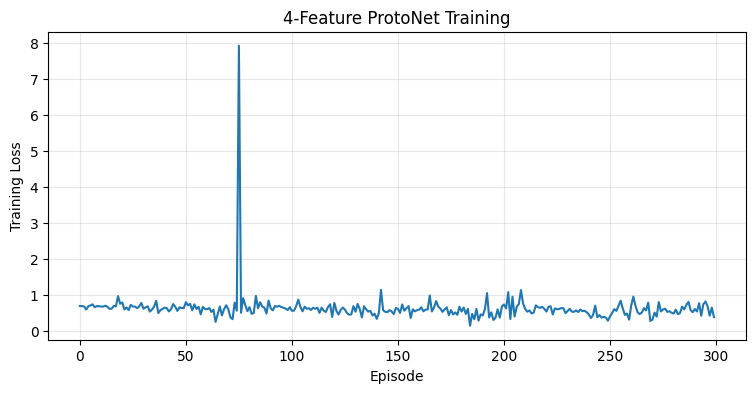


Average accuracy (last 50 episodes): 71.8 %

Step 7.8B completed!


In [261]:

# ============================================================
# PHASE 7 — STEP 7.8B
# Train 4-Feature MLP + ProtoNet
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Create a fresh 4-feature encoder
mlp_encoder_speed = OriginalMLPEncoder(
    sequence_length=30,
    num_features=4,
    embedding_dim=32
).to(DEVICE)

optimizer_speed = torch.optim.Adam(
    mlp_encoder_speed.parameters(),
    lr=0.001
)

speed_rng = np.random.default_rng(2026)

speed_losses = []
speed_accuracies = []

mlp_encoder_speed.train()

for step in range(300):

    episode = sample_protonet_episode(
        X=X_train_speed,
        y=y_large,
        metadata=large_metadata_df,
        n_shot=5,
        n_query=5,
        rng=speed_rng
    )

    optimizer_speed.zero_grad()

    loss, accuracy, _, _ = protonet_forward(
        mlp_encoder_speed,
        episode
    )

    loss.backward()
    optimizer_speed.step()

    speed_losses.append(loss.item())
    speed_accuracies.append(accuracy.item() * 100)

    if (step + 1) % 50 == 0:
        print(
            f"Episode {step + 1}/300 | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy.item() * 100:.1f}%"
        )

plt.figure(figsize=(9, 4))
plt.plot(speed_losses)
plt.xlabel("Episode")
plt.ylabel("Training Loss")
plt.title("4-Feature ProtoNet Training")
plt.grid(alpha=0.3)
plt.show()

print(
    "\nAverage accuracy (last 50 episodes):",
    round(np.mean(speed_accuracies[-50:]), 2),
    "%"
)

print("\nStep 7.8B completed!")


In [262]:

# ============================================================
# PHASE 7 — STEP 7.8C
# Validate 4-Feature ProtoNet
# ============================================================

import numpy as np
import torch

val_rng_speed = np.random.default_rng(2027)

speed_val_accuracies = []
speed_val_losses = []

mlp_encoder_speed.eval()

with torch.no_grad():
    for _ in range(100):

        episode = sample_protonet_episode(
            X=X_val_speed,
            y=y_val,
            metadata=val_labeled_metadata,
            n_shot=5,
            n_query=5,
            rng=val_rng_speed
        )

        loss, accuracy, _, _ = protonet_forward(
            mlp_encoder_speed,
            episode
        )

        speed_val_accuracies.append(
            accuracy.item() * 100
        )
        speed_val_losses.append(loss.item())

print("1. VALIDATION RESULTS")
print(
    "Mean accuracy:",
    round(np.mean(speed_val_accuracies), 2), "%"
)
print(
    "Mean loss:",
    round(np.mean(speed_val_losses), 4)
)
print(
    "Accuracy std:",
    round(np.std(speed_val_accuracies), 2), "%"
)

print("\n2. MODEL COMPARISON")
print("14-feature ProtoNet:",
      round(np.mean(large_val_accuracies), 2), "%")
print("12-feature motion ProtoNet:",
      round(np.mean(motion_val_accuracies), 2), "%")
print("4-feature ProtoNet:",
      round(np.mean(speed_val_accuracies), 2), "%")

print("\nStep 7.8C completed!")


1. VALIDATION RESULTS
Mean accuracy: 71.2 %
Mean loss: 0.5836
Accuracy std: 13.66 %

2. MODEL COMPARISON
14-feature ProtoNet: 58.9 %
12-feature motion ProtoNet: 51.6 %
4-feature ProtoNet: 71.2 %

Step 7.8C completed!


In [263]:

# ============================================================
# PHASE 7 — STEP 7.8D
# 4-Feature ProtoNet Confusion Matrix
# ============================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

rng = np.random.default_rng(2030)

true_labels = []
predicted_labels = []

mlp_encoder_speed.eval()

with torch.no_grad():
    for _ in range(100):

        episode = sample_protonet_episode(
            X=X_val_speed,
            y=y_val,
            metadata=val_labeled_metadata,
            n_shot=5,
            n_query=5,
            rng=rng
        )

        _, _, predictions, _ = protonet_forward(
            mlp_encoder_speed,
            episode
        )

        true_labels.extend(
            episode["query_y"].cpu().tolist()
        )
        predicted_labels.extend(
            predictions.cpu().tolist()
        )

cm_speed = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1]
)

print("1. CONFUSION MATRIX")
display(pd.DataFrame(
    cm_speed,
    index=["Actual Normal", "Actual Attack"],
    columns=["Predicted Normal", "Predicted Attack"]
))

print("\n2. CLASSIFICATION REPORT")
print(classification_report(
    true_labels,
    predicted_labels,
    target_names=["Normal", "Path Modification"],
    zero_division=0
))

print("\nStep 7.8D completed!")


1. CONFUSION MATRIX


,Predicted Normal,Predicted Attack
Actual Normal,386,114
Actual Attack,170,330



2. CLASSIFICATION REPORT
                   precision    recall  f1-score   support

           Normal       0.69      0.77      0.73       500
Path Modification       0.74      0.66      0.70       500

         accuracy                           0.72      1000
        macro avg       0.72      0.72      0.72      1000
     weighted avg       0.72      0.72      0.72      1000


Step 7.8D completed!


In [264]:

# ============================================================
# PHASE 7 — STEP 7.8E
# Repeated Comparison: 4-Feature ProtoNet vs Simple Detector

# the 12 feature protonet struglled so much but the 4 feature working well
# ============================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score

rng = np.random.default_rng(2041)
comparison_records = []

mlp_encoder_speed.eval()

with torch.no_grad():
    for repeat in range(30):

        # Select five support windows from each class
        support_indices = []

        for label in [0, 1]:
            candidates = np.flatnonzero(y_val == label)
            support_indices.extend(
                rng.choice(candidates, size=5, replace=False)
            )

        support_indices = np.asarray(support_indices)

        # Remaining 90 windows are queries
        query_mask = np.ones(len(y_val), dtype=bool)
        query_mask[support_indices] = False
        query_indices = np.flatnonzero(query_mask)

        support_x = torch.as_tensor(
            X_val_speed[support_indices],
            dtype=torch.float32,
            device=DEVICE
        )

        query_x = torch.as_tensor(
            X_val_speed[query_indices],
            dtype=torch.float32,
            device=DEVICE
        )

        support_y = torch.as_tensor(
            y_val[support_indices],
            dtype=torch.long,
            device=DEVICE
        )

        support_embeddings = mlp_encoder_speed(support_x)
        query_embeddings = mlp_encoder_speed(query_x)

        prototypes = torch.stack([
            support_embeddings[support_y == c].mean(dim=0)
            for c in [0, 1]
        ])

        distances = torch.cdist(query_embeddings, prototypes)
        protonet_predictions = (
            -distances.square()
        ).argmax(dim=1).cpu().numpy()

        actual = y_val[query_indices]
        baseline_predictions = val_predictions[query_indices]

        comparison_records.append({
            "Repeat": repeat + 1,
            "ProtoNet_Accuracy": accuracy_score(
                actual, protonet_predictions
            ),
            "Baseline_Accuracy": accuracy_score(
                actual, baseline_predictions
            ),
            "ProtoNet_MacroF1": f1_score(
                actual, protonet_predictions,
                average="macro",
                zero_division=0
            ),
            "Baseline_MacroF1": f1_score(
                actual, baseline_predictions,
                average="macro",
                zero_division=0
            )
        })

comparison_speed_30 = pd.DataFrame(comparison_records)

print("REPEATED COMPARISON — 30 SUPPORT SETS")
display(
    comparison_speed_30.drop(columns="Repeat")
    .agg(["mean", "std"])
    .round(4)
)

print("\nMean accuracy difference (ProtoNet - Baseline):")
print(
    round(
        100 * (
            comparison_speed_30["ProtoNet_Accuracy"].mean()
            - comparison_speed_30["Baseline_Accuracy"].mean()
        ),
        2
    ),
    "percentage points"
)

print("\nStep 7.8E completed!")


REPEATED COMPARISON — 30 SUPPORT SETS


,ProtoNet_Accuracy,Baseline_Accuracy,ProtoNet_MacroF1,Baseline_MacroF1
mean,0.7293,0.7256,0.7257,0.7220
std,0.0205,0.0131,0.0242,0.0135



Mean accuracy difference (ProtoNet - Baseline):
0.37 percentage points

Step 7.8E completed!


In [265]:

# ============================================================
# PHASE 8 — STEP 8.1A
# Check Novel-Attack Development Data Capacity
# ============================================================

import pandas as pd

# Use existing eligible validation window candidates
val_novel_pool = val_candidates.copy()

# Keep only windows with sufficient attack/recovery room
val_novel_pool = val_novel_pool[
    (val_novel_pool["local_start"] >= HISTORY)
    & (
        val_novel_pool["local_start"] + 50
        <= val_novel_pool["flight_length"]
    )
].copy()

# Separate aircraft already used in known-attack validation
known_val_aircraft = set(
    val_labeled_metadata["icao24"]
)

unused_novel_pool = val_novel_pool[
    ~val_novel_pool["icao24"].isin(
        known_val_aircraft
    )
].copy()

print("1. VALIDATION AIRCRAFT CAPACITY")
print(
    "Total eligible validation aircraft:",
    val_novel_pool["icao24"].nunique()
)

print(
    "Already used for known-attack validation:",
    len(known_val_aircraft)
)

print(
    "Unused eligible aircraft:",
    unused_novel_pool["icao24"].nunique()
)

print("\n2. FEW-SHOT FEASIBILITY")
for shots in [1, 5, 10]:
    # Need distinct support and query aircraft
    required = shots + 20

    available = unused_novel_pool["icao24"].nunique()

    print(
        f"{shots}-shot with 20 query aircraft:",
        "Possible" if available >= required
        else "Not possible"
    )

print("\n3. PARTITION VERIFICATION")
assert (
    unused_novel_pool["partition"] == "Validation"
).all()

assert set(
    unused_novel_pool["icao24"]
).isdisjoint(
    set(train_aircraft) | set(test_aircraft)
)

print("Training/test aircraft overlap: 0")
print("\nStep 8.1A completed!")


1. VALIDATION AIRCRAFT CAPACITY
Total eligible validation aircraft: 440
Already used for known-attack validation: 100
Unused eligible aircraft: 340

2. FEW-SHOT FEASIBILITY
1-shot with 20 query aircraft: Possible
5-shot with 20 query aircraft: Possible
10-shot with 20 query aircraft: Possible

3. PARTITION VERIFICATION
Training/test aircraft overlap: 0

Step 8.1A completed!


In [266]:

# ============================================================
# PHASE 8 — STEP 8.1B
# Select Novel-Attack Validation Aircraft
# ============================================================

import numpy as np
import pandas as pd

NOVEL_SEED = 314
NOVEL_SAMPLE_COUNT = 100

rng_novel = np.random.default_rng(NOVEL_SEED)

# Select 100 unused validation aircraft
available_ids = unused_novel_pool["icao24"].unique()

selected_ids = rng_novel.choice(
    available_ids,
    size=NOVEL_SAMPLE_COUNT,
    replace=False
)

# One eligible window per aircraft
novel_plan = (
    unused_novel_pool[
        unused_novel_pool["icao24"].isin(selected_ids)
    ]
    .groupby("icao24", group_keys=False)
    .sample(n=1, random_state=NOVEL_SEED)
    .sample(frac=1, random_state=NOVEL_SEED)
    .reset_index(drop=True)
)

# Assign provisional labels
novel_plan["label"] = 0
novel_plan.loc[50:, "label"] = 3

novel_plan["attack_type"] = "none"
novel_plan.loc[
    novel_plan["label"] == 3,
    "attack_type"
] = "velocity_drift"

# Verify aircraft separation
assert len(novel_plan) == 100
assert novel_plan["icao24"].is_unique
assert (novel_plan["partition"] == "Validation").all()

assert set(novel_plan["icao24"]).isdisjoint(
    set(train_aircraft) | set(test_aircraft)
)

assert set(novel_plan["icao24"]).isdisjoint(
    set(val_labeled_metadata["icao24"])
)

print("1. SELECTED AIRCRAFT:", len(novel_plan))
print("2. UNIQUE AIRCRAFT:", novel_plan["icao24"].nunique())

print("\n3. CLASS DISTRIBUTION")
display(
    novel_plan["label"]
    .value_counts()
    .sort_index()
    .to_frame("Windows")
)

print("\n4. FIRST FIVE RECORDS")
display(
    novel_plan[
        [
            "flight_id",
            "icao24",
            "local_start",
            "label",
            "attack_type"
        ]
    ].head()
)

print("\nSUCCESS: Step 8.1B completed!")


1. SELECTED AIRCRAFT: 100
2. UNIQUE AIRCRAFT: 100

3. CLASS DISTRIBUTION


,Windows
label,
0,50
3,50



4. FIRST FIVE RECORDS


,flight_id,icao24,local_start,label,attack_type
0,RYR9339_14369,4ca5e2,650,0,none
1,AF484AR_6980,3985a3,440,0,none
2,CHH493_16062,780cb5,110,0,none
3,UAL956_16176,a8e132,230,0,none
4,AFR359Z_4178,392ae8,860,0,none



SUCCESS: Step 8.1B completed!


In [267]:

# ============================================================
# PHASE 8 — STEP 8.1C
# Generate Novel Velocity-Drift Dataset
# ============================================================

import numpy as np
import pandas as pd

novel_tensors = []
novel_labels = []
novel_metadata = []
novel_rejections = []

# Retrieve selected validation flights
novel_flight_ids = novel_plan["flight_id"].unique()

novel_source = df_airspace.loc[
    df_airspace["flight_id"].isin(novel_flight_ids)
].copy()

novel_flight_lookup = {
    fid: group.sort_values("timestamp").reset_index(drop=True)
    for fid, group in novel_source.groupby("flight_id")
}

for i, row in novel_plan.iterrows():

    original = novel_flight_lookup[row["flight_id"]]

    start = int(row["local_start"])
    end = start + 30
    label = int(row["label"])

    modified = original.copy(deep=True)

    if label == 3:
        modified, _ = simulate_velocity_drift(
            flight_df=original,
            start_index=start,
            max_drift_knots=20.0,
            attack_length=30,
            recovery_length=20
        )

        # Verify attack coverage
        changed = np.abs(
            modified["groundspeed"].to_numpy()
            - original["groundspeed"].to_numpy()
        ) > 1e-6

        coverage = changed[start:end].mean()

        if coverage < 0.80:
            novel_rejections.append({
                "index": i,
                "reason": "insufficient_attack_coverage"
            })
            continue

    # Recalculate engineered features
    engineered = engineer_complete_flight(modified)

    window = add_relative_positions(
        engineered.iloc[start:end].copy()
    )

    x12 = window[
        ENGINEERED_FEATURE_COLS
    ].to_numpy(dtype=np.float64)

    if x12.shape != (30, 12) or not np.isfinite(x12).all():
        novel_rejections.append({
            "index": i,
            "reason": "invalid_features"
        })
        continue

    # Keep the same FOUR features used to train ProtoNet
    speed_idx = ENGINEERED_FEATURE_COLS.index("groundspeed")
    speed20_idx = ENGINEERED_FEATURE_COLS.index("speed_20s_knots")
    speed10_idx = ENGINEERED_FEATURE_COLS.index("speed_10s_knots")

    reported = x12[:, speed_idx]
    derived10 = x12[:, speed10_idx]
    derived20 = x12[:, speed20_idx]

    x4 = np.column_stack([
        reported,
        derived20,
        np.abs(reported - derived10),
        np.abs(reported - derived20)
    ]).astype(np.float32)

    novel_tensors.append(x4)
    novel_labels.append(label)

    novel_metadata.append({
        "icao24": row["icao24"],
        "flight_id": row["flight_id"],
        "label": label,
        "partition": "Validation",
        "start": start,
        "attack_type": row["attack_type"]
    })

X_novel_raw = np.stack(novel_tensors)
y_novel = np.asarray(novel_labels, dtype=np.int64)
novel_metadata_df = pd.DataFrame(novel_metadata)

print("1. NOVEL DATASET SHAPE:", X_novel_raw.shape)
print("2. LABEL SHAPE:", y_novel.shape)
print("3. UNIQUE AIRCRAFT:",
      novel_metadata_df["icao24"].nunique())
print("4. REJECTED SAMPLES:", len(novel_rejections))

print("\n5. CLASS DISTRIBUTION")
display(
    pd.Series(y_novel).value_counts()
    .sort_index().to_frame("Samples")
)

print("\n6. NUMERICAL CHECKS")
print("All finite:", np.isfinite(X_novel_raw).all())

assert X_novel_raw.shape == (100, 30, 4)
assert set(y_novel) == {0, 3}
assert novel_metadata_df["icao24"].is_unique

print("\nSUCCESS: Step 8.1C completed!")


1. NOVEL DATASET SHAPE: (100, 30, 4)
2. LABEL SHAPE: (100,)
3. UNIQUE AIRCRAFT: 100
4. REJECTED SAMPLES: 0

5. CLASS DISTRIBUTION


,Samples
0,50
3,50



6. NUMERICAL CHECKS
All finite: True

SUCCESS: Step 8.1C completed!


In [268]:

# ============================================================
# PHASE 8 — STEP 8.1D
# Scale Novel Velocity-Drift Dataset
# ============================================================

import numpy as np

# Preserve original training-scaler parameters
mean_before = scaler_speed.mean_.copy()
scale_before = scaler_speed.scale_.copy()

# Apply the EXISTING training scaler
X_novel_scaled = scaler_speed.transform(
    X_novel_raw.reshape(-1, 4)
).reshape(100, 30, 4).astype(np.float32)

# Check that scaler parameters have not changed
assert np.array_equal(scaler_speed.mean_, mean_before)
assert np.array_equal(scaler_speed.scale_, scale_before)

# Verify aircraft separation
novel_aircraft = set(novel_metadata_df["icao24"])

assert novel_aircraft.isdisjoint(
    set(large_metadata_df["icao24"])
)

assert novel_aircraft.isdisjoint(
    set(val_labeled_metadata["icao24"])
)

assert novel_aircraft.isdisjoint(set(test_aircraft))

# Verify numerical integrity
assert X_novel_scaled.shape == (100, 30, 4)
assert np.isfinite(X_novel_scaled).all()
assert np.array_equal(
    y_novel,
    novel_metadata_df["label"].to_numpy()
)

print("1. SCALED DATASET SHAPE:", X_novel_scaled.shape)

print("\n2. CLASS DISTRIBUTION")
print("Normal:", int(np.sum(y_novel == 0)))
print("Velocity drift:", int(np.sum(y_novel == 3)))

print("\n3. DATA INTEGRITY")
print("All finite:", np.isfinite(X_novel_scaled).all())
print("Training scaler unchanged: True")

print("\n4. AIRCRAFT LEAKAGE")
print("Overlap with training:",
      len(novel_aircraft & set(large_metadata_df["icao24"])))
print("Overlap with earlier validation:",
      len(novel_aircraft & set(val_labeled_metadata["icao24"])))
print("Overlap with test:",
      len(novel_aircraft & set(test_aircraft)))

print("\nSUCCESS: Step 8.1D completed!")


1. SCALED DATASET SHAPE: (100, 30, 4)

2. CLASS DISTRIBUTION
Normal: 50
Velocity drift: 50

3. DATA INTEGRITY
All finite: True
Training scaler unchanged: True

4. AIRCRAFT LEAKAGE
Overlap with training: 0
Overlap with earlier validation: 0
Overlap with test: 0

SUCCESS: Step 8.1D completed!


In [269]:

# ============================================================
# PHASE 8 — STEP 8.2A
# Few-Shot Evaluation of Unseen Velocity Drift
# ============================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

SHOTS = [1, 5, 10]
REPEATS = 100

rng = np.random.default_rng(31415)
fewshot_records = []

# Freeze the trained encoder
mlp_encoder_speed.eval()

with torch.no_grad():

    # Embed all novel-attack examples once
    X_tensor = torch.as_tensor(
        X_novel_scaled,
        dtype=torch.float32,
        device=DEVICE
    )

    embeddings = mlp_encoder_speed(X_tensor)

    for repeat in range(REPEATS):

        for shot in SHOTS:

            support_indices = []

            for label in [0, 3]:

                candidates = np.flatnonzero(
                    y_novel == label
                )

                chosen = rng.choice(
                    candidates,
                    size=shot,
                    replace=False
                )

                support_indices.extend(chosen)

            support_indices = np.asarray(support_indices)

            # All remaining aircraft become queries
            query_mask = np.ones(
                len(y_novel),
                dtype=bool
            )
            query_mask[support_indices] = False

            query_indices = np.flatnonzero(query_mask)

            # Calculate prototypes for normal and velocity drift
            prototypes = torch.stack([
                embeddings[
                    support_indices[
                        y_novel[support_indices] == label
                    ]
                ].mean(dim=0)
                for label in [0, 3]
            ])

            # Predict using prototype distances
            distances = torch.cdist(
                embeddings[query_indices],
                prototypes
            )

            # Local prediction 0 -> normal
            # Local prediction 1 -> velocity drift (Class 3)
            local_predictions = (
                -distances.square()
            ).argmax(dim=1).cpu().numpy()

            predictions = np.where(
                local_predictions == 0, 0, 3
            )

            actual = y_novel[query_indices]

            fewshot_records.append({
                "Repeat": repeat + 1,
                "Shot": shot,
                "Accuracy": accuracy_score(
                    actual, predictions
                ),
                "Macro_F1": f1_score(
                    actual,
                    predictions,
                    labels=[0, 3],
                    average="macro",
                    zero_division=0
                ),
                "Velocity_Drift_Recall": recall_score(
                    actual,
                    predictions,
                    pos_label=3,
                    average="binary",
                    zero_division=0
                )
            })

fewshot_results = pd.DataFrame(fewshot_records)

summary_fewshot = (
    fewshot_results.groupby("Shot")
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Accuracy_Std=("Accuracy", "std"),
        Mean_Macro_F1=("Macro_F1", "mean"),
        Velocity_Drift_Recall=(
            "Velocity_Drift_Recall", "mean"
        )
    )
)

print("NOVEL VELOCITY-DRIFT FEW-SHOT RESULTS")
display(summary_fewshot.round(4))

print("\nEncoder weights unchanged: No optimizer used")
print("Step 8.2A completed!")


NOVEL VELOCITY-DRIFT FEW-SHOT RESULTS


,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1,Velocity_Drift_Recall
Shot,,,,
1,0.8687,0.0930,0.8623,0.8733
5,0.9026,0.0131,0.9023,0.9169
10,0.9025,0.0164,0.9023,0.9190



Encoder weights unchanged: No optimizer used
Step 8.2A completed!


In [270]:

# ============================================================
# PHASE 8 — STEP 8.2B
# Simple Detector on Unseen Velocity Drift
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix
)

# 4-feature order:
# 0: groundspeed
# 1: speed_20s_knots
# 2: speed_error_10s
# 3: speed_error_20s

# Average 20-second speed inconsistency per window
novel_scores = X_novel_raw[:, :, 3].mean(axis=1)

# IMPORTANT:
# Reuse the existing TRAINING-selected threshold.
# Do not calculate a new threshold on novel data.
novel_baseline_pred = np.where(
    novel_scores >= best_threshold,
    3,
    0
)

print("1. SIMPLE DETECTOR RESULTS")
print(
    "Accuracy:",
    round(
        accuracy_score(y_novel, novel_baseline_pred) * 100,
        2
    ), "%"
)

print(
    "Balanced accuracy:",
    round(
        balanced_accuracy_score(
            y_novel, novel_baseline_pred
        ) * 100,
        2
    ), "%"
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_novel,
            novel_baseline_pred,
            labels=[0, 3],
            average="macro",
            zero_division=0
        ),
        4
    )
)

print(
    "Velocity-drift recall:",
    round(
        recall_score(
            y_novel,
            novel_baseline_pred,
            pos_label=3,
            average="binary",
            zero_division=0
        ) * 100,
        2
    ), "%"
)

print("\n2. CONFUSION MATRIX")
print(
    confusion_matrix(
        y_novel,
        novel_baseline_pred,
        labels=[0, 3]
    )
)

print("\n3. FEW-SHOT PROTONET REFERENCE")
display(summary_fewshot.round(4))

print("\nStep 8.2B completed!")


1. SIMPLE DETECTOR RESULTS
Accuracy: 92.0 %
Balanced accuracy: 92.0 %
Macro F1: 0.9195
Velocity-drift recall: 100.0 %

2. CONFUSION MATRIX
[[42  8]
 [ 0 50]]

3. FEW-SHOT PROTONET REFERENCE


,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1,Velocity_Drift_Recall
Shot,,,,
1,0.8687,0.0930,0.8623,0.8733
5,0.9026,0.0131,0.9023,0.9169
10,0.9025,0.0164,0.9023,0.9190



Step 8.2B completed!


In [271]:

# ============================================================
# PHASE 8 — STEP 8.3A
# Measure Velocity-Drift Attack Signal
# ============================================================

import numpy as np
import pandas as pd

records = []

for i, row in novel_metadata_df.iterrows():

    if row["label"] != 3:
        continue

    original = novel_flight_lookup[row["flight_id"]]

    start = int(row["start"])
    end = start + 30

    attacked, _ = simulate_velocity_drift(
        flight_df=original,
        start_index=start,
        max_drift_knots=20.0,
        attack_length=30,
        recovery_length=20
    )

    # Engineer original and attacked windows
    original_eng = engineer_complete_flight(original)
    attacked_eng = engineer_complete_flight(attacked)

    original_window = add_relative_positions(
        original_eng.iloc[start:end].copy()
    )

    attacked_window = add_relative_positions(
        attacked_eng.iloc[start:end].copy()
    )

    # Speed error is calculated in original units
    original_error = np.abs(
        original_window["groundspeed"].to_numpy()
        - original_window["speed_20s_knots"].to_numpy()
    )

    attacked_error = np.abs(
        attacked_window["groundspeed"].to_numpy()
        - attacked_window["speed_20s_knots"].to_numpy()
    )

    records.append({
        "original_mean_error": original_error.mean(),
        "attacked_mean_error": attacked_error.mean(),
        "error_increase": (
            attacked_error.mean() - original_error.mean()
        )
    })

signal_df = pd.DataFrame(records)

print("VELOCITY-DRIFT SIGNAL ANALYSIS")
print("Attack samples:", len(signal_df))

print("\nAVERAGE SPEED ERROR")
print(
    "Before attack:",
    round(signal_df["original_mean_error"].mean(), 3),
    "knots"
)
print(
    "After attack:",
    round(signal_df["attacked_mean_error"].mean(), 3),
    "knots"
)
print(
    "Average increase:",
    round(signal_df["error_increase"].mean(), 3),
    "knots"
)

print("\nERROR INCREASE DISTRIBUTION")
display(
    signal_df["error_increase"].describe().round(3)
)

print("\nStep 8.3A completed!")


VELOCITY-DRIFT SIGNAL ANALYSIS
Attack samples: 50

AVERAGE SPEED ERROR
Before attack: 7.619 knots
After attack: 13.546 knots
Average increase: 5.927 knots

ERROR INCREASE DISTRIBUTION


,error_increase
count,50.000
mean,5.927
std,2.265
min,-2.055
25%,5.199
50%,6.480
75%,7.511
max,8.690



Step 8.3A completed!


In [272]:

# ============================================================
# PHASE 8 — STEP 8.3B
# Velocity-Drift Severity and Direction Analysis
# ============================================================

import numpy as np
import pandas as pd

DRIFT_LEVELS = {
    "weak": 5.0,
    "moderate": 10.0,
    "strong": 20.0
}

records = []

# Reuse the 50 velocity-drift source flights
attack_rows = novel_metadata_df[
    novel_metadata_df["label"] == 3
]

for _, row in attack_rows.iterrows():

    original = novel_flight_lookup[row["flight_id"]]

    start = int(row["start"])
    end = start + 30

    original_eng = engineer_complete_flight(original)
    original_window = original_eng.iloc[start:end]

    original_error = np.abs(
        original_window["groundspeed"].to_numpy()
        - original_window["speed_20s_knots"].to_numpy()
    ).mean()

    for intensity, magnitude in DRIFT_LEVELS.items():
        for direction in [1, -1]:

            attacked, _ = simulate_velocity_drift(
                flight_df=original,
                start_index=start,
                max_drift_knots=direction * magnitude,
                attack_length=30,
                recovery_length=20
            )

            attacked_eng = engineer_complete_flight(attacked)
            attacked_window = attacked_eng.iloc[start:end]

            attacked_error = np.abs(
                attacked_window["groundspeed"].to_numpy()
                - attacked_window["speed_20s_knots"].to_numpy()
            ).mean()

            records.append({
                "intensity": intensity,
                "direction": (
                    "positive" if direction == 1
                    else "negative"
                ),
                "error_increase": (
                    attacked_error - original_error
                )
            })

severity_df = pd.DataFrame(records)

print("VELOCITY-DRIFT SEVERITY ANALYSIS")
display(
    severity_df.groupby(
        ["intensity", "direction"]
    )["error_increase"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(3)
)

print("\nStep 8.3B completed!")


VELOCITY-DRIFT SEVERITY ANALYSIS


count   mean    std    min    max
intensity direction                                   
moderate  negative      50  1.082  1.504 -2.008  3.561
          positive      50  2.118  1.363 -2.016  4.044
strong    negative      50  4.643  2.363 -1.167  8.397
          positive      50  5.927  2.265 -2.055  8.690
weak      negative      50  0.153  0.803 -1.801  1.677
          positive      50  0.744  0.736 -1.310  1.900


Step 8.3B completed!


In [273]:

# ============================================================
# PHASE 8 — STEP 8.3C
# Few-Shot Detection Across Velocity-Drift Conditions
# ============================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, recall_score

rng = np.random.default_rng(31416)

# Use the original 50 normal examples
normal_mask = y_novel == 0
X_normal = X_novel_raw[normal_mask]

attack_rows = novel_metadata_df[
    novel_metadata_df["label"] == 3
].reset_index(drop=True)

condition_tensors = {}

for intensity, magnitude in DRIFT_LEVELS.items():
    for direction in [1, -1]:

        generated = []

        for _, row in attack_rows.iterrows():

            original = novel_flight_lookup[row["flight_id"]]
            start = int(row["start"])

            attacked, _ = simulate_velocity_drift(
                flight_df=original,
                start_index=start,
                max_drift_knots=direction * magnitude,
                attack_length=30,
                recovery_length=20
            )

            engineered = engineer_complete_flight(attacked)

            window = add_relative_positions(
                engineered.iloc[start:start+30].copy()
            )

            reported = window["groundspeed"].to_numpy()
            derived10 = window["speed_10s_knots"].to_numpy()
            derived20 = window["speed_20s_knots"].to_numpy()

            x4 = np.column_stack([
                reported,
                derived20,
                np.abs(reported - derived10),
                np.abs(reported - derived20)
            ]).astype(np.float32)

            generated.append(x4)

        X_condition = np.concatenate([
            X_normal,
            np.stack(generated)
        ])

        # Apply the existing training scaler
        X_condition_scaled = scaler_speed.transform(
            X_condition.reshape(-1, 4)
        ).reshape(-1, 30, 4).astype(np.float32)

        condition_tensors[(intensity, direction)] = (
            X_condition_scaled
        )

# Evaluate each condition
records = []

mlp_encoder_speed.eval()

with torch.no_grad():
    for (intensity, direction), X_condition in condition_tensors.items():

        embeddings = mlp_encoder_speed(
            torch.as_tensor(
                X_condition,
                dtype=torch.float32,
                device=DEVICE
            )
        )

        for repeat in range(50):

            support_indices = []

            for label in [0, 3]:
                candidates = np.flatnonzero(y_novel == label)
                support_indices.extend(
                    rng.choice(candidates, size=5, replace=False)
                )

            support_indices = np.asarray(support_indices)

            query_mask = np.ones(100, dtype=bool)
            query_mask[support_indices] = False
            query_indices = np.flatnonzero(query_mask)

            prototypes = torch.stack([
                embeddings[
                    support_indices[
                        y_novel[support_indices] == label
                    ]
                ].mean(dim=0)
                for label in [0, 3]
            ])

            distances = torch.cdist(
                embeddings[query_indices],
                prototypes
            )

            predictions = np.where(
                distances.argmin(dim=1).cpu().numpy() == 0,
                0, 3
            )

            actual = y_novel[query_indices]

            records.append({
                "Intensity": intensity,
                "Direction": (
                    "Positive" if direction == 1 else "Negative"
                ),
                "Accuracy": accuracy_score(actual, predictions),
                "Macro_F1": f1_score(
                    actual, predictions,
                    labels=[0, 3],
                    average="macro",
                    zero_division=0
                ),
                "Drift_Recall": recall_score(
                    actual, predictions,
                    pos_label=3,
                    zero_division=0
                )
            })

severity_detection_df = pd.DataFrame(records)

summary = severity_detection_df.groupby(
    ["Intensity", "Direction"]
)[["Accuracy", "Macro_F1", "Drift_Recall"]].agg(
    ["mean", "std"]
)

print("VELOCITY-DRIFT DETECTION BY SEVERITY")
display(summary.round(4))

print("\nStep 8.3C completed!")


VELOCITY-DRIFT DETECTION BY SEVERITY


Accuracy         Macro_F1         Drift_Recall        
                        mean     std     mean     std         mean     std
Intensity Direction                                                       
moderate  Negative    0.6191  0.1085   0.6051  0.1205       0.6511  0.1933
          Positive    0.7331  0.0751   0.7289  0.0772       0.7604  0.1366
strong    Negative    0.8747  0.0268   0.8738  0.0286       0.9080  0.0696
          Positive    0.9031  0.0147   0.9028  0.0150       0.9084  0.0523
weak      Negative    0.5211  0.0671   0.5138  0.0677       0.5333  0.1261
          Positive    0.5458  0.1045   0.5364  0.1060       0.5467  0.1751


Step 8.3C completed!


In [274]:

# ============================================================
# PHASE 8 — STEP 8.3D
# Simple Detector Across All Drift Conditions
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

baseline_records = []

for (intensity, direction), X_scaled in condition_tensors.items():

    # Reverse scaling to calculate the original speed error
    X_raw = scaler_speed.inverse_transform(
        X_scaled.reshape(-1, 4)
    ).reshape(-1, 30, 4)

    # Feature 3: absolute 20-second speed error
    scores = X_raw[:, :, 3].mean(axis=1)

    # Threshold was selected using known-attack training data
    predictions = np.where(
        scores >= best_threshold,
        3,
        0
    )

    baseline_records.append({
        "Intensity": intensity,
        "Direction": (
            "Positive" if direction == 1 else "Negative"
        ),
        "Accuracy": accuracy_score(y_novel, predictions),
        "Macro_F1": f1_score(
            y_novel,
            predictions,
            labels=[0, 3],
            average="macro",
            zero_division=0
        ),
        "Drift_Recall": recall_score(
            y_novel,
            predictions,
            pos_label=3,
            zero_division=0
        )
    })

baseline_severity_df = pd.DataFrame(baseline_records)

print("SIMPLE DETECTOR PERFORMANCE BY DRIFT CONDITION")
display(
    baseline_severity_df.sort_values(
        ["Intensity", "Direction"]
    ).round(4)
)

print("\nStep 8.3D completed!")


SIMPLE DETECTOR PERFORMANCE BY DRIFT CONDITION


,Intensity,Direction,Accuracy,Macro_F1,Drift_Recall
3,moderate,Negative,0.53,0.4800,0.22
2,moderate,Positive,0.65,0.6369,0.46
5,strong,Negative,0.87,0.8699,0.90
4,strong,Positive,0.92,0.9195,1.00
1,weak,Negative,0.49,0.4188,0.14
0,weak,Positive,0.52,0.4652,0.20



Step 8.3D completed!


In [275]:

# ============================================================
# PHASE 8 — STEP 8.4A
# Define Shared Seven-Encoder Experiment Configuration
# ============================================================

import json

EXPERIMENT_CONFIG = {
    "experiment_name": "Airspace_ADSB_FewShot_ProtoNet",

    "dataset": {
        "source": "Airspace historical aircraft trajectories",
        "label_type": "controlled_simulated_attacks",
        "window_size": 30,
        "window_stride": 30,
        "feature_count": 4,
        "features": SPEED_FEATURES
    },

    "classes": {
        "normal": 0,
        "known_path_modification": 1,
        "novel_velocity_drift": 3
    },

    "splitting": {
        "method": "aircraft_disjoint",
        "random_seed": 42,
        "test_set_status": "untouched"
    },

    "training": {
        "known_classes": [0, 1],
        "training_samples": 1000,
        "episodes": 300,
        "ways": 2,
        "shots": 5,
        "queries_per_class": 5,
        "learning_rate": 0.001,
        "embedding_dimension": 32
    },

    "novel_attack_evaluation": {
        "novel_class": 3,
        "support_shots": [1, 5, 10],
        "repetitions": 100,
        "drift_magnitudes_knots": [5, 10, 20],
        "drift_directions": ["positive", "negative"],
        "encoder_frozen": True
    },

    "architectures": [
        "Original_MLP",
        "Residual_MLP",
        "Tabular_ResNet",
        "Feature_Gated_MLP",
        "FT_Transformer",
        "TabNet",
        "CNN1D"
    ]
}

print(json.dumps(EXPERIMENT_CONFIG, indent=2))

print("\nStep 8.4A completed!")


{
  "experiment_name": "Airspace_ADSB_FewShot_ProtoNet",
  "dataset": {
    "source": "Airspace historical aircraft trajectories",
    "label_type": "controlled_simulated_attacks",
    "window_size": 30,
    "window_stride": 30,
    "feature_count": 4,
    "features": [
      "groundspeed",
      "speed_20s_knots",
      "speed_error_10s",
      "speed_error_20s"
    ]
  },
  "classes": {
    "normal": 0,
    "known_path_modification": 1,
    "novel_velocity_drift": 3
  },
  "splitting": {
    "method": "aircraft_disjoint",
    "random_seed": 42,
    "test_set_status": "untouched"
  },
  "training": {
    "known_classes": [
      0,
      1
    ],
    "training_samples": 1000,
    "episodes": 300,
    "ways": 2,
    "shots": 5,
    "queries_per_class": 5,
    "learning_rate": 0.001,
    "embedding_dimension": 32
  },
  "novel_attack_evaluation": {
    "novel_class": 3,
    "support_shots": [
      1,
      5,
      10
    ],
    "repetitions": 100,
    "drift_magnitudes_knots": [
     

In [276]:

# ============================================================
# PHASE 8 — STEP 8.4B
# Generate Shared Training Episodes for All Encoders
# ============================================================

import numpy as np

SHARED_SEED = 2026
NUM_SHARED_EPISODES = 300

shared_rng = np.random.default_rng(SHARED_SEED)

shared_train_episodes = []

aircraft_ids = large_metadata_df["icao24"].to_numpy()

assert len(aircraft_ids) == len(y_large)
assert len(np.unique(aircraft_ids)) == len(aircraft_ids)

for _ in range(NUM_SHARED_EPISODES):

    support_indices = []
    query_indices = []

    for label in [0, 1]:

        candidates = np.flatnonzero(y_large == label)

        selected = shared_rng.choice(
            candidates,
            size=10,
            replace=False
        )

        support_indices.extend(selected[:5])
        query_indices.extend(selected[5:])

    support_indices = np.asarray(
        support_indices, dtype=np.int64
    )

    query_indices = np.asarray(
        query_indices, dtype=np.int64
    )

    # Verify support/query aircraft are different
    support_aircraft = set(aircraft_ids[support_indices])
    query_aircraft = set(aircraft_ids[query_indices])

    assert support_aircraft.isdisjoint(query_aircraft)

    shared_train_episodes.append({
        "support_indices": support_indices,
        "query_indices": query_indices
    })

print("1. TOTAL SHARED EPISODES:",
      len(shared_train_episodes))

first = shared_train_episodes[0]

print("\n2. FIRST EPISODE")
print("Support samples:", len(first["support_indices"]))
print("Query samples:", len(first["query_indices"]))

print("\n3. FIRST EPISODE CLASS COUNTS")
print(
    "Support:",
    np.bincount(y_large[first["support_indices"]], minlength=2)
)
print(
    "Query:",
    np.bincount(y_large[first["query_indices"]], minlength=2)
)

print("\n4. AIRCRAFT OVERLAP")
print(
    len(
        set(aircraft_ids[first["support_indices"]])
        & set(aircraft_ids[first["query_indices"]])
    )
)

print("\nSUCCESS: Step 8.4B completed!")


1. TOTAL SHARED EPISODES: 300

2. FIRST EPISODE
Support samples: 10
Query samples: 10

3. FIRST EPISODE CLASS COUNTS
Support: [5 5]
Query: [5 5]

4. AIRCRAFT OVERLAP
0

SUCCESS: Step 8.4B completed!


In [277]:

# ============================================================
# PHASE 8 — STEP 8.4C
# Reusable ProtoNet Training Function
# ============================================================

import torch
import numpy as np

def train_shared_protonet(
    encoder,
    X,
    y,
    episodes,
    learning_rate=0.001,
    verbose=True
):
    """
    Train any encoder using the same ProtoNet episodes.
    """

    encoder = encoder.to(DEVICE)
    encoder.train()

    optimizer = torch.optim.Adam(
        encoder.parameters(),
        lr=learning_rate
    )

    X_tensor = torch.as_tensor(
        X, dtype=torch.float32, device=DEVICE
    )

    y_tensor = torch.as_tensor(
        y, dtype=torch.long, device=DEVICE
    )

    loss_history = []
    accuracy_history = []

    for step, plan in enumerate(episodes):

        support_indices = plan["support_indices"]
        query_indices = plan["query_indices"]

        support_x = X_tensor[support_indices]
        query_x = X_tensor[query_indices]

        support_y = y_tensor[support_indices]
        query_y = y_tensor[query_indices]

        episode = {
            "support_x": support_x,
            "support_y": support_y,
            "query_x": query_x,
            "query_y": query_y
        }

        optimizer.zero_grad()

        loss, accuracy, _, _ = protonet_forward(
            encoder, episode
        )

        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())
        accuracy_history.append(
            accuracy.item() * 100
        )

        if verbose and (step + 1) % 50 == 0:
            print(
                f"Episode {step + 1}/{len(episodes)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: {accuracy.item() * 100:.1f}%"
            )

    return {
        "encoder": encoder,
        "losses": loss_history,
        "accuracies": accuracy_history
    }


print("Shared ProtoNet training function defined.")

# Verify function exists without training
assert callable(train_shared_protonet)

print("SUCCESS: Step 8.4C completed!")


Shared ProtoNet training function defined.
SUCCESS: Step 8.4C completed!


Episode 50/300 | Loss: 0.6399 | Accuracy: 70.0%
Episode 100/300 | Loss: 0.6628 | Accuracy: 80.0%
Episode 150/300 | Loss: 0.6419 | Accuracy: 60.0%
Episode 200/300 | Loss: 0.6803 | Accuracy: 80.0%
Episode 250/300 | Loss: 0.2883 | Accuracy: 90.0%
Episode 300/300 | Loss: 0.3880 | Accuracy: 80.0%

1. TRAINING RESULTS
Final loss: 0.388
Average accuracy (last 50 episodes): 71.8 %


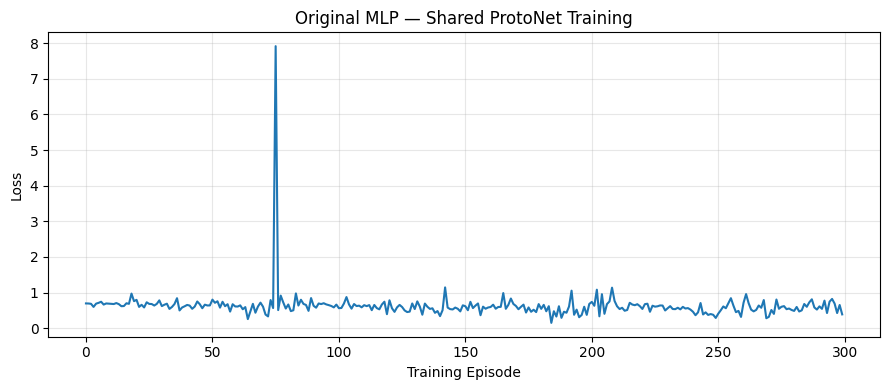


2. EMBEDDING SHAPE: (8, 32)
SUCCESS: Step 8.4D completed!


In [278]:

# ============================================================
# PHASE 8 — STEP 8.4D
# Train Original MLP with Shared Episodes
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Create a fresh model
mlp_shared = OriginalMLPEncoder(
    sequence_length=30,
    num_features=4,
    embedding_dim=32
).to(DEVICE)

# Train using the shared function
mlp_shared_result = train_shared_protonet(
    encoder=mlp_shared,
    X=X_train_speed,
    y=y_large,
    episodes=shared_train_episodes,
    learning_rate=0.001
)

# Save the trained model in memory
mlp_shared = mlp_shared_result["encoder"]

# Display training results
losses = mlp_shared_result["losses"]
accuracies = mlp_shared_result["accuracies"]

print("\n1. TRAINING RESULTS")
print("Final loss:", round(losses[-1], 4))
print(
    "Average accuracy (last 50 episodes):",
    round(np.mean(accuracies[-50:]), 2),
    "%"
)

# Plot training loss
plt.figure(figsize=(9, 4))
plt.plot(losses)
plt.xlabel("Training Episode")
plt.ylabel("Loss")
plt.title("Original MLP — Shared ProtoNet Training")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Verify model output
mlp_shared.eval()

with torch.no_grad():
    sample = torch.as_tensor(
        X_train_speed[:8],
        dtype=torch.float32,
        device=DEVICE
    )
    embeddings = mlp_shared(sample)

assert embeddings.shape == (8, 32)
assert torch.isfinite(embeddings).all()

print("\n2. EMBEDDING SHAPE:", tuple(embeddings.shape))
print("SUCCESS: Step 8.4D completed!")


In [279]:

# ============================================================
# PHASE 8 — STEP 8.4E
# Shared Validation Episodes and Evaluation Function
# ============================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import f1_score

# Generate fixed validation episodes ONCE
val_rng_shared = np.random.default_rng(2027)

shared_val_episodes = []

for _ in range(100):
    support_indices = []
    query_indices = []

    for label in [0, 1]:
        candidates = np.flatnonzero(y_val == label)

        selected = val_rng_shared.choice(
            candidates, size=10, replace=False
        )

        support_indices.extend(selected[:5])
        query_indices.extend(selected[5:])

    support_indices = np.asarray(support_indices)
    query_indices = np.asarray(query_indices)

    assert set(
        val_labeled_metadata.iloc[support_indices]["icao24"]
    ).isdisjoint(
        set(val_labeled_metadata.iloc[query_indices]["icao24"])
    )

    shared_val_episodes.append({
        "support_indices": support_indices,
        "query_indices": query_indices
    })


def evaluate_shared_protonet(encoder, X, y, episodes):
    encoder.eval()

    accuracies = []
    macro_f1_scores = []

    X_tensor = torch.as_tensor(
        X, dtype=torch.float32, device=DEVICE
    )

    with torch.no_grad():
        embeddings = encoder(X_tensor)

        for plan in episodes:
            s_idx = plan["support_indices"]
            q_idx = plan["query_indices"]

            prototypes = torch.stack([
                embeddings[s_idx][y[s_idx] == c].mean(dim=0)
                for c in [0, 1]
            ])

            distances = torch.cdist(
                embeddings[q_idx], prototypes
            )

            predictions = distances.argmin(
                dim=1
            ).cpu().numpy()

            actual = y[q_idx]

            accuracies.append(
                np.mean(predictions == actual)
            )

            macro_f1_scores.append(
                f1_score(
                    actual, predictions,
                    labels=[0, 1],
                    average="macro",
                    zero_division=0
                )
            )

    return {
        "Mean_Accuracy": np.mean(accuracies),
        "Accuracy_Std": np.std(accuracies),
        "Mean_Macro_F1": np.mean(macro_f1_scores)
    }


# Test shared validation function
mlp_shared_metrics = evaluate_shared_protonet(
    encoder=mlp_shared,
    X=X_val_speed,
    y=y_val,
    episodes=shared_val_episodes
)

print("ORIGINAL MLP — SHARED VALIDATION")
display(
    pd.DataFrame([mlp_shared_metrics]).round(4)
)

print("\nShared validation episodes:", len(shared_val_episodes))
print("Step 8.4E completed!")


ORIGINAL MLP — SHARED VALIDATION


,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,0.712,0.1366,0.7023



Shared validation episodes: 100
Step 8.4E completed!


In [280]:

# ============================================================
# PHASE 8 — STEP 8.5A
# Build Residual MLP Encoder
# ============================================================

import torch
import torch.nn as nn

class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.activation = nn.ReLU()

    def forward(self, x):
        # Shortcut connection
        return self.activation(x + self.layers(x))


class ResidualMLPEncoder(nn.Module):
    def __init__(
        self,
        sequence_length=30,
        num_features=4,
        hidden_dim=128,
        embedding_dim=32
    ):
        super().__init__()

        input_dim = sequence_length * num_features

        self.input_layer = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU()
        )

        self.residual_layers = nn.Sequential(
            ResidualBlock(hidden_dim),
            ResidualBlock(hidden_dim)
        )

        self.output_layer = nn.Linear(
            hidden_dim, embedding_dim
        )

    def forward(self, x):
        x = self.input_layer(x)
        x = self.residual_layers(x)
        return self.output_layer(x)


# Initialize the new encoder
torch.manual_seed(42)

residual_mlp = ResidualMLPEncoder(
    sequence_length=30,
    num_features=4,
    hidden_dim=128,
    embedding_dim=32
).to(DEVICE)

# Test forward pass
sample = torch.as_tensor(
    X_train_speed[:8],
    dtype=torch.float32,
    device=DEVICE
)

residual_mlp.eval()

with torch.no_grad():
    embeddings = residual_mlp(sample)

parameter_count = sum(
    p.numel() for p in residual_mlp.parameters()
)

print("1. INPUT SHAPE:", tuple(sample.shape))
print("2. EMBEDDING SHAPE:", tuple(embeddings.shape))
print("3. MODEL PARAMETERS:", parameter_count)
print("4. ALL FINITE:", torch.isfinite(embeddings).all().item())

assert embeddings.shape == (8, 32)
assert torch.isfinite(embeddings).all()

print("\nSUCCESS: Step 8.5A completed!")


1. INPUT SHAPE: (8, 30, 4)
2. EMBEDDING SHAPE: (8, 32)
3. MODEL PARAMETERS: 85664
4. ALL FINITE: True

SUCCESS: Step 8.5A completed!


Episode 50/300 | Loss: 0.5407 | Accuracy: 80.0%
Episode 100/300 | Loss: 0.6198 | Accuracy: 70.0%
Episode 150/300 | Loss: 0.7560 | Accuracy: 60.0%
Episode 200/300 | Loss: 0.6259 | Accuracy: 90.0%
Episode 250/300 | Loss: 0.3170 | Accuracy: 100.0%
Episode 300/300 | Loss: 0.3898 | Accuracy: 90.0%

1. TRAINING RESULTS
Final loss: 0.3898
Average accuracy (last 50 episodes): 73.6 %


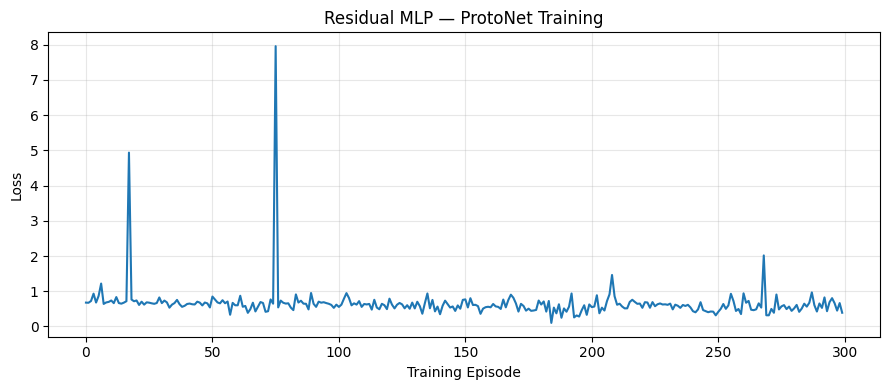


SUCCESS: Step 8.5B completed!


In [281]:

# ============================================================
# PHASE 8 — STEP 8.5B
# Train Residual MLP with Shared ProtoNet Episodes
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Create a fresh Residual MLP
residual_mlp = ResidualMLPEncoder(
    sequence_length=30,
    num_features=4,
    hidden_dim=128,
    embedding_dim=32
).to(DEVICE)

# Train using the shared training function
residual_result = train_shared_protonet(
    encoder=residual_mlp,
    X=X_train_speed,
    y=y_large,
    episodes=shared_train_episodes,
    learning_rate=0.001
)

residual_mlp = residual_result["encoder"]

# Training results
residual_losses = residual_result["losses"]
residual_accuracies = residual_result["accuracies"]

print("\n1. TRAINING RESULTS")
print("Final loss:", round(residual_losses[-1], 4))
print(
    "Average accuracy (last 50 episodes):",
    round(np.mean(residual_accuracies[-50:]), 2),
    "%"
)

# Plot training loss
plt.figure(figsize=(9, 4))
plt.plot(residual_losses)
plt.xlabel("Training Episode")
plt.ylabel("Loss")
plt.title("Residual MLP — ProtoNet Training")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSUCCESS: Step 8.5B completed!")


In [282]:

# ============================================================
# PHASE 8 — STEP 8.5C
# Evaluate Residual MLP on Shared Validation Episodes
# ============================================================

# Evaluate using the shared validation function
residual_metrics = evaluate_shared_protonet(
    encoder=residual_mlp,
    X=X_val_speed,
    y=y_val,
    episodes=shared_val_episodes
)

print("1. RESIDUAL MLP VALIDATION RESULTS")
display(
    pd.DataFrame([residual_metrics]).round(4)
)

print("\n2. MODEL COMPARISON")

comparison = pd.DataFrame([
    {
        "Encoder": "Original MLP",
        **mlp_shared_metrics
    },
    {
        "Encoder": "Residual MLP",
        **residual_metrics
    }
])

display(comparison.round(4))

print("\nStep 8.5C completed!")


1. RESIDUAL MLP VALIDATION RESULTS


,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,0.703,0.1424,0.6895



2. MODEL COMPARISON


,Encoder,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,Original MLP,0.712,0.1366,0.7023
1,Residual MLP,0.703,0.1424,0.6895



Step 8.5C completed!


In [283]:

# ============================================================
# PHASE 8 — STEP 8.6A
# Build Tabular ResNet Encoder
# ============================================================

import torch
import torch.nn as nn

class TabularResNetBlock(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )

        self.norm = nn.LayerNorm(hidden_dim)
        self.activation = nn.ReLU()

    def forward(self, x):
        return self.activation(
            self.norm(x + self.layers(x))
        )


class TabularResNetEncoder(nn.Module):
    def __init__(
        self,
        sequence_length=30,
        num_features=4,
        hidden_dim=128,
        embedding_dim=32
    ):
        super().__init__()

        input_dim = sequence_length * num_features

        self.input_layer = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU()
        )

        self.blocks = nn.Sequential(
            TabularResNetBlock(hidden_dim),
            TabularResNetBlock(hidden_dim)
        )

        self.output_layer = nn.Linear(
            hidden_dim,
            embedding_dim
        )

    def forward(self, x):
        x = self.input_layer(x)
        x = self.blocks(x)
        return self.output_layer(x)


# Create fresh model
torch.manual_seed(42)

tabular_resnet = TabularResNetEncoder(
    sequence_length=30,
    num_features=4,
    hidden_dim=128,
    embedding_dim=32
).to(DEVICE)

# Test forward pass
sample = torch.as_tensor(
    X_train_speed[:8],
    dtype=torch.float32,
    device=DEVICE
)

tabular_resnet.eval()

with torch.no_grad():
    embeddings = tabular_resnet(sample)

parameter_count = sum(
    p.numel() for p in tabular_resnet.parameters()
)

print("1. INPUT SHAPE:", tuple(sample.shape))
print("2. EMBEDDING SHAPE:", tuple(embeddings.shape))
print("3. MODEL PARAMETERS:", parameter_count)
print("4. ALL FINITE:", torch.isfinite(embeddings).all().item())

assert embeddings.shape == (8, 32)
assert torch.isfinite(embeddings).all()

print("\nSUCCESS: Step 8.6A completed!")


1. INPUT SHAPE: (8, 30, 4)
2. EMBEDDING SHAPE: (8, 32)
3. MODEL PARAMETERS: 86944
4. ALL FINITE: True

SUCCESS: Step 8.6A completed!


Episode 50/300 | Loss: 0.5641 | Accuracy: 80.0%
Episode 100/300 | Loss: 0.6873 | Accuracy: 70.0%
Episode 150/300 | Loss: 0.6037 | Accuracy: 70.0%
Episode 200/300 | Loss: 0.6217 | Accuracy: 60.0%
Episode 250/300 | Loss: 0.2805 | Accuracy: 90.0%
Episode 300/300 | Loss: 0.3764 | Accuracy: 90.0%

1. TRAINING RESULTS
Final loss: 0.3764
Average accuracy (last 50 episodes): 74.2 %


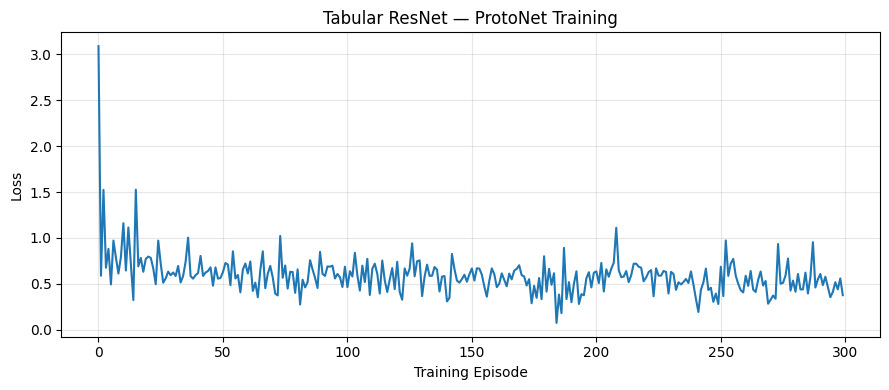


SUCCESS: Step 8.6B completed!


In [284]:

# ============================================================
# PHASE 8 — STEP 8.6B
# Train Tabular ResNet with Shared ProtoNet Episodes
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# Create a fresh Tabular ResNet
tabular_resnet = TabularResNetEncoder(
    sequence_length=30,
    num_features=4,
    hidden_dim=128,
    embedding_dim=32
).to(DEVICE)

# Train using the shared function
tabular_result = train_shared_protonet(
    encoder=tabular_resnet,
    X=X_train_speed,
    y=y_large,
    episodes=shared_train_episodes,
    learning_rate=0.001
)

tabular_resnet = tabular_result["encoder"]

# Training summary
tabular_losses = tabular_result["losses"]
tabular_accuracies = tabular_result["accuracies"]

print("\n1. TRAINING RESULTS")
print("Final loss:", round(tabular_losses[-1], 4))
print(
    "Average accuracy (last 50 episodes):",
    round(np.mean(tabular_accuracies[-50:]), 2),
    "%"
)

plt.figure(figsize=(9, 4))
plt.plot(tabular_losses)
plt.xlabel("Training Episode")
plt.ylabel("Loss")
plt.title("Tabular ResNet — ProtoNet Training")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSUCCESS: Step 8.6B completed!")


In [285]:

# ============================================================
# PHASE 8 — STEP 8.6C
# Validate Tabular ResNet
# ============================================================

import pandas as pd

# Evaluate on shared validation episodes
tabular_metrics = evaluate_shared_protonet(
    encoder=tabular_resnet,
    X=X_val_speed,
    y=y_val,
    episodes=shared_val_episodes
)

print("1. TABULAR RESNET VALIDATION")
display(pd.DataFrame([tabular_metrics]).round(4))

# Compare all three encoders
comparison_3 = pd.DataFrame([
    {"Encoder": "Original MLP", **mlp_shared_metrics},
    {"Encoder": "Residual MLP", **residual_metrics},
    {"Encoder": "Tabular ResNet", **tabular_metrics}
])

print("\n2. THREE-ENCODER COMPARISON")
display(
    comparison_3.sort_values(
        "Mean_Accuracy",
        ascending=False
    ).round(4)
)

print("\nSUCCESS: Step 8.6C completed!")


1. TABULAR RESNET VALIDATION


,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,0.689,0.1435,0.6732



2. THREE-ENCODER COMPARISON


,Encoder,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,Original MLP,0.712,0.1366,0.7023
1,Residual MLP,0.703,0.1424,0.6895
2,Tabular ResNet,0.689,0.1435,0.6732



SUCCESS: Step 8.6C completed!


In [286]:

# ============================================================
# PHASE 8 — STEP 8.7A
# Build Feature-Gated MLP Encoder
# ============================================================

import torch
import torch.nn as nn

class FeatureGatedMLPEncoder(nn.Module):
    def __init__(
        self,
        sequence_length=30,
        num_features=4,
        hidden_dim=128,
        embedding_dim=32
    ):
        super().__init__()

        input_dim = sequence_length * num_features

        # Learn a weight between 0 and 1 for each input
        self.gate = nn.Sequential(
            nn.Linear(input_dim, input_dim),
            nn.Sigmoid()
        )

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )

    def forward(self, x):
        x = x.flatten(start_dim=1)

        # Apply learned feature gates
        gate_values = self.gate(x)
        x = x * gate_values

        return self.encoder(x)


# Initialize model
torch.manual_seed(42)

gated_mlp = FeatureGatedMLPEncoder(
    sequence_length=30,
    num_features=4,
    hidden_dim=128,
    embedding_dim=32
).to(DEVICE)

# Test forward pass
sample = torch.as_tensor(
    X_train_speed[:8],
    dtype=torch.float32,
    device=DEVICE
)

gated_mlp.eval()

with torch.no_grad():
    embeddings = gated_mlp(sample)

parameter_count = sum(
    p.numel() for p in gated_mlp.parameters()
)

print("1. INPUT SHAPE:", tuple(sample.shape))
print("2. EMBEDDING SHAPE:", tuple(embeddings.shape))
print("3. MODEL PARAMETERS:", parameter_count)
print("4. ALL FINITE:", torch.isfinite(embeddings).all().item())

assert embeddings.shape == (8, 32)
assert torch.isfinite(embeddings).all()

print("\nSUCCESS: Step 8.7A completed!")


1. INPUT SHAPE: (8, 30, 4)
2. EMBEDDING SHAPE: (8, 32)
3. MODEL PARAMETERS: 82520
4. ALL FINITE: True

SUCCESS: Step 8.7A completed!


Episode 50/300 | Loss: 0.5926 | Accuracy: 70.0%
Episode 100/300 | Loss: 0.5792 | Accuracy: 80.0%
Episode 150/300 | Loss: 0.6432 | Accuracy: 60.0%
Episode 200/300 | Loss: 0.5656 | Accuracy: 60.0%
Episode 250/300 | Loss: 0.3234 | Accuracy: 100.0%
Episode 300/300 | Loss: 0.4066 | Accuracy: 70.0%

1. TRAINING RESULTS
Final loss: 0.4066
Average accuracy (last 50 episodes): 75.4 %


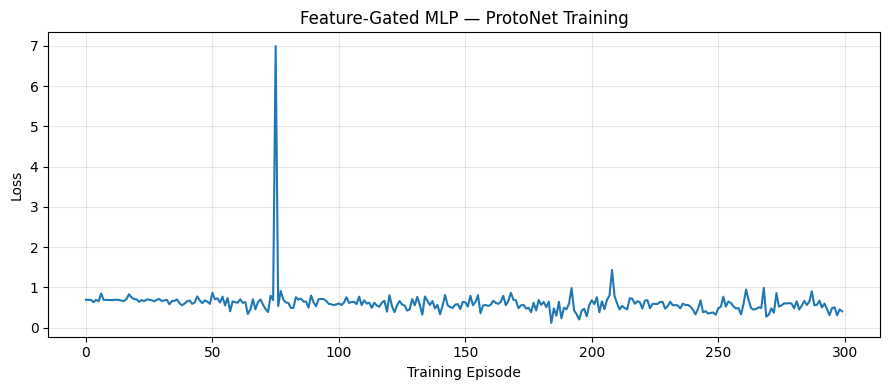


SUCCESS: Step 8.7B completed!


In [287]:

# ============================================================
# PHASE 8 — STEP 8.7B
# Train Feature-Gated MLP with Shared Episodes
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Create a fresh Feature-Gated MLP
gated_mlp = FeatureGatedMLPEncoder(
    sequence_length=30,
    num_features=4,
    hidden_dim=128,
    embedding_dim=32
).to(DEVICE)

# Train using the shared ProtoNet function
gated_result = train_shared_protonet(
    encoder=gated_mlp,
    X=X_train_speed,
    y=y_large,
    episodes=shared_train_episodes,
    learning_rate=0.001
)

gated_mlp = gated_result["encoder"]

# Training summary
gated_losses = gated_result["losses"]
gated_accuracies = gated_result["accuracies"]

print("\n1. TRAINING RESULTS")
print("Final loss:", round(gated_losses[-1], 4))
print(
    "Average accuracy (last 50 episodes):",
    round(np.mean(gated_accuracies[-50:]), 2),
    "%"
)

# Plot training loss
plt.figure(figsize=(9, 4))
plt.plot(gated_losses)
plt.xlabel("Training Episode")
plt.ylabel("Loss")
plt.title("Feature-Gated MLP — ProtoNet Training")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSUCCESS: Step 8.7B completed!")


In [288]:

# ============================================================
# PHASE 8 — STEP 8.7C
# Validate Feature-Gated MLP
# ============================================================

import pandas as pd

# Evaluate using shared validation episodes
gated_metrics = evaluate_shared_protonet(
    encoder=gated_mlp,
    X=X_val_speed,
    y=y_val,
    episodes=shared_val_episodes
)

print("1. FEATURE-GATED MLP VALIDATION")
display(
    pd.DataFrame([gated_metrics]).round(4)
)

# Compare all four encoders
comparison_4 = pd.DataFrame([
    {"Encoder": "Original MLP", **mlp_shared_metrics},
    {"Encoder": "Residual MLP", **residual_metrics},
    {"Encoder": "Tabular ResNet", **tabular_metrics},
    {"Encoder": "Feature-Gated MLP", **gated_metrics}
])

print("\n2. FOUR-ENCODER COMPARISON")
display(
    comparison_4.sort_values(
        "Mean_Accuracy",
        ascending=False
    ).round(4)
)

print("\nSUCCESS: Step 8.7C completed!")


1. FEATURE-GATED MLP VALIDATION


,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,0.674,0.1481,0.66



2. FOUR-ENCODER COMPARISON


,Encoder,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,Original MLP,0.712,0.1366,0.7023
1,Residual MLP,0.703,0.1424,0.6895
2,Tabular ResNet,0.689,0.1435,0.6732
3,Feature-Gated MLP,0.674,0.1481,0.6600



SUCCESS: Step 8.7C completed!


In [289]:

# ============================================================
# PHASE 8 — STEP 8.8A
# Build FT-Transformer-Style Encoder
# ============================================================

import torch
import torch.nn as nn

class FTTransformerEncoder(nn.Module):
    def __init__(
        self,
        sequence_length=30,
        num_features=4,
        d_model=64,
        n_heads=4,
        num_layers=2,
        embedding_dim=32
    ):
        super().__init__()

        self.num_features = num_features

        # Convert each feature's temporal history into a token
        self.feature_tokenizer = nn.Linear(
            sequence_length, d_model
        )

        # Give each feature a different learned identity
        self.feature_embeddings = nn.Parameter(
            torch.zeros(1, num_features, d_model)
        )

        nn.init.normal_(
            self.feature_embeddings,
            mean=0.0,
            std=0.02
        )

        transformer_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=128,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            transformer_layer,
            num_layers=num_layers
        )

        self.output_layer = nn.Linear(
            d_model, embedding_dim
        )

    def forward(self, x):
        # Input: (batch, 30, 4)
        # Tokens: (batch, 4, 30)
        x = x.transpose(1, 2)

        x = self.feature_tokenizer(x)
        x = x + self.feature_embeddings

        x = self.transformer(x)

        # Average feature-token representations
        x = x.mean(dim=1)

        return self.output_layer(x)


# Initialize model
torch.manual_seed(42)

ft_transformer = FTTransformerEncoder(
    sequence_length=30,
    num_features=4,
    d_model=64,
    n_heads=4,
    num_layers=2,
    embedding_dim=32
).to(DEVICE)

# Test forward pass
sample = torch.as_tensor(
    X_train_speed[:8],
    dtype=torch.float32,
    device=DEVICE
)

ft_transformer.eval()

with torch.no_grad():
    embeddings = ft_transformer(sample)

parameter_count = sum(
    p.numel() for p in ft_transformer.parameters()
)

print("1. INPUT SHAPE:", tuple(sample.shape))
print("2. EMBEDDING SHAPE:", tuple(embeddings.shape))
print("3. MODEL PARAMETERS:", parameter_count)
print("4. ALL FINITE:", torch.isfinite(embeddings).all().item())

assert embeddings.shape == (8, 32)
assert torch.isfinite(embeddings).all()

print("\nSUCCESS: Step 8.8A completed!")


1. INPUT SHAPE: (8, 30, 4)
2. EMBEDDING SHAPE: (8, 32)
3. MODEL PARAMETERS: 71264
4. ALL FINITE: True

SUCCESS: Step 8.8A completed!


/tmp/ipykernel_1849/3804455994.py:49: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


/tmp/ipykernel_1849/3804455994.py:49: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Episode 50/300 | Loss: 0.6121 | Accuracy: 70.0%
Episode 100/300 | Loss: 0.8616 | Accuracy: 50.0%
Episode 150/300 | Loss: 0.5818 | Accuracy: 70.0%
Episode 200/300 | Loss: 0.4949 | Accuracy: 70.0%
Episode 250/300 | Loss: 0.4376 | Accuracy: 90.0%
Episode 300/300 | Loss: 0.4032 | Accuracy: 80.0%

1. TRAINING RESULTS
Final loss: 0.4032
Average accuracy (last 50 episodes): 71.2 %


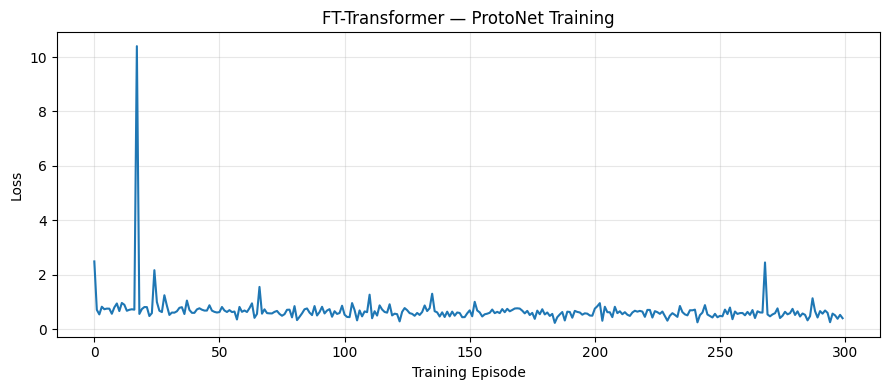


SUCCESS: Step 8.8B completed!


In [290]:

# ============================================================
# PHASE 8 — STEP 8.8B
# Train FT-Transformer with Shared ProtoNet Episodes
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# Create a fresh FT-Transformer model
ft_transformer = FTTransformerEncoder(
    sequence_length=30,
    num_features=4,
    d_model=64,
    n_heads=4,
    num_layers=2,
    embedding_dim=32
).to(DEVICE)

# Train using the shared ProtoNet function
ft_result = train_shared_protonet(
    encoder=ft_transformer,
    X=X_train_speed,
    y=y_large,
    episodes=shared_train_episodes,
    learning_rate=0.001
)

ft_transformer = ft_result["encoder"]

# Training summary
ft_losses = ft_result["losses"]
ft_accuracies = ft_result["accuracies"]

print("\n1. TRAINING RESULTS")
print("Final loss:", round(ft_losses[-1], 4))
print(
    "Average accuracy (last 50 episodes):",
    round(np.mean(ft_accuracies[-50:]), 2),
    "%"
)

plt.figure(figsize=(9, 4))
plt.plot(ft_losses)
plt.xlabel("Training Episode")
plt.ylabel("Loss")
plt.title("FT-Transformer — ProtoNet Training")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSUCCESS: Step 8.8B completed!")


In [291]:

# ============================================================
# PHASE 8 — STEP 8.8C
# Validate FT-Transformer Using Shared Episodes
# ============================================================

import pandas as pd

# Evaluate FT-Transformer
ft_metrics = evaluate_shared_protonet(
    encoder=ft_transformer,
    X=X_val_speed,
    y=y_val,
    episodes=shared_val_episodes
)

print("1. FT-TRANSFORMER VALIDATION")
display(pd.DataFrame([ft_metrics]).round(4))

# Compare all five encoders
comparison_5 = pd.DataFrame([
    {"Encoder": "Original MLP", **mlp_shared_metrics},
    {"Encoder": "Residual MLP", **residual_metrics},
    {"Encoder": "Tabular ResNet", **tabular_metrics},
    {"Encoder": "Feature-Gated MLP", **gated_metrics},
    {"Encoder": "FT-Transformer", **ft_metrics}
])

print("\n2. FIVE-ENCODER COMPARISON")
display(
    comparison_5.sort_values(
        "Mean_Accuracy",
        ascending=False
    ).round(4)
)

print("\nSUCCESS: Step 8.8C completed!")


1. FT-TRANSFORMER VALIDATION


,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,0.688,0.1532,0.6703



2. FIVE-ENCODER COMPARISON


,Encoder,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,Original MLP,0.712,0.1366,0.7023
1,Residual MLP,0.703,0.1424,0.6895
2,Tabular ResNet,0.689,0.1435,0.6732
4,FT-Transformer,0.688,0.1532,0.6703
3,Feature-Gated MLP,0.674,0.1481,0.6600



SUCCESS: Step 8.8C completed!


In [292]:

# ============================================================
# PHASE 8 — STEP 8.9A
# Build TabNet-Style Encoder
# ============================================================

"""
This is a TabNet-inspired model, not the original TabNet architecture.
"""

import torch
import torch.nn as nn

class TabNetStyleEncoder(nn.Module):
    def __init__(
        self,
        sequence_length=30,
        num_features=4,
        hidden_dim=128,
        embedding_dim=32
    ):
        super().__init__()

        input_dim = sequence_length * num_features

        self.flatten = nn.Flatten(start_dim=1)

        # First attention mask
        self.attention1 = nn.Sequential(
            nn.Linear(input_dim, input_dim),
            nn.Sigmoid()
        )

        self.transform1 = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU()
        )

        # Second attention mask
        self.attention2 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Sigmoid()
        )

        self.transform2 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )

        self.output = nn.Linear(
            hidden_dim, embedding_dim
        )

    def forward(self, x):
        x = self.flatten(x)

        mask1 = self.attention1(x)
        x = self.transform1(x * mask1)

        mask2 = self.attention2(x)
        x = self.transform2(x * mask2)

        return self.output(x)


# Initialize model
torch.manual_seed(42)

tabnet_style = TabNetStyleEncoder(
    sequence_length=30,
    num_features=4,
    hidden_dim=128,
    embedding_dim=32
).to(DEVICE)

# Test forward pass
sample = torch.as_tensor(
    X_train_speed[:8],
    dtype=torch.float32,
    device=DEVICE
)

tabnet_style.eval()

with torch.no_grad():
    embeddings = tabnet_style(sample)

parameter_count = sum(
    p.numel() for p in tabnet_style.parameters()
)

print("1. INPUT SHAPE:", tuple(sample.shape))
print("2. EMBEDDING SHAPE:", tuple(embeddings.shape))
print("3. MODEL PARAMETERS:", parameter_count)
print("4. ALL FINITE:", torch.isfinite(embeddings).all().item())

assert embeddings.shape == (8, 32)
assert torch.isfinite(embeddings).all()

print("\nSUCCESS: Step 8.9A completed!")


1. INPUT SHAPE: (8, 30, 4)
2. EMBEDDING SHAPE: (8, 32)
3. MODEL PARAMETERS: 67160
4. ALL FINITE: True

SUCCESS: Step 8.9A completed!


Episode 50/300 | Loss: 0.6273 | Accuracy: 70.0%
Episode 100/300 | Loss: 0.6049 | Accuracy: 80.0%
Episode 150/300 | Loss: 0.6495 | Accuracy: 60.0%
Episode 200/300 | Loss: 0.5568 | Accuracy: 60.0%
Episode 250/300 | Loss: 0.2784 | Accuracy: 100.0%
Episode 300/300 | Loss: 0.3809 | Accuracy: 80.0%

1. TRAINING RESULTS
Final loss: 0.3809
Average accuracy (last 50 episodes): 77.4 %


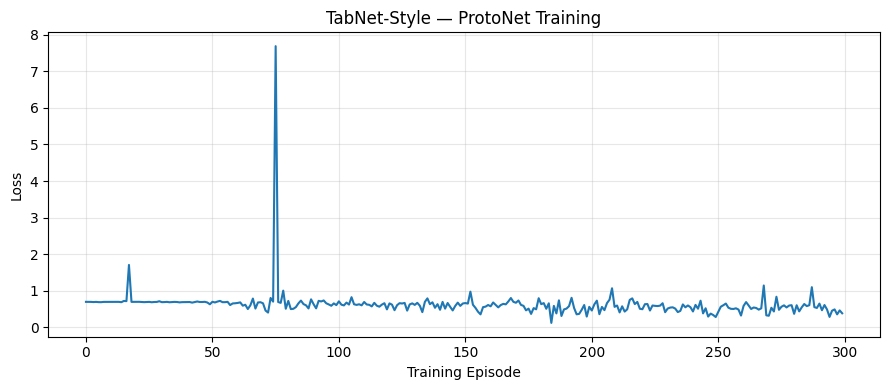


SUCCESS: Step 8.9B completed!


In [293]:

# ============================================================
# PHASE 8 — STEP 8.9B
# Train TabNet-Style ProtoNet
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# Create a fresh TabNet-style encoder
tabnet_style = TabNetStyleEncoder(
    sequence_length=30,
    num_features=4,
    hidden_dim=128,
    embedding_dim=32
).to(DEVICE)

# Train using the shared 300 episodes
tabnet_result = train_shared_protonet(
    encoder=tabnet_style,
    X=X_train_speed,
    y=y_large,
    episodes=shared_train_episodes,
    learning_rate=0.001
)

tabnet_style = tabnet_result["encoder"]

# Training summary
tabnet_losses = tabnet_result["losses"]
tabnet_accuracies = tabnet_result["accuracies"]

print("\n1. TRAINING RESULTS")
print("Final loss:", round(tabnet_losses[-1], 4))
print(
    "Average accuracy (last 50 episodes):",
    round(np.mean(tabnet_accuracies[-50:]), 2),
    "%"
)

# Training-loss graph
plt.figure(figsize=(9, 4))
plt.plot(tabnet_losses)
plt.xlabel("Training Episode")
plt.ylabel("Loss")
plt.title("TabNet-Style — ProtoNet Training")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSUCCESS: Step 8.9B completed!")


In [294]:

# ============================================================
# PHASE 8 — STEP 8.9C
# Validate TabNet-Style ProtoNet
# ============================================================

import pandas as pd

# Evaluate using identical validation episodes
tabnet_metrics = evaluate_shared_protonet(
    encoder=tabnet_style,
    X=X_val_speed,
    y=y_val,
    episodes=shared_val_episodes
)

print("1. TABNET-STYLE VALIDATION")
display(pd.DataFrame([tabnet_metrics]).round(4))

# Compare all six encoders
comparison_6 = pd.DataFrame([
    {"Encoder": "Original MLP", **mlp_shared_metrics},
    {"Encoder": "Residual MLP", **residual_metrics},
    {"Encoder": "Tabular ResNet", **tabular_metrics},
    {"Encoder": "Feature-Gated MLP", **gated_metrics},
    {"Encoder": "FT-Transformer", **ft_metrics},
    {"Encoder": "TabNet-style", **tabnet_metrics}
])

print("\n2. SIX-ENCODER COMPARISON")
display(
    comparison_6.sort_values(
        "Mean_Accuracy",
        ascending=False
    ).round(4)
)

print("\nSUCCESS: Step 8.9C completed!")


1. TABNET-STYLE VALIDATION


,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,0.679,0.1366,0.6652



2. SIX-ENCODER COMPARISON


,Encoder,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,Original MLP,0.712,0.1366,0.7023
1,Residual MLP,0.703,0.1424,0.6895
2,Tabular ResNet,0.689,0.1435,0.6732
4,FT-Transformer,0.688,0.1532,0.6703
5,TabNet-style,0.679,0.1366,0.6652
3,Feature-Gated MLP,0.674,0.1481,0.6600



SUCCESS: Step 8.9C completed!


In [295]:

# ============================================================
# PHASE 8 — STEP 8.10A
# Build CNN1D Encoder for Temporal ADS-B Windows
# ============================================================

import torch
import torch.nn as nn

class CNN1DEncoder(nn.Module):
    def __init__(
        self,
        sequence_length=30,
        num_features=4,
        embedding_dim=32
    ):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(
                in_channels=num_features,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.output_layer = nn.Linear(
            64, embedding_dim
        )

    def forward(self, x):
        # Input: (batch, 30, 4)
        # Conv1d expects: (batch, features, time)
        x = x.transpose(1, 2)

        x = self.features(x)
        x = x.squeeze(-1)

        return self.output_layer(x)


torch.manual_seed(42)

cnn1d = CNN1DEncoder(
    sequence_length=30,
    num_features=4,
    embedding_dim=32
).to(DEVICE)

# Test forward pass
sample = torch.as_tensor(
    X_train_speed[:8],
    dtype=torch.float32,
    device=DEVICE
)

cnn1d.eval()

with torch.no_grad():
    embeddings = cnn1d(sample)

parameter_count = sum(
    p.numel() for p in cnn1d.parameters()
)

print("1. INPUT SHAPE:", tuple(sample.shape))
print("2. EMBEDDING SHAPE:", tuple(embeddings.shape))
print("3. MODEL PARAMETERS:", parameter_count)
print("4. ALL FINITE:", torch.isfinite(embeddings).all().item())

assert embeddings.shape == (8, 32)
assert torch.isfinite(embeddings).all()

print("\nSUCCESS: Step 8.10A completed!")


1. INPUT SHAPE: (8, 30, 4)
2. EMBEDDING SHAPE: (8, 32)
3. MODEL PARAMETERS: 8704
4. ALL FINITE: True

SUCCESS: Step 8.10A completed!


Episode 50/300 | Loss: 0.6873 | Accuracy: 60.0%
Episode 100/300 | Loss: 0.6745 | Accuracy: 40.0%
Episode 150/300 | Loss: 0.6944 | Accuracy: 40.0%
Episode 200/300 | Loss: 0.8123 | Accuracy: 60.0%
Episode 250/300 | Loss: 0.5816 | Accuracy: 80.0%
Episode 300/300 | Loss: 0.6550 | Accuracy: 90.0%

1. TRAINING RESULTS
Final loss: 0.655
Average accuracy (last 50 episodes): 62.0 %


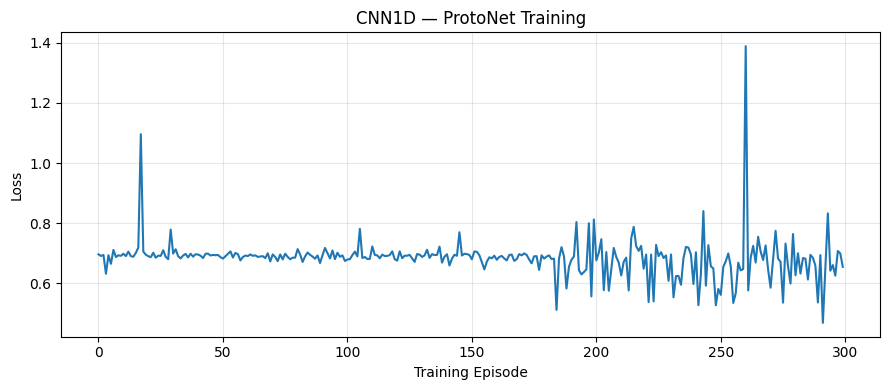


SUCCESS: Step 8.10B completed!


In [296]:

# ============================================================
# PHASE 8 — STEP 8.10B
# Train CNN1D with Shared ProtoNet Episodes
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# Create a fresh CNN1D encoder
cnn1d = CNN1DEncoder(
    sequence_length=30,
    num_features=4,
    embedding_dim=32
).to(DEVICE)

# Train with the same 300 episodes
cnn_result = train_shared_protonet(
    encoder=cnn1d,
    X=X_train_speed,
    y=y_large,
    episodes=shared_train_episodes,
    learning_rate=0.001
)

cnn1d = cnn_result["encoder"]

# Training results
cnn_losses = cnn_result["losses"]
cnn_accuracies = cnn_result["accuracies"]

print("\n1. TRAINING RESULTS")
print("Final loss:", round(cnn_losses[-1], 4))
print(
    "Average accuracy (last 50 episodes):",
    round(np.mean(cnn_accuracies[-50:]), 2),
    "%"
)

# Plot training loss
plt.figure(figsize=(9, 4))
plt.plot(cnn_losses)
plt.xlabel("Training Episode")
plt.ylabel("Loss")
plt.title("CNN1D — ProtoNet Training")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSUCCESS: Step 8.10B completed!")


In [297]:

# ============================================================
# PHASE 8 — STEP 8.10C
# Final Seven-Encoder Known-Attack Validation Comparison
# ============================================================

import pandas as pd

# Evaluate CNN1D
cnn_metrics = evaluate_shared_protonet(
    encoder=cnn1d,
    X=X_val_speed,
    y=y_val,
    episodes=shared_val_episodes
)

print("1. CNN1D VALIDATION RESULTS")
display(pd.DataFrame([cnn_metrics]).round(4))

# Compare all seven encoders
comparison_7 = pd.DataFrame([
    {"Encoder": "Original MLP", **mlp_shared_metrics},
    {"Encoder": "Residual MLP", **residual_metrics},
    {"Encoder": "Tabular ResNet", **tabular_metrics},
    {"Encoder": "Feature-Gated MLP", **gated_metrics},
    {"Encoder": "FT-Transformer", **ft_metrics},
    {"Encoder": "TabNet-style", **tabnet_metrics},
    {"Encoder": "CNN1D", **cnn_metrics}
])

comparison_7 = comparison_7.sort_values(
    "Mean_Accuracy",
    ascending=False
).reset_index(drop=True)

print("\n2. SEVEN-ENCODER VALIDATION COMPARISON")
display(comparison_7.round(4))

print("\n3. BEST ENCODER ON KNOWN ATTACKS")
print(comparison_7.iloc[0]["Encoder"])
print(
    "Validation accuracy:",
    round(comparison_7.iloc[0]["Mean_Accuracy"] * 100, 2),
    "%"
)

print("\nSUCCESS: Step 8.10C completed!")


1. CNN1D VALIDATION RESULTS


,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,0.626,0.1598,0.6099



2. SEVEN-ENCODER VALIDATION COMPARISON


,Encoder,Mean_Accuracy,Accuracy_Std,Mean_Macro_F1
0,Original MLP,0.712,0.1366,0.7023
1,Residual MLP,0.703,0.1424,0.6895
2,Tabular ResNet,0.689,0.1435,0.6732
3,FT-Transformer,0.688,0.1532,0.6703
4,TabNet-style,0.679,0.1366,0.6652
5,Feature-Gated MLP,0.674,0.1481,0.6600
6,CNN1D,0.626,0.1598,0.6099



3. BEST ENCODER ON KNOWN ATTACKS
Original MLP
Validation accuracy: 71.2 %

SUCCESS: Step 8.10C completed!


In [298]:

# ============================================================
# PHASE 8 — STEP 8.11A
# Shared Novel-Attack Few-Shot Evaluation Episodes
# ============================================================

import numpy as np
import pandas as pd

NOVEL_EVAL_SEED = 31415
NOVEL_REPEATS = 100
NOVEL_SHOTS = [1, 5, 10]

rng_shared_novel = np.random.default_rng(NOVEL_EVAL_SEED)

shared_novel_episodes = {
    shot: [] for shot in NOVEL_SHOTS
}

aircraft = novel_metadata_df["icao24"].to_numpy()

assert len(np.unique(aircraft)) == len(aircraft)
assert set(np.unique(y_novel)) == {0, 3}

for shot in NOVEL_SHOTS:

    for repeat in range(NOVEL_REPEATS):

        support_indices = []

        for label in [0, 3]:

            candidates = np.flatnonzero(
                y_novel == label
            )

            selected = rng_shared_novel.choice(
                candidates,
                size=shot,
                replace=False
            )

            support_indices.extend(selected)

        support_indices = np.asarray(
            support_indices,
            dtype=np.int64
        )

        query_mask = np.ones(
            len(y_novel),
            dtype=bool
        )

        query_mask[support_indices] = False

        query_indices = np.flatnonzero(query_mask)

        # Ensure distinct aircraft in support and query
        assert set(
            aircraft[support_indices]
        ).isdisjoint(
            set(aircraft[query_indices])
        )

        shared_novel_episodes[shot].append({
            "support_indices": support_indices,
            "query_indices": query_indices
        })


print("1. SHARED FEW-SHOT EPISODE SUMMARY")

for shot in NOVEL_SHOTS:

    episodes = shared_novel_episodes[shot]

    first = episodes[0]

    print(
        f"{shot}-shot: "
        f"{len(episodes)} episodes | "
        f"Support={len(first['support_indices'])} | "
        f"Query={len(first['query_indices'])}"
    )

print("\n2. DATASET CHECKS")
print("Novel labels:", sorted(np.unique(y_novel)))
print("Unique aircraft:", len(np.unique(aircraft)))

print("\nSUCCESS: Step 8.11A completed!")


1. SHARED FEW-SHOT EPISODE SUMMARY
1-shot: 100 episodes | Support=2 | Query=98
5-shot: 100 episodes | Support=10 | Query=90
10-shot: 100 episodes | Support=20 | Query=80

2. DATASET CHECKS
Novel labels: [np.int64(0), np.int64(3)]
Unique aircraft: 100

SUCCESS: Step 8.11A completed!


In [299]:

# ============================================================
# PHASE 8 — STEP 8.11B
# Seven-Encoder Novel-Attack Few-Shot Evaluation
# ============================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# All seven trained encoders
ENCODERS = {
    "Original MLP": mlp_shared,
    "Residual MLP": residual_mlp,
    "Tabular ResNet": tabular_resnet,
    "Feature-Gated MLP": gated_mlp,
    "FT-Transformer": ft_transformer,
    "TabNet-style": tabnet_style,
    "CNN1D": cnn1d
}

results = []

# Convert novel data once
novel_tensor = torch.as_tensor(
    X_novel_scaled,
    dtype=torch.float32,
    device=DEVICE
)

for name, encoder in ENCODERS.items():

    encoder.eval()

    with torch.no_grad():
        embeddings = encoder(novel_tensor)

        for shot, episodes in shared_novel_episodes.items():

            for episode in episodes:

                support_idx = episode["support_indices"]
                query_idx = episode["query_indices"]

                support_labels = y_novel[support_idx]

                # Class prototypes
                prototypes = torch.stack([
                    embeddings[
                        support_idx[support_labels == label]
                    ].mean(dim=0)
                    for label in [0, 3]
                ])

                distances = torch.cdist(
                    embeddings[query_idx],
                    prototypes
                )

                local_predictions = distances.argmin(
                    dim=1
                ).cpu().numpy()

                predictions = np.where(
                    local_predictions == 0, 0, 3
                )

                actual = y_novel[query_idx]

                results.append({
                    "Encoder": name,
                    "Shot": shot,
                    "Accuracy": accuracy_score(
                        actual, predictions
                    ),
                    "Macro_F1": f1_score(
                        actual,
                        predictions,
                        labels=[0, 3],
                        average="macro",
                        zero_division=0
                    ),
                    "Drift_Recall": recall_score(
                        actual,
                        predictions,
                        pos_label=3,
                        zero_division=0
                    )
                })

novel_comparison_df = pd.DataFrame(results)

novel_summary = (
    novel_comparison_df
    .groupby(["Encoder", "Shot"])
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Accuracy_Std=("Accuracy", "std"),
        Macro_F1=("Macro_F1", "mean"),
        Drift_Recall=("Drift_Recall", "mean")
    )
    .reset_index()
    .sort_values(
        ["Shot", "Mean_Accuracy"],
        ascending=[True, False]
    )
)

print("SEVEN-ENCODER NOVEL-ATTACK RESULTS")
display(novel_summary.round(4))

print("\nTOTAL EVALUATIONS:", len(novel_comparison_df))
print("Encoder weights updated: No")

assert len(novel_comparison_df) == 7 * 3 * 100

print("\nSUCCESS: Step 8.11B completed!")


SEVEN-ENCODER NOVEL-ATTACK RESULTS


,Encoder,Shot,Mean_Accuracy,Accuracy_Std,Macro_F1,Drift_Recall
3,FT-Transformer,1,0.9133,0.0352,0.9127,0.9118
15,TabNet-style,1,0.8861,0.0849,0.8841,0.9102
6,Feature-Gated MLP,1,0.8838,0.1049,0.8816,0.9108
9,Original MLP,1,0.8736,0.0825,0.8713,0.8704
12,Residual MLP,1,0.8466,0.0987,0.8413,0.8296
18,Tabular ResNet,1,0.7965,0.1366,0.7873,0.8533
0,CNN1D,1,0.7088,0.1823,0.6919,0.7698
4,FT-Transformer,5,0.9279,0.0287,0.9275,0.9476
16,TabNet-style,5,0.9174,0.0221,0.9171,0.9320
10,Original MLP,5,0.8983,0.0170,0.8980,0.9120



TOTAL EVALUATIONS: 2100
Encoder weights updated: No

SUCCESS: Step 8.11B completed!


In [300]:

# ============================================================
# PHASE 8 — STEP 8.11C
# Verify Six Novel-Attack Conditions for All Encoders
# ============================================================

import numpy as np
import pandas as pd

condition_records = []

for (intensity, direction), X_condition in condition_tensors.items():

    condition_records.append({
        "Intensity": intensity,
        "Direction": "Positive" if direction == 1 else "Negative",
        "Samples": len(X_condition),
        "Shape": str(X_condition.shape),
        "All_Finite": bool(np.isfinite(X_condition).all()),
        "Normal": int(np.sum(y_novel == 0)),
        "Velocity_Drift": int(np.sum(y_novel == 3))
    })

condition_check_df = pd.DataFrame(condition_records)

print("1. SIX ATTACK-CONDITION DATASETS")
display(condition_check_df)

print("\n2. INTEGRITY CHECKS")

assert len(condition_tensors) == 6

for X_condition in condition_tensors.values():
    assert X_condition.shape == (100, 30, 4)
    assert np.isfinite(X_condition).all()

assert len(novel_metadata_df) == 100
assert novel_metadata_df["icao24"].is_unique
assert set(y_novel) == {0, 3}

print("All six conditions valid: True")
print("Unique aircraft:", novel_metadata_df["icao24"].nunique())

print("\n3. SHARED EPISODES")
for shot in [1, 5, 10]:
    print(f"{shot}-shot:", len(shared_novel_episodes[shot]))

print("\nSUCCESS: Step 8.11C completed!")


1. SIX ATTACK-CONDITION DATASETS


,Intensity,Direction,Samples,Shape,All_Finite,Normal,Velocity_Drift
0,weak,Positive,100,"(100, 30, 4)",True,50,50
1,weak,Negative,100,"(100, 30, 4)",True,50,50
2,moderate,Positive,100,"(100, 30, 4)",True,50,50
3,moderate,Negative,100,"(100, 30, 4)",True,50,50
4,strong,Positive,100,"(100, 30, 4)",True,50,50
5,strong,Negative,100,"(100, 30, 4)",True,50,50



2. INTEGRITY CHECKS
All six conditions valid: True
Unique aircraft: 100

3. SHARED EPISODES
1-shot: 100
5-shot: 100
10-shot: 100

SUCCESS: Step 8.11C completed!


In [301]:

# ============================================================
# PHASE 8 — STEP 8.11D
# Seven-Encoder Robustness Evaluation
# ============================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, recall_score

robustness_records = []

# Use the seven already-trained encoders
assert len(ENCODERS) == 7

for name, encoder in ENCODERS.items():

    encoder.eval()

    with torch.no_grad():

        for (intensity, direction), X_condition in condition_tensors.items():

            # Embed this condition once
            X_tensor = torch.as_tensor(
                X_condition,
                dtype=torch.float32,
                device=DEVICE
            )

            embeddings = encoder(X_tensor)

            for shot, episodes in shared_novel_episodes.items():

                for repeat, episode in enumerate(episodes):

                    support_idx = episode["support_indices"]
                    query_idx = episode["query_indices"]

                    support_labels = y_novel[support_idx]

                    # Create a prototype for each class
                    prototypes = torch.stack([
                        embeddings[
                            support_idx[support_labels == label]
                        ].mean(dim=0)
                        for label in [0, 3]
                    ])

                    distances = torch.cdist(
                        embeddings[query_idx],
                        prototypes
                    )

                    local_pred = distances.argmin(
                        dim=1
                    ).cpu().numpy()

                    predictions = np.where(
                        local_pred == 0, 0, 3
                    )

                    actual = y_novel[query_idx]

                    robustness_records.append({
                        "Encoder": name,
                        "Intensity": intensity,
                        "Direction": (
                            "Positive" if direction == 1
                            else "Negative"
                        ),
                        "Shot": shot,
                        "Repeat": repeat + 1,
                        "Accuracy": accuracy_score(
                            actual, predictions
                        ),
                        "Macro_F1": f1_score(
                            actual, predictions,
                            labels=[0, 3],
                            average="macro",
                            zero_division=0
                        ),
                        "Drift_Recall": recall_score(
                            actual, predictions,
                            pos_label=3,
                            zero_division=0
                        )
                    })

robustness_df = pd.DataFrame(robustness_records)

robustness_summary = (
    robustness_df
    .groupby(["Encoder", "Intensity", "Direction", "Shot"])
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Accuracy_Std=("Accuracy", "std"),
        Macro_F1=("Macro_F1", "mean"),
        Drift_Recall=("Drift_Recall", "mean")
    )
    .reset_index()
)

print("1. ROBUSTNESS EVALUATION COMPLETE")
print("Total evaluations:", len(robustness_df))

print("\n2. AVERAGE ACCURACY BY ENCODER AND SHOT")
display(
    robustness_df.groupby(["Encoder", "Shot"])["Accuracy"]
    .mean()
    .unstack("Shot")
    .round(4)
    .sort_values(5, ascending=False)
)

print("\n3. FIVE-SHOT PERFORMANCE BY ATTACK CONDITION")
display(
    robustness_summary[
        robustness_summary["Shot"] == 5
    ].pivot_table(
        index="Encoder",
        columns=["Intensity", "Direction"],
        values="Mean_Accuracy"
    ).round(4)
)

assert len(robustness_df) == 7 * 6 * 3 * 100

print("\nSUCCESS: Step 8.11D completed!")


1. ROBUSTNESS EVALUATION COMPLETE
Total evaluations: 12600

2. AVERAGE ACCURACY BY ENCODER AND SHOT


Shot,1,5,10
Encoder,,,
Feature-Gated MLP,0.6881,0.7133,0.7084
TabNet-style,0.6817,0.7107,0.7154
Original MLP,0.6585,0.7003,0.7157
Tabular ResNet,0.6259,0.6782,0.6986
Residual MLP,0.6429,0.6706,0.6784
FT-Transformer,0.6373,0.6699,0.6761
CNN1D,0.5690,0.6044,0.6102



3. FIVE-SHOT PERFORMANCE BY ATTACK CONDITION


Intensity         moderate            strong              weak         
Direction         Negative Positive Negative Positive Negative Positive
Encoder                                                                
CNN1D               0.5068   0.5977   0.7117   0.8080   0.4922   0.5103
FT-Transformer      0.5028   0.7513   0.7402   0.9279   0.4947   0.6022
Feature-Gated MLP   0.6458   0.7324   0.8818   0.8957   0.5296   0.5946
Original MLP        0.6096   0.7490   0.8659   0.8983   0.5118   0.5672
Residual MLP        0.5926   0.6918   0.8216   0.8622   0.5107   0.5451
TabNet-style        0.6163   0.7404   0.8792   0.9174   0.5167   0.5943
Tabular ResNet      0.6060   0.7188   0.8232   0.8770   0.5049   0.5394


SUCCESS: Step 8.11D completed!


In [302]:

# ============================================================
# PHASE 8 — STEP 8.12A
# Save Seven ProtoNet Models Without Google Drive
# ============================================================

import os
import json
import torch
import zipfile
import joblib
from safetensors.torch import save_file
from google.colab import files

SAVE_DIR = "/content/Airspace_ProtoNet_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1. Save seven encoder weights
for name, encoder in ENCODERS.items():

    filename = name.lower().replace(" ", "_").replace("-", "_")

    weights = {
        key: value.detach().cpu().contiguous()
        for key, value in encoder.state_dict().items()
    }

    save_file(
        weights,
        os.path.join(SAVE_DIR, f"{filename}.safetensors")
    )

    print("Saved:", filename)

# 2. Save experiment results
comparison_7.to_csv(
    os.path.join(SAVE_DIR, "known_attack_comparison.csv"),
    index=False
)

novel_summary.to_csv(
    os.path.join(SAVE_DIR, "novel_attack_fewshot_results.csv"),
    index=False
)

robustness_summary.to_csv(
    os.path.join(SAVE_DIR, "robustness_results.csv"),
    index=False
)

# 3. Save the fitted preprocessing scaler
joblib.dump(
    scaler_speed,
    os.path.join(SAVE_DIR, "scaler_speed.joblib")
)

# 4. Save configuration and feature order
with open(
    os.path.join(SAVE_DIR, "experiment_config.json"),
    "w"
) as f:
    json.dump(EXPERIMENT_CONFIG, f, indent=2)

with open(
    os.path.join(SAVE_DIR, "feature_order.json"),
    "w"
) as f:
    json.dump(SPEED_FEATURES, f, indent=2)

# 5. Compress everything
ZIP_PATH = "/content/Airspace_ProtoNet_Models.zip"

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for filename in os.listdir(SAVE_DIR):
        zipf.write(
            os.path.join(SAVE_DIR, filename),
            arcname=filename
        )

print("\nZIP size:",
      round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2),
      "MB")

print("SUCCESS: Models saved without Google Drive!")

# 6. Download to your computer
files.download(ZIP_PATH)


Saved: original_mlp
Saved: residual_mlp
Saved: tabular_resnet
Saved: feature_gated_mlp
Saved: ft_transformer
Saved: tabnet_style
Saved: cnn1d

ZIP size: 1.66 MB
SUCCESS: Models saved without Google Drive!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [303]:

# ============================================================
# PHASE 8 — STEP 8.12B
# Verify Saved ProtoNet Encoder Checkpoints
# ============================================================

import os
import torch
from safetensors.torch import load_file

print("VERIFYING SAVED MODEL CHECKPOINTS\n")

verified_models = 0

for name, encoder in ENCODERS.items():

    filename = name.lower().replace(" ", "_").replace("-", "_")

    path = os.path.join(
        SAVE_DIR,
        f"{filename}.safetensors"
    )

    # Confirm file exists
    assert os.path.isfile(path), f"Missing: {filename}"

    # Read saved weights
    saved_weights = load_file(path, device="cpu")

    # Compare saved weights with trained model
    current_weights = {
        key: value.detach().cpu()
        for key, value in encoder.state_dict().items()
    }

    assert saved_weights.keys() == current_weights.keys()

    for key in current_weights:
        assert torch.equal(
            saved_weights[key],
            current_weights[key]
        ), f"Mismatch: {name} / {key}"

    verified_models += 1

    print(f"PASS: {name}")

print("\nVerified models:", verified_models, "/ 7")

assert verified_models == 7

print("\nSUCCESS: Step 8.12B completed!")


VERIFYING SAVED MODEL CHECKPOINTS

PASS: Original MLP
PASS: Residual MLP
PASS: Tabular ResNet
PASS: Feature-Gated MLP
PASS: FT-Transformer
PASS: TabNet-style
PASS: CNN1D

Verified models: 7 / 7

SUCCESS: Step 8.12B completed!


In [304]:

# ============================================================
# PHASE 9 — STEP 9.1A
# Verify Aircraft-Disjoint Dataset Partitions
# ============================================================

import pandas as pd

train_ids = set(train_aircraft)
val_ids = set(val_aircraft)
test_ids = set(test_aircraft)

# Check overlaps
train_val_overlap = train_ids & val_ids
train_test_overlap = train_ids & test_ids
val_test_overlap = val_ids & test_ids

print("1. AIRCRAFT PARTITION SUMMARY")
print("Training aircraft:", len(train_ids))
print("Validation aircraft:", len(val_ids))
print("Test aircraft:", len(test_ids))

print("\n2. AIRCRAFT OVERLAP CHECK")
print("Train vs Validation:", len(train_val_overlap))
print("Train vs Test:", len(train_test_overlap))
print("Validation vs Test:", len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print("\n3. LABELED DATASET CHECK")

train_labeled_ids = set(
    large_metadata_df["icao24"]
)

val_labeled_ids = set(
    val_labeled_metadata["icao24"]
)

novel_labeled_ids = set(
    novel_metadata_df["icao24"]
)

assert train_labeled_ids.issubset(train_ids)
assert val_labeled_ids.issubset(val_ids)
assert novel_labeled_ids.issubset(val_ids)

assert train_labeled_ids.isdisjoint(val_labeled_ids)
assert train_labeled_ids.isdisjoint(novel_labeled_ids)

print("Training windows use training aircraft: PASS")
print("Known validation uses validation aircraft: PASS")
print("Novel validation uses validation aircraft: PASS")

print(
    "Known/novel validation aircraft overlap:",
    len(val_labeled_ids & novel_labeled_ids)
)

assert val_labeled_ids.isdisjoint(novel_labeled_ids)

print("\nSUCCESS: Step 9.1A completed!")


1. AIRCRAFT PARTITION SUMMARY
Training aircraft: 2053
Validation aircraft: 440
Test aircraft: 441

2. AIRCRAFT OVERLAP CHECK
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

3. LABELED DATASET CHECK
Training windows use training aircraft: PASS
Known validation uses validation aircraft: PASS
Novel validation uses validation aircraft: PASS
Known/novel validation aircraft overlap: 0

SUCCESS: Step 9.1A completed!


In [305]:

# ============================================================
# PHASE 9 — STEP 9.1B
# Verify Feature Scaling and Preprocessing
# ============================================================

import numpy as np
from sklearn.preprocessing import StandardScaler

print("1. FEATURE CONFIGURATION")
print("Features:", SPEED_FEATURES)
print("Number of features:", len(SPEED_FEATURES))

assert len(SPEED_FEATURES) == 4
assert X_train_speed.shape == (1000, 30, 4)
assert X_val_speed.shape == (100, 30, 4)
assert X_novel_scaled.shape == (100, 30, 4)

print("\n2. SCALER CHECK")

print("Scaler type:", type(scaler_speed).__name__)
print("Features learned:", scaler_speed.n_features_in_)

assert scaler_speed.n_features_in_ == 4

# The scaler should have been fitted to training data only
assert scaler_speed.n_samples_seen_ == (
    X_train_speed.shape[0] * X_train_speed.shape[1]
)

print("Training observations used by scaler:",
      scaler_speed.n_samples_seen_)

print("\n3. INPUT INTEGRITY")

datasets = {
    "Training": X_train_speed,
    "Known validation": X_val_speed,
    "Novel validation": X_novel_scaled
}

for name, X in datasets.items():

    finite = bool(np.isfinite(X).all())

    print(
        f"{name}: Shape={X.shape}, "
        f"Finite={finite}"
    )

    assert finite

print("\n4. TRAINING SCALE CHECK")

train_flat = X_train_speed.reshape(-1, 4)

print(
    "Training feature means:",
    np.round(train_flat.mean(axis=0), 4)
)

print(
    "Training feature std:",
    np.round(train_flat.std(axis=0), 4)
)

print("\nSUCCESS: Step 9.1B completed!")


1. FEATURE CONFIGURATION
Features: ['groundspeed', 'speed_20s_knots', 'speed_error_10s', 'speed_error_20s']
Number of features: 4

2. SCALER CHECK
Scaler type: StandardScaler
Features learned: 4
Training observations used by scaler: 30000

3. INPUT INTEGRITY
Training: Shape=(1000, 30, 4), Finite=True
Known validation: Shape=(100, 30, 4), Finite=True
Novel validation: Shape=(100, 30, 4), Finite=True

4. TRAINING SCALE CHECK
Training feature means: [-0.  0.  0.  0.]
Training feature std: [1. 1. 1. 1.]

SUCCESS: Step 9.1B completed!


In [306]:

# ============================================================
# PHASE 9 — STEP 9.1C
# Verify Scaling Against Original Raw Data
# ============================================================

print("1. ORIGINAL ENGINEERED FEATURES")

for i, feature in enumerate(ENGINEERED_FEATURE_COLS):
    print(f"{i}: {feature}")

print("\n2. SELECTED MODEL FEATURES")
print(SPEED_FEATURES)

print("\n3. RAW DATA SHAPES")
print("X_large_raw:", X_large_raw.shape)

if "X_val_raw" in globals():
    print("X_val_raw:", X_val_raw.shape)
else:
    print("X_val_raw: Not found")

print("\n4. AVAILABLE FEATURE-LIST VARIABLES")

for name, value in globals().copy().items():
    if (
        "FEATURE" in name.upper()
        and isinstance(value, (list, tuple))
        and all(isinstance(v, str) for v in value)
    ):
        print(name, "=", value)

print("\nSUCCESS: Diagnostic completed!")


1. ORIGINAL ENGINEERED FEATURES
0: latitude
1: longitude
2: groundspeed
3: track_sin
4: track_cos
5: altitude
6: geoaltitude
7: vertical_rate
8: relative_latitude_m
9: relative_longitude_m
10: speed_10s_knots
11: speed_20s_knots

2. SELECTED MODEL FEATURES
['groundspeed', 'speed_20s_knots', 'speed_error_10s', 'speed_error_20s']

3. RAW DATA SHAPES
X_large_raw: (1000, 30, 14)
X_val_raw: (100, 30, 12)

4. AVAILABLE FEATURE-LIST VARIABLES
features = ['latitude', 'longitude', 'groundspeed', 'track', 'altitude', 'geoaltitude', 'vertical_rate']
FEATURE_COLS_AIRSPACE = ['latitude', 'longitude', 'groundspeed', 'track', 'altitude', 'geoaltitude', 'vertical_rate']
ENGINEERED_FEATURE_COLS = ['latitude', 'longitude', 'groundspeed', 'track_sin', 'track_cos', 'altitude', 'geoaltitude', 'vertical_rate', 'relative_latitude_m', 'relative_longitude_m', 'speed_10s_knots', 'speed_20s_knots']
FEATURE_COLS_14 = ['latitude', 'longitude', 'groundspeed', 'track_sin', 'track_cos', 'altitude', 'geoaltitude', 've

In [307]:

# ============================================================
# PHASE 9 — STEP 9.1C
# Verify Training Scaler Using Correct Feature Order
# ============================================================

import numpy as np

# Select the correct four columns from 14 features
feature_indices = [
    FEATURE_COLS_14.index(feature)
    for feature in SPEED_FEATURES
]

raw_train = X_large_raw[:, :, feature_indices]
raw_flat = raw_train.reshape(-1, 4)

print("1. FEATURE INDICES")
print(dict(zip(SPEED_FEATURES, feature_indices)))

print("\n2. RAW TRAINING DATA")
print("Shape:", raw_train.shape)

# Compare scaler statistics with raw training data
mean_match = np.allclose(
    scaler_speed.mean_,
    raw_flat.mean(axis=0),
    rtol=1e-5,
    atol=1e-5
)

variance_match = np.allclose(
    scaler_speed.var_,
    raw_flat.var(axis=0),
    rtol=1e-5,
    atol=1e-5
)

print("\n3. SCALER VERIFICATION")
print("Training means match:", mean_match)
print("Training variances match:", variance_match)

# Reproduce the training transformation
recreated_train = scaler_speed.transform(
    raw_flat
).reshape(raw_train.shape)

train_match = np.allclose(
    recreated_train,
    X_train_speed,
    rtol=1e-5,
    atol=1e-5
)

print("Scaled training data matches:", train_match)

assert mean_match
assert variance_match
assert train_match

print("\nSUCCESS: Step 9.1C completed!")


1. FEATURE INDICES
{'groundspeed': 2, 'speed_20s_knots': 11, 'speed_error_10s': 12, 'speed_error_20s': 13}

2. RAW TRAINING DATA
Shape: (1000, 30, 4)

3. SCALER VERIFICATION
Training means match: True
Training variances match: True
Scaled training data matches: True

SUCCESS: Step 9.1C completed!


In [308]:

# ============================================================
# PHASE 9 — STEP 9.1D
# Identify and Verify Validation Feature Data
# ============================================================

import numpy as np

print("1. AVAILABLE VALIDATION ARRAYS")

candidates = []

for name, value in list(globals().items()):

    if not isinstance(value, np.ndarray):
        continue

    if value.ndim != 3:
        continue

    if value.shape[:2] != (100, 30):
        continue

    if (
        "val" in name.lower()
        or "novel" in name.lower()
    ):
        print(f"{name}: {value.shape}")
        candidates.append(name)

print("\n2. CHECK AVAILABLE 14-FEATURE VALIDATION ARRAYS")

found = False

for name in candidates:

    array = globals()[name]

    if array.shape[2] != 14:
        continue

    found = True

    selected = array[:, :, feature_indices]

    recreated = scaler_speed.transform(
        selected.reshape(-1, 4)
    ).reshape(selected.shape)

    matches = np.allclose(
        recreated,
        X_val_speed,
        rtol=1e-5,
        atol=1e-5
    )

    print(f"{name}: Matches X_val_speed = {matches}")

print("\n14-feature candidates found:", found)
print("\nSUCCESS: Step 9.1D diagnostic completed!")


1. AVAILABLE VALIDATION ARRAYS
X_val_raw: (100, 30, 12)
X_val_scaled: (100, 30, 12)
reconstructed_val: (100, 30, 12)
X_val_14_raw: (100, 30, 14)
X_val_14_scaled: (100, 30, 14)
X_val_large_scaled: (100, 30, 14)
X_val_motion_raw: (100, 30, 12)
X_val_motion: (100, 30, 12)
X_val_speed_raw: (100, 30, 4)
X_val_speed: (100, 30, 4)
X_novel_raw: (100, 30, 4)
X_novel_scaled: (100, 30, 4)
recreated_novel: (100, 30, 4)

2. CHECK AVAILABLE 14-FEATURE VALIDATION ARRAYS
X_val_14_raw: Matches X_val_speed = True
X_val_14_scaled: Matches X_val_speed = False
X_val_large_scaled: Matches X_val_speed = False

14-feature candidates found: True

SUCCESS: Step 9.1D diagnostic completed!


In [309]:

# ============================================================
# PHASE 9 — STEP 9.1E
# Verify Novel-Attack Preprocessing
# ============================================================

import numpy as np

print("1. NOVEL-ATTACK DATA SHAPES")
print("Raw:", X_novel_raw.shape)
print("Scaled:", X_novel_scaled.shape)

assert X_novel_raw.shape == (100, 30, 4)
assert X_novel_scaled.shape == (100, 30, 4)

# Apply the training scaler to raw novel-attack data
recreated_novel = scaler_speed.transform(
    X_novel_raw.reshape(-1, 4)
).reshape(X_novel_raw.shape)

print("\n2. SCALING VERIFICATION")

novel_match = np.allclose(
    recreated_novel,
    X_novel_scaled,
    rtol=1e-5,
    atol=1e-5
)

max_difference = np.max(
    np.abs(recreated_novel - X_novel_scaled)
)

print("Novel transformation matches:", novel_match)
print("Maximum absolute difference:", max_difference)

assert novel_match

print("\n3. DATA INTEGRITY")

print("All raw values finite:", np.isfinite(X_novel_raw).all())
print("All scaled values finite:", np.isfinite(X_novel_scaled).all())

assert np.isfinite(X_novel_raw).all()
assert np.isfinite(X_novel_scaled).all()

print("\nSUCCESS: Step 9.1E completed!")

1. NOVEL-ATTACK DATA SHAPES
Raw: (100, 30, 4)
Scaled: (100, 30, 4)

2. SCALING VERIFICATION
Novel transformation matches: True
Maximum absolute difference: 0.0

3. DATA INTEGRITY
All raw values finite: True
All scaled values finite: True

SUCCESS: Step 9.1E completed!


In [310]:

# ============================================================
# PHASE 9 — STEP 9.1F
# Verify Six Attack-Condition Datasets
# ============================================================

import numpy as np
import pandas as pd

verification_records = []

for (intensity, direction), X_condition in condition_tensors.items():

    X = np.asarray(X_condition)

    # Convert back to original feature units
    reconstructed_raw = scaler_speed.inverse_transform(
        X.reshape(-1, 4)
    ).reshape(X.shape)

    # Apply the same scaler again
    reconstructed_scaled = scaler_speed.transform(
        reconstructed_raw.reshape(-1, 4)
    ).reshape(X.shape)

    roundtrip_match = np.allclose(
        X,
        reconstructed_scaled,
        rtol=1e-5,
        atol=1e-5
    )

    # Check data integrity
    finite = bool(
        np.isfinite(X).all()
        and np.isfinite(reconstructed_raw).all()
    )

    # Verify normal-class windows match the original
    normal_mask = (y_novel == 0)

    normal_match = np.allclose(
        X[normal_mask],
        X_novel_scaled[normal_mask],
        rtol=1e-5,
        atol=1e-5
    )

    verification_records.append({
        "Intensity": intensity,
        "Direction": "Positive" if direction == 1 else "Negative",
        "Finite": finite,
        "Scaling_Roundtrip": roundtrip_match,
        "Normal_Windows_Match": normal_match
    })

verification_df = pd.DataFrame(verification_records)

print("1. SIX-CONDITION VERIFICATION")
display(verification_df)

assert len(verification_df) == 6
assert verification_df["Finite"].all()
assert verification_df["Scaling_Roundtrip"].all()
assert verification_df["Normal_Windows_Match"].all()

print("\nSUCCESS: Step 9.1F completed!")


1. SIX-CONDITION VERIFICATION


,Intensity,Direction,Finite,Scaling_Roundtrip,Normal_Windows_Match
0,weak,Positive,True,True,True
1,weak,Negative,True,True,True
2,moderate,Positive,True,True,True
3,moderate,Negative,True,True,True
4,strong,Positive,True,True,True
5,strong,Negative,True,True,True



SUCCESS: Step 9.1F completed!


In [311]:

# ============================================================
# PHASE 9 — STEP 9.2A
# Inspect Simulated Velocity-Drift Magnitudes
# ============================================================

import numpy as np
import pandas as pd

groundspeed_idx = SPEED_FEATURES.index("groundspeed")

# Original strong-positive novel data as reference
reference_raw = X_novel_raw.copy()

attack_mask = (y_novel == 3)

records = []

for (intensity, direction), X_condition in condition_tensors.items():

    X = np.asarray(X_condition)

    # Convert scaled values back to original units
    raw_condition = scaler_speed.inverse_transform(
        X.reshape(-1, 4)
    ).reshape(X.shape)

    # Groundspeed values for simulated attack windows
    attack_speed = raw_condition[
        attack_mask, :, groundspeed_idx
    ]

    reference_speed = reference_raw[
        attack_mask, :, groundspeed_idx
    ]

    records.append({
        "Intensity": intensity,
        "Direction": "Positive" if direction == 1 else "Negative",
        "Mean_Speed": round(float(attack_speed.mean()), 2),
        "Mean_Difference_From_Strong_Positive": round(
            float((attack_speed - reference_speed).mean()), 2
        ),
        "Maximum_Absolute_Difference": round(
            float(np.max(np.abs(attack_speed - reference_speed))), 2
        )
    })

drift_diagnostic_df = pd.DataFrame(records)

print("1. VELOCITY-DRIFT DIAGNOSTIC")
display(drift_diagnostic_df)

print("\n2. NOTE")
print("Differences are measured relative to the original")
print("strong-positive novel dataset, not clean trajectories.")

print("\nSUCCESS: Step 9.2A completed!")


1. VELOCITY-DRIFT DIAGNOSTIC


,Intensity,Direction,Mean_Speed,Mean_Difference_From_Strong_Positive,Maximum_Absolute_Difference
0,weak,Positive,460.35,-7.5,15.0
1,weak,Negative,455.35,-12.5,25.0
2,moderate,Positive,462.85,-5.0,10.0
3,moderate,Negative,452.85,-15.0,30.0
4,strong,Positive,467.85,0.0,0.0
5,strong,Negative,447.85,-20.0,40.0



2. NOTE
Differences are measured relative to the original
strong-positive novel dataset, not clean trajectories.

SUCCESS: Step 9.2A completed!


In [312]:

# ============================================================
# PHASE 9 — STEP 9.2B
# Verify Velocity-Drift Injection Consistency
# ============================================================

import numpy as np
import pandas as pd

speed_idx = SPEED_FEATURES.index("groundspeed")
attack_mask = (y_novel == 3)

def get_raw_speed(intensity, direction):
    X = np.asarray(condition_tensors[(intensity, direction)])

    raw = scaler_speed.inverse_transform(
        X.reshape(-1, 4)
    ).reshape(X.shape)

    return raw[attack_mask, :, speed_idx]

# Reconstruct clean speed using symmetric attacks
strong_positive = get_raw_speed("strong", 1)
strong_negative = get_raw_speed("strong", -1)

estimated_clean_speed = (
    strong_positive + strong_negative
) / 2

expected_drift = {
    ("weak", 1): 5,
    ("weak", -1): -5,
    ("moderate", 1): 10,
    ("moderate", -1): -10,
    ("strong", 1): 20,
    ("strong", -1): -20
}

records = []

for condition, peak_knots in expected_drift.items():

    intensity, direction = condition

    observed_speed = get_raw_speed(intensity, direction)

    drift = observed_speed - estimated_clean_speed

    peak_per_window = drift.max(axis=1) if peak_knots > 0 \
        else drift.min(axis=1)

    records.append({
        "Intensity": intensity,
        "Direction": "Positive" if direction == 1 else "Negative",
        "Expected_Peak": peak_knots,
        "Observed_Peak_Mean": round(
            float(peak_per_window.mean()), 4
        ),
        "Peak_Error_Max": round(
            float(np.max(np.abs(
                peak_per_window - peak_knots
            ))), 6
        )
    })

injection_audit_df = pd.DataFrame(records)

print("1. VELOCITY-DRIFT INJECTION AUDIT")
display(injection_audit_df)

print("\n2. PEAK MAGNITUDE CHECK")

all_match = np.allclose(
    injection_audit_df["Expected_Peak"],
    injection_audit_df["Observed_Peak_Mean"],
    atol=1e-4
)

print("All expected peak magnitudes match:", all_match)

print("\nSUCCESS: Step 9.2B diagnostic completed!")


1. VELOCITY-DRIFT INJECTION AUDIT


,Intensity,Direction,Expected_Peak,Observed_Peak_Mean,Peak_Error_Max
0,weak,Positive,5,5.0,0.000031
1,weak,Negative,-5,-5.0,0.000031
2,moderate,Positive,10,10.0,0.000031
3,moderate,Negative,-10,-10.0,0.000031
4,strong,Positive,20,20.0,0.000000
5,strong,Negative,-20,-20.0,0.000031



2. PEAK MAGNITUDE CHECK
All expected peak magnitudes match: True

SUCCESS: Step 9.2B diagnostic completed!


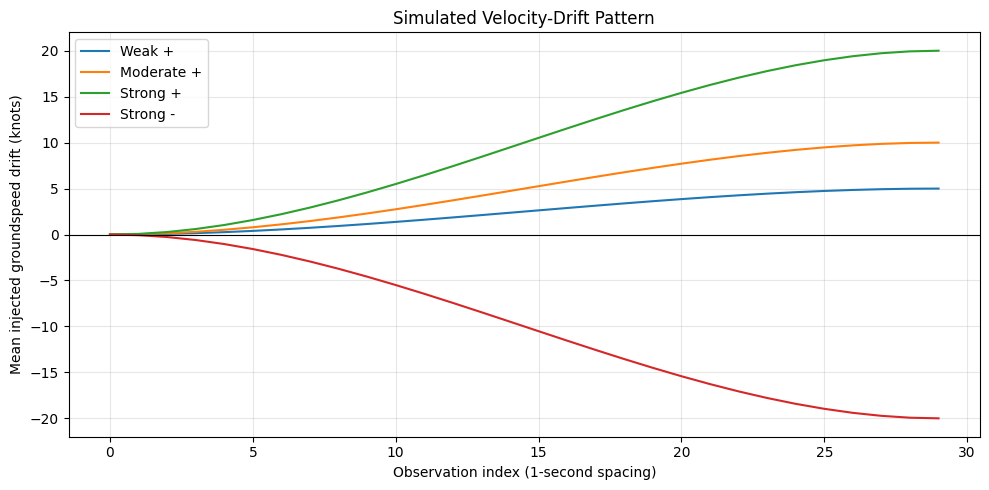

SUCCESS: Step 9.2C completed!


In [313]:

# ============================================================
# PHASE 9 — STEP 9.2C
# Verify Velocity-Drift Temporal Pattern
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

speed_idx = SPEED_FEATURES.index("groundspeed")

# Reuse the clean-speed estimate from Step 9.2B
# and the get_raw_speed() function.

plt.figure(figsize=(10, 5))

for intensity, direction in [
    ("weak", 1),
    ("moderate", 1),
    ("strong", 1),
    ("strong", -1)
]:

    observed_speed = get_raw_speed(
        intensity, direction
    )

    drift = observed_speed - estimated_clean_speed

    mean_drift = drift.mean(axis=0)

    label = (
        f"{intensity.capitalize()} "
        f"{'+' if direction == 1 else '-'}"
    )

    plt.plot(
        np.arange(30),
        mean_drift,
        label=label
    )

plt.axhline(0, color="black", linewidth=0.8)

plt.xlabel("Observation index (1-second spacing)")
plt.ylabel("Mean injected groundspeed drift (knots)")
plt.title("Simulated Velocity-Drift Pattern")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("SUCCESS: Step 9.2C completed!")


In [314]:

# ============================================================
# PHASE 9 — STEP 9.2D
# Verify Velocity-Drift Feature Consistency
# ============================================================

import numpy as np
import pandas as pd

attack_mask = (y_novel == 3)

# Use symmetric +20 / -20 attacks to estimate clean features
def get_raw_condition(intensity, direction):
    X = np.asarray(condition_tensors[(intensity, direction)])
    return scaler_speed.inverse_transform(
        X.reshape(-1, 4)
    ).reshape(X.shape)

positive = get_raw_condition("strong", 1)
negative = get_raw_condition("strong", -1)

estimated_clean = (positive + negative) / 2

feature_records = []

for intensity, direction in [
    ("weak", 1),
    ("moderate", 1),
    ("strong", 1),
    ("weak", -1),
    ("moderate", -1),
    ("strong", -1)
]:
    attacked = get_raw_condition(intensity, direction)

    for feature_idx, feature_name in enumerate(SPEED_FEATURES):

        difference = (
            attacked[attack_mask, :, feature_idx]
            - estimated_clean[attack_mask, :, feature_idx]
        )

        feature_records.append({
            "Intensity": intensity,
            "Direction": "Positive" if direction == 1 else "Negative",
            "Feature": feature_name,
            "Mean_Absolute_Change": round(
                float(np.abs(difference).mean()), 4
            ),
            "Maximum_Absolute_Change": round(
                float(np.abs(difference).max()), 4
            )
        })

feature_audit_df = pd.DataFrame(feature_records)

print("1. FEATURE-CHANGE AUDIT")
display(
    feature_audit_df.pivot_table(
        index=["Intensity", "Direction"],
        columns="Feature",
        values="Maximum_Absolute_Change"
    ).round(4)
)

print("\n2. POSITION-DERIVED SPEED CHECK")

derived_speed_changes = feature_audit_df[
    feature_audit_df["Feature"] == "speed_20s_knots"
]

print(
    "Maximum observed change:",
    derived_speed_changes["Maximum_Absolute_Change"].max()
)

print("\nSUCCESS: Step 9.2D completed!")


1. FEATURE-CHANGE AUDIT


Feature              groundspeed  speed_20s_knots  speed_error_10s  \
Intensity Direction                                                  
moderate  Negative          10.0              0.0          19.9174   
          Positive          10.0              0.0          19.2385   
strong    Negative          20.0              0.0          20.0000   
          Positive          20.0              0.0          20.0000   
weak      Negative           5.0              0.0          19.7210   
          Positive           5.0              0.0          19.6379   

Feature              speed_error_20s  
Intensity Direction                   
moderate  Negative           19.8984  
          Positive           19.4516  
strong    Negative           20.0000  
          Positive           20.0000  
weak      Negative           19.8557  
          Positive           19.9507


2. POSITION-DERIVED SPEED CHECK
Maximum observed change: 0.0

SUCCESS: Step 9.2D completed!


In [315]:

# ============================================================
# PHASE 9 — STEP 9.2E
# Verify 20-Second Speed-Error Feature
# ============================================================

import numpy as np
import pandas as pd

records = []

for (intensity, direction), X_condition in condition_tensors.items():

    # Convert scaled features back to original units
    raw = scaler_speed.inverse_transform(
        np.asarray(X_condition).reshape(-1, 4)
    ).reshape(100, 30, 4)

    # Select only simulated attack windows
    attack = raw[y_novel == 3]

    reported_speed = attack[:, :, 0]
    derived_speed = attack[:, :, 1]
    stored_error = attack[:, :, 3]

    # Recalculate expected absolute speed error
    calculated_error = np.abs(
        reported_speed - derived_speed
    )

    difference = np.abs(
        calculated_error - stored_error
    )

    records.append({
        "Intensity": intensity,
        "Direction": (
            "Positive" if direction == 1 else "Negative"
        ),
        "Mean_Error_Difference": difference.mean(),
        "Max_Error_Difference": difference.max(),
        "Matches": np.allclose(
            calculated_error,
            stored_error,
            atol=1e-3,
            rtol=1e-5
        )
    })

error_verification_df = pd.DataFrame(records)

print("1. SPEED-ERROR FEATURE VERIFICATION")
display(error_verification_df.round(6))

print("\n2. OVERALL RESULT")
print(
    "All conditions match:",
    error_verification_df["Matches"].all()
)

print("\nSUCCESS: Step 9.2E diagnostic completed!")


1. SPEED-ERROR FEATURE VERIFICATION


,Intensity,Direction,Mean_Error_Difference,Max_Error_Difference,Matches
0,weak,Positive,0.000011,0.000055,True
1,weak,Negative,0.000011,0.000059,True
2,moderate,Positive,0.000011,0.000058,True
3,moderate,Negative,0.000011,0.000056,True
4,strong,Positive,0.000012,0.000058,True
5,strong,Negative,0.000012,0.000060,True



2. OVERALL RESULT
All conditions match: True

SUCCESS: Step 9.2E diagnostic completed!


In [316]:

# ============================================================
# PHASE 9 — STEP 9.3A
# Inspect Path-Modification Attack Records
# ============================================================

import numpy as np
import pandas as pd

print("1. PATH-MODIFICATION DATASET")

print("Raw dataset shape:", X_large_raw.shape)
print("Labels:", np.unique(y_large, return_counts=True))

print("\n2. ATTACK METADATA")

print("Available columns:")
print(large_metadata_df.columns.tolist())

print("\n3. ATTACK INTENSITY COUNTS")

attack_records = large_metadata_df[
    large_metadata_df["label"] == 1
]

display(
    attack_records["intensity"]
    .value_counts(dropna=False)
    .rename_axis("Intensity")
    .reset_index(name="Windows")
)

print("\n4. DATASET CONSISTENCY")

assert X_large_raw.shape == (1000, 30, 14)
assert len(large_metadata_df) == len(y_large)

assert np.array_equal(
    large_metadata_df["label"].to_numpy(),
    y_large
)

assert len(attack_records) == 500

print("Attack windows:", len(attack_records))
print("Unique attack aircraft:", attack_records["icao24"].nunique())

print("\nSUCCESS: Step 9.3A completed!")


1. PATH-MODIFICATION DATASET
Raw dataset shape: (1000, 30, 14)
Labels: (array([0, 1]), array([500, 500]))

2. ATTACK METADATA
Available columns:
['icao24', 'flight_id', 'partition', 'label', 'intensity']

3. ATTACK INTENSITY COUNTS


,Intensity,Windows
0,weak,167
1,moderate,167
2,strong,166



4. DATASET CONSISTENCY
Attack windows: 500
Unique attack aircraft: 500

SUCCESS: Step 9.3A completed!


In [317]:

# ============================================================
# PHASE 9 — STEP 9.3B
# Inspect Path-Modification Simulation Resources
# ============================================================

import inspect

print("1. AVAILABLE SIMULATION FUNCTIONS")

for name, obj in list(globals().items()):

    if (
        inspect.isfunction(obj)
        and any(
            keyword in name.lower()
            for keyword in [
                "attack", "path", "inject",
                "window", "haversine", "smooth"
            ]
        )
    ):
        try:
            signature = inspect.signature(obj)
            print(f"{name}{signature}")
        except (ValueError, TypeError):
            print(name)

print("\n2. AVAILABLE SOURCE VARIABLES")

for name in [
    "large_train_plan",
    "flight_lookup_large",
    "flight_info",
    "window_index_df",
    "df_airspace"
]:
    if name in globals():
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"{name}: shape={obj.shape}")
        else:
            print(f"{name}: type={type(obj).__name__}")
    else:
        print(f"{name}: NOT FOUND")

print("\n3. EXAMPLE ATTACK RECORD")
display(attack_records.head(1))

print("\nSUCCESS: Step 9.3B diagnostic completed!")


1. AVAILABLE SIMULATION FUNCTIONS
engineer_window_features(window)
haversine_distance(lat1, lon1, lat2, lon2)
calculate_window_speed(window)
simulate_path_modification(flight_df, start_index, intensity='moderate', attack_length=30, recovery_length=20, seed=42)
assign_window_label(modified_count, window_size, attack_label)
create_window_label_table(original_flight_df, modified_flight_df, attack_label, changed_columns, feature_history=20)
create_attack_aware_labels(original_flight_df, modified_flight_df, attack_label, changed_columns)
simulate_ghost_injection(source_window, displacement_m=1000, seed=42, ghost_id='GHOST_SIM_001')

2. AVAILABLE SOURCE VARIABLES
large_train_plan: shape=(1000, 10)
flight_lookup_large: type=dict
flight_info: shape=(15811, 8)
window_index_df: shape=(426479, 6)
df_airspace: shape=(13338847, 12)

3. EXAMPLE ATTACK RECORD


,icao24,flight_id,partition,label,intensity
500,4951d8,TAP579_12788,Train,1,weak



SUCCESS: Step 9.3B diagnostic completed!


In [318]:

# ============================================================
# PHASE 9 — STEP 9.3C
# Inspect Original Path-Modification Simulator
# ============================================================

import inspect

print("1. PATH-MODIFICATION SIMULATOR")
print("=" * 60)

print(inspect.getsource(simulate_path_modification))

print("\n2. TRAINING PLAN COLUMNS")
print(large_train_plan.columns.tolist())

print("\n3. EXAMPLE ATTACK PLANS")

display(
    large_train_plan[
        large_train_plan["label"] == 1
    ].head(3)
)

print("\n4. SOURCE-FLIGHT LOOKUP")

print("Number of flight records:", len(flight_lookup_large))

first_key = next(iter(flight_lookup_large))

print("Example lookup key:", first_key)
print(
    "Example lookup value type:",
    type(flight_lookup_large[first_key]).__name__
)

print("\nSUCCESS: Step 9.3C diagnostic completed!")


1. PATH-MODIFICATION SIMULATOR
def simulate_path_modification(
    flight_df,
    start_index,
    intensity="moderate",
    attack_length=30,
    recovery_length=20,
    seed=42
):
    """
    Generate a controlled path-modification simulation.

    Input:
        flight_df: Complete, time-ordered flight
        start_index: Local position where injection begins
        intensity: weak / moderate / strong
        attack_length: Growth duration in observations
        recovery_length: Recovery duration in observations
        seed: Reproducible random seed

    Returns:
        modified_flight: Independent modified copy
        metadata: Attack details
    """

    if intensity not in PATH_ATTACK_INTENSITIES:
        raise ValueError("Unknown attack intensity")

    if attack_length < 2 or recovery_length < 2:
        raise ValueError("Attack and recovery lengths must be >= 2")

    modified_flight = (
        flight_df.sort_values("timestamp")
        .copy(deep=True)
        .reset_i

,flight_id,icao24,partition,start_row,end_row_exclusive,window_number,local_start,flight_length,label,attack_intensity
500,TAP579_12788,4951d8,Train,11117532,11117562,14,440,846,1,weak
501,AFR766_5750,394a12,Train,2884063,2884093,4,140,353,1,moderate
502,EZY23NT_9418,400e5c,Train,5536951,5536981,0,20,468,1,strong



4. SOURCE-FLIGHT LOOKUP
Number of flight records: 1000
Example lookup key: AAF221_6618
Example lookup value type: DataFrame

SUCCESS: Step 9.3C diagnostic completed!


In [319]:

# ============================================================
# PHASE 9 — STEP 9.3D
# Verify Path-Modification Geographic Displacement
# ============================================================

import numpy as np
import pandas as pd

records = []

for intensity in ["weak", "moderate", "strong"]:

    # Select one training-plan example
    example = large_train_plan[
        (large_train_plan["label"] == 1)
        & (large_train_plan["attack_intensity"] == intensity)
    ].iloc[0]

    # Retrieve original flight
    flight_id = example["flight_id"]
    original_flight = flight_lookup_large[flight_id]

    # Recreate the simulated attack
    modified_flight, metadata = simulate_path_modification(
        flight_df=original_flight,
        start_index=int(example["local_start"]),
        intensity=intensity,
        attack_length=30,
        recovery_length=20,
        seed=42
    )

    # Compare original and modified positions
    clean = original_flight.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    modified = modified_flight.reset_index(drop=True)

    distances = haversine_distance(
        clean["latitude"].to_numpy(),
        clean["longitude"].to_numpy(),
        modified["latitude"].to_numpy(),
        modified["longitude"].to_numpy()
    )

    observed_max = float(np.max(distances))
    expected_max = float(metadata["max_displacement_m"])

    records.append({
        "Intensity": intensity,
        "Expected_Max_m": expected_max,
        "Observed_Max_m": round(observed_max, 4),
        "Absolute_Error_m": round(
            abs(observed_max - expected_max), 6
        ),
        "Within_1m": abs(observed_max - expected_max) < 1
    })

displacement_audit_df = pd.DataFrame(records)

print("1. PATH-MODIFICATION DISPLACEMENT AUDIT")
display(displacement_audit_df)

print("\n2. OVERALL VERIFICATION")
print(
    "All intensities within 1 metre:",
    displacement_audit_df["Within_1m"].all()
)

print("\nSUCCESS: Step 9.3D completed!")


1. PATH-MODIFICATION DISPLACEMENT AUDIT


,Intensity,Expected_Max_m,Observed_Max_m,Absolute_Error_m,Within_1m
0,weak,100.0,99.9999,0.000115,True
1,moderate,300.0,299.9989,0.001130,True
2,strong,500.0,499.9970,0.002972,True



2. OVERALL VERIFICATION
All intensities within 1 metre: True

SUCCESS: Step 9.3D completed!


1. TEMPORAL INTEGRITY CHECK
Growth is non-decreasing: True
Recovery is non-increasing: True
Starting displacement (m): 0.0
Peak displacement (m): 499.997
Ending displacement (m): 0.0


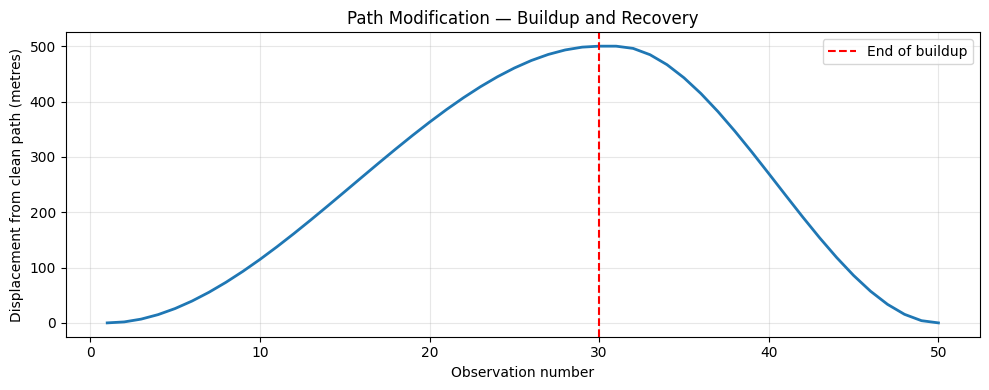


SUCCESS: Step 9.3E completed!


In [320]:

# ============================================================
# PHASE 9 — STEP 9.3E
# Verify Path-Modification Buildup and Recovery
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Select one strong attack example
example = large_train_plan[
    (large_train_plan["label"] == 1)
    & (large_train_plan["attack_intensity"] == "strong")
].iloc[0]

original = flight_lookup_large[
    example["flight_id"]
].sort_values("timestamp").reset_index(drop=True)

modified, metadata = simulate_path_modification(
    flight_df=original,
    start_index=int(example["local_start"]),
    intensity="strong",
    attack_length=30,
    recovery_length=20,
    seed=42
)

# Calculate geographic displacement
distances = np.asarray(haversine_distance(
    original["latitude"].to_numpy(),
    original["longitude"].to_numpy(),
    modified["latitude"].to_numpy(),
    modified["longitude"].to_numpy()
))

start = metadata["start_index"]
end = metadata["end_index_exclusive"]

# Extract the 50-observation attack segment
attack_distances = distances[start:end]

# Check buildup and recovery
growth = attack_distances[:30]
recovery = attack_distances[30:]

growth_increasing = np.all(np.diff(growth) >= -0.01)
recovery_decreasing = np.all(np.diff(recovery) <= 0.01)

print("1. TEMPORAL INTEGRITY CHECK")
print("Growth is non-decreasing:", growth_increasing)
print("Recovery is non-increasing:", recovery_decreasing)
print("Starting displacement (m):", round(float(growth[0]), 6))
print("Peak displacement (m):", round(float(np.max(attack_distances)), 4))
print("Ending displacement (m):", round(float(recovery[-1]), 6))

# Plot displacement over the 50 observations
plt.figure(figsize=(10, 4))
plt.plot(
    np.arange(1, 51),
    attack_distances,
    linewidth=2
)
plt.axvline(
    30,
    color="red",
    linestyle="--",
    label="End of buildup"
)
plt.xlabel("Observation number")
plt.ylabel("Displacement from clean path (metres)")
plt.title("Path Modification — Buildup and Recovery")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

assert growth_increasing
assert recovery_decreasing
assert abs(growth[0]) < 0.01
assert abs(recovery[-1]) < 0.01

print("\nSUCCESS: Step 9.3E completed!")


In [321]:

# ============================================================
# PHASE 9 — STEP 9.3F (REVISED)
# Audit All 500 Stored Path-Modification Attacks
# ============================================================

import numpy as np
import pandas as pd

audit_records = []

attack_plans = large_train_plan[
    large_train_plan["label"] == 1
]

assert len(attack_plans) == 500

for idx, plan in attack_plans.iterrows():

    # Retrieve original clean trajectory
    original = (
        flight_lookup_large[plan["flight_id"]]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    start = int(plan["local_start"])

    clean_window = original.iloc[start:start + 30]
    stored_window = X_large_raw[idx]

    # Clean coordinates
    clean_lat = clean_window["latitude"].to_numpy()
    clean_lon = clean_window["longitude"].to_numpy()

    # Stored attacked coordinates
    stored_lat = stored_window[
        :, FEATURE_COLS_14.index("latitude")
    ]
    stored_lon = stored_window[
        :, FEATURE_COLS_14.index("longitude")
    ]

    # Geographic displacement from original path
    displacement = np.asarray(
        haversine_distance(
            clean_lat,
            clean_lon,
            stored_lat,
            stored_lon
        )
    )

    expected = PATH_ATTACK_INTENSITIES[
        plan["attack_intensity"]
    ]

    observed = float(displacement.max())

    audit_records.append({
        "Intensity": plan["attack_intensity"],
        "Expected_Peak_m": expected,
        "Observed_Peak_m": observed,
        "Peak_Error_m": abs(observed - expected),
        "Starting_Displacement_m": float(displacement[0])
    })

path_audit_df = pd.DataFrame(audit_records)

print("1. FULL PATH-MODIFICATION AUDIT")
print("Audited windows:", len(path_audit_df))

display(
    path_audit_df.groupby("Intensity").agg(
        Windows=("Intensity", "size"),
        Mean_Observed_Peak_m=("Observed_Peak_m", "mean"),
        Max_Peak_Error_m=("Peak_Error_m", "max"),
        Max_Starting_Displacement_m=("Starting_Displacement_m", "max")
    ).round(4)
)

print("\n2. OVERALL VERIFICATION")

peak_pass = bool(
    (path_audit_df["Peak_Error_m"] < 1).all()
)

print("All stored attack peaks within 1 metre:", peak_pass)

assert peak_pass

print("\nSUCCESS: Step 9.3F completed!")


1. FULL PATH-MODIFICATION AUDIT
Audited windows: 500


,Windows,Mean_Observed_Peak_m,Max_Peak_Error_m,Max_Starting_Displacement_m
Intensity,,,,
moderate,167,300.0041,0.1996,0.2085
strong,166,500.0077,0.2089,0.2086
weak,167,99.9979,0.2074,0.2085



2. OVERALL VERIFICATION
All stored attack peaks within 1 metre: True

SUCCESS: Step 9.3F completed!


In [322]:

# ============================================================
# PHASE 9 — STEP 9.3G
# Verify Stored Path-Modification Buildup
# ============================================================

import numpy as np
import pandas as pd

records = []

for idx, plan in attack_plans.iterrows():

    original = (
        flight_lookup_large[plan["flight_id"]]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    start = int(plan["local_start"])

    clean = original.iloc[start:start + 30]
    stored = X_large_raw[idx]

    distances = np.asarray(
        haversine_distance(
            clean["latitude"].to_numpy(),
            clean["longitude"].to_numpy(),
            stored[:, FEATURE_COLS_14.index("latitude")],
            stored[:, FEATURE_COLS_14.index("longitude")]
        )
    )

    # Allow 0.5 m tolerance for coordinate precision
    monotonic = bool(
        np.all(np.diff(distances) >= -0.5)
    )

    records.append({
        "Intensity": plan["attack_intensity"],
        "Smooth_Buildup": monotonic,
        "Start_m": float(distances[0]),
        "End_m": float(distances[-1])
    })

buildup_audit_df = pd.DataFrame(records)

print("1. STORED ATTACK BUILDUP AUDIT")

display(
    buildup_audit_df.groupby("Intensity").agg(
        Windows=("Intensity", "size"),
        Smooth_Buildup_Pass=("Smooth_Buildup", "sum"),
        Max_Start_m=("Start_m", "max"),
        Mean_End_m=("End_m", "mean")
    ).round(4)
)

print("\n2. OVERALL CHECK")

all_smooth = bool(
    buildup_audit_df["Smooth_Buildup"].all()
)

print("All 500 attacks show gradual buildup:", all_smooth)

assert all_smooth

print("\nSUCCESS: Step 9.3G completed!")


1. STORED ATTACK BUILDUP AUDIT


,Windows,Smooth_Buildup_Pass,Max_Start_m,Mean_End_m
Intensity,,,,
moderate,167,167,0.2085,300.0041
strong,166,166,0.2086,500.0077
weak,167,167,0.2085,99.9972



2. OVERALL CHECK
All 500 attacks show gradual buildup: True

SUCCESS: Step 9.3G completed!


In [323]:

# ============================================================
# PHASE 9 — STEP 9.4A
# Inspect Data for Ghost Aircraft Injection
# ============================================================

import pandas as pd
import numpy as np

print("1. AVAILABLE AIRCRAFT DATA COLUMNS")
print(df_airspace.columns.tolist())

print("\n2. TIMESTAMP INFORMATION")
print("Timestamp dtype:", df_airspace["timestamp"].dtype)
print("Unique timestamps:", df_airspace["timestamp"].nunique())

print("\n3. AIRCRAFT PRESENT AT THE SAME TIME")

# Small sample to keep the check fast
sample = df_airspace.iloc[:100000].copy()

aircraft_per_time = (
    sample.groupby("timestamp")["icao24"]
    .nunique()
)

print("Maximum simultaneous aircraft:",
      aircraft_per_time.max())

print("Average aircraft per timestamp:",
      round(aircraft_per_time.mean(), 2))

print("Timestamps with 2+ aircraft:",
      int((aircraft_per_time >= 2).sum()))

print("\n4. POSITION DATA CHECK")
for col in ["latitude", "longitude", "icao24", "timestamp"]:
    print(col, "available:", col in df_airspace.columns)

print("\nSUCCESS: Step 9.4A completed!")


1. AVAILABLE AIRCRAFT DATA COLUMNS
['timestamp', 'altitude', 'callsign', 'geoaltitude', 'groundspeed', 'icao24', 'latitude', 'longitude', 'squawk', 'track', 'vertical_rate', 'flight_id']

2. TIMESTAMP INFORMATION
Timestamp dtype: datetime64[ms, UTC]
Unique timestamps: 1280916

3. AIRCRAFT PRESENT AT THE SAME TIME
Maximum simultaneous aircraft: 3
Average aircraft per timestamp: 1.06
Timestamps with 2+ aircraft: 5877

4. POSITION DATA CHECK
latitude available: True
longitude available: True
icao24 available: True
timestamp available: True

SUCCESS: Step 9.4A completed!


In [324]:

# ============================================================
# PHASE 9 — STEP 9.4B
# Check Simultaneous Aircraft in Training Data
# ============================================================

import pandas as pd
import numpy as np

# Use training aircraft only
train_rows = df_airspace[
    df_airspace["icao24"].isin(train_aircraft)
][["timestamp", "icao24", "flight_id", "latitude", "longitude"]].copy()

# Count unique aircraft at each timestamp
aircraft_counts = (
    train_rows.groupby("timestamp")["icao24"]
    .nunique()
)

print("1. TRAINING AIRSPACE OVERLAP")

print("Training observations:", len(train_rows))
print("Unique timestamps:", len(aircraft_counts))

print("Timestamps with 2+ aircraft:",
      int((aircraft_counts >= 2).sum()))

print("Timestamps with 3+ aircraft:",
      int((aircraft_counts >= 3).sum()))

print("Maximum simultaneous aircraft:",
      int(aircraft_counts.max()))

print("\n2. SIMULTANEOUS AIRCRAFT DISTRIBUTION")

display(
    aircraft_counts.value_counts()
    .sort_index()
    .rename_axis("Aircraft_Count")
    .reset_index(name="Timestamps")
    .head(15)
)

print("\n3. GHOST-INJECTION FEASIBILITY")

has_overlap = bool((aircraft_counts >= 2).any())

print("Multiple-aircraft observations available:", has_overlap)

assert has_overlap

print("\nSUCCESS: Step 9.4B completed!")


1. TRAINING AIRSPACE OVERLAP
Training observations: 9250184
Unique timestamps: 1273814
Timestamps with 2+ aircraft: 1239933
Timestamps with 3+ aircraft: 1184524
Maximum simultaneous aircraft: 23

2. SIMULTANEOUS AIRCRAFT DISTRIBUTION


,Aircraft_Count,Timestamps
0,1,33881
1,2,55409
2,3,85058
3,4,118344
4,5,140611
5,6,143136
6,7,143076
7,8,133514
8,9,103232
9,10,85707



3. GHOST-INJECTION FEASIBILITY
Multiple-aircraft observations available: True

SUCCESS: Step 9.4B completed!


In [325]:

# ============================================================
# PHASE 9 — STEP 9.4C
# Check Continuous Multi-Aircraft Overlap
# ============================================================

import numpy as np
import pandas as pd

# Reuse train_rows from Step 9.4B
# Count unique aircraft at each timestamp
counts = (
    train_rows.groupby("timestamp")["icao24"]
    .nunique()
    .sort_index()
)

# Identify timestamps with at least 2 aircraft
overlap = counts[counts >= 2]

# Group consecutive 1-second timestamps
time_differences = overlap.index.to_series().diff()

new_segment = (
    time_differences.ne(pd.Timedelta(seconds=1))
)

segment_ids = new_segment.cumsum().to_numpy()

# Calculate continuous overlap durations
segments = overlap.groupby(segment_ids).agg(
    ["size", "min", "max"]
)

segments.columns = [
    "Duration_Seconds",
    "Min_Aircraft",
    "Max_Aircraft"
]

print("1. CONTINUOUS MULTI-AIRCRAFT OVERLAP")

print("Total overlapping segments:", len(segments))

print(
    "Segments lasting at least 30 seconds:",
    int((segments["Duration_Seconds"] >= 30).sum())
)

print(
    "Segments lasting at least 50 seconds:",
    int((segments["Duration_Seconds"] >= 50).sum())
)

print(
    "Longest continuous overlap:",
    int(segments["Duration_Seconds"].max()),
    "seconds"
)

print("\n2. LONGEST OVERLAP SEGMENTS")

display(
    segments.sort_values(
        "Duration_Seconds",
        ascending=False
    ).head(10)
)

print("\n3. FEASIBILITY CHECK")

sufficient_overlap = bool(
    (segments["Duration_Seconds"] >= 30).any()
)

print(
    "Continuous 30-second overlap available:",
    sufficient_overlap
)

print("\nSUCCESS: Step 9.4C completed!")


1. CONTINUOUS MULTI-AIRCRAFT OVERLAP
Total overlapping segments: 368
Segments lasting at least 30 seconds: 363
Segments lasting at least 50 seconds: 362
Longest continuous overlap: 15588 seconds

2. LONGEST OVERLAP SEGMENTS


,Duration_Seconds,Min_Aircraft,Max_Aircraft
178,15588,2,9
57,13318,2,15
8,11895,2,12
219,11518,2,12
307,11098,4,17
32,11001,2,10
169,10846,2,8
231,10806,2,10
223,10632,2,10
286,10258,3,19



3. FEASIBILITY CHECK
Continuous 30-second overlap available: True

SUCCESS: Step 9.4C completed!


In [326]:

# ============================================================
# PHASE 9 — STEP 9.4D
# Verify Continuous Overlap Between Aircraft Pairs
# ============================================================

import numpy as np
import pandas as pd

# Use timestamps where at least two aircraft are present
eligible_times = counts[counts >= 2].index

# First select a limited sample for a manageable check
sample_times = eligible_times[:10000]

subset = train_rows[
    train_rows["timestamp"].isin(sample_times)
][["timestamp", "icao24"]].drop_duplicates()

# Generate aircraft pairs at each timestamp
pairs = (
    subset.merge(
        subset,
        on="timestamp",
        suffixes=("_a", "_b")
    )
)

# Keep each pair once
pairs = pairs[
    pairs["icao24_a"] < pairs["icao24_b"]
].copy()

pairs = pairs.sort_values(
    ["icao24_a", "icao24_b", "timestamp"]
)

# Check consecutive seconds for each fixed pair
time_gap = pairs.groupby(
    ["icao24_a", "icao24_b"]
)["timestamp"].diff()

new_run = time_gap.ne(pd.Timedelta(seconds=1))

pairs["run_id"] = new_run.groupby([
    pairs["icao24_a"],
    pairs["icao24_b"]
]).cumsum()

pair_runs = (
    pairs.groupby(
        ["icao24_a", "icao24_b", "run_id"]
    )
    .size()
    .reset_index(name="Consecutive_Seconds")
)

valid_pair_runs = pair_runs[
    pair_runs["Consecutive_Seconds"] >= 30
]

print("1. AIRCRAFT-PAIR CONTINUITY CHECK")
print("Sampled timestamps:", len(sample_times))
print("Pairs with 30+ consecutive observations:",
      len(valid_pair_runs))

print("\n2. LONGEST PAIR OVERLAPS")
display(
    valid_pair_runs.sort_values(
        "Consecutive_Seconds",
        ascending=False
    ).head(10)
)

print("\n3. FEASIBILITY")
print(
    "At least one continuous aircraft pair found:",
    not valid_pair_runs.empty
)

print("\nSUCCESS: Step 9.4D completed!")


1. AIRCRAFT-PAIR CONTINUITY CHECK
Sampled timestamps: 10000
Pairs with 30+ consecutive observations: 440

2. LONGEST PAIR OVERLAPS


,icao24_a,icao24_b,run_id,Consecutive_Seconds
117,392af8,39840f,1,1559
260,3991e0,4cabc0,1,1554
194,394c17,44a8a2,1,1535
46,0a0019,406b62,1,1435
52,0a0019,4ca243,1,1377
363,406b62,4ca243,1,1377
141,392af8,4cabc0,1,1342
91,392af1,39840f,1,1276
133,392af8,49524f,1,1242
87,392af1,392af8,1,1225



3. FEASIBILITY
At least one continuous aircraft pair found: True

SUCCESS: Step 9.4D completed!


In [327]:

# ============================================================
# PHASE 9 — STEP 9.4E
# Inspect Candidate Flight for Ghost Injection
# ============================================================

import pandas as pd
import numpy as np

# Select the longest overlapping pair
candidate = valid_pair_runs.sort_values(
    "Consecutive_Seconds",
    ascending=False
).iloc[0]

aircraft_a = candidate["icao24_a"]
aircraft_b = candidate["icao24_b"]

print("1. SELECTED AIRCRAFT PAIR")
print("Aircraft A:", aircraft_a)
print("Aircraft B:", aircraft_b)
print("Overlap duration:", candidate["Consecutive_Seconds"])

# Retrieve their flight records from the training partition
pair_data = train_rows[
    train_rows["icao24"].isin([aircraft_a, aircraft_b])
].copy()

print("\n2. AIRCRAFT DATA")
display(
    pair_data.groupby("icao24").agg(
        Observations=("timestamp", "size"),
        Flights=("flight_id", "nunique"),
        First_Time=("timestamp", "min"),
        Last_Time=("timestamp", "max")
    )
)

print("\n3. REQUIRED FIELDS")
print("Latitude available:", "latitude" in pair_data.columns)
print("Longitude available:", "longitude" in pair_data.columns)
print("Timestamp available:", "timestamp" in pair_data.columns)

print("\nSUCCESS: Step 9.4E completed!")


1. SELECTED AIRCRAFT PAIR
Aircraft A: 392af8
Aircraft B: 39840f
Overlap duration: 1559

2. AIRCRAFT DATA


,Observations,Flights,First_Time,Last_Time
icao24,,,,
392af8,13286,14,2017-01-01 07:00:44+00:00,2017-07-23 19:56:13+00:00
39840f,27465,24,2017-01-01 06:59:53+00:00,2017-07-07 19:18:45+00:00



3. REQUIRED FIELDS
Latitude available: True
Longitude available: True
Timestamp available: True

SUCCESS: Step 9.4E completed!


In [328]:

# ============================================================
# PHASE 9 — STEP 9.4F
# Extract Synchronized Aircraft Trajectories
# ============================================================

import numpy as np
import pandas as pd

# Select the two candidate aircraft
a = train_rows[
    train_rows["icao24"] == aircraft_a
].copy()

b = train_rows[
    train_rows["icao24"] == aircraft_b
].copy()

# Remove invalid positions
a = a.dropna(subset=["timestamp", "latitude", "longitude"])
b = b.dropna(subset=["timestamp", "latitude", "longitude"])

# Synchronize using exact timestamps
paired = a.merge(
    b,
    on="timestamp",
    suffixes=("_a", "_b")
).sort_values("timestamp").reset_index(drop=True)

# Find gaps between consecutive timestamps
time_gap = paired["timestamp"].diff()

paired["segment_id"] = (
    time_gap.ne(pd.Timedelta(seconds=1))
).cumsum()

# Identify continuous segments
segment_lengths = (
    paired.groupby("segment_id")
    .size()
    .sort_values(ascending=False)
)

print("1. SYNCHRONIZED TRAJECTORY SUMMARY")
print("Matching timestamps:", len(paired))
print("Longest continuous segment:", int(segment_lengths.iloc[0]))

# Select a 30-observation segment
valid_segments = segment_lengths[
    segment_lengths >= 30
]

assert not valid_segments.empty, "No suitable 30-second segment"

selected_segment = valid_segments.index[0]

ghost_source_pair = (
    paired[paired["segment_id"] == selected_segment]
    .head(30)
    .copy()
    .reset_index(drop=True)
)

print("\n2. SELECTED SEGMENT")
print("Observations:", len(ghost_source_pair))
print("First timestamp:", ghost_source_pair["timestamp"].iloc[0])
print("Last timestamp:", ghost_source_pair["timestamp"].iloc[-1])

print("\n3. FLIGHT CONSISTENCY")
print("Aircraft A flight IDs:", ghost_source_pair["flight_id_a"].nunique())
print("Aircraft B flight IDs:", ghost_source_pair["flight_id_b"].nunique())

assert len(ghost_source_pair) == 30
assert ghost_source_pair["flight_id_a"].nunique() == 1
assert ghost_source_pair["flight_id_b"].nunique() == 1

print("\nSUCCESS: Step 9.4F completed!")


1. SYNCHRONIZED TRAJECTORY SUMMARY
Matching timestamps: 1836
Longest continuous segment: 1559

2. SELECTED SEGMENT
Observations: 30
First timestamp: 2017-01-01 07:00:44+00:00
Last timestamp: 2017-01-01 07:01:13+00:00

3. FLIGHT CONSISTENCY
Aircraft A flight IDs: 1
Aircraft B flight IDs: 1

SUCCESS: Step 9.4F completed!


In [329]:

# ============================================================
# PHASE 9 — STEP 9.4G
# Create First Simulated Ghost Aircraft
# ============================================================

import numpy as np
import pandas as pd

GHOST_OFFSET_M = 1000
GHOST_SEED = 42

def simulate_ghost_aircraft(
    source_pair,
    displacement_m=1000,
    seed=42
):
    rng = np.random.default_rng(seed)

    # Random geographic displacement direction
    angle = rng.uniform(0, 2 * np.pi)

    east = displacement_m * np.sin(angle)
    north = displacement_m * np.cos(angle)

    # Copy Aircraft A's data
    ghost = pd.DataFrame({
        "timestamp": source_pair["timestamp"].to_numpy(),
        "latitude": source_pair["latitude_a"].to_numpy().copy(),
        "longitude": source_pair["longitude_a"].to_numpy().copy()
    })

    # Shift geographic coordinates
    lat_rad = np.radians(ghost["latitude"].to_numpy())

    ghost["latitude"] += (
        north / EARTH_RADIUS_M
    ) * (180 / np.pi)

    ghost["longitude"] += (
        east / (
            EARTH_RADIUS_M * np.cos(lat_rad)
        )
    ) * (180 / np.pi)

    # Assign a synthetic identity
    ghost["icao24"] = "GHOST_SIM_001"
    ghost["flight_id"] = "GHOST_FLIGHT_001"
    ghost["label"] = 2

    metadata = {
        "attack_type": "ghost_aircraft_injection",
        "attack_label": 2,
        "displacement_m": displacement_m,
        "source_aircraft": str(aircraft_a),
        "synthetic_identity": "GHOST_SIM_001",
        "seed": seed
    }

    return ghost, metadata


ghost_df, ghost_metadata = simulate_ghost_aircraft(
    ghost_source_pair,
    displacement_m=GHOST_OFFSET_M,
    seed=GHOST_SEED
)

print("1. GHOST AIRCRAFT CREATED")
print("Observations:", len(ghost_df))
print("Synthetic identity:", ghost_df["icao24"].iloc[0])
print("Attack label:", ghost_df["label"].iloc[0])

print("\n2. GHOST METADATA")
print(ghost_metadata)

print("\n3. FIRST FIVE OBSERVATIONS")
display(ghost_df.head())

assert len(ghost_df) == 30
assert ghost_df["label"].eq(2).all()

print("\nSUCCESS: Step 9.4G completed!")


1. GHOST AIRCRAFT CREATED
Observations: 30
Synthetic identity: GHOST_SIM_001
Attack label: 2

2. GHOST METADATA
{'attack_type': 'ghost_aircraft_injection', 'attack_label': 2, 'displacement_m': 1000, 'source_aircraft': '392af8', 'synthetic_identity': 'GHOST_SIM_001', 'seed': 42}

3. FIRST FIVE OBSERVATIONS


,timestamp,latitude,longitude,icao24,flight_id,label
0,2017-01-01 07:00:44+00:00,48.116811,2.210658,GHOST_SIM_001,GHOST_FLIGHT_001,2
1,2017-01-01 07:00:45+00:00,48.116811,2.210795,GHOST_SIM_001,GHOST_FLIGHT_001,2
2,2017-01-01 07:00:46+00:00,48.116811,2.211207,GHOST_SIM_001,GHOST_FLIGHT_001,2
3,2017-01-01 07:00:47+00:00,48.116811,2.211276,GHOST_SIM_001,GHOST_FLIGHT_001,2
4,2017-01-01 07:00:48+00:00,48.116811,2.211551,GHOST_SIM_001,GHOST_FLIGHT_001,2



SUCCESS: Step 9.4G completed!


In [330]:

# ============================================================
# PHASE 9 — STEP 9.4H
# Verify First Simulated Ghost Aircraft
# ============================================================

import numpy as np
import pandas as pd

# Original aircraft A positions
source_lat = ghost_source_pair["latitude_a"].to_numpy()
source_lon = ghost_source_pair["longitude_a"].to_numpy()

# Ghost aircraft positions
ghost_lat = ghost_df["latitude"].to_numpy()
ghost_lon = ghost_df["longitude"].to_numpy()

# Calculate geographic displacement
distances = np.asarray(
    haversine_distance(
        source_lat,
        source_lon,
        ghost_lat,
        ghost_lon
    )
)

print("1. GHOST DISPLACEMENT VERIFICATION")
print("Expected displacement:", GHOST_OFFSET_M, "metres")
print("Mean displacement:", round(float(distances.mean()), 4))
print("Minimum displacement:", round(float(distances.min()), 4))
print("Maximum displacement:", round(float(distances.max()), 4))

# Check timestamp alignment
timestamps_match = np.array_equal(
    pd.to_datetime(ghost_df["timestamp"], utc=True).to_numpy(),
    pd.to_datetime(
        ghost_source_pair["timestamp"], utc=True
    ).to_numpy()
)

print("\n2. TIMESTAMP VERIFICATION")
print("Timestamps match:", timestamps_match)

# Check source trajectory is unchanged
source_unchanged = np.array_equal(
    ghost_source_pair["latitude_a"].to_numpy(),
    source_lat
) and np.array_equal(
    ghost_source_pair["longitude_a"].to_numpy(),
    source_lon
)

print("\n3. ORIGINAL AIRCRAFT CHECK")
print("Source trajectory unchanged:", source_unchanged)

# Overall checks
displacement_pass = bool(
    np.all(np.abs(distances - GHOST_OFFSET_M) < 1.0)
)

assert displacement_pass
assert timestamps_match
assert source_unchanged

print("\nSUCCESS: Step 9.4H completed!")


1. GHOST DISPLACEMENT VERIFICATION
Expected displacement: 1000 metres
Mean displacement: 999.9872
Minimum displacement: 999.9872
Maximum displacement: 999.9872

2. TIMESTAMP VERIFICATION
Timestamps match: True

3. ORIGINAL AIRCRAFT CHECK
Source trajectory unchanged: True

SUCCESS: Step 9.4H completed!


In [331]:

# ============================================================
# PHASE 9 — STEP 9.4I
# Inspect Source Features for Ghost Dataset Generation
# ============================================================

import pandas as pd
import numpy as np

required_columns = [
    "timestamp",
    "icao24",
    "flight_id",
    "latitude",
    "longitude",
    "groundspeed",
    "track",
    "altitude",
    "geoaltitude",
    "vertical_rate"
]

print("1. REQUIRED ADS-B FEATURES")

for col in required_columns:
    print(f"{col}: {'Available' if col in df_airspace.columns else 'Missing'}")

missing = [
    col for col in required_columns
    if col not in df_airspace.columns
]

assert not missing, f"Missing columns: {missing}"

print("\n2. SELECTED SOURCE FLIGHT")

source_flight_id = ghost_source_pair["flight_id_a"].iloc[0]

source_flight = (
    df_airspace[
        (df_airspace["flight_id"] == source_flight_id)
        & (df_airspace["icao24"] == aircraft_a)
    ]
    .sort_values("timestamp")
    .copy()
)

print("Source aircraft:", aircraft_a)
print("Source flight:", source_flight_id)
print("Observations:", len(source_flight))

print("\n3. MISSING VALUES IN REQUIRED FEATURES")

display(
    source_flight[required_columns]
    .isna()
    .sum()
    .to_frame("Missing_Values")
)

print("\n4. SOURCE FLIGHT SAMPLE")
display(source_flight[required_columns].head(3))

print("\nSUCCESS: Step 9.4I completed!")


1. REQUIRED ADS-B FEATURES
timestamp: Available
icao24: Available
flight_id: Available
latitude: Available
longitude: Available
groundspeed: Available
track: Available
altitude: Available
geoaltitude: Available
vertical_rate: Available

2. SELECTED SOURCE FLIGHT
Source aircraft: 392af8
Source flight: AFR148E_4373
Observations: 1719

3. MISSING VALUES IN REQUIRED FEATURES


,Missing_Values
timestamp,0
icao24,0
flight_id,0
latitude,0
longitude,0
groundspeed,0
track,0
altitude,0
geoaltitude,0
vertical_rate,0



4. SOURCE FLIGHT SAMPLE


,timestamp,icao24,flight_id,latitude,longitude,groundspeed,track,altitude,geoaltitude,vertical_rate
0,2017-01-01 07:00:44+00:00,392af8,AFR148E_4373,48.115462,2.223976,444.713007,174.968873,26025.0,26025.0,1408.0
1,2017-01-01 07:00:45+00:00,392af8,AFR148E_4373,48.115462,2.224113,444.713007,174.968873,26050.0,26075.0,1408.0
2,2017-01-01 07:00:46+00:00,392af8,AFR148E_4373,48.115462,2.224525,444.713007,174.968873,26075.0,26075.0,1408.0



SUCCESS: Step 9.4I completed!


In [332]:

# ============================================================
# PHASE 9 — STEP 9.4J
# Build Complete Ghost Aircraft Injection Simulator
# ============================================================

import numpy as np
import pandas as pd

def simulate_ghost_injection(
    source_window,
    displacement_m=1000,
    seed=42,
    ghost_id="GHOST_SIM_001"
):
    # Make an independent copy
    ghost = source_window.copy(deep=True).reset_index(drop=True)

    required = [
        "timestamp", "latitude", "longitude",
        "groundspeed", "track", "altitude",
        "geoaltitude", "vertical_rate"
    ]

    assert all(col in ghost.columns for col in required)
    assert len(ghost) == 30

    rng = np.random.default_rng(seed)
    angle = rng.uniform(0, 2 * np.pi)

    east = displacement_m * np.sin(angle)
    north = displacement_m * np.cos(angle)

    original_lat = ghost["latitude"].to_numpy(dtype=float)
    original_lon = ghost["longitude"].to_numpy(dtype=float)

    # Geographic displacement
    lat_offset = (
        north / EARTH_RADIUS_M
    ) * (180 / np.pi)

    lon_offset = (
        east / (
            EARTH_RADIUS_M * np.cos(np.radians(original_lat))
        )
    ) * (180 / np.pi)

    ghost["latitude"] = original_lat + lat_offset
    ghost["longitude"] = original_lon + lon_offset

    # Synthetic identity
    ghost["icao24"] = ghost_id
    ghost["flight_id"] = f"{ghost_id}_FLIGHT"
    ghost["label"] = 2

    metadata = {
        "attack_type": "ghost_aircraft_injection",
        "source_flight": str(source_window["flight_id"].iloc[0]),
        "ghost_id": ghost_id,
        "displacement_m": displacement_m,
        "seed": seed
    }

    return ghost, metadata


# Select a continuous 30-observation source window
source_window = (
    source_flight.iloc[:30]
    .copy()
    .reset_index(drop=True)
)

ghost_complete, ghost_complete_metadata = simulate_ghost_injection(
    source_window=source_window,
    displacement_m=1000,
    seed=42
)

print("1. COMPLETE GHOST SIMULATION")
print("Source shape:", source_window.shape)
print("Ghost shape:", ghost_complete.shape)

print("\n2. GHOST IDENTITY")
print("Ghost aircraft:", ghost_complete["icao24"].iloc[0])
print("Ghost label:", ghost_complete["label"].iloc[0])

print("\n3. COPIED MOTION FEATURES")

for feature in [
    "groundspeed", "track",
    "altitude", "geoaltitude", "vertical_rate"
]:
    matches = np.allclose(
        source_window[feature].to_numpy(),
        ghost_complete[feature].to_numpy()
    )
    print(f"{feature}: {matches}")
    assert matches

print("\n4. GHOST METADATA")
print(ghost_complete_metadata)

print("\nSUCCESS: Step 9.4J completed!")


1. COMPLETE GHOST SIMULATION
Source shape: (30, 12)
Ghost shape: (30, 13)

2. GHOST IDENTITY
Ghost aircraft: GHOST_SIM_001
Ghost label: 2

3. COPIED MOTION FEATURES
groundspeed: True
track: True
altitude: True
geoaltitude: True
vertical_rate: True

4. GHOST METADATA
{'attack_type': 'ghost_aircraft_injection', 'source_flight': 'AFR148E_4373', 'ghost_id': 'GHOST_SIM_001', 'displacement_m': 1000, 'seed': 42}

SUCCESS: Step 9.4J completed!


In [333]:

# ============================================================
# PHASE 9 — STEP 9.4K
# Verify Complete Ghost Aircraft Simulator
# ============================================================

import numpy as np
import pandas as pd

# Recreate the source window independently
original_source = (
    source_flight.iloc[:30]
    .copy(deep=True)
    .reset_index(drop=True)
)

# 1. Geographic displacement
distances = np.asarray(
    haversine_distance(
        original_source["latitude"].to_numpy(),
        original_source["longitude"].to_numpy(),
        ghost_complete["latitude"].to_numpy(),
        ghost_complete["longitude"].to_numpy()
    )
)

# 2. Timestamp preservation
timestamps_match = ghost_complete["timestamp"].equals(
    original_source["timestamp"]
)

# 3. Preserve original source data
original_unchanged = source_window.equals(original_source)

# 4. Identity separation
different_identity = (
    ghost_complete["icao24"].iloc[0]
    != original_source["icao24"].iloc[0]
)

# 5. Check motion features
motion_features = [
    "groundspeed", "track",
    "altitude", "geoaltitude", "vertical_rate"
]

motion_match = all(
    np.allclose(
        ghost_complete[col].to_numpy(),
        original_source[col].to_numpy()
    )
    for col in motion_features
)

print("1. GHOST DISPLACEMENT")
print("Mean displacement:", round(float(distances.mean()), 4), "m")
print("Maximum deviation from 1000 m:",
      round(float(np.max(np.abs(distances - 1000))), 4), "m")

print("\n2. INTEGRITY CHECKS")
print("Timestamps preserved:", timestamps_match)
print("Original aircraft unchanged:", original_unchanged)
print("Different aircraft identity:", different_identity)
print("Motion features preserved:", motion_match)

displacement_ok = np.all(np.abs(distances - 1000) < 1)

assert displacement_ok
assert timestamps_match
assert original_unchanged
assert different_identity
assert motion_match

print("\nSUCCESS: Step 9.4K completed!")


1. GHOST DISPLACEMENT
Mean displacement: 999.9872 m
Maximum deviation from 1000 m: 0.0128 m

2. INTEGRITY CHECKS
Timestamps preserved: True
Original aircraft unchanged: True
Different aircraft identity: True
Motion features preserved: True

SUCCESS: Step 9.4K completed!


In [334]:

# ============================================================
# PHASE 9 — STEP 9.4L
# Prepare 500 Ghost Aircraft Source Windows
# ============================================================

import numpy as np
import pandas as pd

GHOST_TRAIN_TARGET = 500
GHOST_TRAIN_SEED = 2026

required_features = [
    "timestamp", "latitude", "longitude",
    "groundspeed", "track", "altitude",
    "geoaltitude", "vertical_rate"
]

# Use existing eligible training windows
candidates = large_train_plan[
    large_train_plan["partition"] == "Train"
].copy()

# Choose only one window per aircraft
candidates = candidates.sort_values(
    ["icao24", "local_start"]
).drop_duplicates(
    subset="icao24",
    keep="first"
)

# Use a fixed seed for reproducibility
rng = np.random.default_rng(GHOST_TRAIN_SEED)

selected_indices = rng.choice(
    candidates.index.to_numpy(),
    size=GHOST_TRAIN_TARGET,
    replace=False
)

ghost_train_plan = (
    candidates.loc[selected_indices]
    .reset_index(drop=True)
    .copy()
)

print("1. GHOST TRAINING PLAN")
print("Selected windows:", len(ghost_train_plan))
print("Unique aircraft:", ghost_train_plan["icao24"].nunique())

print("\n2. PARTITION VERIFICATION")
print(
    "All source aircraft belong to training:",
    set(ghost_train_plan["icao24"]).issubset(
        set(train_aircraft)
    )
)

print("\n3. ATTACK-SOURCE EXAMPLES")
display(
    ghost_train_plan[
        ["flight_id", "icao24", "local_start"]
    ].head()
)

assert len(ghost_train_plan) == 500
assert ghost_train_plan["icao24"].nunique() == 500
assert set(ghost_train_plan["icao24"]).issubset(
    set(train_aircraft)
)

print("\nSUCCESS: Step 9.4L completed!")


1. GHOST TRAINING PLAN
Selected windows: 500
Unique aircraft: 500

2. PARTITION VERIFICATION
All source aircraft belong to training: True

3. ATTACK-SOURCE EXAMPLES


,flight_id,icao24,local_start
0,CFG4800_8225,3c6428,140
1,NAX9CQ_11674,4787b2,440
2,DLH08V_8552,3c6658,140
3,IBK7VY_15053,4ca7f2,680
4,CTM1073_7829,3b77fc,770



SUCCESS: Step 9.4L completed!


In [335]:

# ============================================================
# PHASE 9 — STEP 9.4M
# Verify 500 Ghost Aircraft Source Windows
# ============================================================

import numpy as np
import pandas as pd

ghost_source_windows = []
verification_records = []

for i, plan in ghost_train_plan.iterrows():

    flight = (
        flight_lookup_large[plan["flight_id"]]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    start = int(plan["local_start"])

    window = flight.iloc[start:start + 30].copy().reset_index(drop=True)

    correct_length = len(window) == 30

    complete = (
        correct_length
        and window[required_features].notna().all().all()
    )

    continuous = (
        correct_length
        and window["timestamp"].diff().iloc[1:].eq(
            pd.Timedelta(seconds=1)
        ).all()
    )

    identity_match = (
        correct_length
        and window["icao24"].eq(plan["icao24"]).all()
        and window["flight_id"].eq(plan["flight_id"]).all()
    )

    finite_values = (
        correct_length
        and np.isfinite(
            window[
                ["latitude", "longitude", "groundspeed",
                 "track", "altitude", "geoaltitude",
                 "vertical_rate"]
            ].to_numpy(dtype=float)
        ).all()
    )

    valid = bool(
        complete and continuous
        and identity_match and finite_values
    )

    verification_records.append({
        "Window": i,
        "Complete": complete,
        "Continuous": continuous,
        "Identity_Match": identity_match,
        "Finite": finite_values,
        "Valid": valid
    })

    if valid:
        ghost_source_windows.append(window)

ghost_source_check_df = pd.DataFrame(
    verification_records
)

print("1. GHOST SOURCE-WINDOW VERIFICATION")

display(
    ghost_source_check_df[
        ["Complete", "Continuous",
         "Identity_Match", "Finite", "Valid"]
    ].sum().to_frame("Passed")
)

print("\n2. OVERALL RESULTS")
print("Total candidates:", len(ghost_train_plan))
print("Valid windows:", len(ghost_source_windows))
print("Invalid windows:", (~ghost_source_check_df["Valid"]).sum())

if not ghost_source_check_df["Valid"].all():
    print("\n3. INVALID WINDOW EXAMPLES")
    display(
        ghost_source_check_df[
            ~ghost_source_check_df["Valid"]
        ].head(10)
    )

print("\nSUCCESS: Step 9.4M diagnostic completed!")


1. GHOST SOURCE-WINDOW VERIFICATION


,Passed
Complete,500
Continuous,500
Identity_Match,500
Finite,500
Valid,500



2. OVERALL RESULTS
Total candidates: 500
Valid windows: 500
Invalid windows: 0

SUCCESS: Step 9.4M diagnostic completed!


In [336]:

# ============================================================
# PHASE 9 — STEP 9.4N
# Generate 500 Simulated Ghost Aircraft Windows
# ============================================================

import numpy as np
import pandas as pd

GHOST_OFFSET_M = 1000
GHOST_GENERATION_SEED = 2026

ghost_train_windows = []
ghost_metadata_records = []
ghost_audit_records = []

rng = np.random.default_rng(GHOST_GENERATION_SEED)

# Prevent synthetic IDs from colliding with real aircraft IDs
real_ids = set(
    df_airspace["icao24"].dropna().astype(str).str.lower()
)
used_ids = set(real_ids)

motion_columns = [
    "groundspeed", "track", "altitude",
    "geoaltitude", "vertical_rate"
]

assert len(ghost_source_windows) == 500

for i, source in enumerate(ghost_source_windows):

    # Generate a unique six-character synthetic ICAO-style ID
    while True:
        ghost_id = f"{int(rng.integers(0, 16**6)):06x}"
        if ghost_id not in used_ids:
            used_ids.add(ghost_id)
            break

    # Keep an independent copy for verification
    original_copy = source.copy(deep=True)

    ghost, metadata = simulate_ghost_injection(
        source_window=source,
        displacement_m=GHOST_OFFSET_M,
        seed=GHOST_GENERATION_SEED + i,
        ghost_id=ghost_id
    )

    # Geographic displacement
    distances = np.asarray(
        haversine_distance(
            source["latitude"].to_numpy(),
            source["longitude"].to_numpy(),
            ghost["latitude"].to_numpy(),
            ghost["longitude"].to_numpy()
        )
    )

    displacement_error = float(
        np.max(np.abs(distances - GHOST_OFFSET_M))
    )

    # Verify the synthetic trajectory
    valid = bool(
        len(ghost) == 30
        and displacement_error < 1.0
        and ghost["timestamp"].equals(source["timestamp"])
        and all(
            np.array_equal(
                ghost[col].to_numpy(),
                source[col].to_numpy()
            )
            for col in motion_columns
        )
        and ghost["label"].eq(2).all()
        and source.equals(original_copy)
    )

    ghost_train_windows.append(ghost)

    ghost_metadata_records.append({
        **metadata,
        "source_icao24": str(source["icao24"].iloc[0]),
        "label": 2,
        "valid": valid
    })

    ghost_audit_records.append({
        "Ghost": i + 1,
        "Mean_Displacement_m": float(distances.mean()),
        "Max_Error_m": displacement_error,
        "Valid": valid
    })

ghost_train_metadata_df = pd.DataFrame(
    ghost_metadata_records
)

ghost_train_audit_df = pd.DataFrame(
    ghost_audit_records
)

print("1. GHOST DATASET GENERATION")

print("Ghost windows:", len(ghost_train_windows))
print(
    "Unique ghost identities:",
    ghost_train_metadata_df["ghost_id"].nunique()
)
print(
    "Unique source aircraft:",
    ghost_train_metadata_df["source_icao24"].nunique()
)

print("\n2. DISPLACEMENT VERIFICATION")

print(
    "Average displacement:",
    round(ghost_train_audit_df["Mean_Displacement_m"].mean(), 4),
    "metres"
)

print(
    "Maximum displacement error:",
    round(ghost_train_audit_df["Max_Error_m"].max(), 4),
    "metres"
)

print("\n3. INTEGRITY CHECK")

print(
    "Valid ghost windows:",
    int(ghost_train_audit_df["Valid"].sum())
)

assert len(ghost_train_windows) == 500
assert ghost_train_metadata_df["ghost_id"].nunique() == 500
assert ghost_train_metadata_df["source_icao24"].nunique() == 500
assert ghost_train_audit_df["Valid"].all()

print("\nSUCCESS: Step 9.4N completed!")


1. GHOST DATASET GENERATION
Ghost windows: 500
Unique ghost identities: 500
Unique source aircraft: 500

2. DISPLACEMENT VERIFICATION
Average displacement: 1000.0 metres
Maximum displacement error: 0.0335 metres

3. INTEGRITY CHECK
Valid ghost windows: 500

SUCCESS: Step 9.4N completed!


In [337]:

# ============================================================
# PHASE 9 — STEP 9.4O
# Analyze Ghost-to-Source Aircraft Similarity
# ============================================================

import numpy as np
import pandas as pd

context_records = []

assert len(ghost_source_windows) == 500
assert len(ghost_train_windows) == 500

for i, (source, ghost) in enumerate(
    zip(ghost_source_windows, ghost_train_windows)
):

    # Geographic separation
    distance = np.asarray(
        haversine_distance(
            source["latitude"].to_numpy(),
            source["longitude"].to_numpy(),
            ghost["latitude"].to_numpy(),
            ghost["longitude"].to_numpy()
        )
    )

    # Groundspeed difference
    speed_diff = np.abs(
        source["groundspeed"].to_numpy()
        - ghost["groundspeed"].to_numpy()
    )

    # Heading difference (handles 0/360 degrees)
    track_diff = np.abs(
        (
            source["track"].to_numpy()
            - ghost["track"].to_numpy()
            + 180
        ) % 360 - 180
    )

    # Altitude difference
    altitude_diff = np.abs(
        source["altitude"].to_numpy()
        - ghost["altitude"].to_numpy()
    )

    context_records.append({
        "Window": i + 1,
        "Mean_Separation_m": float(distance.mean()),
        "Separation_Std_m": float(distance.std()),
        "Mean_Speed_Diff": float(speed_diff.mean()),
        "Mean_Track_Diff": float(track_diff.mean()),
        "Mean_Altitude_Diff": float(altitude_diff.mean())
    })

ghost_context_df = pd.DataFrame(context_records)

print("1. GHOST CONTEXTUAL SIMILARITY")

display(
    ghost_context_df.drop(columns="Window")
    .agg(["mean", "max"])
    .round(6)
)

print("\n2. DATASET CHECK")
print("Ghost windows analyzed:", len(ghost_context_df))

print("\n3. SIMILARITY VERIFICATION")

consistent = bool(
    (ghost_context_df["Separation_Std_m"] < 1).all()
    and (ghost_context_df["Mean_Speed_Diff"] < 1e-6).all()
    and (ghost_context_df["Mean_Track_Diff"] < 1e-6).all()
    and (ghost_context_df["Mean_Altitude_Diff"] < 1e-6).all()
)

print("All ghost-source pairs consistent:", consistent)

assert consistent

print("\nSUCCESS: Step 9.4O completed!")


1. GHOST CONTEXTUAL SIMILARITY


,Mean_Separation_m,Separation_Std_m,Mean_Speed_Diff,Mean_Track_Diff,Mean_Altitude_Diff
mean,1000.000004,0.000009,0.0,0.0,0.0
max,1000.033098,0.000029,0.0,0.0,0.0



2. DATASET CHECK
Ghost windows analyzed: 500

3. SIMILARITY VERIFICATION
All ghost-source pairs consistent: True

SUCCESS: Step 9.4O completed!


In [338]:

# ============================================================
# PHASE 10 — STEP 10.1A
# Select Velocity Drift Training Windows
# ============================================================

DRIFT_SEED = 2026
DRIFT_TARGET = 500

rng_drift = np.random.default_rng(DRIFT_SEED)

# Aircraft already used for Normal and Path Modification
used_ids = set(
    large_metadata_df["icao24"].astype(str)
)

# Reuse eligible training windows from Step 7.5A
unused = eligible_pool.copy()
unused["icao24"] = unused["icao24"].astype(str)

unused = unused[
    ~unused["icao24"].isin(used_ids)
].copy()

available_ids = np.sort(unused["icao24"].unique())

print("Available unused training aircraft:", len(available_ids))

assert len(available_ids) >= DRIFT_TARGET

# Select 500 distinct aircraft
selected_ids = rng_drift.choice(
    available_ids,
    size=DRIFT_TARGET,
    replace=False
)

# Take one eligible window from each aircraft
drift_train_plan = (
    unused[unused["icao24"].isin(selected_ids)]
    .groupby("icao24", group_keys=False)
    .sample(n=1, random_state=DRIFT_SEED)
    .sample(frac=1, random_state=DRIFT_SEED)
    .reset_index(drop=True)
)

# Final three-class labels:
# 0 = Normal
# 1 = Path Modification
# 2 = Velocity Drift
drift_train_plan["label"] = 2
drift_train_plan["attack_type"] = "velocity_drift"

# Six speed-drift conditions in knots
drift_levels = [-20, -10, -5, 5, 10, 20]

drift_train_plan["drift_knots"] = rng_drift.permutation(
    np.resize(drift_levels, DRIFT_TARGET)
)

# Verify aircraft separation
drift_ids = set(drift_train_plan["icao24"])
validation_ids = set(map(str, val_aircraft))
test_ids = set(map(str, test_aircraft))

assert len(drift_train_plan) == 500
assert len(drift_ids) == 500
assert set(drift_train_plan["partition"]) == {"Train"}

assert drift_ids.isdisjoint(used_ids)
assert drift_ids.isdisjoint(validation_ids)
assert drift_ids.isdisjoint(test_ids)

assert (
    drift_train_plan["local_start"] + 50
    <= drift_train_plan["flight_length"]
).all()

print("\nVelocity Drift training plan:")
print("Selected windows:", len(drift_train_plan))
print("Unique aircraft:", len(drift_ids))

print("\nDrift condition distribution:")
print(
    drift_train_plan["drift_knots"]
    .value_counts()
    .sort_index()
)

print("\nAircraft overlap with existing training:", len(drift_ids & used_ids))
print("Aircraft overlap with validation:", len(drift_ids & validation_ids))
print("Aircraft overlap with test:", len(drift_ids & test_ids))

print("\nSUCCESS: Step 10.1A completed!")


Available unused training aircraft: 1053

Velocity Drift training plan:
Selected windows: 500
Unique aircraft: 500

Drift condition distribution:
drift_knots
-20    84
-10    84
-5     83
 5     83
 10    83
 20    83
Name: count, dtype: int64

Aircraft overlap with existing training: 0
Aircraft overlap with validation: 0
Aircraft overlap with test: 0

SUCCESS: Step 10.1A completed!


In [339]:

# ============================================================
# PHASE 10 — STEP 10.1B
# Generate 500 Velocity Drift Training Samples
# Class 2: Velocity Drift
# ============================================================

# Reuse existing functions:
# simulate_velocity_drift()
# engineer_complete_flight()
# add_relative_positions()
# add_speed_consistency_features()

drift_tensors = []
drift_metadata = []

# Load only the selected training flights
selected_flights = drift_train_plan["flight_id"].unique()

needed_cols = [
    "flight_id", "icao24", "timestamp",
    "latitude", "longitude", "groundspeed",
    "track", "altitude", "geoaltitude", "vertical_rate"
]

drift_source = df_airspace.loc[
    df_airspace["flight_id"].isin(selected_flights),
    needed_cols
].copy()

drift_flight_lookup = {
    fid: group.sort_values("timestamp").reset_index(drop=True)
    for fid, group in drift_source.groupby("flight_id")
}

# Generate one simulated attack per selected aircraft
for i, row in drift_train_plan.iterrows():

    original = drift_flight_lookup[row["flight_id"]]

    start = int(row["local_start"])
    end = start + WINDOW_SIZE
    drift_knots = float(row["drift_knots"])

    # Use existing velocity-drift simulator
    modified, _ = simulate_velocity_drift(
        flight_df=original,
        start_index=start,
        max_drift_knots=drift_knots,
        attack_length=30,
        recovery_length=20
    )

    # Verify the requested speed change was applied
    actual_drift = (
        modified["groundspeed"].iloc[start + 29]
        - original["groundspeed"].iloc[start + 29]
    )

    assert np.isclose(
        actual_drift, drift_knots, atol=1e-5
    ), f"Incorrect drift at sample {i}"

    # Recalculate features AFTER the attack
    engineered = engineer_complete_flight(modified)

    window = add_relative_positions(
        engineered.iloc[start:end].copy()
    )

    x12 = window[
        ENGINEERED_FEATURE_COLS
    ].to_numpy(dtype=np.float64)

    assert x12.shape == (30, 12)
    assert np.isfinite(x12).all()

    # Reuse existing function to obtain 14 features
    x14 = add_speed_consistency_features(
        x12[None, :, :],
        ENGINEERED_FEATURE_COLS
    )[0]

    assert x14.shape == (30, 14)
    assert np.isfinite(x14).all()

    drift_tensors.append(x14)

    drift_metadata.append({
        "icao24": row["icao24"],
        "flight_id": row["flight_id"],
        "partition": "Train",
        "label": 2,
        "attack_type": "velocity_drift",
        "drift_knots": drift_knots
    })

# Create final arrays
X_drift_train_14_raw = np.stack(
    drift_tensors
).astype(np.float32)

y_drift_train = np.full(
    len(drift_tensors), 2, dtype=np.int64
)

drift_train_metadata_df = pd.DataFrame(
    drift_metadata
)

# Final verification
assert X_drift_train_14_raw.shape == (500, 30, 14)
assert len(y_drift_train) == 500
assert np.all(y_drift_train == 2)
assert drift_train_metadata_df["icao24"].nunique() == 500
assert np.isfinite(X_drift_train_14_raw).all()

print("1. VELOCITY DRIFT TRAINING DATA")
print("Shape:", X_drift_train_14_raw.shape)
print("Labels:", y_drift_train.shape)
print("Unique aircraft:",
      drift_train_metadata_df["icao24"].nunique())

print("\n2. LABEL DISTRIBUTION")
print(
    pd.Series(y_drift_train)
    .value_counts()
    .sort_index()
)

print("\n3. DRIFT CONDITIONS")
print(
    drift_train_metadata_df["drift_knots"]
    .value_counts()
    .sort_index()
)

print("\n4. DATA QUALITY")
print(
    "All values finite:",
    np.isfinite(X_drift_train_14_raw).all()
)

print("\nSUCCESS: Step 10.1B completed!")


1. VELOCITY DRIFT TRAINING DATA
Shape: (500, 30, 14)
Labels: (500,)
Unique aircraft: 500

2. LABEL DISTRIBUTION
2    500
Name: count, dtype: int64

3. DRIFT CONDITIONS
drift_knots
-20.0    84
-10.0    84
-5.0     83
 5.0     83
 10.0    83
 20.0    83
Name: count, dtype: int64

4. DATA QUALITY
All values finite: True

SUCCESS: Step 10.1B completed!
